# Tech Challenge 3 — pipeline completo de análise e modelagem da alfabetização

Notebook mestre executável que integra obtenção e validação das fontes, auditoria, preparação, análise exploratória, modelagem, avaliação independente e interpretabilidade. O processamento tabular utiliza Polars e o mesmo fluxo pode ser executado em CPU com scikit-learn ou, opcionalmente, com aceleração GPU por RAPIDS cuML. A escolha do backend altera o desempenho computacional, mas não a metodologia, os dados, as sementes ou os critérios de avaliação.

## Decisão metodológica oficial

1. **Fase 5:** avaliação de sete referências — Dummy + seis modelos supervisionados.
2. **Fase 6:** otimização de Regressão Logística, Random Forest e Gradient Boosting.
3. **Fase 7:** Random Forest selecionado antes da abertura do conjunto de teste e avaliado como único modelo final.

> O notebook preserva as análises e implementações dos notebooks oficiais do repositório. 

## Ambientes de execução e aceleração opcional

O perfil **CPU** é o padrão portátil e utiliza scikit-learn. O perfil **GPU** é uma otimização opcional para ambientes com NVIDIA, CUDA e RAPIDS cuML; ele é ativado por `TC3_USAR_GPU=1`. Com matrizes densas `float32`, RAPIDS pode acelerar OneHotEncoder, StandardScaler, Regressão Logística, KNN, LinearSVC e Random Forest. DummyClassifier, DecisionTreeClassifier e HistGradientBoostingClassifier permanecem legitimamente na CPU porque não são interceptados pelo `cuml.accel` nesta versão. Preparação com Polars, EDA, métricas e gráficos também continuam na CPU.

Quando o perfil GPU é solicitado, o notebook valida o backend dos estimadores compatíveis e interrompe a execução se detectar fallback indevido. No perfil CPU, as mesmas etapas são executadas sem essa exigência. Os dois perfis usam o mesmo notebook e produzem os mesmos tipos de artefatos. As saídas antigas são substituídas durante uma reconstrução completa; o tempo e o consumo de memória variam conforme o ambiente.

> **Proteção de memória:** a configuração inicial instala uma política global para o ambiente de execução. Ela limita threads, limpa caches somente sob pressão e emite avisos espaçados, sem interromper células com `MemoryError`. Não é necessário repetir limpeza nas demais células.

> **Motor tabular:** Polars. NumPy é usado somente na interface matricial com scikit-learn/cuML.


<a id="indice"></a>

## Índice navegável

> Use os links abaixo para ir diretamente às etapas do fluxo. Em cada fase de modelagem, os títulos repetem o nome do modelo para manter o contexto durante a leitura.

- [Configurações para rodar o notebook](#configuracoes)
- [Fase 2 — entendimento, auditoria e integração](#fase-2)
- [Fase 3 — análise exploratória](#fase-3)
- [Fase 4 — preparação, leakage e baseline](#fase-4)
- [Fase 5 — comparação inicial](#fase-5)
  - [Regressão Logística](#modelo-regressao-logistica)
  - [K-Nearest Neighbors](#modelo-knn)
  - [Support Vector Machine](#modelo-svm)
  - [Árvore de Decisão](#modelo-arvore-decisao)
  - [Random Forest](#modelo-random-forest)
  - [Gradient Boosting](#modelo-gradient-boosting)
- [Fase 6 — otimização e seleção](#fase-6)
  - [Otimização da Regressão Logística](#otimizacao-regressao-logistica)
  - [Otimização do Random Forest](#otimizacao-random-forest)
  - [Otimização do Gradient Boosting](#otimizacao-gradient-boosting)
  - [Seleção oficial do modelo](#selecao-modelo)
- [Fase 7 — avaliação independente](#fase-7)
- [Camada final de inteligência analítica](#inteligencia-analitica)
- [Conclusão dinâmica](#conclusao)
- [Encerramento](#encerramento)


## 0. Fontes, segurança e reprodutibilidade

| Fonte/produto | Origem | Tratamento neste notebook |
|---|---|---|
| `ml_aluno.zip` | Camada Gold produzida no TC2 | Validado localmente; não é baixado da AWS |
| Metas de alfabetização | Produtos recebidos/curados no contexto do projeto | Validados localmente |
| Censo Escolar 2023 | INEP, fonte pública | Download automatizado e verificável |
| PIB dos Municípios 2022/2023 | IBGE, fonte pública | Download automatizado e verificável |
| Demais bases complementares | Arquivos documentados em `docs/02_fontes_integracao_granularidade.md` | Validados localmente |

Nenhuma credencial, bucket, endpoint ou rotina de acesso à AWS é usada. Isso preserva a segurança e deixa explícita a exigência acadêmica de reutilização do resultado Gold do TC2.


<a id="configuracoes"></a>

## Configurações para rodar o notebook

Esta seção deve ser executada **antes de qualquer outra célula de código**. O perfil `auto` detecta a RAM e a quantidade de processadores lógicos disponibilizados ao ambiente, reserva memória para o sistema e define um paralelismo compatível com o computador.

Durante a execução, o gerenciador reduz progressivamente as threads e limpa caches quando a pressão de memória aumenta. Ele **não altera dados, amostras, folds, sementes ou hiperparâmetros**; portanto, os resultados continuam reproduzíveis e computadores menores apenas demoram mais.

Parâmetros editáveis no início da próxima célula:

- `PERFIL_RECURSOS = "auto"`: aceita também `baixo`, `medio`, `normal` e `alto`;
- `LIMITE_RAM_PERCENTUAL = None`: `None` aplica o valor recomendado para a RAM detectada;
- `MAX_THREADS = None`: `None` calcula o máximo pelo perfil e pela CPU;
- `USAR_GPU`: definido por `TC3_USAR_GPU`; use `0` para CPU ou `1` para solicitar aceleração RAPIDS/cuML.

O limite de RAM é preventivo, não uma cota rígida. Uma operação nativa isolada ainda pode solicitar um bloco grande; cotas rígidas, quando necessárias, devem ser configuradas no Docker ou no host.

### Parâmetros centralizados

Os parâmetros abaixo são definidos **uma única vez** na próxima célula. Isso evita que modelos diferentes usem, sem intenção, amostras ou protocolos incompatíveis.

| Variável | O que controla | Regra metodológica |
|---|---|---|
| `SEED_GLOBAL` | Aleatoriedade de amostras, splits e modelos | Mesmo valor em todo o fluxo para permitir reprodução |
| `CHAVE_GRUPO_GLOBAL` | Unidade protegida contra sobreposição | Escola e ano permanecem juntos nos cortes agrupados |
| `N_SPLITS_CV_GLOBAL` | Número de folds da validação cruzada na Fase 6 | Igual para os três finalistas |
| `N_ITER_BUSCA_GLOBAL` | Quantidade de configurações avaliadas por finalista | Mesmo orçamento de busca para comparação justa |
| `LIMIAR_CLASSIFICACAO_GLOBAL` | Conversão da probabilidade em classe | Usado apenas após a geração das probabilidades |
| `REPETICOES_PERMUTACAO_GLOBAL` | Repetições da importância por permutação | Mede estabilidade da importância das features |
| `REPETICOES_BOOTSTRAP_GLOBAL` | Reamostragens dos intervalos de confiança | Controla precisão e custo da estimativa de incerteza |
| `N_JOBS_MODELAGEM_GLOBAL` | Processos simultâneos das buscas e interpretações | Mantido em 1 para evitar disputa de RAM/VRAM; os algoritmos usam o backend configurado |
| `N_SPLITS_HOLDOUT_GLOBAL` | Quantidade de separações externas treino/validação | Uma separação agrupada e reproduzível por finalista |
| `SCORING_PRINCIPAL_GLOBAL` | Métrica usada para selecionar configurações | ROC AUC em todos os finalistas |
| `VERBOSE_BUSCA_GLOBAL` | Nível de detalhamento exibido durante as buscas | Permite acompanhar o progresso sem alterar resultados |
| `ERRO_BUSCA_GLOBAL` | Tratamento de falhas em candidatos | Interrompe a busca em vez de ocultar configurações inválidas |
| `RETORNAR_SCORE_TREINO_GLOBAL` | Registro das métricas de treino na busca | Permite auditar sobreajuste |
| `*_GLOBAL` de pré-processamento | Imputação, codificação e formato das matrizes | Garante tratamento idêntico entre todos os modelos |
| `FRACOES_AMOSTRAGEM` | Percentual utilizado em cada etapa | Treino/validação exploratórios usam proporções; teste final usa 100% |
| `PERFIL_RECURSOS` | Ajuste automático de RAM e threads | Afeta desempenho, não altera a metodologia |
| `USAR_GPU` | Seleção do backend de modelagem | `False` usa scikit-learn em CPU; `True` solicita RAPIDS/cuML e valida a aceleração |

Os hiperparâmetros que caracterizam cada algoritmo — como profundidade, número de árvores, vizinhos ou regularização — permanecem na seção do próprio modelo. Eles não são configurações globais.

### Organização dos arquivos e persistência

O notebook separa fontes imutáveis, produtos técnicos e materiais da apresentação:

```text
dados/
├── fontes_originais/   # entradas preservadas sem transformação
├── dados_processados/  # consolidações, bases preparadas e manifestos
└── dados_analiticos/   # previsões e painéis derivados
resultados/
├── figuras/
├── tabelas/
├── metricas/
└── relatorios/
modelos/                # pipelines e estimadores serializados
```

| Configuração | Efeito |
|---|---|
| `REUTILIZAR_ARTEFATOS=True` | Valida e reutiliza produtos intermediários existentes quando a etapa oferece cache |
| `REUTILIZAR_ARTEFATOS=False` | Reconstrói os produtos a partir das fontes originais |
| `SALVAR_ARTEFATOS=True` | Grava produtos nos diretórios oficiais acima |
| `SALVAR_ARTEFATOS=False` | Usa uma área temporária durante a sessão e a remove ao encerrar o kernel |

Para uma reconstrução oficial do zero, use `False/True`. Para uma simulação sem persistência, use `False/False`.


In [1]:
# =============================================================================
# CONFIGURAÇÕES PARA RODAR O NOTEBOOK
# Execute esta célula primeiro. Esta política não altera a metodologia do fluxo.
# =============================================================================
import os
import sys
import gc
import ctypes
import polars as pl
from datetime import datetime, timezone

# Opções do usuário
PERFIL_RECURSOS = "auto"       # auto | baixo | medio | normal | alto
LIMITE_RAM_PERCENTUAL = None    # None = automático; ou inteiro entre 50 e 90
MAX_THREADS = None              # None = automático; ou inteiro >= 1
USAR_GPU = os.getenv("TC3_USAR_GPU", "1").strip().lower() in {"1", "true", "sim", "yes"}                 # requer WSL2 + RAPIDS/cuML + kernel tc3-gpu

REUTILIZAR_ARTEFATOS = False  # False reconstrói; True aceita caches válidos
SALVAR_ARTEFATOS = True       # False usa somente área temporária da sessão


# Protocolo metodologico compartilhado por todas as fases e modelos.
SEED_GLOBAL = 42
EXECUTAR_SHAP = os.getenv("TC3_EXECUTAR_SHAP", "0").strip().lower() in {"1", "true", "sim", "yes"}
AMOSTRA_SHAP = max(20, int(os.getenv("TC3_AMOSTRA_SHAP", "100")))
AMOSTRA_BACKGROUND_SHAP = max(20, int(os.getenv("TC3_BACKGROUND_SHAP", "50")))
CHAVE_GRUPO_GLOBAL = "chave_escola_ano"
N_SPLITS_CV_GLOBAL = 3
N_ITER_BUSCA_GLOBAL = 10
LIMIAR_CLASSIFICACAO_GLOBAL = 0.50
REPETICOES_PERMUTACAO_GLOBAL = 5
REPETICOES_BOOTSTRAP_GLOBAL = 200

N_JOBS_MODELAGEM_GLOBAL = 1
N_SPLITS_HOLDOUT_GLOBAL = 1
SCORING_PRINCIPAL_GLOBAL = "roc_auc"
VERBOSE_BUSCA_GLOBAL = 2
ERRO_BUSCA_GLOBAL = "raise"
RETORNAR_SCORE_TREINO_GLOBAL = True

# Contrato comum de pre-processamento dos modelos.
IMPUTACAO_NUMERICA_GLOBAL = "median"
IMPUTACAO_CATEGORICA_GLOBAL = "most_frequent"
ONE_HOT_DESCONHECIDO_GLOBAL = "ignore"
ONE_HOT_SPARSO_GLOBAL = False  # matriz densa: evita fallback dos modelos para CPU
SPARSE_THRESHOLD_GLOBAL = 0.0
ESCALONADOR_CENTRALIZAR_GLOBAL = False


# Percentuais de amostragem (0 < valor <= 1). Alterar aqui afeta todo o notebook.
# O teste final permanece integral (100%); as amostras menores servem apenas ao
# desenvolvimento, comparacao de modelos e interpretabilidade.
FRACOES_AMOSTRAGEM = {
    "eda_correlacao": 0.05,
    "validacao_preparacao": 0.02,
    "fase5_modelos": 0.10,
    "fase5_knn": 0.02,  # KNN tem custo de memoria e predicao maior.
    "fase6_desenvolvimento": 0.12,
    "fase6_validacao_interna": 0.25,
    "fase7_desenvolvimento": 1.00,
    "fase7_teste": 1.00,
    "interpretacao": 0.035,
    "bootstrap": 0.17,
}

for _nome, _fracao in FRACOES_AMOSTRAGEM.items():
    if not 0 < _fracao <= 1:
        raise ValueError(f"Fracao invalida em FRACOES_AMOSTRAGEM[{_nome!r}]: {_fracao}")


def tamanho_por_fracao(total, fracao):
    """Converte uma proporcao em quantidade reproduzivel, sem exceder o total."""
    if total < 1:
        raise ValueError("Nao e possivel amostrar uma particao vazia.")
    return min(total, max(1, round(total * fracao)))


def materializar_split_percentual(dados, contrato, nome_split, fracao, seed, materializador):
    """Materializa uma fracao de um split e informa claramente o universo usado."""
    import polars as pl

    coluna_split = contrato["controle_split"]
    total = (
        dados.filter(pl.col(coluna_split) == nome_split)
        .select(pl.len().alias("total"))
        .collect()
        .item()
    )
    quantidade = tamanho_por_fracao(total, fracao)
    X, y = materializador(dados, contrato, nome_split, limit=quantidade, seed=seed)
    print(f"{nome_split}: {quantidade:,}/{total:,} registros ({fracao:.1%})")
    return X, y


def _estado_memoria_sistema():
    """Retorna RAM total e disponível em bytes."""
    valores = {}
    try:
        with open("/proc/meminfo", encoding="utf-8") as arquivo:
            for linha in arquivo:
                chave, valor = linha.split(":", 1)
                valores[chave] = int(valor.strip().split()[0]) * 1024
        return valores["MemTotal"], valores.get("MemAvailable", valores.get("MemFree", 0))
    except (OSError, KeyError, ValueError):
        try:
            return (
                os.sysconf("SC_PHYS_PAGES") * os.sysconf("SC_PAGE_SIZE"),
                os.sysconf("SC_AVPHYS_PAGES") * os.sysconf("SC_PAGE_SIZE"),
            )
        except (AttributeError, OSError, ValueError):
            return None, None


RAM_TOTAL_BYTES, RAM_DISPONIVEL_BYTES = _estado_memoria_sistema()
RAM_TOTAL_GB = RAM_TOTAL_BYTES / 1024**3 if RAM_TOTAL_BYTES else 0.0
CPUS_LOGICAS = os.cpu_count() or 1

if RAM_TOTAL_GB and RAM_TOTAL_GB <= 4.5:
    _perfil_detectado = "baixo"
elif RAM_TOTAL_GB and RAM_TOTAL_GB <= 8.5:
    _perfil_detectado = "medio"
elif RAM_TOTAL_GB and RAM_TOTAL_GB <= 16.5:
    _perfil_detectado = "normal"
else:
    _perfil_detectado = "alto"

_perfis = {
    "baixo": (60, 1),
    "medio": (70, min(2, CPUS_LOGICAS)),
    "normal": (75, min(4, CPUS_LOGICAS)),
    "alto": (80, min(8, max(1, CPUS_LOGICAS // 2))),
}
PERFIL_ATIVO = _perfil_detectado if PERFIL_RECURSOS == "auto" else PERFIL_RECURSOS.lower()
if PERFIL_ATIVO not in _perfis:
    raise ValueError("PERFIL_RECURSOS deve ser auto, baixo, medio, normal ou alto.")

_limite_perfil, _threads_perfil = _perfis[PERFIL_ATIVO]
LIMITE_RAM_ATIVO = _limite_perfil if LIMITE_RAM_PERCENTUAL is None else int(LIMITE_RAM_PERCENTUAL)
THREADS_MAXIMAS = _threads_perfil if MAX_THREADS is None else int(MAX_THREADS)
if not 50 <= LIMITE_RAM_ATIVO <= 90:
    raise ValueError("LIMITE_RAM_PERCENTUAL deve ficar entre 50 e 90.")
if THREADS_MAXIMAS < 1:
    raise ValueError("MAX_THREADS deve ser pelo menos 1.")
THREADS_MAXIMAS = min(THREADS_MAXIMAS, CPUS_LOGICAS)

# Definido antes de NumPy, Polars, scikit-learn e cuML serem importados.
for _variavel, _valor in {
    "OMP_NUM_THREADS": str(THREADS_MAXIMAS),
    "OPENBLAS_NUM_THREADS": str(THREADS_MAXIMAS),
    "MKL_NUM_THREADS": str(THREADS_MAXIMAS),
    "NUMEXPR_NUM_THREADS": str(THREADS_MAXIMAS),
    "VECLIB_MAXIMUM_THREADS": str(THREADS_MAXIMAS),
    "POLARS_MAX_THREADS": str(THREADS_MAXIMAS),
    "MALLOC_ARENA_MAX": "2",
}.items():
    os.environ[_variavel] = _valor

HISTORICO_RECURSOS = []
_estado_recursos = {"nivel": None, "threads": None, "contexto_threads": None}


def _aplicar_threads(limite):
    """Limita pools BLAS/OpenMP já carregados; Polars usa o limite inicial."""
    limite = max(1, min(int(limite), THREADS_MAXIMAS))
    if _estado_recursos["threads"] == limite:
        return
    anterior = _estado_recursos.get("contexto_threads")
    if anterior is not None:
        try:
            anterior.__exit__(None, None, None)
        except Exception:
            pass
    try:
        from threadpoolctl import threadpool_limits
        contexto = threadpool_limits(limits=limite)
        contexto.__enter__()
    except Exception:
        contexto = None
    _estado_recursos["contexto_threads"] = contexto
    _estado_recursos["threads"] = limite


def _liberar_memoria_global(agressiva=False):
    """Libera caches transitórios sem apagar variáveis usadas pelo fluxo."""
    shell = get_ipython()
    if shell is not None:
        for nome in ("_", "__", "___"):
            shell.user_ns[nome] = None
    gc.collect()
    modulo_cupy = sys.modules.get("cupy")
    if modulo_cupy is not None:
        try:
            modulo_cupy.get_default_memory_pool().free_all_blocks()
            modulo_cupy.get_default_pinned_memory_pool().free_all_blocks()
        except Exception:
            pass
    if agressiva:
        modulo_plt = sys.modules.get("matplotlib.pyplot")
        if modulo_plt is not None:
            try:
                modulo_plt.close("all")
            except Exception:
                pass
        try:
            ctypes.CDLL("libc.so.6").malloc_trim(0)
        except (OSError, AttributeError):
            pass


def _gerenciar_recursos(*_args, **_kwargs):
    """Reduz paralelismo progressivamente e nunca interrompe uma célula."""
    total, disponivel = _estado_memoria_sistema()
    if not total:
        return
    uso = 100.0 * (total - disponivel) / total
    margem = LIMITE_RAM_ATIVO - uso
    if margem > 15:
        nivel, threads, limpar = "normal", THREADS_MAXIMAS, False
    elif margem > 7:
        nivel, threads, limpar = "moderado", max(1, THREADS_MAXIMAS // 2), True
    else:
        nivel, threads, limpar = "conservador", 1, True

    _aplicar_threads(threads)
    if limpar:
        _liberar_memoria_global(agressiva=margem <= 0)

    if nivel != _estado_recursos["nivel"]:
        registro = {
            "instante_utc": datetime.now(timezone.utc).isoformat(),
            "nivel": nivel,
            "threads": threads,
            "ram_usada_percentual": round(uso, 1),
            "ram_disponivel_gb": round(disponivel / 1024**3, 2),
        }
        HISTORICO_RECURSOS.append(registro)
        print(
            f"[recursos] nível={nivel}; threads={threads}; "
            f"RAM usada={uso:.1f}%; livre={disponivel / 1024**3:.1f} GB."
        )
        _estado_recursos["nivel"] = nivel


ipython = get_ipython()
if ipython is not None:
    # Impede callbacks duplicados ao reexecutar a configuração.
    for _atributo in ("_tc3_memory_guard", "_tc3_resource_guard"):
        _guard_anterior = getattr(ipython, _atributo, None)
        if _guard_anterior is not None:
            for _evento, _funcao in _guard_anterior:
                try:
                    ipython.events.unregister(_evento, _funcao)
                except (ValueError, KeyError):
                    pass
    _callbacks_recursos = [
        ("pre_run_cell", _gerenciar_recursos),
        ("post_run_cell", _gerenciar_recursos),
    ]
    for _evento, _funcao in _callbacks_recursos:
        ipython.events.register(_evento, _funcao)
    ipython._tc3_resource_guard = _callbacks_recursos

_gerenciar_recursos()
print(
    "Configuração automática ativa: "
    f"perfil={PERFIL_ATIVO}; RAM={RAM_TOTAL_GB:.1f} GB; CPUs={CPUS_LOGICAS}; "
    f"limite preventivo={LIMITE_RAM_ATIVO}%; threads máximas={THREADS_MAXIMAS}."
)

# Backend GPU: ativado antes de qualquer importação do scikit-learn.
cuda_conda = os.path.join(sys.prefix, "targets", "x86_64-linux")
if os.path.exists(os.path.join(cuda_conda, "include", "cuda.h")):
    os.environ.setdefault("CUDA_PATH", cuda_conda)
if USAR_GPU:
    try:
        from cuml.accel import install
        install(log_level="info")
        import cupy as cp
        dispositivo = cp.cuda.runtime.getDeviceProperties(0)
        nome_gpu = dispositivo["name"].decode() if isinstance(dispositivo["name"], bytes) else str(dispositivo["name"])
        memoria_gpu_gb = cp.cuda.runtime.memGetInfo()[1] / 1024**3
        BACKEND_ML = f"RAPIDS cuML — {nome_gpu} ({memoria_gpu_gb:.1f} GB de VRAM)"
    except Exception as exc:
        raise RuntimeError("GPU/RAPIDS indisponível. Abra no WSL2 e selecione o kernel tc3-gpu.") from exc
else:
    BACKEND_ML = "scikit-learn CPU"
print("Backend de Machine Learning:", BACKEND_ML)

from pathlib import Path
import hashlib
import json
from urllib.error import HTTPError, URLError
from urllib.request import Request, urlopen

def localizar_raiz(inicio: Path) -> Path:
    for candidato in [inicio, *inicio.parents]:
        if (candidato / "dados").is_dir() and (candidato / "notebooks").is_dir():
            return candidato
    raise FileNotFoundError("Execute este notebook dentro do repositório tech_challenge_3.")

PROJECT_ROOT = localizar_raiz(Path.cwd().resolve())
print("Raiz do projeto:", PROJECT_ROOT)


# Contrato único de diretórios. Fontes sempre são lidas da área imutável.
import tempfile

FONTES_ORIGINAIS_DIR = PROJECT_ROOT / "dados" / "fontes_originais"
_TEMP_BASE = PROJECT_ROOT / ".execucao_temporaria"
_TEMP_BASE.mkdir(parents=True, exist_ok=True)
if SALVAR_ARTEFATOS:
    RAIZ_ARTEFATOS = PROJECT_ROOT
    _DIRETORIO_TEMPORARIO = None
else:
    _DIRETORIO_TEMPORARIO = tempfile.TemporaryDirectory(prefix="tc3_", dir=_TEMP_BASE)
    RAIZ_ARTEFATOS = Path(_DIRETORIO_TEMPORARIO.name)

DADOS_PROCESSADOS_DIR = RAIZ_ARTEFATOS / "dados" / "dados_processados"
DADOS_ANALITICOS_DIR = RAIZ_ARTEFATOS / "dados" / "dados_analiticos"
RESULTADOS_DIR = RAIZ_ARTEFATOS / "resultados"
RESULTADOS_FIGURAS_DIR = RESULTADOS_DIR / "figuras"
RESULTADOS_TABELAS_DIR = RESULTADOS_DIR / "tabelas"
RESULTADOS_METRICAS_DIR = RESULTADOS_DIR / "metricas"
RESULTADOS_RELATORIOS_DIR = RESULTADOS_DIR / "relatorios"
MODELOS_DIR = RAIZ_ARTEFATOS / "modelos"

for _diretorio_saida in (
    DADOS_PROCESSADOS_DIR, DADOS_ANALITICOS_DIR, RESULTADOS_FIGURAS_DIR,
    RESULTADOS_TABELAS_DIR, RESULTADOS_METRICAS_DIR,
    RESULTADOS_RELATORIOS_DIR, MODELOS_DIR,
):
    _diretorio_saida.mkdir(parents=True, exist_ok=True)

def deve_recalcular(caminho):
    """True quando o cache deve ser ignorado ou ainda não existe."""
    return not REUTILIZAR_ARTEFATOS or not Path(caminho).exists()


def publicar_parquet_particionado(frame, destino, *, particionar_por):
    """Publica partições sequencialmente e troca o diretório de forma atômica.

    O ``write_parquet(partition_by=...)`` do Polars prepara várias partições em
    paralelo e pode duplicar o pico de RAM de bases já materializadas. Esta
    implementação mantém apenas uma partição adicional em memória por vez.
    """
    import gc
    import shutil

    destino = Path(destino)
    temporario = destino.with_name(destino.name + "__publicacao_tmp")
    anterior = destino.with_name(destino.name + "__publicacao_anterior")
    for caminho in (temporario, anterior):
        if caminho.exists():
            shutil.rmtree(caminho)
    temporario.mkdir(parents=True, exist_ok=True)

    lazy = frame if isinstance(frame, pl.LazyFrame) else frame.lazy()
    schema = lazy.collect_schema()
    if particionar_por not in schema.names():
        raise ValueError(f"Coluna de particionamento ausente: {particionar_por}")

    valores = (
        lazy.select(pl.col(particionar_por).unique())
        .collect(engine="streaming")
        .get_column(particionar_por)
        .to_list()
    )
    valores = sorted(valores, key=lambda valor: (valor is None, str(valor)))
    if not valores:
        raise RuntimeError("Não há valores para particionar a publicação.")

    arquivos_novos = []
    for indice, valor in enumerate(valores):
        valor_hive = "__HIVE_DEFAULT_PARTITION__" if valor is None else str(valor)
        if any(separador in valor_hive for separador in ("/", "\\")):
            raise ValueError(f"Valor de partição inválido: {valor_hive!r}")
        diretorio_particao = temporario / f"{particionar_por}={valor_hive}"
        diretorio_particao.mkdir(parents=True, exist_ok=True)
        arquivo = diretorio_particao / f"part-{indice:05d}.parquet"
        predicado = pl.col(particionar_por).is_null() if valor is None else pl.col(particionar_por) == pl.lit(valor)
        lazy.filter(predicado).sink_parquet(
            arquivo,
            compression="zstd",
            statistics=True,
            row_group_size=100_000,
            mkdir=True,
            engine="streaming",
        )
        if not arquivo.is_file() or arquivo.stat().st_size == 0:
            raise RuntimeError(f"Partição não foi gravada corretamente: {arquivo}")
        arquivos_novos.append(arquivo)
        gc.collect()

    if destino.exists():
        destino.replace(anterior)
    try:
        temporario.replace(destino)
    except Exception:
        if anterior.exists() and not destino.exists():
            anterior.replace(destino)
        raise
    if anterior.exists():
        shutil.rmtree(anterior)
    return len(arquivos_novos)


def salvar_figura_eda(figura, nome):
    """Exporta uma figura exploratória sem alterar sua exibição no notebook."""
    destino = RESULTADOS_FIGURAS_DIR / "fluxo_exploratorio" / nome
    destino.parent.mkdir(parents=True, exist_ok=True)
    figura.savefig(destino, dpi=180, bbox_inches="tight")
    return destino

print("Fontes originais:", FONTES_ORIGINAIS_DIR)
print("Destino dos artefatos:", RAIZ_ARTEFATOS)
print("Reutilizar artefatos:", REUTILIZAR_ARTEFATOS, "| Salvar:", SALVAR_ARTEFATOS)


[recursos] nível=normal; threads=4; RAM usada=18.7%; livre=12.6 GB.
Configuração automática ativa: perfil=normal; RAM=15.5 GB; CPUs=20; limite preventivo=75%; threads máximas=4.
[cuml.accel] Accelerator installed.
Backend de Machine Learning: RAPIDS cuML — NVIDIA GeForce RTX 3050 6GB Laptop GPU (6.0 GB de VRAM)
Raiz do projeto: /workspace
Fontes originais: /workspace/dados/fontes_originais
Destino dos artefatos: /workspace
Reutilizar artefatos: False | Salvar: True


In [2]:
# Fontes públicas com edição fixada. Arquivos existentes não são baixados novamente.
DOWNLOAD_PUBLIC_DATA = True
PUBLIC_SOURCES = {
    'censo_escolar_2023': {
        'url': 'https://download.inep.gov.br/dados_abertos/microdados_censo_escolar_2023.zip',
        'destination': 'dados/fontes_originais/complementar/microdados_ed_basica_2023.zip',
    },
    'pib_municipios_2022': {
        'url': 'https://ftp.ibge.gov.br/Pib_Municipios/2022_2023/xlsx/tabelas_completas_2022.xlsx',
        'destination': 'dados/fontes_originais/origem_publica/pib/tabelas_completas_2022.xlsx',
    },
    'pib_municipios_2023': {
        'url': 'https://ftp.ibge.gov.br/Pib_Municipios/2022_2023/xlsx/tabelas_completas_2023.xlsx',
        'destination': 'dados/fontes_originais/origem_publica/pib/tabelas_completas_2023.xlsx',
    },
}

def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def baixar_fonte_publica(nome: str, spec: dict) -> dict:
    destino = PROJECT_ROOT / spec['destination']
    status = 'existing'
    if not destino.exists():
        destino.parent.mkdir(parents=True, exist_ok=True)
        temporario = destino.with_name(destino.name + '.part')
        requisicao = Request(spec['url'], headers={'User-Agent': 'TC3-academic-reproducibility/1.0'})
        with urlopen(requisicao, timeout=120) as resposta, temporario.open('wb') as saida:
            while bloco := resposta.read(1024 * 1024):
                saida.write(bloco)
        temporario.replace(destino)
        status = 'downloaded'
    return {
        'source': nome, 'url': spec['url'], 'local_path': spec['destination'],
        'bytes': destino.stat().st_size, 'sha256': sha256(destino), 'status': status,
    }

registros_download = []
if DOWNLOAD_PUBLIC_DATA:
    for nome, spec in PUBLIC_SOURCES.items():
        try:
            registro = baixar_fonte_publica(nome, spec)
            registros_download.append(registro)
            print(f"{registro['status']}: {nome} -> {registro['local_path']}")
        except (HTTPError, URLError, TimeoutError, OSError) as erro:
            print(f'AVISO: download de {nome} não concluído: {erro}')
    manifesto = {
        'generated_at_utc': datetime.now(timezone.utc).isoformat(),
        'downloads': registros_download,
    }
    manifesto_path = DADOS_PROCESSADOS_DIR / 'linhagem' / 'manifesto_download_publico.json'
    manifesto_path.parent.mkdir(parents=True, exist_ok=True)
    manifesto_path.write_text(json.dumps(manifesto, ensure_ascii=False, indent=2), encoding='utf-8')


existing: censo_escolar_2023 -> dados/fontes_originais/complementar/microdados_ed_basica_2023.zip
existing: pib_municipios_2022 -> dados/fontes_originais/origem_publica/pib/tabelas_completas_2022.xlsx
existing: pib_municipios_2023 -> dados/fontes_originais/origem_publica/pib/tabelas_completas_2023.xlsx


In [3]:
# Pré-requisitos locais: Gold do TC2 e bases complementares já recebidas/curadas.
REQUIRED_LOCAL_INPUTS = [
    'dados/fontes_originais/principal/ml_aluno.zip',
    'dados/fontes_originais/complementar/base_dados_bolsa_familia_2023_2024.csv',
    'dados/fontes_originais/complementar/base_dados_fundeb_indicador_municipal_2023_2024.csv',
    'dados/fontes_originais/complementar/base_de_dados_municipio_receitas_orcamentarias_2023_2024.csv',
    'dados/fontes_originais/complementar/base_de_dados_PIB_Municipios_2022_2023.csv',
    'dados/fontes_originais/complementar/INSE_2023_escolas.xlsx',
    'dados/fontes_originais/complementar/metas_alfabetizacao_oficiais',
]
faltantes = [p for p in REQUIRED_LOCAL_INPUTS if not (PROJECT_ROOT / p).exists()]
if faltantes:
    raise FileNotFoundError(
        'Entradas locais ausentes. Restaure os produtos Gold do TC2 e as bases documentadas antes de continuar:\n- ' +
        '\n- '.join(faltantes)
    )
print('Pré-requisitos locais validados:', len(REQUIRED_LOCAL_INPUTS))


Pré-requisitos locais validados: 7


<a id="fase-2"></a>

# Fase 2 — entendimento, auditoria e integração dos dados


## Caderno de origem: `TC3_38_Auditoria_Feature_Table.ipynb`

> Código oficial incorporado de `notebooks/fase_2_entendimento_base_dados/TC3_38_Auditoria_Feature_Table.ipynb`.


# TC3-38 – Auditoria da Feature Table ml_aluno

**Responsável:** Sonia Andreia Ribeiro

**Sprint:** Fase 2

**Jira:** TC3-38, TC3-39

## Objetivo

Validar a qualidade da Feature Table `ml_aluno`, verificando sua integridade, estrutura e consistência antes da utilização nos modelos de Machine Learning.


In [4]:
import matplotlib.pyplot as plt
from pathlib import Path

# Configuração dos gráficos
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.grid"] = True


## 2. Configuração do ambiente

Nesta etapa definimos o caminho da Feature Table e localizamos automaticamente todos os arquivos Parquet das partições de 2023 e 2024.


In [5]:
import zipfile
from pathlib import Path

# A fonte compactada é somente leitura; sua extração é regenerável.
ZIP_PATH = FONTES_ORIGINAIS_DIR / "principal" / "ml_aluno.zip"
EXTRACT_PATH = DADOS_PROCESSADOS_DIR / "fontes_extraidas" / "principal"
EXTRACT_PATH.mkdir(parents=True, exist_ok=True)

if not (EXTRACT_PATH / "ml_aluno").exists():
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_PATH)

print("Arquivo zip:", ZIP_PATH)
print("Pasta de extração:", EXTRACT_PATH)


Arquivo zip: /workspace/dados/fontes_originais/principal/ml_aluno.zip
Pasta de extração: /workspace/dados/dados_processados/fontes_extraidas/principal


In [6]:
# Caminho local da feature table extraída
BASE_PATH = EXTRACT_PATH / "ml_aluno"

# Partições da Gold
PATH_2023 = BASE_PATH / "ano2023"
PATH_2024 = BASE_PATH / "ano2024"

print("2023:", PATH_2023)
print("2024:", PATH_2024)


2023: /workspace/dados/dados_processados/fontes_extraidas/principal/ml_aluno/ano2023
2024: /workspace/dados/dados_processados/fontes_extraidas/principal/ml_aluno/ano2024


In [7]:
for item in BASE_PATH.iterdir():
    print(item.name)


ano2023
ano2024


## 3. Localização dos arquivos Parquet

A Feature Table está particionada por ano. Vamos identificar automaticamente todos os arquivos disponíveis.


### 3.1 Conferência física e semântica das partições

Primeiro verificamos integridade física (quantidade e tamanho dos arquivos). Em seguida, comparamos cobertura e esquema. Nomes de arquivos Parquet são identificadores técnicos e **não** representam municípios, escolas ou alunos; portanto, diferenças entre esses nomes não caracterizam dados ausentes.


In [8]:
arquivos_2023 = sorted(PATH_2023.glob("*.parquet"))
arquivos_2024 = sorted(PATH_2024.glob("*.parquet"))
if not arquivos_2023 or not arquivos_2024:
    raise FileNotFoundError(
        "Partições anuais não encontradas. Verifique PATH_2023, PATH_2024 e a extração de ml_aluno.zip."
    )

auditoria_particoes_fisicas = pl.DataFrame({
    "ano_referencia": [2023, 2024],
    "arquivos_parquet": [len(arquivos_2023), len(arquivos_2024)],
    "tamanho_mb": [
        round(sum(arq.stat().st_size for arq in arquivos_2023) / (1024 ** 2), 2),
        round(sum(arq.stat().st_size for arq in arquivos_2024) / (1024 ** 2), 2),
    ],
})
display(auditoria_particoes_fisicas)
print("A quantidade de arquivos descreve apenas o particionamento físico; não mede cobertura de dados.")


ano_referencia,arquivos_parquet,tamanho_mb
i64,i64,f64
2023,36,50.42
2024,33,52.95


A quantidade de arquivos descreve apenas o particionamento físico; não mede cobertura de dados.


In [9]:
print("===== 2023 =====")
for arq in arquivos_2023:
    print(arq.name)

print("\n===== 2024 =====")
for arq in arquivos_2024:
    print(arq.name)


===== 2023 =====
part-00000-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00001-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00002-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00003-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00004-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00005-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00006-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00007-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00008-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00009-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00010-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00011-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00012-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00013-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00014-50211aad-067c-430c-b

In [10]:
df_2023 = pl.concat(
    [pl.read_parquet(arq) for arq in arquivos_2023],
    how="vertical_relaxed",
    rechunk=False,
)
df_2024 = pl.concat(
    [pl.read_parquet(arq) for arq in arquivos_2024],
    how="vertical_relaxed",
    rechunk=False,
)
print(f"Partições carregadas — 2023: {df_2023.height:,} linhas | 2024: {df_2024.height:,} linhas")


Partições carregadas — 2023: 1,747,439 linhas | 2024: 2,120,560 linhas


## Auditoria anual — cobertura e compatibilidade

A comparação relevante ocorre sobre o conteúdo: registros, entidades distintas, colunas e tipos. Quantidades anuais diferentes são esperadas quando há mudança de cobertura; só passam a representar inconsistência quando violam o contrato da fonte ou a granularidade esperada.


In [11]:
def resumir_particao_anual(frame, ano):
    expressoes = [pl.len().alias("registros")]
    for coluna, alias in [
        ("id_aluno", "alunos_distintos"),
        ("id_escola", "escolas_distintas"),
        ("id_municipio", "municipios_distintos"),
    ]:
        if coluna in frame.columns:
            expressoes.append(pl.col(coluna).n_unique().alias(alias))
    resumo = frame.select(expressoes).with_columns(
        pl.lit(ano).alias("ano_referencia"),
        pl.lit(frame.width).alias("colunas"),
    )
    return resumo.select("ano_referencia", *[c for c in resumo.columns if c != "ano_referencia"])

auditoria_semantica_anual = pl.concat([
    resumir_particao_anual(df_2023, 2023),
    resumir_particao_anual(df_2024, 2024),
], how="vertical_relaxed")
display(auditoria_semantica_anual)


ano_referencia,registros,alunos_distintos,escolas_distintas,municipios_distintos,colunas
i32,u32,u32,u32,u32,i32
2023,1747439,1747439,36776,4873,19
2024,2120560,2120560,42497,5519,19


In [12]:
schema_2023 = {nome: str(tipo) for nome, tipo in df_2023.schema.items()}
schema_2024 = {nome: str(tipo) for nome, tipo in df_2024.schema.items()}
somente_2023 = sorted(set(schema_2023) - set(schema_2024))
somente_2024 = sorted(set(schema_2024) - set(schema_2023))
tipos_divergentes = sorted(
    nome for nome in set(schema_2023) & set(schema_2024)
    if schema_2023[nome] != schema_2024[nome]
)
auditoria_schema_anual = pl.DataFrame({
    "verificacao": ["colunas_somente_2023", "colunas_somente_2024", "tipos_divergentes"],
    "quantidade": [len(somente_2023), len(somente_2024), len(tipos_divergentes)],
    "detalhes": [", ".join(somente_2023), ", ".join(somente_2024), ", ".join(tipos_divergentes)],
})
display(auditoria_schema_anual)
assert not somente_2023 and not somente_2024, "As partições anuais possuem colunas diferentes."
assert not tipos_divergentes, "As partições anuais possuem tipos incompatíveis."


verificacao,quantidade,detalhes
str,i64,str
"""colunas_somente_2023""",0,""""""
"""colunas_somente_2024""",0,""""""
"""tipos_divergentes""",0,""""""


## 4. Consolidação da Feature Table

As partições anuais são unificadas para formar a Feature Table completa (`ml_aluno`), que será utilizada nas etapas de EDA, engenharia de features e modelagem.


In [13]:
df = pl.concat([df_2023, df_2024], how="vertical_relaxed", rechunk=True)
print("=" * 40)
print("FEATURE TABLE CONSOLIDADA")
print("=" * 40)
print(f"Registros: {df.height:,}")
print(f"Colunas: {df.width}")


FEATURE TABLE CONSOLIDADA
Registros: 3,867,999
Colunas: 19


## 5. Inventário da Feature Table

Resumo estrutural da base consolidada utilizada na modelagem de Machine Learning.


In [14]:
_schema_df = df.schema
_numericas = [c for c, t in _schema_df.items() if t.is_numeric()]
resumo = pl.DataFrame({
    "Métrica": ["Registros", "Colunas", "Variáveis numéricas", "Variáveis categóricas"],
    "Valor": [df.height, df.width, len(_numericas), df.width - len(_numericas)],
})
resumo


Métrica,Valor
str,i64
"""Registros""",3867999
"""Colunas""",19
"""Variáveis numéricas""",10
"""Variáveis categóricas""",9


## 6. Estrutura das variáveis

Validação dos tipos de dados, memória utilizada e consistência estrutural da Feature Table.


In [15]:
print("Informações estruturais")
print(f"Linhas: {df.height:,} | Colunas: {df.width:,}")
print(f"Memória estimada: {df.estimated_size('mb'):.2f} MB")
display(pl.DataFrame({"Variável": df.columns, "Tipo": [str(tipo) for tipo in df.dtypes]}))


Informações estruturais
Linhas: 3,867,999 | Colunas: 19
Memória estimada: 432.53 MB


Variável,Tipo
str,str
"""id_aluno""","""String"""
"""id_escola""","""String"""
"""id_municipio""","""String"""
"""nome_municipio""","""String"""
"""sigla_uf""","""String"""
…,…
"""taxa_alfabetizacao_municipio_a…","""Float64"""
"""media_portugues_municipio_ano_…","""Float64"""
"""dataset_split""","""String"""


In [16]:
dicionario = pl.DataFrame({
    "Variável": df.columns,
    "Tipo": [str(t) for t in df.dtypes],
    "Nulos": [df[c].null_count() for c in df.columns],
    "% Nulos": [round(100 * df[c].null_count() / df.height, 2) for c in df.columns],
    "Valores únicos": [df[c].n_unique() for c in df.columns],
}).sort("% Nulos", descending=True)
dicionario


Variável,Tipo,Nulos,% Nulos,Valores únicos
str,str,i64,f64,i64
"""taxa_alfabetizacao_municipio_a…","""Float64""",1791646,46.32,4062
"""media_portugues_municipio_ano_…","""Float64""",1791646,46.32,6402
"""proficiencia""","""Float64""",513338,13.27,1299545
"""peso_aluno""","""Float64""",513338,13.27,70529
"""id_aluno""","""String""",0,0.0,2352328
…,…,…,…,…
"""presenca""","""Int32""",0,0.0,2
"""preenchimento_caderno""","""Int32""",0,0.0,2
"""dataset_split""","""String""",0,0.0,3


## 6. Auditoria de valores nulos

Classificação das variáveis conforme o percentual de valores ausentes, identificando possíveis riscos para a modelagem.


In [17]:
nulos = dicionario.filter(pl.col("Nulos") > 0).sort("% Nulos", descending=True)
nulos


Variável,Tipo,Nulos,% Nulos,Valores únicos
str,str,i64,f64,i64
"""taxa_alfabetizacao_municipio_a…","""Float64""",1791646,46.32,4062
"""media_portugues_municipio_ano_…","""Float64""",1791646,46.32,6402
"""proficiencia""","""Float64""",513338,13.27,1299545
"""peso_aluno""","""Float64""",513338,13.27,70529


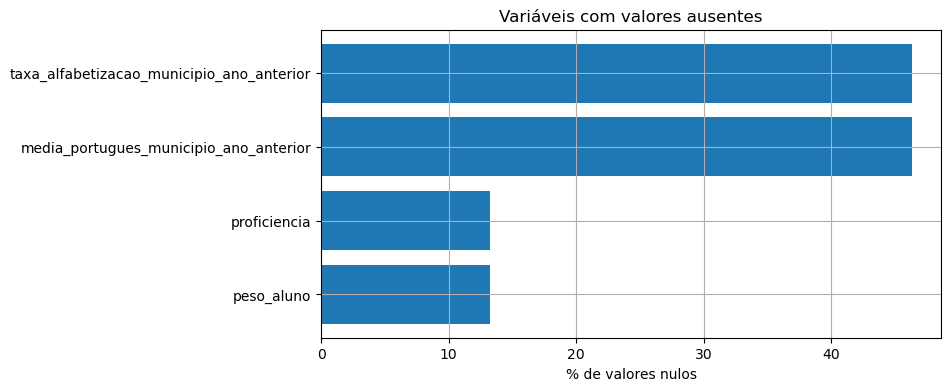

In [18]:
plt.figure(figsize=(8,4))

plt.barh(
    nulos["Variável"],
    nulos["% Nulos"]
)

plt.xlabel("% de valores nulos")
plt.title("Variáveis com valores ausentes")
plt.gca().invert_yaxis()

salvar_figura_eda(plt.gcf(), "032_6_auditoria_de_valores_nulos_01.png"); plt.show()


In [19]:
duplicados = df.height - df.select(pl.col("id_aluno").n_unique()).item()
print(f"IDs de aluno duplicados: {duplicados:,}")
print(f"Alunos únicos: {df['id_aluno'].n_unique():,}")


IDs de aluno duplicados: 1,515,671
Alunos únicos: 2,352,328


## 7. Validação da granularidade

Verificação da regra de negócio: uma linha representa um aluno ou uma observação do aluno?


In [20]:
ocorrencias = (
    df.group_by("id_aluno").len().rename({"len": "registros_por_aluno"})
    .group_by("registros_por_aluno").len()
    .rename({"registros_por_aluno": "Quantidade de registros por aluno", "len": "Número de alunos"})
    .sort("Quantidade de registros por aluno")
)
ocorrencias


Quantidade de registros por aluno,Número de alunos
u32,u32
1,836657
2,1515671


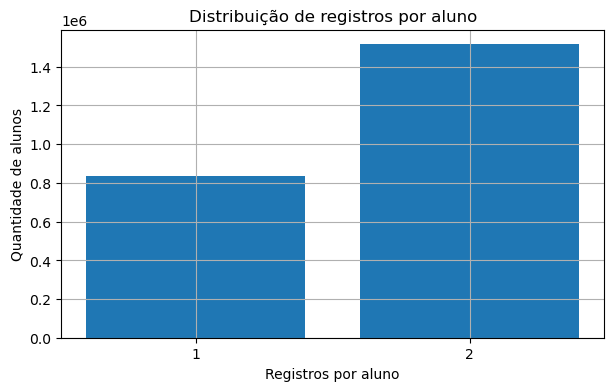

In [21]:
plt.figure(figsize=(7, 4))
plt.bar(
    ocorrencias["Quantidade de registros por aluno"].cast(pl.String).to_list(),
    ocorrencias["Número de alunos"].to_numpy(),
)
plt.title("Distribuição de registros por aluno")
plt.xlabel("Registros por aluno")
plt.ylabel("Quantidade de alunos")
salvar_figura_eda(plt.gcf(), "036_7_validacao_da_granularidade_01.png"); plt.show()


### Achado 04 — Granularidade da Feature Table

A validação da chave `id_aluno` demonstrou que a Feature Table possui natureza longitudinal.

**Conclusão:** a unidade analítica é uma observação anual do aluno, e não um registro único por aluno.


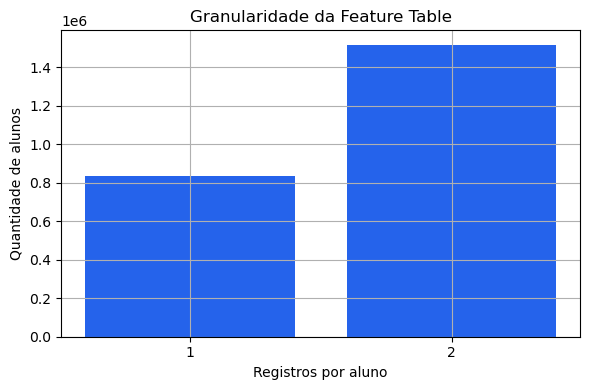

In [22]:
plt.figure(figsize=(6, 4))
plt.bar(
    ocorrencias["Quantidade de registros por aluno"].cast(pl.String).to_list(),
    ocorrencias["Número de alunos"].to_numpy(),
    color="#2563EB",
)
plt.title("Granularidade da Feature Table")
plt.xlabel("Registros por aluno")
plt.ylabel("Quantidade de alunos")
plt.xticks(rotation=0)
plt.tight_layout()
salvar_figura_eda(plt.gcf(), "038_achado_04_granularidade_da_feature_table_01.png")
plt.show()


In [23]:
validacao = (
    df.group_by("id_aluno").agg(pl.col("ano_referencia").n_unique().alias("anos_distintos"))
    .group_by("anos_distintos").len().sort("anos_distintos")
)
validacao


anos_distintos,len
u32,u32
1,836657
2,1515671


### Achado 04 — Validação da Granularidade

A análise da chave `id_aluno` demonstrou que a Feature Table possui natureza longitudinal.

Dos **2.352.328 alunos únicos**, **1.515.671** possuem registros em dois anos de referência (2023 e 2024), enquanto **836.657** aparecem em apenas um ano.

**Conclusão:** a unidade analítica da `ml_aluno` é **1 linha = 1 aluno por ano de referência**, e não um registro único por aluno.


## 8. Distribuição da variável alvo

Validação do balanceamento da variável `alfabetizado`, identificando a proporção entre as classes positivas e negativas.


In [24]:
target = (
    df.group_by("alfabetizado", maintain_order=True).len().rename({"alfabetizado": "Classe", "len": "Quantidade"})
    .with_columns((100 * pl.col("Quantidade") / pl.col("Quantidade").sum()).round(2).alias("Percentual"))
    .sort("Classe")
)
target


Classe,Quantidade,Percentual
i32,u32,f64
0,1883453,48.69
1,1984546,51.31


### Distribuição da variável `alfabetizado`

Análise do balanceamento entre as classes da variável alvo.


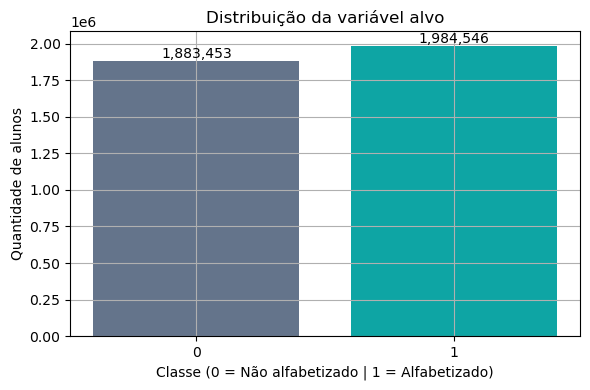

In [25]:
plt.figure(figsize=(6, 4))
classes = target["Classe"].cast(pl.String).to_list()
quantidades = target["Quantidade"].to_numpy()
plt.bar(classes, quantidades, color=["#64748B", "#0EA5A4"][:len(classes)])
plt.title("Distribuição da variável alvo")
plt.xlabel("Classe (0 = Não alfabetizado | 1 = Alfabetizado)")
plt.ylabel("Quantidade de alunos")
for i, valor in enumerate(quantidades):
    plt.text(i, valor + 20000, f"{int(valor):,}", ha="center")
plt.tight_layout(); salvar_figura_eda(plt.gcf(), "044_distribuicao_da_variavel_alfabetizado_01.png"); plt.show()


In [26]:
split = (
    df.group_by("dataset_split").len().rename({"dataset_split": "Conjunto", "len": "Quantidade"})
    .with_columns((100 * pl.col("Quantidade") / pl.col("Quantidade").sum()).round(2).alias("Percentual"))
    .sort("Conjunto")
)
split


Conjunto,Quantidade,Percentual
str,u32,f64
"""teste""",581596,15.04
"""treino""",2705252,69.94
"""validacao""",581151,15.02


### Achado 06 — Validação do Dataset Split

A Feature Table apresenta uma estratégia de particionamento consistente para modelagem supervisionada.

| Conjunto | Percentual |
|----------|-----------:|
| Treino | 69,94% |
| Validação | 15,02% |
| Teste | 15,04% |

**Conclusão:** a divisão encontra-se balanceada e adequada para treinamento, ajuste de hiperparâmetros e avaliação final do modelo.


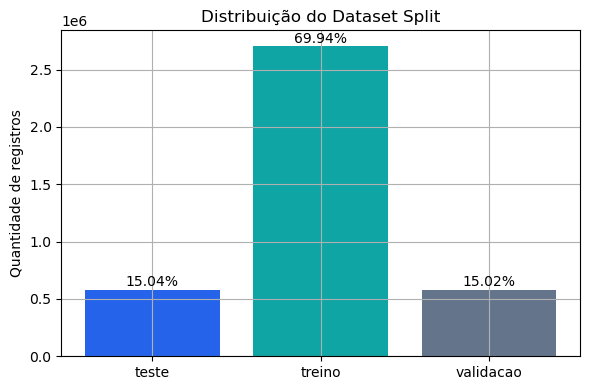

In [27]:
plt.figure(figsize=(6,4))

plt.bar(
    split["Conjunto"],
    split["Quantidade"],
    color=["#2563EB", "#0EA5A4", "#64748B"]
)

plt.title("Distribuição do Dataset Split")
plt.ylabel("Quantidade de registros")

for i, valor in enumerate(split["Quantidade"]):
    plt.text(i, valor + 30000, f"{split['Percentual'][i]}%", ha="center")

plt.tight_layout()
salvar_figura_eda(plt.gcf(), "047_achado_06_validacao_do_dataset_split_01.png"); plt.show()


## 9. Fontes complementares previstas para enriquecimento

A auditoria de integridade desta etapa continua concentrada na Feature Table `ml_aluno`. As fontes complementares abaixo foram identificadas no inventário do projeto e devem ser consideradas nas etapas posteriores; sua inclusão nesta seção **não significa que já foram integradas** à base principal.

- **Censo Escolar 2023 (INEP):** atributos de escola e infraestrutura. Arquivo previsto no repositório: `dados/fontes_originais/complementar/microdados_ed_basica_2023.zip`. Granularidade esperada: escola. Chaves candidatas: `CO_ENTIDADE` (escola), `CO_MUNICIPIO` (município) e `NU_ANO_CENSO` (ano).
- **INSE 2023 — escolas (INEP):** indicadores socioeconômicos no nível escolar. Arquivo: `dados/fontes_originais/complementar/INSE_2023_escolas.xlsx`. Granularidade: escola. Chaves candidatas: `ID_ESCOLA` e `CO_MUNICIPIO`; variáveis de interesse incluem `MEDIA_INSE`, `INSE_CLASSIFICACAO`, `PC_NIVEL_1` a `PC_NIVEL_10`, `TP_CAPITAL` e `QT_ALUNOS_INSE`.
- **IBGE Localidades:** as informações de identificação territorial já estão incorporadas à `ml_aluno`; não devem ser tratadas como uma nova fonte complementar nesta etapa.
- **Indicadores financeiros e socioeconômicos adicionais:** FUNDEB, Siconfi, PIB per capita e outros indicadores permanecem planejados e dependem de validação da fonte oficial, período, granularidade e chave de integração.

### Critérios para a integração futura

1. Confirmar a existência e o esquema dos arquivos locais antes de usá-los.
2. Validar a correspondência entre `id_escola` e os identificadores das fontes externas, além do ano de referência.
3. Verificar duplicidades nas chaves e a cobertura de escolas antes de qualquer junção.
4. Evitar multiplicação de linhas da `ml_aluno`: qualquer relacionamento deve preservar a granularidade aluno/ano esperada ou documentar explicitamente a regra de agregação.
5. Manter a auditoria atual separada da engenharia de features e da integração efetiva, que pertencem às etapas posteriores.


In [28]:
fontes_complementares = pl.DataFrame([
    {
        "Fonte": "Censo Escolar 2023 — INEP",
        "Arquivo previsto": "dados/fontes_originais/complementar/microdados_ed_basica_2023.zip",
        "Granularidade": "Escola",
        "Chaves candidatas": "CO_ENTIDADE; CO_MUNICIPIO; NU_ANO_CENSO",
        "Status nesta etapa": "Inventariada; integração não realizada"
    },
    {
        "Fonte": "INSE 2023 — escolas — INEP",
        "Arquivo previsto": "dados/fontes_originais/complementar/INSE_2023_escolas.xlsx",
        "Granularidade": "Escola",
        "Chaves candidatas": "ID_ESCOLA; CO_MUNICIPIO",
        "Status nesta etapa": "Inventariada; integração não realizada"
    },
    {
        "Fonte": "IBGE Localidades",
        "Arquivo previsto": "Já incorporada à ml_aluno",
        "Granularidade": "Territorial / conforme campos existentes",
        "Chaves candidatas": "id_municipio",
        "Status nesta etapa": "Não tratar como nova fonte"
    },
    {
        "Fonte": "FUNDEB / Siconfi / indicadores econômicos e sociais",
        "Arquivo previsto": "A definir após validação das fontes oficiais",
        "Granularidade": "A confirmar",
        "Chaves candidatas": "Município e ano, a confirmar",
        "Status nesta etapa": "Planejadas; ainda não validadas"
    }
])

fontes_complementares


Fonte,Arquivo previsto,Granularidade,Chaves candidatas,Status nesta etapa
str,str,str,str,str
"""Censo Escolar 2023 — INEP""","""dados/fontes_originais/complem…","""Escola""","""CO_ENTIDADE; CO_MUNICIPIO; NU_…","""Inventariada; integração não r…"
"""INSE 2023 — escolas — INEP""","""dados/fontes_originais/complem…","""Escola""","""ID_ESCOLA; CO_MUNICIPIO""","""Inventariada; integração não r…"
"""IBGE Localidades""","""Já incorporada à ml_aluno""","""Territorial / conforme campos …","""id_municipio""","""Não tratar como nova fonte"""
"""FUNDEB / Siconfi / indicadores…","""A definir após validação das f…","""A confirmar""","""Município e ano, a confirmar""","""Planejadas; ainda não validada…"


# 10. Parecer Técnico da Auditoria

## Status da Feature Table

🟢 **APTA PARA MODELAGEM**

### Principais evidências

- A Feature Table consolidada possui **3.867.999 registros** e **19 variáveis**.
- A granularidade foi validada como **1 linha = 1 aluno por ano de referência**.
- A variável alvo `alfabetizado` encontra-se balanceada (48,69% × 51,31%).
- O `dataset_split` apresenta distribuição adequada (70% / 15% / 15%).
- Foram identificadas quatro variáveis com valores ausentes, que deverão ser avaliadas na etapa de pré-processamento (TC3-49).

### Próximas etapas

- TC3-40 — Inventário e análise das variáveis.
- TC3-41 — Definição das features.
- TC3-49 — Estratégia de tratamento de nulos e engenharia de atributos.

**Referência ao TC3-39:** a análise da variável-alvo alfabetizado e do dataset_split, originalmente prevista nesta tarefa, está contemplada neste notebook, em conjunto com a auditoria da base ml_aluno.

**Limite de escopo:** o status da auditoria refere-se somente às verificações executadas sobre `ml_aluno`. Censo Escolar e INSE estão documentados como fontes complementares para etapas posteriores; ainda não foram integrados nem validados por junção neste notebook. A conclusão de aptidão deve ser interpretada à luz dos achados e das limitações registrados acima.


## Caderno de origem: `TC3-40_Catalogo_Variaveis.ipynb`

> Código oficial incorporado de `notebooks/fase_2_entendimento_base_dados/TC3-40_Catalogo_Variaveis.ipynb`.


# TC3-40 — Catálogo de Variáveis e Fontes de Dados Adicionais

**Objetivo:** documentar as bases complementares efetivamente disponíveis, suas tabelas/abas e colunas, padronizando metadados para apoiar a decisão sobre quais fontes serão utilizadas no projeto.

**Escopo:** inventário de arquivos, tabelas/abas, colunas, siglas, descrições, tipos, granularidade, cobertura e limitações observadas. A base consolidada preparada por integrante do grupo deve ser descrita como produto de uma etapa de seleção/filtro, sem presumir que seus critérios estejam validados até serem documentados.

**Fora do escopo:** integração final entre fontes, definição definitiva das features, imputação de valores e modelagem. A `ml_aluno` permanece como base principal e sua auditoria fica no TC3-38.

> Execute a partir da raiz do repositório. Os sete arquivos exibidos no repositório ficam juntos em `dados/fontes_originais/complementar`; o notebook procura os nomes específicos nessa pasta. A base consolidada de Mauricio será identificada separadamente, caso esteja em `dados/fontes_originais/principal` ou `dados/fontes_originais/complementar`. Arquivos não encontrados são registrados como pendentes; o notebook não presume que estejam disponíveis.


## 1. Bibliotecas e localização dos arquivos


In [29]:
from pathlib import Path
import zipfile
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams["figure.figsize"] = (9, 4)

# Localiza a raiz do repositório e a pasta única das bases complementares.
CWD = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in [CWD, *CWD.parents] if (p / ".git").exists() and (p / "dados").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    PROJECT_ROOT = next(
        (p for p in [CWD, *CWD.parents] if (p / "dados" / "fontes_originais" / "complementar").is_dir()),
        CWD,
    )

DATA_COMPLEMENTAR = PROJECT_ROOT / "dados" / "fontes_originais" / "complementar"
DATA_PRINCIPAL = PROJECT_ROOT / "dados" / "fontes_originais" / "principal"


def localizar_arquivo(padroes, pasta=DATA_COMPLEMENTAR):
    if isinstance(padroes, str):
        padroes = [padroes]
    encontrados = []
    if pasta.exists():
        for padrao in padroes:
            encontrados.extend(pasta.glob(padrao))
    encontrados = [x for x in encontrados if x.is_file()]
    if encontrados:
        return sorted(set(encontrados), key=lambda x: str(x).lower())[0]
    return None

# Nomes/padrões alinhados aos arquivos que aparecem em dados/fontes_originais/complementar no GitHub.
# Os padrões aceitam variações apenas nos trechos truncados/acentuação, sem procurar fora da pasta.
arquivos_configurados = {
    "Censo Escolar 2023 (microdados ZIP)": ["microdados_ed_basica_2023.zip"],
    "INSE 2023 — escolas": ["INSE_2023_escolas.xlsx", "INSE_2023_escolas*.xlsx"],
    "Bolsa Família": ["base_dados_bolsa_familia_2023_2024.csv"],
    "Indicador municipal FUNDEB": ["base_dados_fundeb_indicador_municipal_2023_2024.csv", "base_dados_fundeb_indicador_municipal_2023_2024*.csv"],
    "PIB municipal": ["base_de_dados_PIB_Municipios_2022_2023.csv", "base_de_dados_PIB_Municipios*.csv"],
    "Receitas orçamentárias municipais": ["base_de_dados_municipio_receitas_orcamentarias_2023_2024.csv", "base_de_dados_municipio_receitas_orcamentarias_20*.csv"],
    "Dicionário de dados da educação básica": ["dicionário_dados_educação_básica.xlsx", "dicionario_dados_educacao_basica.xlsx", "dicionário_dados_educação_básica*.xlsx", "dicionario_dados_educacao_basica*.xlsx"],
}
localizados = {nome: localizar_arquivo(padroes) for nome, padroes in arquivos_configurados.items()}

# A base consolidada do Mauricio pode ter outro nome. Procuramos arquivos candidatos
# no diretório de dados, mas não presumimos que qualquer arquivo com 'consolid' seja o correto.
consolidados_encontrados = []
for pasta in [DATA_PRINCIPAL, DATA_COMPLEMENTAR]:
    if pasta.exists():
        consolidados_encontrados.extend(
            p for p in pasta.rglob("*")
            if p.is_file() and "consolid" in p.name.lower()
            and p.suffix.lower() in {".csv", ".parquet", ".xlsx", ".xls", ".zip"}
        )
consolidados_encontrados = sorted(set(consolidados_encontrados))

inventario_arquivos = pl.DataFrame([
    {"Base/arquivo": nome,
     "Encontrado em dados/fontes_originais/complementar": caminho is not None,
     "Caminho identificado": str(caminho.relative_to(PROJECT_ROOT)) if caminho else "Não localizado; conferir nome/caminho"}
    for nome, caminho in localizados.items()
])
print(f"Raiz do projeto: {PROJECT_ROOT}")
print(f"Pasta complementar: {DATA_COMPLEMENTAR}")
display(inventario_arquivos)
print("\nArquivos candidatos à base consolidada (confirmar com Mauricio):")
if consolidados_encontrados:
    display(pl.DataFrame([
        {"Arquivo candidato": p.name, "Caminho": str(p.relative_to(PROJECT_ROOT))}
        for p in consolidados_encontrados
    ]))
else:
    display(pl.DataFrame([
        {"Arquivo candidato": "Não localizado automaticamente", "Caminho": "Confirmar nome/caminho com Mauricio"}
    ]))


Raiz do projeto: /workspace
Pasta complementar: /workspace/dados/fontes_originais/complementar


Base/arquivo,Encontrado em dados/fontes_originais/complementar,Caminho identificado
str,bool,str
"""Censo Escolar 2023 (microdados…",true,"""dados/fontes_originais/complem…"
"""INSE 2023 — escolas""",true,"""dados/fontes_originais/complem…"
"""Bolsa Família""",true,"""dados/fontes_originais/complem…"
"""Indicador municipal FUNDEB""",true,"""dados/fontes_originais/complem…"
"""PIB municipal""",true,"""dados/fontes_originais/complem…"
"""Receitas orçamentárias municip…",true,"""dados/fontes_originais/complem…"
"""Dicionário de dados da educaçã…",true,"""dados/fontes_originais/complem…"



Arquivos candidatos à base consolidada (confirmar com Mauricio):


Arquivo candidato,Caminho
str,str
"""Não localizado automaticamente""","""Confirmar nome/caminho com Mau…"


## 2. Inventário dos microdados do Censo Escolar 2023

O arquivo `microdados_ed_basica_2023.zip` é o pacote de microdados do Censo Escolar 2023. Ele é diferente do `dicionário_dados_educação_básica.xlsx`, que contém documentação das variáveis. A célula seguinte verifica se o ZIP foi localizado e lista seus arquivos internos; a seção de inventário padronizado tenta ler apenas os cabeçalhos dos CSVs, sem carregar a base completa na memória.


In [30]:
caminho_censo_zip = localizados.get("Censo Escolar 2023 (microdados ZIP)")
arquivos_internos_censo = []
if caminho_censo_zip:
    try:
        with zipfile.ZipFile(caminho_censo_zip, "r") as zf:
            arquivos_internos_censo = [n for n in zf.namelist() if not n.endswith("/")]
        print("Microdados do Censo Escolar localizados:", caminho_censo_zip.relative_to(PROJECT_ROOT))
        print("Quantidade de arquivos dentro do ZIP:", len(arquivos_internos_censo))
        display(pl.DataFrame({"Arquivo interno": arquivos_internos_censo}))
    except Exception as exc:
        print("O ZIP foi localizado, mas não foi possível listar seu conteúdo:", exc)
else:
    print("Microdados do Censo Escolar 2023 não localizados em dados/fontes_originais/complementar.")

if localizados.get("Dicionário de dados da educação básica"):
    print("Dicionário da educação básica localizado:", localizados["Dicionário de dados da educação básica"].name)


Microdados do Censo Escolar localizados: dados/fontes_originais/complementar/microdados_ed_basica_2023.zip
Quantidade de arquivos dentro do ZIP: 1


Arquivo interno
str
"""microdados_ed_basica_2023.csv"""


Dicionário da educação básica localizado: dicionário_dados_educação_básica.xlsx


**Nota metodológica:** o ZIP contém os microdados do Censo Escolar; o arquivo Excel do dicionário é documentação complementar. O inventário das colunas dos microdados será feito a partir dos cabeçalhos dos arquivos internos do ZIP, quando a estrutura permitir leitura sem extração completa. O dicionário não substitui os dados e as descrições só serão associadas quando houver correspondência confirmada entre os nomes das variáveis.


## 3. Inventário das planilhas INSE 2023


In [31]:
def ler_excel_seguro(caminho):
    try:
        planilhas = pl.read_excel(caminho, sheet_id=0, engine="openpyxl")
        if isinstance(planilhas, pl.DataFrame):
            planilhas = {"Sheet1": planilhas}
        resumo = [
            {"Arquivo": caminho.name, "Aba": aba, "Registros": frame.height, "Colunas": frame.width}
            for aba, frame in planilhas.items()
        ]
        return resumo, planilhas
    except Exception as exc:
        return [{"Arquivo": caminho.name, "Aba": "ERRO DE LEITURA", "Registros": None, "Colunas": None, "Erro": str(exc)}], {}

resumos_inse, amostras_inse = [], {}
for nome in ["INSE 2023 — escolas"]:
    caminho = localizados[nome]
    if caminho:
        resumo, amostras = ler_excel_seguro(caminho)
        resumos_inse.extend(resumo); amostras_inse[nome] = amostras
display(pl.DataFrame(resumos_inse))
if "INSE 2023 — escolas" in amostras_inse:
    for aba, df_amostra in amostras_inse["INSE 2023 — escolas"].items():
        print(f"Amostra — INSE escolas / aba: {aba}"); display(df_amostra.head()); print("Colunas:", df_amostra.columns); break


Arquivo,Aba,Registros,Colunas
str,str,i64,i64
"""INSE_2023_escolas.xlsx""","""INSE_ESC_2023""",69756,22
"""INSE_2023_escolas.xlsx""","""Dicionário""",22,2


Amostra — INSE escolas / aba: INSE_ESC_2023


NU_ANO_SAEB,CO_UF,SG_UF,NO_UF,CO_MUNICIPIO,NO_MUNICIPIO,ID_ESCOLA,NO_ESCOLA,TP_TIPO_REDE,TP_LOCALIZACAO,TP_CAPITAL,QTD_ALUNOS_INSE,MEDIA_INSE,INSE_CLASSIFICACAO,PC_NIVEL_1,PC_NIVEL_2,PC_NIVEL_3,PC_NIVEL_4,PC_NIVEL_5,PC_NIVEL_6,PC_NIVEL_7,PC_NIVEL_8
i64,i64,str,str,i64,str,i64,str,i64,i64,i64,i64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64
2023,11,"""RO""","""Rondônia""",1100015,"""Alta Floresta D'Oeste""",11024372,"""EMEIEF ANA NERY""",3,1,2,12,4.29,"""Nível III""",0.0,50.0,null,25.0,25.0,null,null,null
2023,11,"""RO""","""Rondônia""",1100015,"""Alta Floresta D'Oeste""",11024666,"""EMEIEF BOA ESPERANCA""",3,2,2,34,4.88,"""Nível IV""",0.0,3.64,12.87,33.01,50.49,null,null,null
2023,11,"""RO""","""Rondônia""",1100015,"""Alta Floresta D'Oeste""",11024682,"""EEEFM EURIDICE LOPES PEDROSO""",2,1,2,166,4.91,"""Nível IV""",0.0,13.32,17.68,23.27,23.92,13.2,7.7,0.9
2023,11,"""RO""","""Rondônia""",1100015,"""Alta Floresta D'Oeste""",11024828,"""EMEIEF IZIDORO STEDILE""",3,1,2,33,5.03,"""Nível V""",0.0,4.15,10.43,45.85,18.72,10.43,10.43,null
2023,11,"""RO""","""Rondônia""",1100015,"""Alta Floresta D'Oeste""",11024968,"""EEEMTI JUSCELINO KUBITSCHEK DE…",2,1,2,146,5.21,"""Nível V""",0.0,6.07,10.47,24.41,24.04,16.09,17.35,1.56


Colunas: ['NU_ANO_SAEB', 'CO_UF', 'SG_UF', 'NO_UF', 'CO_MUNICIPIO', 'NO_MUNICIPIO', 'ID_ESCOLA', 'NO_ESCOLA', 'TP_TIPO_REDE', 'TP_LOCALIZACAO', 'TP_CAPITAL', 'QTD_ALUNOS_INSE', 'MEDIA_INSE', 'INSE_CLASSIFICACAO', 'PC_NIVEL_1', 'PC_NIVEL_2', 'PC_NIVEL_3', 'PC_NIVEL_4', 'PC_NIVEL_5', 'PC_NIVEL_6', 'PC_NIVEL_7', 'PC_NIVEL_8']


## 4. Inventário das bases municipais em CSV


In [32]:
def ler_csv_flexivel(caminho):
    erros = []
    for separador in [",", ";", "\t"]:
        for encoding in ["utf8", "utf8-lossy"]:
            try:
                frame = pl.read_csv(caminho, separator=separador, encoding=encoding, infer_schema_length=10_000)
                if frame.width > 1:
                    return frame
            except Exception as exc:
                erros.append(str(exc))
    raise ValueError(f"Não foi possível ler {caminho.name}. Últimos erros: {erros[-2:]}")

csv_nomes = ["Receitas orçamentárias municipais", "PIB municipal", "Indicador municipal FUNDEB", "Bolsa Família"]
frames_csv, resumo_csv = {}, []
for nome in csv_nomes:
    caminho = localizados[nome]
    if caminho:
        frame = ler_csv_flexivel(caminho); frames_csv[nome] = frame
        resumo_csv.append({"Base": nome, "Arquivo": caminho.name, "Registros": frame.height, "Colunas": frame.width,
                           "Nomes das colunas": ", ".join(frame.columns), "Total de nulos": sum(frame.null_count().row(0))})
display(pl.DataFrame(resumo_csv))
for nome, frame in frames_csv.items():
    print(f"\n### {nome}"); display(frame.head(3)); display(pl.DataFrame({"Coluna": frame.columns, "Tipo Polars": [str(t) for t in frame.dtypes]}))


Base,Arquivo,Registros,Colunas,Nomes das colunas,Total de nulos
str,str,i64,i64,str,i64
"""Receitas orçamentárias municip…","""base_de_dados_municipio_receit…",11097,4,"""ano, sigla_uf, id_municipio, t…",0
"""PIB municipal""","""base_de_dados_PIB_Municipios_2…",11140,3,"""Ano;UF;Nome UF;Código do Munic…",11140
"""Indicador municipal FUNDEB""","""base_dados_fundeb_indicador_mu…",11131,4,"""ano, id_municipio, sigla_uf, t…",0
"""Bolsa Família""","""base_dados_bolsa_familia_2023_…",11140,4,"""ano_referencia, id_municipio, …",0



### Receitas orçamentárias municipais


ano,sigla_uf,id_municipio,total_valor
i64,str,i64,f64
2023,"""AC""",1200013,6.0977e8
2023,"""AC""",1200054,4.1526e8
2023,"""AC""",1200104,9.6842e8


Coluna,Tipo Polars
str,str
"""ano""","""Int64"""
"""sigla_uf""","""String"""
"""id_municipio""","""Int64"""
"""total_valor""","""Float64"""



### PIB municipal


...

ano,id_municipio,sigla_uf,total_valor
i64,i64,str,f64
2023,1100015,"""RO""",2.6211e8
2023,1100023,"""RO""",7.1923e8
2023,1100031,"""RO""",3.7353e7


Coluna,Tipo Polars
str,str
"""ano""","""Int64"""
"""id_municipio""","""Int64"""
"""sigla_uf""","""String"""
"""total_valor""","""Float64"""



### Bolsa Família


ano_referencia,id_municipio,sigla_uf,total_valor
i64,i64,str,i64
2023,4107124,"""PR""",2181020
2023,4128625,"""PR""",1808604
2023,4106605,"""PR""",7961886


Coluna,Tipo Polars
str,str
"""ano_referencia""","""Int64"""
"""id_municipio""","""Int64"""
"""sigla_uf""","""String"""
"""total_valor""","""Int64"""


## 5. Qualidade inicial e chaves candidatas


In [33]:
def resumo_qualidade(frame, nome):
    return [{"Base": nome, "Variável": c, "Tipo": str(frame.schema[c]), "Nulos": frame[c].null_count(),
             "% nulos": round(100 * frame[c].null_count() / frame.height, 2), "Valores distintos": frame[c].n_unique()}
            for c in frame.columns]

qualidade = [linha for nome, frame in frames_csv.items() for linha in resumo_qualidade(frame, nome)]
display(pl.DataFrame(qualidade))
chaves_testar = {"Receitas orçamentárias municipais": ["id_municipio", "ano"], "PIB municipal": ["Código do Município", "Ano"],
                 "Indicador municipal FUNDEB": ["id_municipio", "ano"], "Bolsa Família": ["id_municipio", "ano_referencia"]}
resultado_chaves = []
for nome, cols in chaves_testar.items():
    frame = frames_csv.get(nome)
    if frame is None: continue
    if all(c in frame.columns for c in cols):
        duplicadas = frame.group_by(cols).len().filter(pl.col("len") > 1).select(pl.col("len").sum()).item() or 0
        status = "Sem duplicidades observadas" if duplicadas == 0 else "Requer investigação"
    else:
        duplicadas, status = None, "Nomes das colunas não correspondem; conferir manualmente"
    resultado_chaves.append({"Base": nome, "Chave candidata": " + ".join(cols), "Linhas duplicadas na chave": duplicadas, "Status": status})
display(pl.DataFrame(resultado_chaves))


Base,Variável,Tipo,Nulos,% nulos,Valores distintos
str,str,str,i64,f64,i64
"""Receitas orçamentárias municip…","""ano""","""Int64""",0,0.0,2
"""Receitas orçamentárias municip…","""sigla_uf""","""String""",0,0.0,26
"""Receitas orçamentárias municip…","""id_municipio""","""Int64""",0,0.0,5561
"""Receitas orçamentárias municip…","""total_valor""","""Float64""",0,0.0,11085
"""PIB municipal""","""Ano;UF;Nome UF;Código do Munic…","""String""",0,0.0,11140
…,…,…,…,…,…
"""Indicador municipal FUNDEB""","""total_valor""","""Float64""",0,0.0,11131
"""Bolsa Família""","""ano_referencia""","""Int64""",0,0.0,2
"""Bolsa Família""","""id_municipio""","""Int64""",0,0.0,5570


Base,Chave candidata,Linhas duplicadas na chave,Status
str,str,i64,str
"""Receitas orçamentárias municip…","""id_municipio + ano""",0,"""Sem duplicidades observadas"""
"""PIB municipal""","""Código do Município + Ano""",null,"""Nomes das colunas não correspo…"
"""Indicador municipal FUNDEB""","""id_municipio + ano""",0,"""Sem duplicidades observadas"""
"""Bolsa Família""","""id_municipio + ano_referencia""",0,"""Sem duplicidades observadas"""


## 6. Catálogo das fontes: disponibilidade, finalidade e limites


In [34]:
catalogo_fontes = pl.DataFrame([
    ("ml_aluno", "Base principal", "Aluno/ano conforme auditoria TC3-38", "Fonte e chave já tratadas na auditoria específica", "Não repetir auditoria aqui"),
    ("Censo Escolar 2023", "Microdados da educação básica", "A confirmar por arquivo interno", "ZIP configurado em dados/fontes_originais/complementar; verificar arquivos internos e cobertura", "Inventariar cabeçalhos sem carregar os microdados completos; confirmar granularidade no dicionário"),
    ("INSE 2023 — escolas", "Indicador socioeconômico escolar", "Escola", "Arquivo escolar localizado; verificar campos e cobertura", "Não usar como indicador municipal sem agregação justificada"),
    ("Receitas orçamentárias municipais", "Finanças públicas", "Município/ano provável", "CSV localizado; confirmar definição de total_valor e unidade", "Não integrado"),
    ("Indicador municipal FUNDEB", "Financiamento educacional", "Município/ano provável", "CSV localizado; confirmar o significado de total_valor", "Não assumir que equivale a gasto por aluno sem fórmula"),
    ("PIB municipal", "Contexto econômico", "Município/ano", "CSV localizado; converter valores formatados para número antes de calcular", "Não integrado"),
    ("Bolsa Família", "Transferência de renda", "Município/ano provável", "CSV localizado; confirmar se total_valor é valor, famílias ou beneficiários", "Não chamar de percentual sem denominador"),
    ("INSE 2023 — municípios/estados/Brasil", "Recortes agregados INSE", "Município/UF/Brasil", "Não aparecem na listagem atual de `dados/fontes_originais/complementar`", "Inventariar apenas se o grupo adicionar esses arquivos à pasta"),
    ("CadÚnico, pobreza, IDHM renda e Gini", "Indicadores socioeconômicos planejados", "A confirmar", "Não identificados entre os arquivos complementares inspecionados nesta execução", "Não declarar disponíveis sem arquivo ou fonte validada"),
    ("Siconfi", "Orçamento/despesa em educação", "Município/ano a confirmar", "Não identificado entre os CSVs complementares inspecionados nesta execução", "Não declarar indicador pronto"),
], schema=["Base/fonte", "Finalidade", "Granularidade esperada", "Estado da verificação", "Limite/observação"], orient="row")
display(catalogo_fontes)


Base/fonte,Finalidade,Granularidade esperada,Estado da verificação,Limite/observação
str,str,str,str,str
"""ml_aluno""","""Base principal""","""Aluno/ano conforme auditoria T…","""Fonte e chave já tratadas na a…","""Não repetir auditoria aqui"""
"""Censo Escolar 2023""","""Microdados da educação básica""","""A confirmar por arquivo intern…","""ZIP configurado em dados/fonte…","""Inventariar cabeçalhos sem car…"
"""INSE 2023 — escolas""","""Indicador socioeconômico escol…","""Escola""","""Arquivo escolar localizado; ve…","""Não usar como indicador munici…"
"""Receitas orçamentárias municip…","""Finanças públicas""","""Município/ano provável""","""CSV localizado; confirmar defi…","""Não integrado"""
"""Indicador municipal FUNDEB""","""Financiamento educacional""","""Município/ano provável""","""CSV localizado; confirmar o si…","""Não assumir que equivale a gas…"
"""PIB municipal""","""Contexto econômico""","""Município/ano""","""CSV localizado; converter valo…","""Não integrado"""
"""Bolsa Família""","""Transferência de renda""","""Município/ano provável""","""CSV localizado; confirmar se t…","""Não chamar de percentual sem d…"
"""INSE 2023 — municípios/estados…","""Recortes agregados INSE""","""Município/UF/Brasil""","""Não aparecem na listagem atual…","""Inventariar apenas se o grupo …"
"""CadÚnico, pobreza, IDHM renda …","""Indicadores socioeconômicos pl…","""A confirmar""","""Não identificados entre os arq…","""Não declarar disponíveis sem a…"


## 7. Variáveis prioritárias — definições que ainda precisam ser fechadas

A lista abaixo registra candidatos mencionados no planejamento. **Não significa que todos estejam disponíveis, calculados ou prontos para uso.** A definição operacional deve ser decidida antes de comparar ou modelar.


In [35]:
variaveis_prioritarias = pl.DataFrame([
    ("gasto_por_aluno_fundeb", "Financiamento educacional", "Definir numerador, denominador, período e população escolar"),
    ("percentual_orcamento_educacao_siconfi", "Finanças públicas", "Definir relatório/conta, numerador e denominador; obter arquivo Siconfi"),
    ("pib_per_capita", "Contexto econômico", "Usar campo per capita do PIB municipal e confirmar ano de referência"),
    ("pobreza", "Contexto socioeconômico", "Definir conceito, população, fonte oficial e ano-base"),
    ("percentual_familias_cadunico", "Vulnerabilidade social", "Definir contagem de famílias e denominador populacional/familiar"),
    ("percentual_bolsa_familia", "Transferência de renda", "Confirmar o que mede total_valor e definir denominador antes de criar percentual"),
    ("idhm_renda", "Desenvolvimento humano", "Confirmar edição, ano-base e disponibilidade municipal"),
    ("indice_gini", "Desigualdade de renda", "Confirmar fonte, escala geográfica, população e ano-base"),
], schema=["Variável candidata", "Categoria", "Definição/validação pendente"], orient="row")
display(variaveis_prioritarias)


Variável candidata,Categoria,Definição/validação pendente
str,str,str
"""gasto_por_aluno_fundeb""","""Financiamento educacional""","""Definir numerador, denominador…"
"""percentual_orcamento_educacao_…","""Finanças públicas""","""Definir relatório/conta, numer…"
"""pib_per_capita""","""Contexto econômico""","""Usar campo per capita do PIB m…"
"""pobreza""","""Contexto socioeconômico""","""Definir conceito, população, f…"
"""percentual_familias_cadunico""","""Vulnerabilidade social""","""Definir contagem de famílias e…"
"""percentual_bolsa_familia""","""Transferência de renda""","""Confirmar o que mede total_val…"
"""idhm_renda""","""Desenvolvimento humano""","""Confirmar edição, ano-base e d…"
"""indice_gini""","""Desigualdade de renda""","""Confirmar fonte, escala geográ…"


## 8. Regras para integração futura


Antes de fazer qualquer `merge`, validar:

1. **Granularidade:** aluno, escola, município ou UF; não juntar níveis diferentes sem agregação explícita.
2. **Chave:** verificar código oficial, tipo de dado, zeros à esquerda, unicidade e cobertura.
3. **Tempo:** compatibilizar ano da variável com o ano da observação escolar/aluno; não presumir equivalência entre 2023 e 2024.
4. **Semântica:** documentar unidade e significado de `total_valor`; um valor total não é automaticamente percentual nem gasto por aluno.
5. **Cobertura e viés:** quantificar quantas observações ficam sem correspondência e se a ausência é sistemática.
6. **Vazamento de dados:** decidir se a variável estaria disponível no momento em que a previsão seria feita.
7. **Rastreabilidade:** registrar fonte, URL/documentação, data de extração, filtros e transformação aplicada.

O INSE no arquivo de escolas continua sendo uma medida no nível escolar; a presença de código de município serve para identificação/agrupamento e não transforma automaticamente o indicador em medida municipal.


## 10. Inventário padronizado de colunas (todas as fontes localizadas)

Esta seção consolida os metadados em uma única estrutura, mantendo os nomes originais. Quando a descrição, unidade ou granularidade não estiver documentada, o campo ficará como `Não documentado` ou `A confirmar`; não serão inferidos significados como se fossem fatos. Para o Censo em ZIP, a leitura de cabeçalhos é feita sem carregar os microdados completos.

A tabela padrão contém: fonte, arquivo, tabela/aba, nome original da coluna, sigla, descrição, tipo de origem, tipo Python, papel da variável, unidade, granularidade, chave candidata e observações.


In [36]:
import io

COLUNAS_CATALOGO = [
    "fonte", "arquivo", "tabela_aba", "nome_coluna", "sigla", "descricao",
    "tipo_origem", "tipo_python", "papel_variavel", "unidade_medida",
    "granularidade", "chave_candidata", "observacoes"
]
linhas_catalogo = []

def classificar_papel(nome_coluna):
    n = str(nome_coluna).lower()
    if any(t in n for t in ["id_municipio", "co_municipio", "codigo do municipio", "cod_mun"]):
        return "Identificador geográfico"
    if n in {"ano", "ano_referencia", "nu_ano_saeb", "year"} or "ano" in n:
        return "Temporal"
    if n.startswith("pc_nivel_") or "percentual" in n or "per capita" in n:
        return "Indicador/percentual (confirmar unidade)"
    if any(t in n for t in ["valor", "pib", "media", "média", "quantidade", "qtd"]):
        return "Medida numérica (confirmar significado)"
    if n.startswith("tp_") or n.startswith("sg_") or n in {"uf", "nome uf", "nome do município"}:
        return "Categoria/código"
    return "A classificar"

def adicionar_colunas_catalogo(df, fonte, arquivo, tabela_aba, granularidade, descricao_por_coluna=None, tipo_origem_por_coluna=None, observacao=""):
    descricao_por_coluna = descricao_por_coluna or {}
    tipo_origem_por_coluna = tipo_origem_por_coluna or {}
    for col in df.columns:
        nome = str(col)
        linhas_catalogo.append({
            "fonte": fonte, "arquivo": arquivo, "tabela_aba": str(tabela_aba),
            "nome_coluna": nome,
            "sigla": nome if nome.isupper() or "_" in nome else "Não identificada",
            "descricao": descricao_por_coluna.get(nome, "Não documentado no dicionário localizado"),
            "tipo_origem": tipo_origem_por_coluna.get(nome, "Não identificado"),
            "tipo_python": str(df[col].dtype) if hasattr(df, "dtypes") and col in getattr(df, "columns", []) else "Não carregado (somente cabeçalho)",
            "papel_variavel": classificar_papel(nome),
            "unidade_medida": "A confirmar na documentação da fonte",
            "granularidade": granularidade,
            "chave_candidata": "Candidata; validar unicidade e cobertura" if any(t in nome.lower() for t in ["id_municipio", "co_municipio", "ano", "codigo do municipio"]) else "Não avaliada",
            "observacoes": observacao
        })

# A) CSVs municipais já carregados na seção 4
for nome, df in frames_csv.items():
    caminho = localizados.get(nome)
    adicionar_colunas_catalogo(df, nome, caminho.name if caminho else "Não localizado", "CSV", "Município/ano provável; confirmar no dicionário", observacao="Tipo Python reflete a leitura atual; verificar conversões de moeda/decimal.")

# B) Todas as guias das planilhas INSE localizadas
for nome, guias in amostras_inse.items():
    caminho = localizados.get(nome)
    for aba, df_aba in guias.items():
        granularidade = "Escola" if "escola" in nome.lower() else ("Município" if "município" in nome.lower() else "UF/Brasil ou a confirmar")
        adicionar_colunas_catalogo(df_aba, nome, caminho.name if caminho else "Não localizado", aba, granularidade, observacao="Consultar a guia Dicionário para validar descrição e significado dos campos.")

# C) Censo Escolar: inventariar cabeçalhos dos CSVs dentro do ZIP, sem carregar os registros.
censo_cabecalhos = []
if caminho_censo_zip:
    try:
        with zipfile.ZipFile(caminho_censo_zip, "r") as zf:
            candidatos_csv = [n for n in zf.namelist() if n.lower().endswith(".csv") and not n.endswith("/")]
            print(f"Arquivos CSV encontrados no ZIP do Censo: {len(candidatos_csv)}")
            for nome_interno in candidatos_csv:
                try:
                    with zf.open(nome_interno) as arq:
                        conteudo = arq.read(1024 * 1024)
                        cabecalho = None
                        ultimo_erro = None
                        for enc in ["utf-8-sig", "latin1"]:
                            try:
                                texto = conteudo.decode(enc)
                                cabecalho = pl.read_csv(io.StringIO(texto), separator=";", n_rows=0)
                                if len(cabecalho.columns) <= 1:
                                    cabecalho = pl.read_csv(io.StringIO(texto), separator=",", n_rows=0)
                                break
                            except Exception as exc:
                                ultimo_erro = exc
                        if cabecalho is None:
                            raise ultimo_erro or ValueError("Cabeçalho não lido")
                    df_cabecalho = pl.DataFrame(schema={col: pl.String for col in cabecalho.columns})
                    adicionar_colunas_catalogo(
                        df_cabecalho, "Censo Escolar 2023", caminho_censo_zip.name,
                        nome_interno, "A confirmar pelo arquivo/dicionário",
                        observacao="Inventário de cabeçalho; microdados completos não foram carregados. Confirmar descrição e granularidade no dicionário oficial."
                    )
                    censo_cabecalhos.append({"arquivo_interno": nome_interno, "quantidade_colunas": len(cabecalho.columns), "status": "Cabeçalho lido"})
                except Exception as exc:
                    censo_cabecalhos.append({"arquivo_interno": nome_interno, "quantidade_colunas": None, "status": f"Cabeçalho não lido: {exc}"})
        display(pl.DataFrame(censo_cabecalhos))
    except Exception as exc:
        print("Falha ao processar o ZIP do Censo:", exc)
else:
    print("Censo Escolar: inventário de colunas pendente porque o ZIP não foi localizado.")

# D) Base consolidada do grupo: inventariar apenas se o arquivo for localizado automaticamente
resumo_consolidado = []
for caminho in consolidados_encontrados:
    try:
        if caminho.suffix.lower() == ".csv":
            df_con = ler_csv_flexivel(caminho).head(1000)
            fonte_con = "Base consolidada do grupo (amostra de até 1.000 linhas)"
            adicionar_colunas_catalogo(df_con, fonte_con, caminho.name, "CSV consolidado", "Conforme documentação da consolidação", observacao="Tipo Python e exemplos derivados de amostra; confirmar filtros e regras usados pelo responsável.")
        elif caminho.suffix.lower() in {".xlsx", ".xls"}:
            planilhas = pl.read_excel(caminho, sheet_id=0, engine="openpyxl")
            for aba, df_con in planilhas.items():
                df_con = df_con.head(1000)
                adicionar_colunas_catalogo(df_con, "Base consolidada do grupo (amostra de até 1.000 linhas)", caminho.name, aba, "Conforme documentação da consolidação", observacao="Confirmar filtros, período, granularidade e critérios com o responsável.")
        elif caminho.suffix.lower() == ".parquet":
            try:
                import pyarrow.parquet as pq
                schema = pq.read_schema(caminho)
                df_schema = pl.DataFrame(schema={c: pl.String for c in schema.names})
                adicionar_colunas_catalogo(df_schema, "Base consolidada do grupo (schema Parquet)", caminho.name, "Parquet", "Conforme documentação da consolidação", observacao="Somente schema; confirmar filtros e critérios com o responsável.")
            except Exception as exc:
                resumo_consolidado.append({"arquivo": caminho.name, "status": f"Schema Parquet não lido: {exc}"})
        else:
            resumo_consolidado.append({"arquivo": caminho.name, "status": "Formato encontrado, leitura não implementada nesta seção"})
        resumo_consolidado.append({"arquivo": caminho.name, "status": "Colunas adicionadas ao catálogo; critérios ainda precisam ser documentados"})
    except Exception as exc:
        resumo_consolidado.append({"arquivo": caminho.name, "status": f"Erro de leitura: {exc}"})
if resumo_consolidado:
    display(pl.DataFrame(resumo_consolidado))
else:
    print("Nenhuma base com consolid no nome foi localizada. Confirmar o nome/caminho com o grupo antes de inventariá-la.")

# Tabela final padronizada
catalogo_colunas = pl.DataFrame(linhas_catalogo, schema=COLUNAS_CATALOGO, orient="row")
if not catalogo_colunas.is_empty():
    catalogo_colunas = catalogo_colunas.unique(subset=["fonte", "arquivo", "tabela_aba", "nome_coluna"], maintain_order=True)
    display(catalogo_colunas)
    print("Resumo por fonte:")
    display(catalogo_colunas.group_by(["fonte", "arquivo", "tabela_aba"], maintain_order=True).agg(pl.col("nome_coluna").n_unique().alias("quantidade_colunas")))
    # Exportação para revisão da equipe; o arquivo é gerado na raiz do repositório.
    caminho_saida = RESULTADOS_TABELAS_DIR / "inventario_padronizado_bases_complementares.csv"
    caminho_saida.parent.mkdir(parents=True, exist_ok=True)
    catalogo_colunas.write_csv(caminho_saida, include_bom=True)
    print(f"Inventário exportado para: {caminho_saida.relative_to(PROJECT_ROOT)}")
else:
    print("Nenhuma coluna foi inventariada. Confira os caminhos e a leitura das fontes.")


Arquivos CSV encontrados no ZIP do Censo: 1


arquivo_interno,quantidade_colunas,status
str,i64,str
"""microdados_ed_basica_2023.csv""",408,"""Cabeçalho lido"""


Nenhuma base com consolid no nome foi localizada. Confirmar o nome/caminho com o grupo antes de inventariá-la.


fonte,arquivo,tabela_aba,nome_coluna,sigla,descricao,tipo_origem,tipo_python,papel_variavel,unidade_medida,granularidade,chave_candidata,observacoes
str,str,str,str,str,str,str,str,str,str,str,str,str
"""Receitas orçamentárias municip…","""base_de_dados_municipio_receit…","""CSV""","""ano""","""Não identificada""","""Não documentado no dicionário …","""Não identificado""","""Int64""","""Temporal""","""A confirmar na documentação da…","""Município/ano provável; confir…","""Candidata; validar unicidade e…","""Tipo Python reflete a leitura …"
"""Receitas orçamentárias municip…","""base_de_dados_municipio_receit…","""CSV""","""sigla_uf""","""sigla_uf""","""Não documentado no dicionário …","""Não identificado""","""String""","""A classificar""","""A confirmar na documentação da…","""Município/ano provável; confir…","""Não avaliada""","""Tipo Python reflete a leitura …"
"""Receitas orçamentárias municip…","""base_de_dados_municipio_receit…","""CSV""","""id_municipio""","""id_municipio""","""Não documentado no dicionário …","""Não identificado""","""Int64""","""Identificador geográfico""","""A confirmar na documentação da…","""Município/ano provável; confir…","""Candidata; validar unicidade e…","""Tipo Python reflete a leitura …"
"""Receitas orçamentárias municip…","""base_de_dados_municipio_receit…","""CSV""","""total_valor""","""total_valor""","""Não documentado no dicionário …","""Não identificado""","""Float64""","""Medida numérica (confirmar sig…","""A confirmar na documentação da…","""Município/ano provável; confir…","""Não avaliada""","""Tipo Python reflete a leitura …"
"""PIB municipal""","""base_de_dados_PIB_Municipios_2…","""CSV""","""Ano;UF;Nome UF;Código do Munic…","""Não identificada""","""Não documentado no dicionário …","""Não identificado""","""String""","""Temporal""","""A confirmar na documentação da…","""Município/ano provável; confir…","""Candidata; validar unicidade e…","""Tipo Python reflete a leitura …"
…,…,…,…,…,…,…,…,…,…,…,…,…
"""Censo Escolar 2023""","""microdados_ed_basica_2023.zip""","""microdados_ed_basica_2023.csv""","""QT_TUR_INF_PRE_INT""","""QT_TUR_INF_PRE_INT""","""Não documentado no dicionário …","""Não identificado""","""String""","""A classificar""","""A confirmar na documentação da…","""A confirmar pelo arquivo/dicio…","""Não avaliada""","""Inventário de cabeçalho; micro…"
"""Censo Escolar 2023""","""microdados_ed_basica_2023.zip""","""microdados_ed_basica_2023.csv""","""QT_TUR_FUND_INT""","""QT_TUR_FUND_INT""","""Não documentado no dicionário …","""Não identificado""","""String""","""A classificar""","""A confirmar na documentação da…","""A confirmar pelo arquivo/dicio…","""Não avaliada""","""Inventário de cabeçalho; micro…"
"""Censo Escolar 2023""","""microdados_ed_basica_2023.zip""","""microdados_ed_basica_2023.csv""","""QT_TUR_FUND_AI_INT""","""QT_TUR_FUND_AI_INT""","""Não documentado no dicionário …","""Não identificado""","""String""","""A classificar""","""A confirmar na documentação da…","""A confirmar pelo arquivo/dicio…","""Não avaliada""","""Inventário de cabeçalho; micro…"


Resumo por fonte:


fonte,arquivo,tabela_aba,quantidade_colunas
str,str,str,u32
"""Receitas orçamentárias municip…","""base_de_dados_municipio_receit…","""CSV""",4
"""PIB municipal""","""base_de_dados_PIB_Municipios_2…","""CSV""",3
"""Indicador municipal FUNDEB""","""base_dados_fundeb_indicador_mu…","""CSV""",4
"""Bolsa Família""","""base_dados_bolsa_familia_2023_…","""CSV""",4
"""INSE 2023 — escolas""","""INSE_2023_escolas.xlsx""","""INSE_ESC_2023""",22
"""INSE 2023 — escolas""","""INSE_2023_escolas.xlsx""","""Dicionário""",2
"""Censo Escolar 2023""","""microdados_ed_basica_2023.zip""","""microdados_ed_basica_2023.csv""",408


Inventário exportado para: resultados/tabelas/inventario_padronizado_bases_complementares.csv


## 11. Registro da base consolidada e justificativa dos filtros

A existência de uma base consolidada preparada por Mauricio deve ser documentada separadamente do inventário das fontes originais. Antes de justificar a seleção, registrar com o responsável: (1) nome e caminho exatos do arquivo; (2) fontes de origem; (3) período de cada fonte; (4) filtros aplicados e respectivos critérios; (5) colunas mantidas/removidas e justificativa; (6) granularidade e chaves; (7) quantidade de registros antes e depois de cada filtro; (8) limitações de cobertura, incluindo a ausência observada de municípios paulistas na tabela `alunos` de 2023 consultada pelo grupo.

**Não preencher por suposição:** enquanto os critérios não forem confirmados, a escolha das variáveis e os filtros da base consolidada devem constar como `A confirmar com o responsável`. A tabela gerada pelo código acima cataloga estrutura e tipos; não comprova a justificativa metodológica da seleção.


## 12. Checklist antes de considerar o inventário concluído

- [ ] Confirmar com o grupo quais bases realmente serão utilizadas.
- [ ] Confirmar o caminho exato e a versão da base consolidada preparada por Mauricio.
- [ ] Documentar os filtros e a quantidade de registros antes/depois.
- [ ] Revisar as descrições com os dicionários oficiais; não tratar classificações automáticas como documentação oficial.
- [ ] Validar granularidade, período, chaves candidatas e cobertura de cada fonte.
- [ ] Registrar arquivos não encontrados como pendentes, não como dados disponíveis.
- [ ] Manter integração e seleção final de features fora do escopo do TC3-40.


## 13. Conclusão técnica


Este notebook registra a disponibilidade, a estrutura e o inventário padronizado das colunas encontradas, além de destacar verificações pendentes. Os resultados de inventário **não comprovam validade substantiva dos indicadores nem compatibilidade entre fontes**.

- A `ml_aluno` permanece como base principal, com auditoria documentada no TC3-38.
- O INSE escolar deve ser validado no nível de escola antes de qualquer junção. O ZIP dos microdados do Censo Escolar é inventariado separadamente do dicionário; os cabeçalhos internos são lidos sem carregar a base completa.
- As bases municipais de receitas, FUNDEB, PIB e Bolsa Família podem ser catalogadas, mas suas definições, unidades, períodos e chaves precisam ser confirmados.
- Fontes ou indicadores não encontrados nesta execução permanecem pendentes; não serão tratados como dados disponíveis.
- A integração e a criação de features ficam para uma etapa posterior, com decisões documentadas e testes reproduzíveis.
- A tabela `catalogo_colunas` padroniza metadados, mas descrições/unidades não documentadas precisam ser conferidas em fontes oficiais.
- A base consolidada e seus filtros só poderão ser justificados após confirmação dos critérios e da versão com o responsável.
- A lista definitiva de fontes deve ser ajustada após confirmação da agenda do grupo.


## Caderno de origem: `TC3-41_Selecao_Features.ipynb`

> Código oficial incorporado de `notebooks/fase_2_entendimento_base_dados/TC3-41_Selecao_Features.ipynb`.


# TC3-41 — Engenharia de Features: Seleção e Justificativa

**Responsável:** Benito Marculano Ribeiro 

**Sprint:** Fase 2
 
**Jira:** TC3-41

**Objetivo:** selecionar candidatas a features a partir das variáveis disponíveis na `ml_aluno`, registrando fonte, critério técnico, decisão e próxima etapa.

Este notebook é uma entrega de análise e documentação. Ele não implementa pipeline definitivo de pré-processamento, treinamento de modelo, integração física de bases externas ou análise completa de Data Leakage.


## 1. Insumos utilizados

A seleção de features considera os trabalhos anteriores e complementares do projeto:

- **TC3-38 — Auditoria da Feature Table `ml_aluno`**: valida estrutura, volume, tipos, nulos, granularidade, target e split.
- **TC3-40 — Catálogo de Variáveis e Fontes de Dados Adicionais**: documenta as variáveis da `ml_aluno` e identifica fontes complementares candidatas.
- **TC3-42 — Análise de Risco de Data Leakage**: etapa posterior para investigar variáveis que possam revelar direta ou indiretamente o target.

A Feature Table `ml_aluno` permanece como a base principal da modelagem supervisionada. Censo Escolar 2023 e INSE 2023 são tratados aqui como fontes candidatas futuras, pois o TC3-40 documenta as bases e chaves, mas não realiza a integração física neste notebook.


## 2. Evidências confirmadas sobre a `ml_aluno`

A auditoria TC3-38 registrou os seguintes pontos principais:

- Base consolidada com **3.867.999 registros** e **19 variáveis**.
- Partição 2023 com **1.747.439 registros** e partição 2024 com **2.120.560 registros**.
- Granularidade validada como **1 linha = 1 aluno por ano de referência**.
- `id_aluno` não é chave única global: há **2.352.328 alunos únicos**, sendo **1.515.671** presentes em dois anos.
- Target `alfabetizado` balanceado: classe 0 com **48,69%** e classe 1 com **51,31%**.
- `dataset_split`: treino **69,94%**, validação **15,02%**, teste **15,04%**.
- Variáveis com nulos relevantes: `media_portugues_municipio_ano_anterior`, `taxa_alfabetizacao_municipio_ano_anterior`, `peso_aluno` e `proficiencia`.

Essas evidências não definem sozinhas a seleção final, mas orientam as decisões registradas neste notebook.


## 3. Leitura do catálogo TC3-40

Antes de definir qualquer decisão de feature selection, este notebook lê o catálogo produzido na etapa TC3-40.

O arquivo `docs/data_dictionary/ml_aluno_catalogo_variaveis.csv` contém a lista de variáveis da `ml_aluno`, seus tipos, descrições e categorias. Ele é a fonte de entrada para a análise do TC3-41.

A partir dele, este notebook acrescenta apenas a avaliação analítica: `decisao`, `criterio_principal`, `justificativa` e `proxima_etapa`.


In [37]:
from pathlib import Path




# PROJECT_ROOT é definido uma única vez na configuração central.
catalogo_path = PROJECT_ROOT / "docs" / "data_dictionary" / "ml_aluno_catalogo_variaveis.csv"

catalogo_ml_aluno = pl.read_csv(catalogo_path)
print(f"Catálogo carregado de: {catalogo_path}")
print(f"Linhas: {catalogo_ml_aluno.shape[0]} | Colunas: {catalogo_ml_aluno.shape[1]}")

catalogo_ml_aluno


Catálogo carregado de: /workspace/docs/data_dictionary/ml_aluno_catalogo_variaveis.csv
Linhas: 19 | Colunas: 5


Variável,Tipo,Fonte,Descrição,Categoria
str,str,str,str,str
"""id_aluno""","""str""","""ml_aluno""","""Identificador único do aluno""","""Identificador"""
"""id_escola""","""str""","""ml_aluno""","""Identificador único da escola""","""Identificador"""
"""id_municipio""","""str""","""ml_aluno""","""Código oficial do município (I…","""Territorial"""
"""nome_municipio""","""str""","""ml_aluno""","""Nome do município""","""Territorial"""
"""sigla_uf""","""str""","""ml_aluno""","""Sigla da Unidade Federativa""","""Territorial"""
…,…,…,…,…
"""taxa_alfabetizacao_municipio_a…","""float64""","""ml_aluno""","""Taxa municipal de alfabetizaçã…","""Indicador Educacional"""
"""media_portugues_municipio_ano_…","""float64""","""ml_aluno""","""Média municipal de Língua Port…","""Indicador Educacional"""
"""dataset_split""","""str""","""ml_aluno""","""Conjunto destinado ao treino, …","""Modelagem"""


## 4. Critérios de decisão

As decisões abaixo não são cálculos automáticos. Elas são uma classificação técnica baseada no catálogo, na auditoria TC3-38 e no papel esperado de cada variável dentro de um modelo supervisionado.

Para evitar decisões implícitas, cada variável será ligada a um critério principal.


In [38]:
criterios_decisao = pl.DataFrame([
    {
        "criterio": "Característica disponível antes da predição",
        "pergunta_orientadora": "A informação existe antes do momento em que o modelo faria a previsão?",
        "decisao_tendencia": "Incluir ou Transformar"
    },
    {
        "criterio": "Identificador ou chave técnica",
        "pergunta_orientadora": "A variável identifica pessoa, escola, município ou processo, sem ser uma característica diretamente generalizável?",
        "decisao_tendencia": "Excluir, Transformar ou usar como chave"
    },
    {
        "criterio": "Variável categórica que exige tratamento",
        "pergunta_orientadora": "A variável precisa de encoding, agregação ou validação de cardinalidade antes da modelagem?",
        "decisao_tendencia": "Transformar"
    },
    {
        "criterio": "Possível proximidade com target ou avaliação",
        "pergunta_orientadora": "A variável pode carregar informação do processo que mede ou define o target?",
        "decisao_tendencia": "Investigar no TC3-42"
    },
    {
        "criterio": "Controle técnico ou variável auxiliar",
        "pergunta_orientadora": "A variável serve para rastreabilidade, separação de treino/teste ou controle interno?",
        "decisao_tendencia": "Excluir da lista de features"
    },
    {
        "criterio": "Redundância operacional",
        "pergunta_orientadora": "A variável duplica informação já representada por outra coluna mais adequada?",
        "decisao_tendencia": "Excluir ou manter apenas para leitura humana"
    }
])

criterios_decisao


criterio,pergunta_orientadora,decisao_tendencia
str,str,str
"""Característica disponível ante…","""A informação existe antes do m…","""Incluir ou Transformar"""
"""Identificador ou chave técnica""","""A variável identifica pessoa, …","""Excluir, Transformar ou usar c…"
"""Variável categórica que exige …","""A variável precisa de encoding…","""Transformar"""
"""Possível proximidade com targe…","""A variável pode carregar infor…","""Investigar no TC3-42"""
"""Controle técnico ou variável a…","""A variável serve para rastreab…","""Excluir da lista de features"""
"""Redundância operacional""","""A variável duplica informação …","""Excluir ou manter apenas para …"


## 5. Decisões por variável

A matriz abaixo registra a decisão preliminar do TC3-41 para cada variável da `ml_aluno`.

Categorias de decisão:

- **Incluir:** candidata a entrada do modelo, com uso direto ou tratamento simples posterior.
- **Excluir:** não deve ser usada como feature por representar target, controle técnico, identificador individual, redundância ou informação inadequada.
- **Transformar:** candidata, mas exige encoding, agregação, imputação, normalização ou uso como chave de enriquecimento.
- **Investigar:** tem potencial, mas demanda validação adicional, principalmente quanto a Data Leakage ou disponibilidade no momento de predição.


In [39]:
decisoes_tc3_41 = pl.DataFrame([
    {
        "Variável": "id_aluno",
        "decisao": "Excluir",
        "criterio_principal": "Identificador ou chave técnica",
        "justificativa": "Identificador individual do aluno. Não deve ser usado diretamente como feature por induzir memorização e não representar característica generalizável.",
        "proxima_etapa": "Usar apenas para auditoria, validação de granularidade e controle de agrupamentos."
    },
    {
        "Variável": "id_escola",
        "decisao": "Transformar",
        "criterio_principal": "Identificador ou chave técnica",
        "justificativa": "Identifica a escola e permite ligação com Censo Escolar e INSE. Como código puro, pode gerar alta cardinalidade e memorização se usado diretamente.",
        "proxima_etapa": "Preferir uso como chave de enriquecimento ou agregações escolares; avaliar encoding adequado se mantido."
    },
    {
        "Variável": "id_municipio",
        "decisao": "Transformar",
        "criterio_principal": "Identificador ou chave técnica",
        "justificativa": "Representa contexto territorial e permite integração municipal. Código categórico de alta cardinalidade exige tratamento antes da modelagem.",
        "proxima_etapa": "Usar como chave para indicadores municipais ou aplicar encoding controlado."
    },
    {
        "Variável": "nome_municipio",
        "decisao": "Excluir",
        "criterio_principal": "Redundância operacional",
        "justificativa": "Nome textual redundante em relação a `id_municipio`, com risco de inconsistência de escrita e sem ganho frente ao código oficial.",
        "proxima_etapa": "Manter apenas para leitura humana e validações."
    },
    {
        "Variável": "sigla_uf",
        "decisao": "Transformar",
        "criterio_principal": "Variável categórica que exige tratamento",
        "justificativa": "Captura diferenças regionais e estaduais relevantes para desempenho educacional. É categórica e precisa de encoding.",
        "proxima_etapa": "Aplicar one-hot encoding ou outra codificação categórica em etapa posterior."
    },
    {
        "Variável": "ano_referencia",
        "decisao": "Incluir",
        "criterio_principal": "Característica disponível antes da predição",
        "justificativa": "Representa o ano da observação e pode capturar efeitos temporais entre 2023 e 2024, respeitando a granularidade validada.",
        "proxima_etapa": "Avaliar uso como variável temporal discreta ou controle de safra."
    },
    {
        "Variável": "serie",
        "decisao": "Incluir",
        "criterio_principal": "Característica disponível antes da predição",
        "justificativa": "Série do aluno é uma característica educacional relevante e disponível antes da avaliação.",
        "proxima_etapa": "Avaliar tratamento como ordinal ou categórica."
    },
    {
        "Variável": "rede",
        "decisao": "Transformar",
        "criterio_principal": "Variável categórica que exige tratamento",
        "justificativa": "Tipo/código da rede de ensino pode refletir diferenças administrativas relevantes, mas deve ser tratado como categoria.",
        "proxima_etapa": "Confirmar domínio de valores e aplicar encoding categórico."
    },
    {
        "Variável": "rede_descricao",
        "decisao": "Excluir",
        "criterio_principal": "Redundância operacional",
        "justificativa": "Descrição textual redundante com `rede`. Usar simultaneamente código e descrição duplicaria informação.",
        "proxima_etapa": "Manter para documentação; usar `rede` como representação modelável."
    },
    {
        "Variável": "caderno",
        "decisao": "Investigar",
        "criterio_principal": "Possível proximidade com target ou avaliação",
        "justificativa": "Pode representar versão/caderno da avaliação. A utilidade depende de ser informação disponível e legítima no momento de predição.",
        "proxima_etapa": "Investigar no TC3-42 se carrega informação ligada ao instrumento de medição do target."
    },
    {
        "Variável": "presenca",
        "decisao": "Investigar",
        "criterio_principal": "Possível proximidade com target ou avaliação",
        "justificativa": "Indica presença na avaliação. Pode estar fortemente ligada à existência de proficiência/target e ao processo de mensuração.",
        "proxima_etapa": "Investigar no TC3-42; se aprovada, tratar como variável categórica/binária."
    },
    {
        "Variável": "preenchimento_caderno",
        "decisao": "Investigar",
        "criterio_principal": "Possível proximidade com target ou avaliação",
        "justificativa": "Pode refletir comportamento durante a avaliação e estar próximo do mecanismo que gera o target.",
        "proxima_etapa": "Investigar no TC3-42 antes de qualquer uso como feature."
    },
    {
        "Variável": "proficiencia",
        "decisao": "Investigar",
        "criterio_principal": "Possível proximidade com target ou avaliação",
        "justificativa": "Mede desempenho do aluno e pode estar muito próxima da definição do target `alfabetizado`. Não deve ser usada sem validação específica de leakage.",
        "proxima_etapa": "Encaminhar ao TC3-42 para confirmar se é insumo permitido ou variável derivada do resultado."
    },
    {
        "Variável": "peso_aluno",
        "decisao": "Investigar",
        "criterio_principal": "Controle técnico ou variável auxiliar",
        "justificativa": "Peso amostral pode ser relevante para avaliação estatística, mas não necessariamente como feature preditiva do aluno.",
        "proxima_etapa": "Avaliar uso como peso/amostra na modelagem ou apenas em análise estatística."
    },
    {
        "Variável": "taxa_alfabetizacao_municipio_ano_anterior",
        "decisao": "Incluir",
        "criterio_principal": "Característica disponível antes da predição",
        "justificativa": "Indicador municipal do ano anterior, com interpretação educacional clara e menor risco temporal que indicadores do próprio ano.",
        "proxima_etapa": "Validar nulos e estratégia de imputação no pré-processamento."
    },
    {
        "Variável": "media_portugues_municipio_ano_anterior",
        "decisao": "Incluir",
        "criterio_principal": "Característica disponível antes da predição",
        "justificativa": "Indicador municipal de desempenho do ano anterior, potencialmente útil para contexto educacional agregado.",
        "proxima_etapa": "Validar nulos e estratégia de imputação no pré-processamento."
    },
    {
        "Variável": "dataset_split",
        "decisao": "Excluir",
        "criterio_principal": "Controle técnico ou variável auxiliar",
        "justificativa": "Indica separação de treino, validação e teste. Usar como feature contaminaria o experimento.",
        "proxima_etapa": "Usar exclusivamente para particionamento e avaliação."
    },
    {
        "Variável": "alfabetizado",
        "decisao": "Excluir",
        "criterio_principal": "Controle técnico ou variável auxiliar",
        "justificativa": "É a variável alvo da modelagem supervisionada, não uma feature de entrada.",
        "proxima_etapa": "Usar exclusivamente como target."
    },
    {
        "Variável": "processed_at",
        "decisao": "Excluir",
        "criterio_principal": "Controle técnico ou variável auxiliar",
        "justificativa": "Timestamp de processamento técnico, sem significado educacional direto para predição.",
        "proxima_etapa": "Manter apenas para rastreabilidade da construção da base."
    }
])

decisoes_tc3_41


Variável,decisao,criterio_principal,justificativa,proxima_etapa
str,str,str,str,str
"""id_aluno""","""Excluir""","""Identificador ou chave técnica""","""Identificador individual do al…","""Usar apenas para auditoria, va…"
"""id_escola""","""Transformar""","""Identificador ou chave técnica""","""Identifica a escola e permite …","""Preferir uso como chave de enr…"
"""id_municipio""","""Transformar""","""Identificador ou chave técnica""","""Representa contexto territoria…","""Usar como chave para indicador…"
"""nome_municipio""","""Excluir""","""Redundância operacional""","""Nome textual redundante em rel…","""Manter apenas para leitura hum…"
"""sigla_uf""","""Transformar""","""Variável categórica que exige …","""Captura diferenças regionais e…","""Aplicar one-hot encoding ou ou…"
…,…,…,…,…
"""taxa_alfabetizacao_municipio_a…","""Incluir""","""Característica disponível ante…","""Indicador municipal do ano ant…","""Validar nulos e estratégia de …"
"""media_portugues_municipio_ano_…","""Incluir""","""Característica disponível ante…","""Indicador municipal de desempe…","""Validar nulos e estratégia de …"
"""dataset_split""","""Excluir""","""Controle técnico ou variável a…","""Indica separação de treino, va…","""Usar exclusivamente para parti…"


## 6. Junção do catálogo com as decisões

A célula abaixo une o catálogo lido do TC3-40 com a matriz de decisões do TC3-41.

A validação `one_to_one` garante que cada variável aparece uma única vez em cada lado da junção. A checagem de nulos garante que nenhuma variável do catálogo ficou sem decisão.


In [40]:
features_ml_aluno = catalogo_ml_aluno.join(
    decisoes_tc3_41,
    on="Variável",
    how="left",
    validate="1:1"
)

sem_decisao = features_ml_aluno.filter(pl.col("decisao").is_null())
if not sem_decisao.is_empty():
    raise ValueError(
        "Existem variáveis do catálogo sem decisão no TC3-41: "
        + ", ".join(sem_decisao["Variável"].to_list())
    )

features_ml_aluno


Variável,Tipo,Fonte,Descrição,Categoria,decisao,criterio_principal,justificativa,proxima_etapa
str,str,str,str,str,str,str,str,str
"""id_aluno""","""str""","""ml_aluno""","""Identificador único do aluno""","""Identificador""","""Excluir""","""Identificador ou chave técnica""","""Identificador individual do al…","""Usar apenas para auditoria, va…"
"""id_escola""","""str""","""ml_aluno""","""Identificador único da escola""","""Identificador""","""Transformar""","""Identificador ou chave técnica""","""Identifica a escola e permite …","""Preferir uso como chave de enr…"
"""id_municipio""","""str""","""ml_aluno""","""Código oficial do município (I…","""Territorial""","""Transformar""","""Identificador ou chave técnica""","""Representa contexto territoria…","""Usar como chave para indicador…"
"""nome_municipio""","""str""","""ml_aluno""","""Nome do município""","""Territorial""","""Excluir""","""Redundância operacional""","""Nome textual redundante em rel…","""Manter apenas para leitura hum…"
"""sigla_uf""","""str""","""ml_aluno""","""Sigla da Unidade Federativa""","""Territorial""","""Transformar""","""Variável categórica que exige …","""Captura diferenças regionais e…","""Aplicar one-hot encoding ou ou…"
…,…,…,…,…,…,…,…,…
"""taxa_alfabetizacao_municipio_a…","""float64""","""ml_aluno""","""Taxa municipal de alfabetizaçã…","""Indicador Educacional""","""Incluir""","""Característica disponível ante…","""Indicador municipal do ano ant…","""Validar nulos e estratégia de …"
"""media_portugues_municipio_ano_…","""float64""","""ml_aluno""","""Média municipal de Língua Port…","""Indicador Educacional""","""Incluir""","""Característica disponível ante…","""Indicador municipal de desempe…","""Validar nulos e estratégia de …"
"""dataset_split""","""str""","""ml_aluno""","""Conjunto destinado ao treino, …","""Modelagem""","""Excluir""","""Controle técnico ou variável a…","""Indica separação de treino, va…","""Usar exclusivamente para parti…"


## 7. Resumo por decisão


In [41]:
resumo_decisao = features_ml_aluno.group_by("decisao").agg(
    pl.len().alias("quantidade"), pl.col("Variável").sort().str.join(", ").alias("variaveis")
).sort("decisao")
resumo_decisao


decisao,quantidade,variaveis
str,u32,str
"""Excluir""",6,"""alfabetizado, dataset_split, i…"
"""Incluir""",4,"""ano_referencia, media_portugue…"
"""Investigar""",5,"""caderno, peso_aluno, preenchim…"
"""Transformar""",4,"""id_escola, id_municipio, rede,…"


## 8. Features candidatas da base atual

Considerando apenas a `ml_aluno`, as variáveis mais adequadas para compor o conjunto inicial de features são:

- `ano_referencia`
- `serie`
- `sigla_uf`, após encoding
- `rede`, após confirmação do domínio e encoding
- `id_municipio`, preferencialmente como chave para indicadores/agregações ou com encoding controlado
- `id_escola`, preferencialmente como chave para enriquecimento/agregações escolares
- `taxa_alfabetizacao_municipio_ano_anterior`, com imputação posterior
- `media_portugues_municipio_ano_anterior`, com imputação posterior

Variáveis ligadas ao processo de avaliação (`caderno`, `presenca`, `preenchimento_caderno`, `proficiencia`) devem ser analisadas com cuidado no TC3-42 antes de qualquer inclusão definitiva.


## 9. Fontes complementares candidatas

O TC3-40 documenta duas fontes adicionais aprovadas pelo grupo:

| Fonte | Granularidade | Chave escola | Chave município | Uso candidato |
|---|---:|---|---|---|
| Censo Escolar 2023 | Escola | `CO_ENTIDADE` | `CO_MUNICIPIO` | infraestrutura, localização, dependência administrativa e características escolares |
| INSE 2023 | Escola | `ID_ESCOLA` | `CO_MUNICIPIO` | nível socioeconômico e distribuição dos estudantes por níveis INSE |

Essas fontes são candidatas a enriquecimento futuro, mas não estão integradas fisicamente à `ml_aluno` neste notebook. A seleção abaixo é conceitual e deve ser validada em tarefa própria de integração/enriquecimento.


In [42]:
fontes_complementares = pl.DataFrame([
    {
        "fonte": "Censo Escolar 2023",
        "grupo_de_features": "Infraestrutura escolar, localização, oferta de etapas, dependência administrativa e porte da escola",
        "decisao": "Investigar/Transformar",
        "justificativa": "Pode enriquecer a modelagem com características estruturais da escola, mas possui 408 variáveis e requer seleção criteriosa para evitar redundância e ruído.",
        "condicao": "Integrar por `id_escola` ↔ `CO_ENTIDADE` e validar cobertura/chaves."
    },
    {
        "fonte": "INSE 2023",
        "grupo_de_features": "MEDIA_INSE, INSE_CLASSIFICACAO e percentuais por nível socioeconômico",
        "decisao": "Incluir futuramente",
        "justificativa": "Indicadores socioeconômicos em nível escolar são relevantes para explicar desigualdades educacionais e tendem a ser disponíveis antes da predição.",
        "condicao": "Integrar por `id_escola` ↔ `ID_ESCOLA` e validar nulos/cobertura."
    }
])

fontes_complementares


fonte,grupo_de_features,decisao,justificativa,condicao
str,str,str,str,str
"""Censo Escolar 2023""","""Infraestrutura escolar, locali…","""Investigar/Transformar""","""Pode enriquecer a modelagem co…","""Integrar por `id_escola` ↔ `CO…"
"""INSE 2023""","""MEDIA_INSE, INSE_CLASSIFICACAO…","""Incluir futuramente""","""Indicadores socioeconômicos em…","""Integrar por `id_escola` ↔ `ID…"


## 10. Pontos encaminhados para TC3-42

Os seguintes pontos devem ser tratados pela análise específica de Data Leakage:

- Verificar se `proficiencia` é insumo legítimo no momento de predição ou se é parte direta/indireta da definição do target `alfabetizado`.
- Avaliar se `presenca`, `preenchimento_caderno` e `caderno` carregam informação posterior ou ligada ao instrumento de avaliação.
- Confirmar se os indicadores municipais de ano anterior foram calculados estritamente com dados anteriores à observação do aluno.
- Avaliar se códigos de escola/município, quando usados diretamente, causam memorização indevida ou vazamento por segmentação extrema.

Até a conclusão do TC3-42, variáveis marcadas como **Investigar** não devem ser consideradas features definitivas.


## 11. Pontos encaminhados para pré-processamento posterior

Itens fora do escopo do TC3-41 e que devem ser tratados em tickets posteriores:

- Estratégia de imputação para indicadores municipais, `peso_aluno` e `proficiencia`.
- Encoding de variáveis categóricas (`sigla_uf`, `rede`, eventual uso de escola/município).
- Scaling de variáveis numéricas, se exigido pelo algoritmo escolhido.
- Criação de pipeline reprodutível de transformação.
- Integração física das bases Censo Escolar 2023 e INSE 2023.
- Treinamento, tuning e avaliação de modelos.


## 12. Parecer técnico

A seleção inicial de features deve priorizar variáveis disponíveis antes da predição, com interpretação educacional clara e baixo risco de vazamento.

**Candidatas principais da `ml_aluno`:** `ano_referencia`, `serie`, `sigla_uf`, `rede`, indicadores municipais de ano anterior e chaves territoriais/escolares usadas com cautela.

**Excluídas da modelagem como features:** identificadores individuais, descrições redundantes, target, split e timestamp técnico.

**Pendentes de análise de leakage:** `proficiencia`, `caderno`, `presenca`, `preenchimento_caderno` e uso direto de identificadores de escola/município.

**Fontes futuras recomendadas:** INSE 2023 e Censo Escolar 2023, desde que integradas com validação de chaves, cobertura e temporalidade.


## Caderno de origem: `TC3-42_Data_Leakage.ipynb`

> Código oficial incorporado de `notebooks/fase_2_entendimento_base_dados/TC3-42_Data_Leakage.ipynb`.


# TC3-42 — Análise de Risco de Data Leakage

**Responsável:** Benito Marculano Ribeiro

**Sprint:** Fase 2

**Jira:** TC3-42

**Objetivo:** revisar as variáveis e o processo de preparação para identificar informações que revelem direta ou indiretamente o target ou dados posteriores ao momento da previsão.

Este notebook parte do catálogo produzido no TC3-40 e das decisões preliminares do TC3-41. O foco aqui não é treinar modelo, mas classificar o risco de vazamento das variáveis candidatas.


## 1. Escopo da análise

A análise de Data Leakage verifica se uma variável poderia fornecer ao modelo informação que não estaria disponível no momento legítimo da predição ou que esteja diretamente ligada à construção do target.

Classificação utilizada:

- **Baixo:** variável aparentemente disponível antes da predição e sem relação direta com o target.
- **Médio:** variável potencialmente útil, mas exige cuidado com encoding, granularidade, temporalidade ou desenho amostral.
- **Alto:** variável com forte suspeita de carregar informação posterior, operacional da avaliação ou diretamente relacionada ao target.
- **Não aplicável:** variável de controle técnico, target ou identificador que não deve entrar como feature.

As conclusões deste notebook devem orientar a seleção final de features e o pré-processamento posterior.


## 2. Leitura do catálogo TC3-40

A fonte inicial é o arquivo `docs/data_dictionary/ml_aluno_catalogo_variaveis.csv`, gerado pelo TC3-40.


In [43]:
from pathlib import Path




def find_project_root(start=None):
    current = Path.cwd() if start is None else Path(start).resolve()
    for candidate in [current, *current.parents]:
        catalogo = candidate / "docs" / "data_dictionary" / "ml_aluno_catalogo_variaveis.csv"
        if (candidate / "README.md").exists() and catalogo.exists():
            return candidate
    raise FileNotFoundError("Não foi possível localizar a raiz do projeto com docs/data_dictionary/ml_aluno_catalogo_variaveis.csv.")


project_root = find_project_root()
catalogo_path = project_root / "docs" / "data_dictionary" / "ml_aluno_catalogo_variaveis.csv"

catalogo_ml_aluno = pl.read_csv(catalogo_path)
print(f"Catálogo carregado de: {catalogo_path}")
print(f"Linhas: {catalogo_ml_aluno.shape[0]} | Colunas: {catalogo_ml_aluno.shape[1]}")

catalogo_ml_aluno


Catálogo carregado de: /workspace/docs/data_dictionary/ml_aluno_catalogo_variaveis.csv
Linhas: 19 | Colunas: 5


Variável,Tipo,Fonte,Descrição,Categoria
str,str,str,str,str
"""id_aluno""","""str""","""ml_aluno""","""Identificador único do aluno""","""Identificador"""
"""id_escola""","""str""","""ml_aluno""","""Identificador único da escola""","""Identificador"""
"""id_municipio""","""str""","""ml_aluno""","""Código oficial do município (I…","""Territorial"""
"""nome_municipio""","""str""","""ml_aluno""","""Nome do município""","""Territorial"""
"""sigla_uf""","""str""","""ml_aluno""","""Sigla da Unidade Federativa""","""Territorial"""
…,…,…,…,…
"""taxa_alfabetizacao_municipio_a…","""float64""","""ml_aluno""","""Taxa municipal de alfabetizaçã…","""Indicador Educacional"""
"""media_portugues_municipio_ano_…","""float64""","""ml_aluno""","""Média municipal de Língua Port…","""Indicador Educacional"""
"""dataset_split""","""str""","""ml_aluno""","""Conjunto destinado ao treino, …","""Modelagem"""


## 3. Matriz de risco de leakage

A matriz abaixo classifica cada variável da `ml_aluno` quanto ao risco de Data Leakage e define uma recomendação de uso.


In [44]:
riscos_leakage = pl.DataFrame([
    {
        "Variável": "id_aluno",
        "risco_leakage": "Não aplicável",
        "recomendacao_tc3_42": "Excluir como feature",
        "justificativa_leakage": "Identificador individual. Pode induzir memorização e não representa característica generalizável para novos casos.",
    },
    {
        "Variável": "id_escola",
        "risco_leakage": "Médio",
        "recomendacao_tc3_42": "Usar com cautela",
        "justificativa_leakage": "Código de escola pode capturar contexto real, mas o uso direto pode gerar memorização por alta cardinalidade. Preferir enriquecimento/agregações.",
    },
    {
        "Variável": "id_municipio",
        "risco_leakage": "Médio",
        "recomendacao_tc3_42": "Usar com cautela",
        "justificativa_leakage": "Código territorial é útil, mas o uso direto pode capturar padrões locais muito específicos. Preferir indicadores municipais e encoding controlado.",
    },
    {
        "Variável": "nome_municipio",
        "risco_leakage": "Não aplicável",
        "recomendacao_tc3_42": "Excluir como feature",
        "justificativa_leakage": "Campo textual redundante em relação a `id_municipio`; não adiciona sinal novo e pode criar inconsistências de codificação.",
    },
    {
        "Variável": "sigla_uf",
        "risco_leakage": "Baixo",
        "recomendacao_tc3_42": "Pode usar",
        "justificativa_leakage": "Informação territorial disponível previamente e sem relação direta com a construção do target.",
    },
    {
        "Variável": "ano_referencia",
        "risco_leakage": "Baixo",
        "recomendacao_tc3_42": "Pode usar",
        "justificativa_leakage": "Variável temporal da observação. Deve ser usada como controle de safra/ano, sem misturar treino e teste temporalmente de forma indevida.",
    },
    {
        "Variável": "serie",
        "risco_leakage": "Baixo",
        "recomendacao_tc3_42": "Pode usar",
        "justificativa_leakage": "Informação escolar disponível antes da avaliação e relevante para contexto educacional.",
    },
    {
        "Variável": "rede",
        "risco_leakage": "Baixo",
        "recomendacao_tc3_42": "Pode usar após encoding",
        "justificativa_leakage": "Informação administrativa disponível previamente. Exige tratamento categórico, mas não aparenta revelar o target.",
    },
    {
        "Variável": "rede_descricao",
        "risco_leakage": "Não aplicável",
        "recomendacao_tc3_42": "Excluir como feature",
        "justificativa_leakage": "Descrição textual redundante com `rede`. Usar as duas duplicaria informação.",
    },
    {
        "Variável": "caderno",
        "risco_leakage": "Médio",
        "recomendacao_tc3_42": "Investigar antes de usar",
        "justificativa_leakage": "Identifica instrumento/caderno da avaliação. Pode estar ligado ao processo de mensuração e não necessariamente ao contexto prévio do aluno.",
    },
    {
        "Variável": "presenca",
        "risco_leakage": "Alto",
        "recomendacao_tc3_42": "Não usar sem validação específica",
        "justificativa_leakage": "Presença na avaliação pode condicionar existência de proficiência e target. É informação operacional do evento avaliado.",
    },
    {
        "Variável": "preenchimento_caderno",
        "risco_leakage": "Alto",
        "recomendacao_tc3_42": "Não usar sem validação específica",
        "justificativa_leakage": "Reflete comportamento/estado durante a avaliação, podendo carregar sinal posterior ou ligado à mensuração do target.",
    },
    {
        "Variável": "proficiencia",
        "risco_leakage": "Alto",
        "recomendacao_tc3_42": "Excluir até comprovação contrária",
        "justificativa_leakage": "Variável de desempenho provavelmente relacionada diretamente à classificação `alfabetizado`. Forte suspeita de leakage por definição do target.",
    },
    {
        "Variável": "peso_aluno",
        "risco_leakage": "Médio",
        "recomendacao_tc3_42": "Não usar como feature; avaliar como peso amostral",
        "justificativa_leakage": "Peso amostral pode refletir desenho da avaliação. Pode ser útil para ponderação, mas não como atributo explicativo do aluno.",
    },
    {
        "Variável": "taxa_alfabetizacao_municipio_ano_anterior",
        "risco_leakage": "Baixo",
        "recomendacao_tc3_42": "Pode usar com validação temporal",
        "justificativa_leakage": "Indicador agregado do ano anterior. A temporalidade sugere baixo risco, desde que confirmado que não usa dados do ano corrente.",
    },
    {
        "Variável": "media_portugues_municipio_ano_anterior",
        "risco_leakage": "Baixo",
        "recomendacao_tc3_42": "Pode usar com validação temporal",
        "justificativa_leakage": "Indicador agregado do ano anterior. Baixo risco se calculado apenas com informações anteriores ao período de predição.",
    },
    {
        "Variável": "dataset_split",
        "risco_leakage": "Não aplicável",
        "recomendacao_tc3_42": "Excluir como feature",
        "justificativa_leakage": "Variável técnica de separação treino/validação/teste. Deve controlar experimentos, nunca entrar no modelo.",
    },
    {
        "Variável": "alfabetizado",
        "risco_leakage": "Não aplicável",
        "recomendacao_tc3_42": "Usar apenas como target",
        "justificativa_leakage": "É a variável alvo. Usá-la como feature seria vazamento direto.",
    },
    {
        "Variável": "processed_at",
        "risco_leakage": "Não aplicável",
        "recomendacao_tc3_42": "Excluir como feature",
        "justificativa_leakage": "Timestamp técnico de processamento da base. Não representa atributo educacional disponível no momento de predição.",
    },
])

analise_leakage = catalogo_ml_aluno.join(
    riscos_leakage,
    on="Variável",
    how="left",
    validate="1:1",
)

analise_leakage


Variável,Tipo,Fonte,Descrição,Categoria,risco_leakage,recomendacao_tc3_42,justificativa_leakage
str,str,str,str,str,str,str,str
"""id_aluno""","""str""","""ml_aluno""","""Identificador único do aluno""","""Identificador""","""Não aplicável""","""Excluir como feature""","""Identificador individual. Pode…"
"""id_escola""","""str""","""ml_aluno""","""Identificador único da escola""","""Identificador""","""Médio""","""Usar com cautela""","""Código de escola pode capturar…"
"""id_municipio""","""str""","""ml_aluno""","""Código oficial do município (I…","""Territorial""","""Médio""","""Usar com cautela""","""Código territorial é útil, mas…"
"""nome_municipio""","""str""","""ml_aluno""","""Nome do município""","""Territorial""","""Não aplicável""","""Excluir como feature""","""Campo textual redundante em re…"
"""sigla_uf""","""str""","""ml_aluno""","""Sigla da Unidade Federativa""","""Territorial""","""Baixo""","""Pode usar""","""Informação territorial disponí…"
…,…,…,…,…,…,…,…
"""taxa_alfabetizacao_municipio_a…","""float64""","""ml_aluno""","""Taxa municipal de alfabetizaçã…","""Indicador Educacional""","""Baixo""","""Pode usar com validação tempor…","""Indicador agregado do ano ante…"
"""media_portugues_municipio_ano_…","""float64""","""ml_aluno""","""Média municipal de Língua Port…","""Indicador Educacional""","""Baixo""","""Pode usar com validação tempor…","""Indicador agregado do ano ante…"
"""dataset_split""","""str""","""ml_aluno""","""Conjunto destinado ao treino, …","""Modelagem""","""Não aplicável""","""Excluir como feature""","""Variável técnica de separação …"


## 4. Resumo dos riscos


In [45]:
resumo_risco = analise_leakage.group_by("risco_leakage").agg(
    pl.len().alias("quantidade"), pl.col("Variável").sort().str.join(", ").alias("variaveis")
).sort("risco_leakage")
resumo_risco


risco_leakage,quantidade,variaveis
str,u32,str
"""Alto""",3,"""preenchimento_caderno, presenc…"
"""Baixo""",6,"""ano_referencia, media_portugue…"
"""Médio""",4,"""caderno, id_escola, id_municip…"
"""Não aplicável""",6,"""alfabetizado, dataset_split, i…"


## 5. Variáveis recomendadas para uso imediato

Variáveis classificadas com risco baixo podem seguir para modelagem/preparação, respeitando tratamentos posteriores como encoding e imputação.


In [46]:
variaveis_baixo_risco = analise_leakage.filter(pl.col("risco_leakage") == "Baixo")
variaveis_baixo_risco.select(["Variável", "Descrição", "Categoria", "recomendacao_tc3_42"])


Variável,Descrição,Categoria,recomendacao_tc3_42
str,str,str,str
"""sigla_uf""","""Sigla da Unidade Federativa""","""Territorial""","""Pode usar"""
"""ano_referencia""","""Ano de referência da avaliação""","""Temporal""","""Pode usar"""
"""serie""","""Série escolar do estudante""","""Acadêmica""","""Pode usar"""
"""rede""","""Código da rede de ensino""","""Administrativa""","""Pode usar após encoding"""
"""taxa_alfabetizacao_municipio_a…","""Taxa municipal de alfabetizaçã…","""Indicador Educacional""","""Pode usar com validação tempor…"
"""media_portugues_municipio_ano_…","""Média municipal de Língua Port…","""Indicador Educacional""","""Pode usar com validação tempor…"


## 6. Variáveis bloqueadas ou pendentes

Variáveis com risco médio ou alto não devem entrar automaticamente como features. Elas exigem decisão explícita da equipe ou tratamento alternativo.


In [47]:
variaveis_atencao = analise_leakage.filter(pl.col("risco_leakage").is_in(["Médio", "Alto"]))
variaveis_atencao.select([
    "Variável", "Descrição", "Categoria", "risco_leakage",
    "recomendacao_tc3_42", "justificativa_leakage",
])


Variável,Descrição,Categoria,risco_leakage,recomendacao_tc3_42,justificativa_leakage
str,str,str,str,str,str
"""id_escola""","""Identificador único da escola""","""Identificador""","""Médio""","""Usar com cautela""","""Código de escola pode capturar…"
"""id_municipio""","""Código oficial do município (I…","""Territorial""","""Médio""","""Usar com cautela""","""Código territorial é útil, mas…"
"""caderno""","""Código do caderno da avaliação""","""Avaliação""","""Médio""","""Investigar antes de usar""","""Identifica instrumento/caderno…"
"""presenca""","""Indica a presença do aluno na …","""Avaliação""","""Alto""","""Não usar sem validação específ…","""Presença na avaliação pode con…"
"""preenchimento_caderno""","""Situação de preenchimento do c…","""Avaliação""","""Alto""","""Não usar sem validação específ…","""Reflete comportamento/estado d…"
"""proficiencia""","""Proficiência obtida pelo aluno""","""Desempenho""","""Alto""","""Excluir até comprovação contrá…","""Variável de desempenho provave…"
"""peso_aluno""","""Peso amostral atribuído ao alu…","""Amostragem""","""Médio""","""Não usar como feature; avaliar…","""Peso amostral pode refletir de…"


## 7. Parecer técnico

A análise indica que o maior risco de Data Leakage está nas variáveis ligadas diretamente ao processo de avaliação e mensuração do desempenho: `proficiencia`, `presenca` e `preenchimento_caderno`.

Para uma primeira modelagem mais conservadora, recomenda-se:

- usar variáveis territoriais, escolares e administrativas de baixo risco;
- usar indicadores municipais de ano anterior apenas após confirmação da temporalidade de cálculo;
- não usar `proficiencia` como feature enquanto não houver comprovação de que ela não define diretamente o target;
- tratar `peso_aluno` como possível peso amostral, não como variável explicativa;
- manter `dataset_split`, `alfabetizado` e `processed_at` fora do conjunto de features.

Esta classificação deve alimentar as próximas etapas de preparação dos dados, pipeline de modelagem e documentação final das limitações do projeto.


## Caderno de origem: `TC3-82_Integrar_bases_socioeconomicas_e_financeiras_municipais.ipynb`

> Código oficial incorporado de `notebooks/fase_2_entendimento_base_dados/TC3-82_Integrar_bases_socioeconomicas_e_financeiras_municipais.ipynb`.


# TC3-82 – Levantar e integrar bases socioeconômicas e financeiras municipais

**Responsável:** Mauricio Cruz

**Sprint:** Fase 2

**Jira:** TC3-82

## Objetivo

Levantar, baixar, documentar e integrar as novas bases socioeconômicas e financeiras municipais que podem enriquecer as análises exploratórias e futuras etapas de modelagem.


### Carrega dados ml-alunos utilizando os passos do TC3_38


In [48]:
import polars as pl
import zipfile
from pathlib import Path


In [49]:
# A fonte compactada é somente leitura; sua extração é regenerável.
ZIP_PATH = FONTES_ORIGINAIS_DIR / "principal" / "ml_aluno.zip"
EXTRACT_PATH = DADOS_PROCESSADOS_DIR / "fontes_extraidas" / "principal"
EXTRACT_PATH.mkdir(parents=True, exist_ok=True)

if not (EXTRACT_PATH / "ml_aluno").exists():
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_PATH)

# Caminho local da feature table extraída
BASE_PATH = EXTRACT_PATH / "ml_aluno"

# Partições da Gold
PATH_2023 = BASE_PATH / "ano2023"
PATH_2024 = BASE_PATH / "ano2024"

arquivos_2023 = sorted(PATH_2023.glob("*.parquet"))
arquivos_2024 = sorted(PATH_2024.glob("*.parquet"))

df_2023 = pl.concat(
    [pl.read_parquet(arq) for arq in arquivos_2023]
)

df_2024 = pl.concat(
    [pl.read_parquet(arq) for arq in arquivos_2024]
)

# Consolidação da base
df = pl.concat([df_2023, df_2024])


### Carrega arquivos complementares


In [50]:
PATH_COMPLEMENTAR = PROJECT_ROOT / "dados" / "fontes_originais" / "complementar" 

#Bolsa Familia
df_bolsa_bronze = pl.read_csv(PATH_COMPLEMENTAR / "base_dados_bolsa_familia_2023_2024.csv")

#Fundeb
df_fundeb_bronze = pl.read_csv(PATH_COMPLEMENTAR / "base_dados_fundeb_indicador_municipal_2023_2024.csv")

#Receitas Orcamentarias
df_receitas_bronze = pl.read_csv(PATH_COMPLEMENTAR / "base_de_dados_municipio_receitas_orcamentarias_2023_2024.csv")

#PIB
df_pib_bronze = pl.read_csv(
    PATH_COMPLEMENTAR / "base_de_dados_PIB_Municipios_2022_2023.csv",
    separator=";",           # o arquivo usa ;
    decimal_comma=True        # números com vírgula
)

#INSE
df_inse_bronze = pl.read_excel(PATH_COMPLEMENTAR / "INSE_2023_escolas.xlsx", sheet_name="INSE_ESC_2023", engine="openpyxl")  # ou sheet_name=0 (primeira aba)


#Censo Escolar
ZIP_PATH_CENSO = PATH_COMPLEMENTAR / "microdados_ed_basica_2023.zip"
CSV_PATH_CENSO = PATH_COMPLEMENTAR / "microdados_ed_basica_2023.csv"

if ZIP_PATH_CENSO.exists() and not CSV_PATH_CENSO.exists():
    with zipfile.ZipFile(ZIP_PATH_CENSO, "r") as zip_ref:
        zip_ref.extractall(PATH_COMPLEMENTAR)

if CSV_PATH_CENSO.exists():
    df_censo_bronze = pl.read_csv(
        CSV_PATH_CENSO,
        separator=";",
        decimal_comma=True,
        encoding="utf8-lossy",
        schema_overrides={"CO_ORGAO_REGIONAL": pl.String},
        infer_schema_length=10_000
    )
else:
    print("Arquivo do censo não encontrado.")


### Padronizar os nomes das colunas


In [51]:
def padronizar_colunas(df_origem, renomeacoes=None):
    """Renomeia cada coluna uma única vez, evitando referências ao esquema anterior."""
    renomeacoes = renomeacoes or {}
    mapa = {coluna: renomeacoes.get(coluna, coluna.lower()) for coluna in df_origem.columns}
    destinos = list(mapa.values())
    duplicadas = sorted({nome for nome in destinos if destinos.count(nome) > 1})
    if duplicadas:
        raise ValueError(f"A padronização produziria colunas duplicadas: {duplicadas}")
    return df_origem.rename(mapa)

df_bolsa_silver = padronizar_colunas(
    df_bolsa_bronze,
    {'ano_referencia': 'ano', 'total_valor': 'valor_bolsa_familia'},
)

df_fundeb_silver = padronizar_colunas(
    df_fundeb_bronze,
    {'total_valor': 'valor_fundeb'},
)

df_receitas_silver = padronizar_colunas(
    df_receitas_bronze,
    {'total_valor': 'valor_receitas'},
)

df_pib_silver = padronizar_colunas(
    df_pib_bronze,
    {'Ano': 'ano', 'UF': 'sigla_uf', 'Código do Município': 'id_municipio', 'Produto Interno Bruto, a preços correntes': 'valor_pib', 'Produto Interno Bruto per capita, a preços correntes': 'valor_pib_per_capita'},
)

df_inse_silver = padronizar_colunas(
    df_inse_bronze,
    {'NU_ANO_SAEB': 'ano', 'SG_UF': 'sigla_uf', 'CO_MUNICIPIO': 'id_municipio'},
)

df_censo_silver = padronizar_colunas(
    df_censo_bronze,
    {'NU_ANO_CENSO': 'ano', 'SG_UF': 'sigla_uf', 'CO_MUNICIPIO': 'id_municipio'},
)


### Padronizar os tipos das colunas


In [52]:
df = df.with_columns(pl.col("id_municipio", "ano_referencia").cast(pl.Int64))
df_bolsa_silver = df_bolsa_silver.with_columns(pl.col("valor_bolsa_familia").cast(pl.Float64, strict=False))
df_fundeb_silver = df_fundeb_silver.with_columns(pl.col("valor_fundeb").cast(pl.Float64, strict=False))
df_receitas_silver = df_receitas_silver.with_columns(pl.col("valor_receitas").cast(pl.Float64, strict=False))
for nome in ["valor_pib", "valor_pib_per_capita"]:
    df_pib_silver = df_pib_silver.with_columns(
        pl.col(nome).cast(pl.String).str.replace_all("\\.", "").str.replace(",", ".").str.strip_chars().cast(pl.Float64, strict=False)
    )
colunas_com_codigo = [c for c in df_censo_silver.columns if df_censo_silver[c].cast(pl.String).eq("0MI11").any()]
df_censo_silver = df_censo_silver.with_columns([pl.col(c).cast(pl.String) for c in colunas_com_codigo])


### Unir todas as bases

#### Todas as fontes são consolidadas no nível município/ano antes do `join`. INSE e Censo chegam no nível escolar e são agregados para proteger a granularidade adotada e impedir a explosão de linhas.


In [53]:

# Todas as tabelas desta etapa já são DataFrames Polars; não há conversões ou cópias redundantes.
df_aluno_silver = df

chaves_municipio = ["ano", "id_municipio", "sigla_uf"]

# O INSE é escolar na origem. A média e os percentuais são ponderados
# pela quantidade de alunos representados em cada escola.
colunas_inse_ponderadas = [
    "media_inse",
    "pc_nivel_1", "pc_nivel_2", "pc_nivel_3", "pc_nivel_4",
    "pc_nivel_5", "pc_nivel_6", "pc_nivel_7", "pc_nivel_8",
]
df_inse_municipal = (
    df_inse_silver
    .with_columns(
        pl.col("qtd_alunos_inse").cast(pl.Float64, strict=False),
        *[pl.col(col).cast(pl.Float64, strict=False) for col in colunas_inse_ponderadas],
    )
    .group_by(chaves_municipio)
    .agg(
        pl.col("id_escola").n_unique().alias("qtd_escolas_inse"),
        pl.col("qtd_alunos_inse").sum().alias("qtd_alunos_inse"),
        *[
            (
                (pl.col(col) * pl.col("qtd_alunos_inse")).sum()
                / pl.col("qtd_alunos_inse").sum()
            ).alias(col)
            for col in colunas_inse_ponderadas
        ],
    )
)

# O Censo também é escolar na origem. Totais são somados e indicadores
# binários viram a proporção de escolas do município com cada recurso.
colunas_censo_totais = [
    "qt_mat_bas", "qt_doc_bas", "qt_tur_bas"
]
colunas_censo_indicadores = [
    "in_biblioteca_sala_leitura", "in_laboratorio_informatica", "in_quadra_esportes",
    "in_agua_rede_publica", "in_energia_rede_publica",
    "in_esgoto_rede_publica", "in_internet", "in_banda_larga",
]
df_censo_municipal = (
    df_censo_silver
    .with_columns(
        *[
            pl.col(col).cast(pl.Float64, strict=False)
            for col in colunas_censo_totais + colunas_censo_indicadores
        ]
    )
    .group_by(chaves_municipio)
    .agg(
        pl.col("co_entidade").n_unique().alias("qtd_escolas_censo"),
        *[pl.col(col).sum().alias(col) for col in colunas_censo_totais],
        *[
            pl.col(col).mean().alias(col)
            for col in colunas_censo_indicadores
        ],
    )
)

# Política temporal explícita:
# - Bolsa Família, Fundeb e receitas: correspondência anual exata.
# - PIB: disponibilidade defasada em um ano (2022 -> alunos 2023; 2023 -> alunos 2024).
# - INSE e Censo Escolar: retrato contextual de 2023 reutilizado nos dois anos,
#   sem interpretar a repetição como evolução temporal.
df_pib_lag = (
    df_pib_silver
    .with_columns((pl.col("ano") + 1).alias("ano_referencia_join"))
    .drop("ano")
)
df_inse_snapshot = df_inse_municipal.filter(pl.col("ano") == 2023).drop("ano")
df_censo_snapshot = df_censo_municipal.filter(pl.col("ano") == 2023).drop("ano")

chaves_aluno_ano = ["ano_referencia", "id_municipio", "sigla_uf"]
chaves_fonte_ano = ["ano", "id_municipio", "sigla_uf"]
chaves_territorio = ["id_municipio", "sigla_uf"]

qtd_linhas_antes_dos_joins = df_aluno_silver.height
df_aluno_silver = (
    df_aluno_silver
    .join(df_bolsa_silver, left_on=chaves_aluno_ano, right_on=chaves_fonte_ano, how="left", validate="m:1")
    .join(df_fundeb_silver, left_on=chaves_aluno_ano, right_on=chaves_fonte_ano, how="left", validate="m:1")
    .join(df_receitas_silver, left_on=chaves_aluno_ano, right_on=chaves_fonte_ano, how="left", validate="m:1")
    .join(
        df_pib_lag,
        left_on=["ano_referencia", "id_municipio", "sigla_uf"],
        right_on=["ano_referencia_join", "id_municipio", "sigla_uf"],
        how="left",
        validate="m:1",
    )
    .join(df_inse_snapshot, left_on=chaves_territorio, right_on=chaves_territorio, how="left", validate="m:1")
    .join(df_censo_snapshot, left_on=chaves_territorio, right_on=chaves_territorio, how="left", validate="m:1")
)

assert df_aluno_silver.height == qtd_linhas_antes_dos_joins, (
    "A quantidade de alunos mudou durante os joins: "
    f"{qtd_linhas_antes_dos_joins:,} -> {df_aluno_silver.height:,}"
)
print("Shape após integração temporal explícita:", df_aluno_silver.shape)


Shape após integração temporal explícita: (3867999, 49)


### Auditoria temporal das fontes complementares

As fontes não possuem a mesma janela de publicação. A tabela a seguir torna explícito o tratamento adotado e mede a cobertura efetiva por ano. Isso evita confundir “mais arquivos” com “mais informação comparável” e impede o uso acidental de informação futura.


In [54]:
politica_temporal_fontes = pl.DataFrame({
    "fonte": ["Bolsa Família", "Fundeb", "Receitas", "PIB", "INSE", "Censo Escolar"],
    "anos_disponiveis": ["2023-2024", "2023-2024", "2023-2024", "2022-2023", "2023", "2023"],
    "regra": [
        "correspondência anual exata",
        "correspondência anual exata",
        "correspondência anual exata",
        "defasagem de um ano: 2022→2023 e 2023→2024",
        "snapshot contextual 2023; sem interpretação temporal",
        "snapshot contextual 2023; sem interpretação temporal",
    ],
})
display(politica_temporal_fontes)

colunas_por_fonte = {
    "Bolsa Família": "valor_bolsa_familia",
    "Fundeb": "valor_fundeb",
    "Receitas": "valor_receitas",
    "PIB": "valor_pib",
    "INSE": "media_inse",
    "Censo Escolar": "qtd_alunos_inse",
}
linhas_cobertura = []
for ano in sorted(df_aluno_silver["ano_referencia"].unique().to_list()):
    recorte = df_aluno_silver.filter(pl.col("ano_referencia") == ano)
    for fonte, coluna in colunas_por_fonte.items():
        if coluna not in recorte.columns:
            continue
        preenchidos = recorte.select(pl.col(coluna).is_not_null().sum()).item()
        linhas_cobertura.append({
            "ano_referencia": int(ano),
            "fonte": fonte,
            "registros": recorte.height,
            "preenchidos": int(preenchidos),
            "cobertura_pct": round(100.0 * preenchidos / max(recorte.height, 1), 2),
        })
auditoria_cobertura_fontes = pl.DataFrame(linhas_cobertura).sort("fonte", "ano_referencia")
display(auditoria_cobertura_fontes)


fonte,anos_disponiveis,regra
str,str,str
"""Bolsa Família""","""2023-2024""","""correspondência anual exata"""
"""Fundeb""","""2023-2024""","""correspondência anual exata"""
"""Receitas""","""2023-2024""","""correspondência anual exata"""
"""PIB""","""2022-2023""","""defasagem de um ano: 2022→2023…"
"""INSE""","""2023""","""snapshot contextual 2023; sem …"
"""Censo Escolar""","""2023""","""snapshot contextual 2023; sem …"


ano_referencia,fonte,registros,preenchidos,cobertura_pct
i64,str,i64,i64,f64
2023,"""Bolsa Família""",1747439,1747439,100.0
2024,"""Bolsa Família""",2120560,2120560,100.0
2023,"""Censo Escolar""",1747439,1746238,99.93
2024,"""Censo Escolar""",2120560,2119431,99.95
2023,"""Fundeb""",1747439,1744474,99.83
…,…,…,…,…
2024,"""INSE""",2120560,2119431,99.95
2023,"""PIB""",1747439,1747439,100.0
2024,"""PIB""",2120560,2120560,100.0


In [55]:
print(f"Shape: {df_aluno_silver.shape}")
df_aluno_silver.glimpse()
df_aluno_silver.head()


Shape: (3867999, 49)
Rows: 3867999
Columns: 49
$ id_aluno                                           <str> '31062133', '15078120', '43090743', '42097998', '43072338', '33048792', '24009445', '33014166', '11010561', '32035154'
$ id_escola                                          <str> '60021550', '60001463', '60037407', '60035930', '60037775', '60024671', '60010376', '60023928', '60000036', '60022642'
$ id_municipio                                       <i64> 3136900, 1506005, 4305108, 4219507, 4309209, 3302700, 2401305, 3300704, 1100205, 3204708
$ nome_municipio                                     <str> 'Juruaia', 'Prainha', 'Caxias do Sul', 'Xanxerê', 'Gravataí', 'Maricá', 'Campo Grande', 'Cabo Frio', 'Porto Velho', 'São Gabriel da Palha'
$ sigla_uf                                           <str> 'MG', 'PA', 'RS', 'SC', 'RS', 'RJ', 'RN', 'RJ', 'RO', 'ES'
$ ano_referencia                                     <i64> 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023
$ serie        

id_aluno,id_escola,id_municipio,nome_municipio,sigla_uf,ano_referencia,serie,rede,rede_descricao,caderno,presenca,preenchimento_caderno,proficiencia,peso_aluno,taxa_alfabetizacao_municipio_ano_anterior,media_portugues_municipio_ano_anterior,dataset_split,alfabetizado,processed_at,valor_bolsa_familia,valor_fundeb,valor_receitas,nome uf,nome do município,valor_pib,valor_pib_per_capita,qtd_escolas_inse,qtd_alunos_inse,media_inse,pc_nivel_1,pc_nivel_2,pc_nivel_3,pc_nivel_4,pc_nivel_5,pc_nivel_6,pc_nivel_7,pc_nivel_8,qtd_escolas_censo,qt_mat_bas,qt_doc_bas,qt_tur_bas,in_biblioteca_sala_leitura,in_laboratorio_informatica,in_quadra_esportes,in_agua_rede_publica,in_energia_rede_publica,in_esgoto_rede_publica,in_internet,in_banda_larga
str,str,i64,str,str,i64,i32,i32,str,str,i32,i32,f64,f64,f64,f64,str,i32,datetime[ns],f64,f64,f64,str,str,f64,f64,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""31062133""","""60021550""",3136900,"""Juruaia""","""MG""",2023,2,3,"""Municipal""","""6""",1,1,731.2356,1.322718,null,null,"""treino""",0,2026-09-01 18:03:53.794418,2.312976e6,4.0045e7,4.9867e8,"""Minas Gerais""","""Juruaia""",3.17184005e8,28616.38,4,365.0,5.18189,0.0,3.552137,13.774877,21.857534,27.463945,22.103781,11.241507,0.0,7,2143.0,114.0,104.0,0.428571,0.142857,0.571429,0.857143,1.0,0.714286,1.0,1.0
"""15078120""","""60001463""",1506005,"""Prainha""","""PA""",2023,2,3,"""Municipal""","""6""",1,1,732.783236,1.3249731,null,null,"""teste""",0,2026-09-01 18:03:53.794418,5.7458393e7,2.2302e8,null,"""Pará""","""Prainha""",4.94695747e8,13904.93,25,1556.0,3.887114,15.029878,40.511697,23.331555,12.725039,5.014814,2.360617,1.030463,0.0,124,12179.0,597.0,658.0,0.09434,0.009434,0.075472,0.150943,0.509434,0.018868,0.367925,0.615385
"""43090743""","""60037407""",4305108,"""Caxias do Sul""","""RS""",2023,2,3,"""Municipal""","""6""",1,1,755.341541,1.3818684,null,null,"""treino""",1,2026-09-01 18:03:53.794418,8.7984651e7,1.4014e9,2.5271e10,"""Rio Grande do Sul""","""Caxias do Sul""",3.4342e10,74118.89,124,13823.0,5.524075,0.061658,1.770355,6.163758,14.475369,24.831173,27.450799,23.430008,1.816964,420,94962.0,5877.0,4749.0,0.68642,0.385185,0.338272,0.995062,0.997531,0.958025,0.997531,0.94802
"""42097998""","""60035930""",4219507,"""Xanxerê""","""SC""",2023,2,3,"""Municipal""","""6""",1,1,711.643712,2.0121879,null,null,"""treino""",0,2026-09-01 18:03:53.794418,6.345159e6,2.1612e8,2.1373e9,"""Santa Catarina""","""Xanxerê""",2.8859e9,55921.22,20,1584.0,5.492967,0.0,1.978005,6.863251,15.859703,24.422923,25.647096,23.055972,2.174122,53,11783.0,881.0,649.0,0.596154,0.423077,0.442308,0.884615,1.0,0.326923,1.0,0.980769
"""43072338""","""60037775""",4309209,"""Gravataí""","""RS""",2023,2,3,"""Municipal""","""7""",0,0,null,null,null,null,"""treino""",0,2026-09-01 18:03:53.794418,1.10156423e8,7.1742e8,1.0518e10,"""Rio Grande do Sul""","""Gravataí""",1.3006e10,49064.69,85,8578.0,5.401837,0.244155,2.778186,7.99628,17.907062,26.069724,23.591075,19.782966,1.631288,185,54762.0,3581.0,2724.0,0.631285,0.24581,0.340782,0.944134,0.994413,0.759777,0.994413,0.94382


### Salvar a base consolidada

O dataset abaixo mantém uma linha por aluno, reúne as variáveis municipais disponíveis para o respectivo ano e grava os arquivos Parquet em partições por UF.


In [56]:
OUTPUT_DIR = (
    DADOS_PROCESSADOS_DIR / "consolidado" / "base_alunos_municipios_por_uf"
)

arquivos_existentes = list(OUTPUT_DIR.rglob("*.parquet"))
if deve_recalcular(OUTPUT_DIR) or not arquivos_existentes:
    quantidade_publicada = publicar_parquet_particionado(
        df_aluno_silver, OUTPUT_DIR, particionar_por="sigla_uf"
    )
    print(f"Base consolidada recalculada: {quantidade_publicada} arquivo(s).")
else:
    print(f"Base consolidada reutilizada: {len(arquivos_existentes)} arquivo(s).")

arquivos_parquet = list(OUTPUT_DIR.rglob("*.parquet"))
tamanho_mb = sum(arq.stat().st_size for arq in arquivos_parquet) / (1024 ** 2)
print(f"Base consolidada particionada salva em: {OUTPUT_DIR}")
print(f"Linhas: {df_aluno_silver.height:,} | Colunas: {df_aluno_silver.width:,}")
print(f"Partições/arquivos: {len(arquivos_parquet)}")
print(f"Tamanho: {tamanho_mb:,.2f} MB")


Base consolidada recalculada: 26 arquivo(s).
Base consolidada particionada salva em: /workspace/dados/dados_processados/consolidado/base_alunos_municipios_por_uf
Linhas: 3,867,999 | Colunas: 49
Partições/arquivos: 26
Tamanho: 200.92 MB


<a id="fase-3"></a>

# Fase 3 — análise exploratória


## Caderno de origem: `TC3-43_Analisar_distribuicao_do_target.ipynb`

> Código oficial incorporado de `notebooks/fase_3_analise_exploratória_de_dados/TC3-43_Analisar_distribuicao_do_target.ipynb`.


# TC3-43 – Analisar distribuição do target

**Responsável:** Mauricio Cruz

**Sprint:** Fase 3

**Jira:** TC3-43

## Objetivo

Avaliar a distribuição da variável-alvo alfabetizado, identificando as classes existentes, calculando suas quantidades absolutas e proporções percentuais, verificando a presença de desbalanceamento e representando os resultados por meio de gráfico. Documentar as conclusões e os possíveis impactos na escolha das métricas e na avaliação dos modelos de Machine Learning.


In [57]:
import polars as pl
from pathlib import Path
import matplotlib.pyplot as plt


### Carregamento dos dados (partitioned by sigla_uf)


In [58]:
# Raiz e diretórios ativos herdados da configuração central.
BASE_PATH = DADOS_PROCESSADOS_DIR / "consolidado" / "base_alunos_municipios_por_uf"

# Leitura lazy com particionamento por UF
df = pl.scan_parquet(
    str(BASE_PATH / "sigla_uf=*" / "*.parquet"),
    hive_partitioning=True
)

### Avaliação da distribuição da variável-alvo alfabetizado


In [59]:
# Contagem absoluta e proporção
distribuicao = (
    df
    .select("alfabetizado")
    .group_by("alfabetizado")
    .agg(pl.len().alias("quantidade"))
    .with_columns(
        (pl.col("quantidade") / pl.col("quantidade").sum() * 100)
        .round(2)
        .alias("proporcao_pct")
    )
    .sort("quantidade", descending=True)
    .collect()
)

print("=== Distribuição da variável-alvo 'alfabetizado' ===")
print(distribuicao)

=== Distribuição da variável-alvo 'alfabetizado' ===
shape: (2, 3)
┌──────────────┬────────────┬───────────────┐
│ alfabetizado ┆ quantidade ┆ proporcao_pct │
│ ---          ┆ ---        ┆ ---           │
│ i32          ┆ u32        ┆ f64           │
╞══════════════╪════════════╪═══════════════╡
│ 1            ┆ 1984546    ┆ 51.31         │
│ 0            ┆ 1883453    ┆ 48.69         │
└──────────────┴────────────┴───────────────┘


In [60]:
from pathlib import Path

BASE_PATH = DADOS_PROCESSADOS_DIR / "consolidado" / "base_alunos_municipios_por_uf"

print("Diretório:", BASE_PATH)
print("Existe:", BASE_PATH.exists())

if BASE_PATH.exists():
    arquivos = sorted(BASE_PATH.rglob("*.parquet"))
    print(f"Arquivos Parquet encontrados: {len(arquivos)}")

    for arquivo in arquivos[:20]:
        print(arquivo.relative_to(BASE_PATH))

Diretório: /workspace/dados/dados_processados/consolidado/base_alunos_municipios_por_uf
Existe: True
Arquivos Parquet encontrados: 26
sigla_uf=AC/part-00000.parquet
sigla_uf=AL/part-00001.parquet
sigla_uf=AM/part-00002.parquet
sigla_uf=AP/part-00003.parquet
sigla_uf=BA/part-00004.parquet
sigla_uf=CE/part-00005.parquet
sigla_uf=DF/part-00006.parquet
sigla_uf=ES/part-00007.parquet
sigla_uf=GO/part-00008.parquet
sigla_uf=MA/part-00009.parquet
sigla_uf=MG/part-00010.parquet
sigla_uf=MS/part-00011.parquet
sigla_uf=MT/part-00012.parquet
sigla_uf=PA/part-00013.parquet
sigla_uf=PB/part-00014.parquet
sigla_uf=PE/part-00015.parquet
sigla_uf=PI/part-00016.parquet
sigla_uf=PR/part-00017.parquet
sigla_uf=RJ/part-00018.parquet
sigla_uf=RN/part-00019.parquet


### Visualização


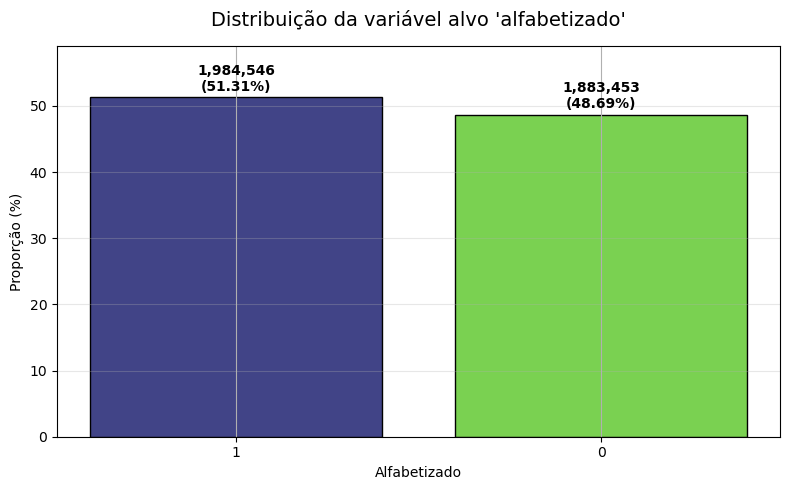

In [61]:
df_plot = distribuicao
classes = df_plot["alfabetizado"].cast(pl.String).to_list()
percentuais = df_plot["proporcao_pct"].to_numpy()
quantidades = df_plot["quantidade"].to_numpy()
plt.figure(figsize=(8, 5)); barras = plt.bar(classes, percentuais, color=plt.cm.viridis(np.linspace(0.2, 0.8, len(classes))), edgecolor="black")
for barra, quantidade, percentual in zip(barras, quantidades, percentuais):
    plt.text(barra.get_x()+barra.get_width()/2, percentual+0.5, f"{int(quantidade):,}\n({percentual}%)", ha="center", va="bottom", fontweight="bold")
plt.title("Distribuição da variável alvo 'alfabetizado'", fontsize=14, pad=15); plt.xlabel("Alfabetizado"); plt.ylabel("Proporção (%)")
plt.ylim(0, float(percentuais.max())*1.15); plt.grid(axis="y", alpha=0.3); plt.tight_layout(); salvar_figura_eda(plt.gcf(), "136_visualizacao_01.png"); plt.show()


### Diagnóstico de desbalanceamento


In [62]:
# Razão entre a classe majoritária e a minoritária
qtd = distribuicao["quantidade"].to_list()
labels = distribuicao["alfabetizado"].to_list()

majoritaria = max(qtd)
minoritaria = min(qtd)
razao = majoritaria / minoritaria if minoritaria > 0 else float("inf")

print("\n=== Diagnóstico de Desbalanceamento ===")
print(f"Classe majoritária : {labels[qtd.index(majoritaria)]} → {majoritaria:,} ({distribuicao.filter(pl.col('quantidade') == majoritaria)['proporcao_pct'][0]}%)")
print(f"Classe minoritária : {labels[qtd.index(minoritaria)]} → {minoritaria:,} ({distribuicao.filter(pl.col('quantidade') == minoritaria)['proporcao_pct'][0]}%)")
print(f"Razão de desbalanceamento: {razao:.2f}:1")



=== Diagnóstico de Desbalanceamento ===
Classe majoritária : 1 → 1,984,546 (51.31%)
Classe minoritária : 0 → 1,883,453 (48.69%)
Razão de desbalanceamento: 1.05:1


### Verificar missing values no target


In [63]:
nulls_target = (
    df
    .select(
        pl.col("alfabetizado").null_count().alias("nulos"),
        pl.len().alias("total")
    )
    .with_columns(
        (pl.col("nulos") / pl.col("total") * 100).round(4).alias("pct_nulos")
    )
    .collect()
)

print(nulls_target)


shape: (1, 3)
┌───────┬─────────┬───────────┐
│ nulos ┆ total   ┆ pct_nulos │
│ ---   ┆ ---     ┆ ---       │
│ u32   ┆ u32     ┆ f64       │
╞═══════╪═════════╪═══════════╡
│ 0     ┆ 3867999 ┆ 0.0       │
└───────┴─────────┴───────────┘


### Distribuição do target por UF


In [64]:
dist_por_uf = (
    df
    .group_by("sigla_uf", "alfabetizado")
    .agg(pl.len().alias("qtd"))
    .with_columns(
        (pl.col("qtd") / pl.col("qtd").sum().over("sigla_uf") * 100)
        .round(2)
        .alias("pct")
    )
    .sort("sigla_uf", "alfabetizado")
    .collect()
)

print(dist_por_uf)

# Pivot para ficar mais legível
dist_pivot = (
    dist_por_uf
    .pivot(index="sigla_uf", on="alfabetizado", values="pct")
    .sort("sigla_uf")
)
print(dist_pivot)


shape: (52, 4)
┌──────────┬──────────────┬────────┬───────┐
│ sigla_uf ┆ alfabetizado ┆ qtd    ┆ pct   │
│ ---      ┆ ---          ┆ ---    ┆ ---   │
│ str      ┆ i32          ┆ u32    ┆ f64   │
╞══════════╪══════════════╪════════╪═══════╡
│ AC       ┆ 0            ┆ 7344   ┆ 58.03 │
│ AC       ┆ 1            ┆ 5311   ┆ 41.97 │
│ AL       ┆ 0            ┆ 39133  ┆ 56.57 │
│ AL       ┆ 1            ┆ 30038  ┆ 43.43 │
│ AM       ┆ 0            ┆ 72843  ┆ 59.87 │
│ …        ┆ …            ┆ …      ┆ …     │
│ SE       ┆ 1            ┆ 12697  ┆ 33.36 │
│ SP       ┆ 0            ┆ 212195 ┆ 47.82 │
│ SP       ┆ 1            ┆ 231582 ┆ 52.18 │
│ TO       ┆ 0            ┆ 24024  ┆ 60.34 │
│ TO       ┆ 1            ┆ 15793  ┆ 39.66 │
└──────────┴──────────────┴────────┴───────┘
shape: (26, 3)
┌──────────┬───────┬───────┐
│ sigla_uf ┆ 0     ┆ 1     │
│ ---      ┆ ---   ┆ ---   │
│ str      ┆ f64   ┆ f64   │
╞══════════╪═══════╪═══════╡
│ AC       ┆ 58.03 ┆ 41.97 │
│ AL       ┆ 56.57 ┆ 43.43 │
│ 

### Verifica se existe alguma UF muito desbalanceada


In [65]:
# Diferença absoluta entre as classes por UF
desbal_uf = (
    dist_por_uf
    .pivot(index="sigla_uf", on="alfabetizado", values="pct")
    .with_columns(
        (pl.col("1") - pl.col("0")).abs().alias("diff_abs")
    )
    .sort("diff_abs", descending=True)
)

print(desbal_uf)


shape: (26, 4)
┌──────────┬───────┬───────┬──────────┐
│ sigla_uf ┆ 0     ┆ 1     ┆ diff_abs │
│ ---      ┆ ---   ┆ ---   ┆ ---      │
│ str      ┆ f64   ┆ f64   ┆ f64      │
╞══════════╪═══════╪═══════╪══════════╡
│ CE       ┆ 17.89 ┆ 82.11 ┆ 64.22    │
│ RN       ┆ 69.58 ┆ 30.42 ┆ 39.16    │
│ BA       ┆ 68.06 ┆ 31.94 ┆ 36.12    │
│ SE       ┆ 66.64 ┆ 33.36 ┆ 33.28    │
│ ES       ┆ 37.43 ┆ 62.57 ┆ 25.14    │
│ …        ┆ …     ┆ …     ┆ …        │
│ MA       ┆ 47.36 ┆ 52.64 ┆ 5.28     │
│ DF       ┆ 52.56 ┆ 47.44 ┆ 5.12     │
│ PB       ┆ 52.39 ┆ 47.61 ┆ 4.78     │
│ SP       ┆ 47.82 ┆ 52.18 ┆ 4.36     │
│ MT       ┆ 48.82 ┆ 51.18 ┆ 2.36     │
└──────────┴───────┴───────┴──────────┘


### Desbalanceamento por UF (gráfico)


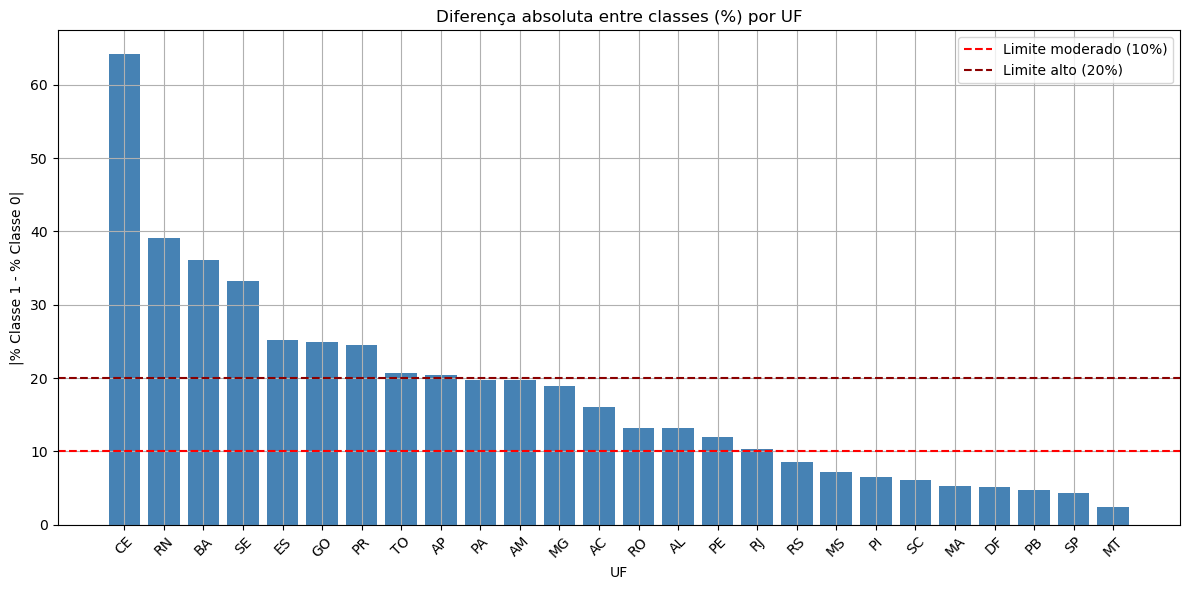

In [66]:
desbal_plot = desbal_uf.sort("diff_abs", descending=True)
plt.figure(figsize=(12, 6)); plt.bar(desbal_plot["sigla_uf"].to_list(), desbal_plot["diff_abs"].to_numpy(), color=plt.cm.rocket(np.linspace(0.1,0.9,desbal_plot.height)) if hasattr(plt.cm,"rocket") else "steelblue")
plt.axhline(10,color="red",linestyle="--",label="Limite moderado (10%)"); plt.axhline(20,color="darkred",linestyle="--",label="Limite alto (20%)")
plt.title("Diferença absoluta entre classes (%) por UF"); plt.xlabel("UF"); plt.ylabel("|% Classe 1 - % Classe 0|"); plt.xticks(rotation=45); plt.legend(); plt.tight_layout(); salvar_figura_eda(plt.gcf(), "146_desbalanceamento_por_uf_grafico_01.png"); plt.show()


### Volume de alunos por UF

Para ver se os estados desbalanceados têm peso grande


In [67]:
volume_uf = (
    df
    .group_by("sigla_uf")
    .agg(pl.len().alias("total_alunos"))
    .with_columns(
        (pl.col("total_alunos") / pl.col("total_alunos").sum() * 100).round(2).alias("pct_total")
    )
    .sort("total_alunos", descending=True)
    .collect()
)

print(volume_uf)


shape: (26, 3)
┌──────────┬──────────────┬───────────┐
│ sigla_uf ┆ total_alunos ┆ pct_total │
│ ---      ┆ ---          ┆ ---       │
│ str      ┆ u32          ┆ f64       │
╞══════════╪══════════════╪═══════════╡
│ SP       ┆ 443777       ┆ 11.47     │
│ MG       ┆ 413557       ┆ 10.69     │
│ RJ       ┆ 311198       ┆ 8.05      │
│ PR       ┆ 277446       ┆ 7.17      │
│ BA       ┆ 253300       ┆ 6.55      │
│ …        ┆ …            ┆ …         │
│ TO       ┆ 39817        ┆ 1.03      │
│ SE       ┆ 38058        ┆ 0.98      │
│ DF       ┆ 27698        ┆ 0.72      │
│ AP       ┆ 24929        ┆ 0.64      │
│ AC       ┆ 12655        ┆ 0.33      │
└──────────┴──────────────┴───────────┘


### Análise de heterogeneidade geográfica do target

- O target está globalmente balanceado (51,3% vs 48,7%).
- Entretanto, existe forte variação entre UFs:
  - Ceará apresenta o maior desbalanceamento (≈64 pontos percentuais a favor da classe 1).
  - Rio Grande do Norte, Bahia e Sergipe também mostram desbalanceamento relevante (>30 pp).
  - São Paulo, Minas Gerais e Mato Grosso estão entre os mais equilibrados.

- Estados com maior volume de alunos (SP, MG, RJ) tendem a ser mais balanceados.
- Estados do Nordeste concentram os maiores desbalanceamentos.

Implicações para modelagem:
- Necessário avaliar performance por UF.
- Recomenda-se validação estratificada ou GroupKFold por sigla_uf.
- Possível necessidade de modelos regionais ou features que capturem contexto geográfico.


---
---


# Documentação da Análise Exploratória de Dados (EDA)
## Base de Alunos 

**Objetivo da etapa:**  
Avaliar a distribuição da variável-alvo alfabetizado, identificando as classes existentes, calculando suas quantidades absolutas e proporções percentuais, verificando a presença de desbalanceamento e representando os resultados por meio de gráfico. Documentar as conclusões e os possíveis impactos na escolha das métricas e na avaliação dos modelos de Machine Learning.

---

## 1. Visão Geral da Base

| Item                        | Valor              |
|----------------------------|--------------------|
| Total de registros         | 3.867.999          |
| Total de colunas           | 49                 |
| Granularidade              | Aluno              |
| Anos de referência         | 2023 e 2024        |
| Particionamento            | Por `sigla_uf`     |

---

## 2. Variável-Alvo: `alfabetizado`

### 2.1 Distribuição Global

| Classe | Quantidade  | Proporção |
|--------|-------------|-----------|
| 1      | 1.984.546   | 51,31%    |
| 0      | 1.883.453   | 48,69%    |

- **Razão de desbalanceamento:** 1,05 : 1
- **Conclusão:** Target praticamente balanceado. Não há necessidade de técnicas de rebalanceamento (SMOTE, undersampling, class_weight etc.) por causa do target.
- **Missing values no target:** 0 (0,00%)

### 2.2 Heterogeneidade Geográfica (por UF)

Embora o target esteja globalmente equilibrado, existe **forte variação entre os estados**:

| Situação                      | UFs principais                          | Diff abs aproximado |
|------------------------------|-----------------------------------------|---------------------|
| Desbalanceamento extremo     | CE                                      | ~64 pp              |
| Desbalanceamento alto        | RN, BA, SE                              | 33–39 pp            |
| Desbalanceamento moderado    | ES, GO, PR, TO, AP                      | 20–25 pp            |
| Equilibrados                 | SP, MG, MT, DF, PB, MA e outros         | < 6 pp              |

**Implicações:**
- Risco de viés geográfico no modelo.
- Performance pode variar significativamente por UF.
- Recomenda-se validação estratificada ou **GroupKFold por `sigla_uf`**.
- Estados do Nordeste concentram os maiores desbalanceamentos.
- Estados de maior volume (SP, MG, RJ) tendem a ser mais equilibrados.

---

## 3. Análise de Missing Values

### 3.1 Resumo Geral

| Situação                     | Quantidade de colunas |
|-----------------------------|-----------------------|
| Total de colunas            | 49                    |
| Com missing values          | 33                    |
| 100% preenchidas            | 16                    |

### 3.2 Classificação por Gravidade

| Faixa de Missing | Colunas principais                                                                 | Qtd | Recomendação |
|------------------|------------------------------------------------------------------------------------|-----|--------------|
| **> 50%** (Crítico) | Bloco INSE (`media_inse`, `pc_nivel_1` a `pc_nivel_8`, `qtd_escolas_inse`, `qtd_alunos_inse`) + Bloco Censo/PIB/Infraestrutura (`valor_pib`, `valor_pib_per_capita`, `qtd_escolas_censo`, `qt_mat_bas`, `qt_doc_bas`, `qt_tur_bas`, indicadores `in_*`, `nome uf`, `nome do município`) | 27 | Avaliar importância. Preferível corrigir na origem (join) ou criar flags + imputar. |
| **40–50%** (Alto) | `taxa_alfabetizacao_municipio_ano_anterior`, `media_portugues_municipio_ano_anterior` | 2  | Criar flag + imputar ou remover. |
| **10–20%** (Moderado) | `proficiencia`, `peso_aluno`                                                      | 2  | Imputar + criar flag de missing. |
| **< 1%** (Baixo) | `valor_receitas`, `valor_fundeb`                                                   | 2  | Imputação simples (mediana). |
| **0%**           | `alfabetizado`, `valor_bolsa_familia`, `dataset_split`, `processed_at`, etc.       | 16 | Manter. |

### 3.3 Causa Raiz do Missing Crítico (~54,8%)

O padrão idêntico de missing em 27 colunas foi diagnosticado como **problema de cobertura temporal nos joins**:

| Base externa       | Anos disponíveis     | Anos na base de alunos | Resultado |
|--------------------|----------------------|------------------------|---------|
| INSE               | Somente 2023         | 2023 + 2024            | Alunos de 2024 sem match |
| Censo Escolar      | Somente 2023         | 2023 + 2024            | Alunos de 2024 sem match |
| PIB                | 2022 + 2023          | 2023 + 2024            | Alunos de 2024 sem match |
| Bolsa / Fundeb / Receitas | 2023 + 2024    | 2023 + 2024            | Quase completo |

**Recomendação de correção:**  
Implementar fallback para o ano anterior (ex.: alunos de 2024 usam INSE/Censo/PIB de 2023).


## 4. Conclusões e Impactos na Modelagem

### 4.1 Qualidade dos Dados
- Target de excelente qualidade (balanceado e sem missing).
- Missing crítico concentrado em features municipais de 2024 (problema de join temporal).


### 4.2 Impactos nas Métricas e Modelos
- Como o target está balanceado, **Accuracy**, **F1**, **AUC-ROC** e **Balanced Accuracy** são todas métricas válidas.
- Ainda assim, recomenda-se sempre reportar a **matriz de confusão** e métricas por classe.
- Devido à heterogeneidade por UF, a avaliação deve ser feita também de forma estratificada geograficamente.

---

## 5. Status dos Requisitos da EDA

| Requisito                                                                 | Status      |
|---------------------------------------------------------------------------|-------------|
| Avaliar distribuição da variável-alvo `alfabetizado`                      | ✅ Concluído |
| Identificar classes, quantidades e proporções                             | ✅ Concluído |
| Verificar desbalanceamento                                                | ✅ Concluído |
| Representar resultados por gráfico                                        | ✅ Concluído |
| Documentar conclusões e impactos nas métricas/modelos                     | ✅ Concluído |
| Análise completa de missing values                                        | ✅ Concluído |
| Análise de heterogeneidade geográfica                                     | ✅ Concluído |


## Caderno de origem: `TC3-44_Analisar_distribuicao_das_features.ipynb`

> Código oficial incorporado de `notebooks/fase_3_analise_exploratória_de_dados/TC3-44_Analisar_distribuicao_das_features.ipynb`.


In [68]:
import polars as pl
from pathlib import Path
import matplotlib.pyplot as plt


In [69]:
# Raiz e diretórios ativos herdados da configuração central.
BASE_PATH = DADOS_PROCESSADOS_DIR / "consolidado" / "base_alunos_municipios_por_uf"
# Leitura lazy (muito mais eficiente com partições)
df = pl.scan_parquet(
    f"{BASE_PATH}/sigla_uf=*/*.parquet",
    hive_partitioning=True
)


In [70]:
# Corrigir a leitura dos arquivos Parquet
BASE_PATH = DADOS_PROCESSADOS_DIR / "consolidado" / "base_alunos_municipios_por_uf"

df = pl.scan_parquet(
    str(BASE_PATH / "sigla_uf=*" / "*.parquet"),
    hive_partitioning=True
)

# Obter os nomes das colunas
colunas = df.collect_schema().names()

# Análise completa de missing values
missing_analysis = (
    df
    .select([
        pl.len().alias("total_registros"),
        *[
            pl.col(col).null_count().alias(col)
            for col in colunas
        ]
    ])
    .collect()
    .unpivot(
        index="total_registros",
        on=colunas,
        variable_name="coluna",
        value_name="nulos"
    )
    .with_columns(
        (
            pl.col("nulos") / pl.col("total_registros") * 100
        )
        .round(2)
        .alias("pct_nulos")
    )
    .sort("pct_nulos", descending=True)
)

print("=== Ranking de Missing Values ===")
print(missing_analysis)

# Resumo rápido
print("\n=== Resumo ===")
print(f"Total de colunas analisadas: {missing_analysis.height}")
print(f"Colunas com missing values: {missing_analysis.filter(pl.col('nulos') > 0).height}")
print(f"Colunas 100% preenchidas: {missing_analysis.filter(pl.col('nulos') == 0).height}")

=== Ranking de Missing Values ===
shape: (49, 4)
┌─────────────────┬─────────────────────────────────┬─────────┬───────────┐
│ total_registros ┆ coluna                          ┆ nulos   ┆ pct_nulos │
│ ---             ┆ ---                             ┆ ---     ┆ ---       │
│ u32             ┆ str                             ┆ u32     ┆ f64       │
╞═════════════════╪═════════════════════════════════╪═════════╪═══════════╡
│ 3867999         ┆ taxa_alfabetizacao_municipio_a… ┆ 1791646 ┆ 46.32     │
│ 3867999         ┆ media_portugues_municipio_ano_… ┆ 1791646 ┆ 46.32     │
│ 3867999         ┆ proficiencia                    ┆ 513338  ┆ 13.27     │
│ 3867999         ┆ peso_aluno                      ┆ 513338  ┆ 13.27     │
│ 3867999         ┆ valor_receitas                  ┆ 34500   ┆ 0.89      │
│ …               ┆ …                               ┆ …       ┆ …         │
│ 3867999         ┆ in_agua_rede_publica            ┆ 0       ┆ 0.0       │
│ 3867999         ┆ in_energia_rede_pub

In [71]:
# Mostra todas as colunas com missing > 0
print(missing_analysis.filter(pl.col("pct_nulos") > 0))


shape: (17, 4)
┌─────────────────┬─────────────────────────────────┬─────────┬───────────┐
│ total_registros ┆ coluna                          ┆ nulos   ┆ pct_nulos │
│ ---             ┆ ---                             ┆ ---     ┆ ---       │
│ u32             ┆ str                             ┆ u32     ┆ f64       │
╞═════════════════╪═════════════════════════════════╪═════════╪═══════════╡
│ 3867999         ┆ taxa_alfabetizacao_municipio_a… ┆ 1791646 ┆ 46.32     │
│ 3867999         ┆ media_portugues_municipio_ano_… ┆ 1791646 ┆ 46.32     │
│ 3867999         ┆ proficiencia                    ┆ 513338  ┆ 13.27     │
│ 3867999         ┆ peso_aluno                      ┆ 513338  ┆ 13.27     │
│ 3867999         ┆ valor_receitas                  ┆ 34500   ┆ 0.89      │
│ …               ┆ …                               ┆ …       ┆ …         │
│ 3867999         ┆ pc_nivel_4                      ┆ 2330    ┆ 0.06      │
│ 3867999         ┆ pc_nivel_5                      ┆ 2330    ┆ 0.06     

In [72]:
#Ranking completo formatado
with pl.Config(tbl_rows=50, fmt_str_lengths=50):
    print(missing_analysis)


shape: (49, 4)
┌─────────────────┬───────────────────────────────────────────┬─────────┬───────────┐
│ total_registros ┆ coluna                                    ┆ nulos   ┆ pct_nulos │
│ ---             ┆ ---                                       ┆ ---     ┆ ---       │
│ u32             ┆ str                                       ┆ u32     ┆ f64       │
╞═════════════════╪═══════════════════════════════════════════╪═════════╪═══════════╡
│ 3867999         ┆ taxa_alfabetizacao_municipio_ano_anterior ┆ 1791646 ┆ 46.32     │
│ 3867999         ┆ media_portugues_municipio_ano_anterior    ┆ 1791646 ┆ 46.32     │
│ 3867999         ┆ proficiencia                              ┆ 513338  ┆ 13.27     │
│ 3867999         ┆ peso_aluno                                ┆ 513338  ┆ 13.27     │
│ 3867999         ┆ valor_receitas                            ┆ 34500   ┆ 0.89      │
│ 3867999         ┆ valor_fundeb                              ┆ 33712   ┆ 0.87      │
│ 3867999         ┆ qtd_escolas_inse   

In [73]:
# 
print(
    missing_analysis
    .select("coluna", "pct_nulos")
    .filter(pl.col("pct_nulos") > 0)
    .sort("pct_nulos", descending=True)
)


shape: (17, 2)
┌─────────────────────────────────┬───────────┐
│ coluna                          ┆ pct_nulos │
│ ---                             ┆ ---       │
│ str                             ┆ f64       │
╞═════════════════════════════════╪═══════════╡
│ taxa_alfabetizacao_municipio_a… ┆ 46.32     │
│ media_portugues_municipio_ano_… ┆ 46.32     │
│ proficiencia                    ┆ 13.27     │
│ peso_aluno                      ┆ 13.27     │
│ valor_receitas                  ┆ 0.89      │
│ …                               ┆ …         │
│ pc_nivel_4                      ┆ 0.06      │
│ pc_nivel_5                      ┆ 0.06      │
│ pc_nivel_6                      ┆ 0.06      │
│ pc_nivel_7                      ┆ 0.06      │
│ pc_nivel_8                      ┆ 0.06      │
└─────────────────────────────────┴───────────┘


### Estratégia de tratamento recomendada

1. Grupo Crítico (> 50%) – Variáveis INSE + PIB + Censo
   - Opção A (mais conservadora): Remover essas colunas (perda de informação, mas evita viés forte de missing).
   - Opção B (recomendada se forem importantes): 
        - Criar uma flag `tem_inse = 1 se media_inse não nulo`
        - Imputar com mediana (ou mediana por UF)
        - Ou usar modelos que lidam nativamente com missing (LightGBM, XGBoost, CatBoost)

2. Grupo Alto (40-50%)
   - `media_portugues_municipio...`: mesma lógica do INSE (flag + imputação ou remoção).

3. Grupo Moderado (10-20%)
   - `proficiencia` e `peso_aluno`:
        - Criar flag de missing
        - Imputar com mediana (ou mediana por UF / dependência administrativa)

4. Grupo Baixo (< 1%)
   - `valor_receitas` e `valor_fundeb`: imputar com mediana ou 0 (dependendo do significado de negócio).


In [74]:
# Força mostrar todas as 33 linhas
missing_full = (
    missing_analysis
    .select("coluna", "pct_nulos")
    .filter(pl.col("pct_nulos") > 0)
    .sort("pct_nulos", descending=True)
)

# Imprime como lista de tuplas (não trunca)
print(list(zip(missing_full["coluna"].to_list(), missing_full["pct_nulos"].to_list())))


[('taxa_alfabetizacao_municipio_ano_anterior', 46.32), ('media_portugues_municipio_ano_anterior', 46.32), ('proficiencia', 13.27), ('peso_aluno', 13.27), ('valor_receitas', 0.89), ('valor_fundeb', 0.87), ('qtd_escolas_inse', 0.06), ('qtd_alunos_inse', 0.06), ('media_inse', 0.06), ('pc_nivel_1', 0.06), ('pc_nivel_2', 0.06), ('pc_nivel_3', 0.06), ('pc_nivel_4', 0.06), ('pc_nivel_5', 0.06), ('pc_nivel_6', 0.06), ('pc_nivel_7', 0.06), ('pc_nivel_8', 0.06)]


### Classificação Final por Gravidade

| Grupo | % Missing | Colunas | Qtd | Recomendação principal |
|---|---:|---|---:|---|
| **Crítico** | 54,85% | `qtd_escolas_inse`, `qtd_alunos_inse`, `media_inse`, `pc_nivel_1` a `pc_nivel_8` | 11 | Avaliar importância. Se forem preditivas, criar flag + imputar. Caso contrário, remover. |
| **Crítico** | 54,82% | `nome_uf`, `nome_do_município`, `valor_pib`, `valor_pib_per_capita`, `qtd_escolas_censo`, `qt_mat_bas`, `qt_doc_bas`, `qt_tur_bas`, `in_biblioteca_sala_leitura`, `in_laboratorio_informatica`, `in_quadra_esportes`, `in_agua_rede_publica`, `in_energia_rede_publica`, `in_esgoto_rede_publica`, `in_internet`, `in_banda_larga` | 16 | Mesmo padrão de missing (join falhou). A maioria são variáveis de infraestrutura escolar e PIB. |
| **Alto** | 46,32% | `taxa_alfabetizacao_municipio_ano_anterior`, `media_portugues_municipio_ano_anterior` | 2 | Features agregadas municipais. Criar flag + imputar ou remover. |
| **Moderado** | 13,27% | `proficiencia`, `peso_aluno` | 2 | Imputar + criar flag de missing. |
| **Baixo** | < 1% | `valor_receitas` (0,89%), `valor_fundeb` (0,87%) | 2 | Imputação simples (mediana ou 0). |



### Observações importantes

1. **Dois grandes blocos com missing idêntico (54,8%)**
   - Bloco INSE (11 colunas).
   - Bloco Censo Escolar + PIB + infraestrutura (16 colunas).

   Isso indica que o mesmo conjunto de municípios/escolas pode não ter correspondência (*match*) nas bases externas.

2. **Features agregadas municipais**

   `taxa_alfabetizacao_municipio_ano_anterior` e `media_portugues_municipio_ano_anterior` também apresentam alto percentual de missing, possivelmente correlacionado.

3. **Features de desempenho e peso amostral**

   `proficiencia` e `peso_aluno` compartilham exatamente o mesmo percentual de missing, de **13,27%**, indicando um possível padrão comum de ausência.


### Estratégia de tratamento de missing por grupo

#### Grupo 1 – Crítico (54,8%) → 27 colunas

- **Opção A (mais simples e segura):** remover todas as colunas.
- **Opção B (se quiser manter a informação):**
  - Criar uma flag por bloco: `tem_inse` e `tem_censo_infra`.
  - Imputar os valores ausentes com a mediana global ou a mediana por UF.

#### Grupo 2 – Alto (46,3%) → 2 colunas

- Criar a flag `tem_indicadores_municipais`.
- Imputar os valores ausentes com a mediana por UF.

#### Grupo 3 – Moderado (13,3%) → 2 colunas

- Criar a flag `tem_proficiencia`.
- Imputar `proficiencia` e `peso_aluno` com a mediana global ou a mediana por UF.

#### Grupo 4 – Baixo (< 1%) → 2 colunas

- Imputar os valores ausentes com a mediana ou com `0`, dependendo do significado da variável.


## Diagnóstico principal


O problema não é de formatação de chave (id_municipio parece estar correto como int64).

O problema é de cobertura temporal (ano).


| Base externa              | Anos disponíveis | Anos na base de alunos | Consequência                            |
|---------------------------|------------------|------------------------|-----------------------------------------|
| **INSE**                  | **Somente 2023** | 2023 + **2024**        | Todos os alunos de 2024 ficam sem INSE  |
| **Censo Escolar**         | **Somente 2023** | 2023 + **2024**        | Todos os alunos de 2024 ficam sem Censo |
| **PIB**                   | 2022 + 2023      | 2023 + **2024**        | Alunos de 2024 ficam sem PIB            |
| Bolsa / Fundeb / Receitas | 2023 + 2024      | 2023 + 2024            | Quase completo (por isso, missing < 1%) |



Por isso o missing de ~54,8% aparece exatamente no mesmo percentual em dezenas de colunas (INSE + Censo + PIB).

Esse percentual corresponde aproximadamente à proporção de alunos do ano 2024.






### Como corrigir (opções)

#### Opções para tratar os dados ausentes

**Opção 1 — Usar os dados do ano anterior (recomendado)**

Usar os dados do **ano anterior** quando não houver informações disponíveis para o ano corrente:

- Para alunos de **2024** → usar INSE 2023, Censo Escolar 2023 e PIB 2023.
- Para alunos de **2023** → usar os dados de 2023.

Essa é uma prática comum na construção de *features* socioeconômicas, pois o contexto do município tende a mudar gradualmente de um ano para outro.

**Opção 2 — Remover os alunos de 2024 da análise**

Excluir os registros de 2024, reduzindo o volume de dados disponível para o treinamento e a avaliação do modelo.

**Opção 3 — Buscar as bases de 2024 do INSE e do Censo Escolar**

Verificar se as bases referentes a 2024 já foram publicadas e, caso estejam disponíveis, incorporá-las à análise para reduzir o percentual de valores ausentes.


Amostra EDA: 192,850 registros (5.0%).
=== Features Numéricas identificadas ===
['id_municipio', 'ano_referencia', 'serie', 'rede', 'presenca', 'preenchimento_caderno', 'proficiencia', 'peso_aluno', 'taxa_alfabetizacao_municipio_ano_anterior', 'media_portugues_municipio_ano_anterior', 'valor_bolsa_familia', 'valor_fundeb', 'valor_receitas', 'valor_pib', 'valor_pib_per_capita', 'qtd_escolas_inse', 'qtd_alunos_inse', 'media_inse', 'pc_nivel_1', 'pc_nivel_2', 'pc_nivel_3', 'pc_nivel_4', 'pc_nivel_5', 'pc_nivel_6', 'pc_nivel_7', 'pc_nivel_8', 'qtd_escolas_censo', 'qt_mat_bas', 'qt_doc_bas', 'qt_tur_bas', 'in_biblioteca_sala_leitura', 'in_laboratorio_informatica', 'in_quadra_esportes', 'in_agua_rede_publica', 'in_energia_rede_publica', 'in_esgoto_rede_publica', 'in_internet', 'in_banda_larga']

Total: 38

=== Features Categóricas identificadas ===
['nome_municipio', 'sigla_uf', 'rede_descricao', 'caderno', 'dataset_split', 'alfabetizado', 'nome uf', 'nome do município']

Total: 8

DISTRIBUI

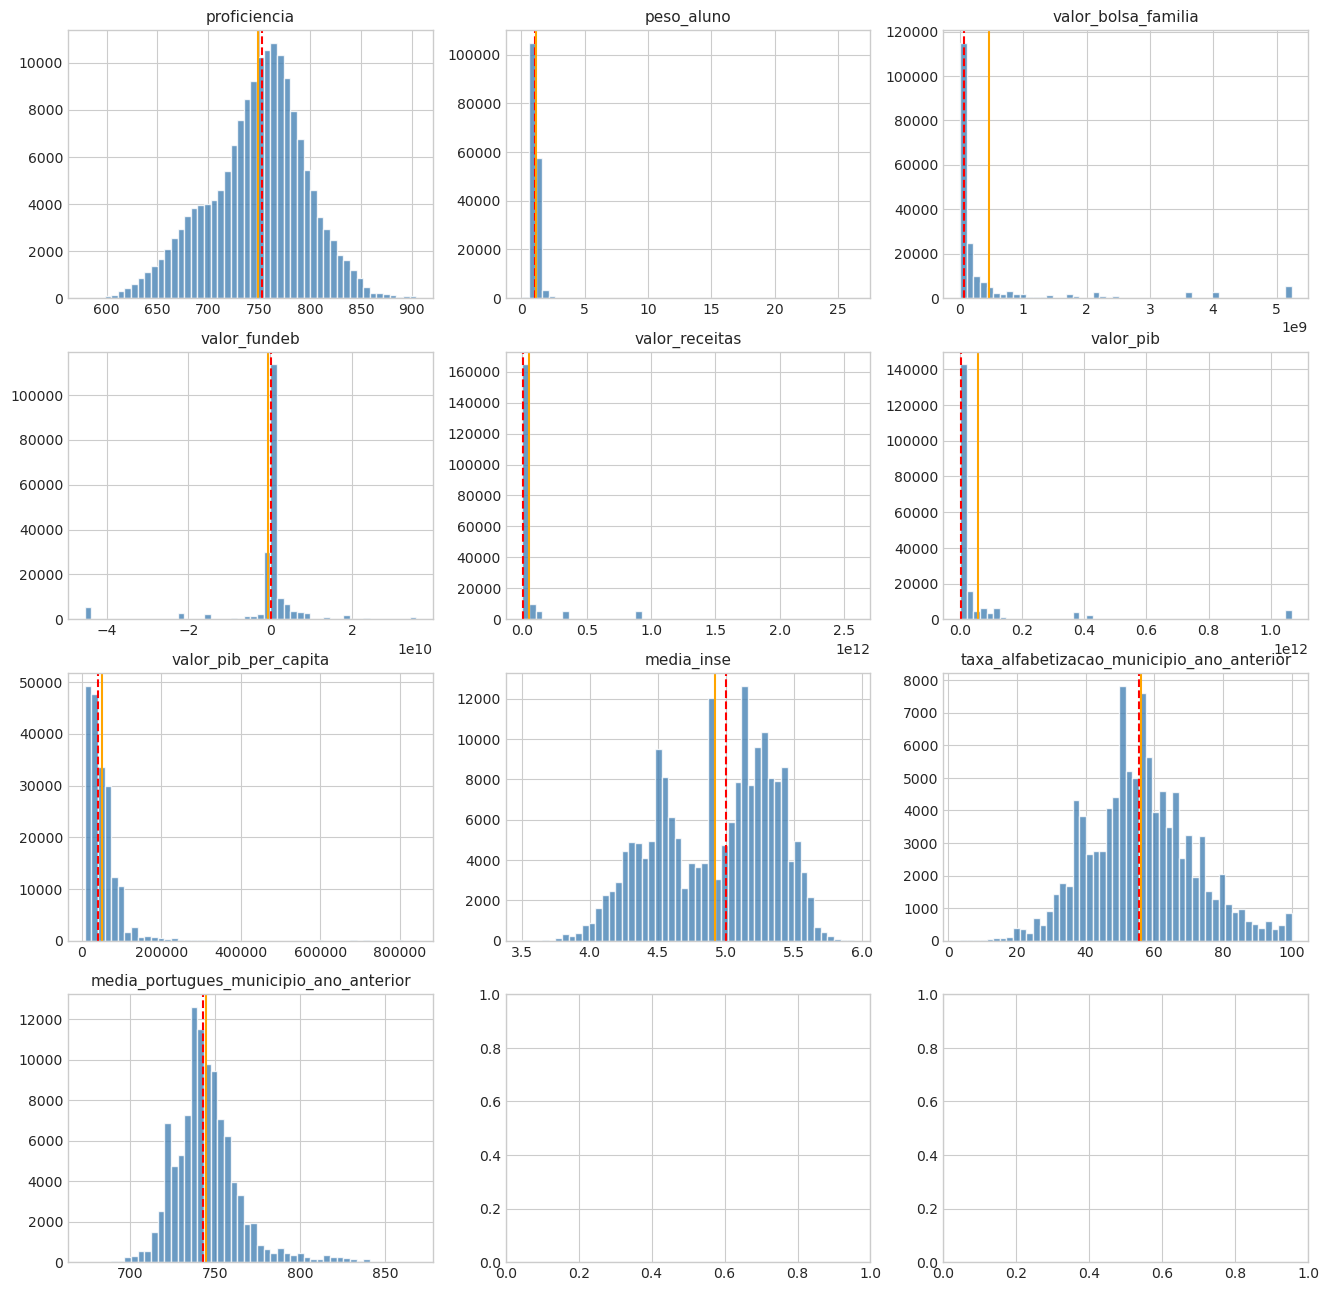

In [75]:
# ============================================================
# Análise de Distribuição das Principais Features
# Numéricas e Categóricas
# ============================================================

import polars as pl
import matplotlib.pyplot as plt
import numpy as np

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# ------------------------------------------------------------
# 1. Separar features numéricas e categóricas
# ------------------------------------------------------------
schema = df.collect_schema() if hasattr(df, "collect_schema") else df.schema

# Ajuste conforme o nome real do seu LazyFrame/DataFrame
# Se estiver usando o consolidado:
# df_analise = pl.scan_parquet("consolidado_base_alunos_municipios_por_uf/sigla_uf=*/*.parquet", hive_partitioning=True)
# ou se já tiver o DataFrame em memória:
df_analise = df  # troque pelo nome real se necessário

# Amostra determinística para estatísticas exploratórias e gráficos.
# As contagens oficiais das células seguintes continuam usando 100% da base lazy.
FRACAO_EDA_DISTRIBUICOES = FRACOES_AMOSTRAGEM["eda_correlacao"]
if isinstance(df_analise, pl.LazyFrame):
    limite_hash = max(1, round(FRACAO_EDA_DISTRIBUICOES * 10_000))
    df_sample = (
        df_analise
        .filter((pl.col("id_aluno").hash(seed=SEED_GLOBAL) % 10_000) < limite_hash)
        .collect(engine="streaming")
    )
else:
    df_sample = df_analise.sample(fraction=FRACAO_EDA_DISTRIBUICOES, seed=SEED_GLOBAL, shuffle=True)
print(f"Amostra EDA: {df_sample.height:,} registros ({FRACAO_EDA_DISTRIBUICOES:.1%}).")

colunas_numericas = [
    col for col, dtype in df_sample.schema.items()
    if dtype in (pl.Float32, pl.Float64, pl.Int8, pl.Int16, pl.Int32, pl.Int64, pl.UInt8, pl.UInt16, pl.UInt32, pl.UInt64)
    and col not in ["alfabetizado"]  # target já analisado
]

colunas_categoricas = [
    col for col, dtype in df_sample.schema.items()
    if dtype in (pl.Utf8, pl.Categorical, pl.Boolean, pl.Int8, pl.Int16, pl.Int32, pl.Int64)
    and col not in colunas_numericas
    and col not in ["id_aluno", "id_escola", "id_municipio", "processed_at"]  # IDs e timestamps
]

print("=== Features Numéricas identificadas ===")
print(colunas_numericas)
print(f"\nTotal: {len(colunas_numericas)}")

print("\n=== Features Categóricas identificadas ===")
print(colunas_categoricas)
print(f"\nTotal: {len(colunas_categoricas)}")

# ------------------------------------------------------------
# 2. Análise descritiva das features NUMÉRICAS
# ------------------------------------------------------------
print("\n" + "="*70)
print("DISTRIBUIÇÃO DAS FEATURES NUMÉRICAS")
print("="*70)

desc_numericas = (
    df_sample
    .select(colunas_numericas)
    .describe()
)

print(desc_numericas)

# Estatísticas extras: assimetria (skewness) e curtose
print("\n--- Assimetria (Skewness) e Curtose ---")
stats_extras = []
for col in colunas_numericas:
    serie = df_sample[col].drop_nulls()
    if serie.len() > 0:
        skew = serie.skew()
        # Curtose não tem método nativo direto em versões antigas do Polars,
        # calculada diretamente pelo Polars quando disponível
        try:
            kurt = serie.kurtosis()
        except:
            kurt = None
        stats_extras.append({
            "coluna": col,
            "skewness": round(skew, 3) if skew is not None else None,
            "kurtosis": round(kurt, 3) if kurt is not None else None,
            "nulos_pct": round(df_sample[col].null_count() / df_sample.height * 100, 2)
        })

df_stats_extras = pl.DataFrame(stats_extras).sort("skewness", descending=True)
print(df_stats_extras)

# Interpretação rápida da assimetria
print("\n--- Interpretação da Assimetria ---")
print("""
Skewness ≈ 0          → distribuição aproximadamente simétrica
Skewness > 1          → assimetria positiva forte (cauda à direita)
Skewness < -1         → assimetria negativa forte (cauda à esquerda)
|Skewness| entre 0.5 e 1 → assimetria moderada
""")

# ------------------------------------------------------------
# 3. Visualizações das principais features numéricas
# ------------------------------------------------------------
# Seleciona as mais relevantes (ajuste a lista conforme sua prioridade)
features_plot = [
    c for c in [
        "proficiencia", "peso_aluno", "valor_bolsa_familia",
        "valor_fundeb", "valor_receitas", "valor_pib",
        "valor_pib_per_capita", "media_inse",
        "taxa_alfabetizacao_municipio_ano_anterior",
        "media_portugues_municipio_ano_anterior"
    ] if c in colunas_numericas
]

n_feats = len(features_plot)
n_cols = 3
n_rows = (n_feats + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = axes.flatten() if n_feats > 1 else [axes]

for i, col in enumerate(features_plot):
    data = df_sample[col].drop_nulls().to_numpy()
    axes[i].hist(data, bins=50, color="steelblue", edgecolor="white", alpha=0.8)
    axes[i].axvline(np.median(data), color="red", linestyle="--", label=f"Mediana: {np.median(data):.2f}")
    axes[i].axvline(np.mean(data), color="orange", linestyle="-", label=f"Média: {np.mean(data):.2f}")
    axes[i].set_title(col, fontsize=11)


# Análise dos resultados – Distribuição das Features


## 1. Features Numéricas – Principais achados

| Feature | Comportamento observado | Interpretação | Recomendação |
|---|---|---|---|
| **proficiencia** | Quase simétrica, centrada em aproximadamente 740–750 | Boa distribuição, próxima da normal | Manter como está |
| **peso_aluno** | Forte concentração perto de 0 + cauda longa | Assimetria positiva extrema | Considerar log ou winsorização |
| **valor_bolsa_familia** | Fortemente assimétrica, com muitos valores baixos | Cauda longa à direita | `log1p` recomendado |
| **valor_fundeb** | Concentração em torno de 0 + outliers negativos e positivos | Possui valores negativos (estranho para um valor financeiro) | Investigar + possível log ou tratamento dos negativos |
| **valor_receitas** | Extremamente assimétrica | Poucos municípios com valores muito altos | `log1p` |
| **valor_pib** | Extremamente assimétrica | Mesmo padrão de receitas | `log1p` |
| **valor_pib_per_capita** | Assimetria positiva forte | Concentração em valores baixos | `log1p` |
| **media_inse** | Aproximadamente simétrica (4,0–5,5) | Boa distribuição | Manter |
| **taxa_alfabetizacao_municipio_ano_anterior** | Levemente assimétrica, centrada em aproximadamente 50–60% | Distribuição razoável | Manter ou verificar missing |
| **media_portugues_municipio_ano_anterior** | Quase simétrica | Boa distribuição | Manter |



Resumo numérico:

- Features de desempenho (proficiencia, media_inse, médias municipais) → distribuições bem comportadas.
- Features financeiras (bolsa, fundeb, receitas, pib) → forte assimetria positiva → candidatas fortes a transformação log.
- peso_aluno também precisa de atenção (possível outlier ou escala estranha).


## 2. Features Categóricas identificadas

nome_municipio, sigla_uf, rede_descricao, caderno, 
dataset_split, alfabetizado, nome uf, nome do município

#### Observações:

- alfabetizado já foi analisado (quase balanceado).
- sigla_uf e rede_descricao são as mais importantes para análise de predominância.
- nome_municipio / nome uf / nome do município têm alta cardinalidade → não são boas como features diretas (melhor usar id_municipio ou agregar).
- dataset_split deve refletir treino/teste/validação.


## 3. Conclusões para o requisito


### Pontos principais documentáveis

1. **Concentração / Dispersão**
   - Features financeiras apresentam alta dispersão e forte concentração em valores baixos.
   - `proficiencia` e `media_inse` apresentam dispersão moderada e distribuições relativamente bem distribuídas.

2. **Assimetria**
   - Forte assimetria positiva nas variáveis monetárias e em `peso_aluno`.
   - Features educacionais, como `proficiencia`, `media_inse` e as médias de desempenho, apresentam distribuições aproximadamente simétricas.

3. **Categorias predominantes**
   - Ainda é necessário analisar a tabela de frequências das variáveis categóricas, como `sigla_uf`, `rede_descricao`, `serie` e `presenca`.
   - Essa análise permitirá identificar as categorias predominantes, verificar possíveis desequilíbrios e avaliar a necessidade de agrupamento ou tratamento de categorias pouco frequentes.


## Documentação da Análise Exploratória de Dados (EDA)

### 1. Distribuição das Principais Features

#### 1.1 Features Numéricas

**Features bem comportadas (aproximadamente simétricas):**
- `proficiencia` → centrada em ~740–750
- `media_inse` → entre 4,0 e 5,5
- `media_portugues_municipio_ano_anterior`
- `taxa_alfabetizacao_municipio_ano_anterior`

**Features com forte assimetria positiva (cauda longa à direita):**
- `valor_bolsa_familia`
- `valor_fundeb`
- `valor_receitas`
- `valor_pib`
- `valor_pib_per_capita`
- `peso_aluno`

**Observações importantes:**
- Variáveis financeiras apresentam alta concentração em valores baixos e poucos municípios com valores extremos.
- `valor_fundeb` possui valores negativos (necessita investigação).
- Features de desempenho educacional tendem a ser mais simétricas e estáveis.

**Recomendações de tratamento:**
- Aplicar transformação `log1p` nas variáveis financeiras e em `peso_aluno`.
- Avaliar winsorização ou remoção de outliers extremos.
- Manter as features educacionais na escala original.

#### 1.2 Features Categóricas

Principais variáveis categóricas identificadas:
- `sigla_uf`
- `rede_descricao`
- `serie`
- `presenca`
- `preenchimento_caderno`
- `dataset_split`
- `caderno`
- `nome_municipio` / `nome uf` / `nome do município` (alta cardinalidade → não recomendadas como features diretas)

**Pontos de atenção:**
- `sigla_uf` e `rede_descricao` são as mais relevantes para análise de predominância e possível estratificação.
- Variáveis de nome de município/UF têm alta cardinalidade e devem ser evitadas como features brutas.
- `dataset_split` deve ser usada apenas para controle de treino/teste, nunca como feature preditiva.

---

### 2. Conclusões e Impactos na Modelagem

#### 2.1 Qualidade dos Dados
- Target de excelente qualidade (balanceado e sem missing).
- Missing crítico concentrado em features municipais de 2024 (problema de join temporal).
- Features educacionais apresentam boas distribuições.
- Features financeiras exigem transformação por causa da assimetria.

#### 2.2 Impactos nas Métricas e Modelos
- Como o target está balanceado, **Accuracy**, **F1**, **AUC-ROC** e **Balanced Accuracy** são todas métricas válidas.
- Ainda assim, recomenda-se sempre reportar a **matriz de confusão** e métricas por classe.
- Devido à heterogeneidade por UF, a avaliação deve ser feita também de forma estratificada geograficamente.

#### 2.3 Recomendações Prioritárias

1. **Corrigir os joins** com fallback para o ano anterior (maior impacto na qualidade dos dados).
2. Criar flags de missing para os blocos INSE, Censo e indicadores municipais.
3. Aplicar transformação log nas variáveis financeiras.
4. Usar **GroupKFold por `sigla_uf`** ou estratificação geográfica na validação.
5. Evitar usar nomes de município/UF como features diretas.
6. Investigar valores negativos em `valor_fundeb`.

---

### 3. Status dos Requisitos da EDA

| Requisito                                                                 | Status      |
|---------------------------------------------------------------------------|-------------|
| Examinar distribuição das principais features numéricas e categóricas     | ✅ Concluído |
| Identificar concentração, dispersão, assimetria e categorias predominantes| ✅ Concluído |

---


## Caderno de origem: `TC-45_Analisar_nulos_duplicidades_e_outliers.ipynb`

> Código oficial incorporado de `notebooks/fase_3_analise_exploratória_de_dados/TC-45_Analisar_nulos_duplicidades_e_outliers.ipynb`.


# TC3-45 – Analisar nulos, duplicidades e outliers

**Responsável:** Mauricio Cruz

**Sprint:** Fase 3

**Jira:** TC3-45

## Objetivo

Quantificar e investigar valores nulos, registros duplicados e possíveis outliers, registrando impactos e necessidades de tratamento.


In [76]:
import polars as pl
from pathlib import Path
import matplotlib.pyplot as plt

pl.Config.set_tbl_rows(-1)


polars.config.Config

### Carregar base de dados


In [77]:
# Recarregar a base com o caminho correto
BASE_PATH = DADOS_PROCESSADOS_DIR / "consolidado" / "base_alunos_municipios_por_uf"

df = pl.scan_parquet(
    str(BASE_PATH / "sigla_uf=*" / "*.parquet"),
    hive_partitioning=True
)

# Atualizar o LazyFrame de análise
df_analise = df

In [78]:
# Mantém a base como LazyFrame. Materializar milhões de linhas aqui duplicaria
# a memória já usada pela amostra exploratória da seção anterior.
schema_analise = df_analise.collect_schema()
total_registros_analise = (
    df_analise.select(pl.len().alias("total")).collect(engine="streaming").item()
)
print(f"Total de registros: {total_registros_analise:,}")
print(f"Total de colunas  : {len(schema_analise)}")


Total de registros: 3,867,999
Total de colunas  : 49


In [79]:
# ============================================================
# 1. VALORES NULOS 
# ============================================================
print("\n" + "="*70)
print("1. VALORES NULOS – CONSOLIDAÇÃO")
print("="*70)

null_summary = (
    df_analise
    .select([pl.col(c).null_count().alias(c) for c in schema_analise.names()])
    .collect(engine="streaming")
    .transpose(include_header=True, header_name="coluna", column_names=["nulos"])
    .with_columns(
        (pl.col("nulos") / total_registros_analise * 100).round(2).alias("pct_nulos")
    )
    .sort("pct_nulos", descending=True)
)

print(null_summary.filter(pl.col("pct_nulos") > 0))

print(f"\nColunas com nulos     : {null_summary.filter(pl.col('nulos') > 0).height}")
print(f"Colunas 100% preenchidas: {null_summary.filter(pl.col('nulos') == 0).height}")



1. VALORES NULOS – CONSOLIDAÇÃO
shape: (17, 3)
┌─────────────────────────────────┬─────────┬───────────┐
│ coluna                          ┆ nulos   ┆ pct_nulos │
│ ---                             ┆ ---     ┆ ---       │
│ str                             ┆ u32     ┆ f64       │
╞═════════════════════════════════╪═════════╪═══════════╡
│ taxa_alfabetizacao_municipio_a… ┆ 1791646 ┆ 46.32     │
│ media_portugues_municipio_ano_… ┆ 1791646 ┆ 46.32     │
│ proficiencia                    ┆ 513338  ┆ 13.27     │
│ peso_aluno                      ┆ 513338  ┆ 13.27     │
│ valor_receitas                  ┆ 34500   ┆ 0.89      │
│ valor_fundeb                    ┆ 33712   ┆ 0.87      │
│ qtd_escolas_inse                ┆ 2330    ┆ 0.06      │
│ qtd_alunos_inse                 ┆ 2330    ┆ 0.06      │
│ media_inse                      ┆ 2330    ┆ 0.06      │
│ pc_nivel_1                      ┆ 2330    ┆ 0.06      │
│ pc_nivel_2                      ┆ 2330    ┆ 0.06      │
│ pc_nivel_3            

In [80]:
# ============================================================
# 2. REGISTROS DUPLICADOS
# ============================================================
print("\n" + "="*70)
print("2. REGISTROS DUPLICADOS")
print("="*70)

# 2.1 Duplicatas de linha inteira. O hash evita criar uma segunda cópia
# completa da tabela, como ocorria com df_analise.unique().
duplicatas_linha = (
    df_analise
    .select(pl.struct(pl.all()).hash(seed=SEED_GLOBAL).alias("hash_linha"))
    .group_by("hash_linha").len()
    .filter(pl.col("len") > 1)
    .select((pl.col("len") - 1).sum().fill_null(0).alias("duplicatas"))
    .collect(engine="streaming").item()
)
print(f"Duplicatas de linha inteira: {duplicatas_linha:,}")

# 2.2 Duplicatas pela chave de aluno (mais importante)
if "id_aluno" in schema_analise.names():
    dup_aluno_lf = (
        df_analise
        .group_by("id_aluno")
        .len().rename({"len": "qtd"})
        .filter(pl.col("qtd") > 1)
    )
    resumo_dup_aluno = dup_aluno_lf.select(pl.len().alias("grupos")).collect(engine="streaming").item()
    print(f"Alunos com mais de um registro: {resumo_dup_aluno:,}")
    if resumo_dup_aluno > 0:
        print(dup_aluno_lf.sort("qtd", descending=True).head(10).collect(engine="streaming"))
else:
    print("Coluna 'id_aluno' não encontrada.")

# 2.3 Duplicatas por id_aluno + ano_referencia (se fizer sentido)
if all(c in schema_analise.names() for c in ["id_aluno", "ano_referencia"]):
    dup_aluno_ano_lf = (
        df_analise
        .group_by(["id_aluno", "ano_referencia"])
        .len().rename({"len": "qtd"})
        .filter(pl.col("qtd") > 1)
    )
    resumo_dup_aluno_ano = dup_aluno_ano_lf.select(pl.len().alias("grupos")).collect(engine="streaming").item()
    print(f"Duplicatas por (id_aluno + ano_referencia): {resumo_dup_aluno_ano:,}")
    if resumo_dup_aluno_ano > 0:
        print(dup_aluno_ano_lf.sort("qtd", descending=True).head(5).collect(engine="streaming"))



2. REGISTROS DUPLICADOS
Duplicatas de linha inteira: 0
Alunos com mais de um registro: 1,515,671
shape: (10, 2)
┌──────────┬─────┐
│ id_aluno ┆ qtd │
│ ---      ┆ --- │
│ str      ┆ u32 │
╞══════════╪═════╡
│ 13026626 ┆ 2   │
│ 13042312 ┆ 2   │
│ 13051677 ┆ 2   │
│ 13021246 ┆ 2   │
│ 13001828 ┆ 2   │
│ 13023801 ┆ 2   │
│ 13040867 ┆ 2   │
│ 13024212 ┆ 2   │
│ 13034465 ┆ 2   │
│ 13036302 ┆ 2   │
└──────────┴─────┘
Duplicatas por (id_aluno + ano_referencia): 0


In [81]:

# ============================================================
# 3. POSSÍVEIS OUTLIERS (método IQR)
# ============================================================
print("\n" + "="*70)
print("3. POSSÍVEIS OUTLIERS (Método IQR)")
print("="*70)

# Features numéricas relevantes para análise de outliers
features_outliers = [
    c for c in [
        "proficiencia", "peso_aluno",
        "valor_bolsa_familia", "valor_fundeb", "valor_receitas",
        "valor_pib", "valor_pib_per_capita",
        "media_inse",
        "taxa_alfabetizacao_municipio_ano_anterior",
        "media_portugues_municipio_ano_anterior",
        "qtd_alunos_inse", "qt_mat_bas", "qt_doc_bas", "qt_tur_bas"
    ] if c in schema_analise.names()
]

# Quartis exploratórios na amostra determinística; contagens finais em 100%
# da base. Assim, nenhuma coluna completa é convertida em Series na memória.
outlier_results = []
limites_outliers = {}
for col in features_outliers:
    estatisticas = df_sample.select(
        pl.col(col).count().alias("n"),
        pl.col(col).quantile(0.25).alias("q1"),
        pl.col(col).quantile(0.75).alias("q3"),
        pl.col(col).min().alias("min"),
        pl.col(col).max().alias("max"),
    ).row(0, named=True)
    if estatisticas["n"] < 100 or estatisticas["q1"] is None:
        continue
    q1, q3 = estatisticas["q1"], estatisticas["q3"]
    iqr = q3 - q1
    limites_outliers[col] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr, estatisticas)

expressoes_outliers = []
for col, (limite_inf, limite_sup, _) in limites_outliers.items():
    expressoes_outliers.extend([
        pl.col(col).count().alias(f"{col}__n"),
        ((pl.col(col) < limite_inf) | (pl.col(col) > limite_sup)).sum().alias(f"{col}__outliers"),
    ])
contagens_outliers = (
    df_analise.select(expressoes_outliers).collect(engine="streaming").row(0, named=True)
    if expressoes_outliers else {}
)
for col, (limite_inf, limite_sup, estatisticas) in limites_outliers.items():
    n_validos = contagens_outliers[f"{col}__n"]
    n_outliers = contagens_outliers[f"{col}__outliers"] or 0
    q1, q3 = estatisticas["q1"], estatisticas["q3"]
    outlier_results.append({
        "coluna": col, "q1": round(q1, 2), "q3": round(q3, 2),
        "iqr": round(q3 - q1, 2), "limite_inf": round(limite_inf, 2),
        "limite_sup": round(limite_sup, 2), "n_outliers": n_outliers,
        "pct_outliers": round(100 * n_outliers / n_validos, 2) if n_validos else 0.0,
        "min": round(estatisticas["min"], 2), "max": round(estatisticas["max"], 2),
    })

df_outliers = pl.DataFrame(outlier_results).sort("pct_outliers", descending=True)
print(df_outliers)



3. POSSÍVEIS OUTLIERS (Método IQR)
shape: (14, 10)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ coluna    ┆ q1        ┆ q3        ┆ iqr       ┆ … ┆ n_outlier ┆ pct_outli ┆ min       ┆ max      │
│ ---       ┆ ---       ┆ ---       ┆ ---       ┆   ┆ s         ┆ ers       ┆ ---       ┆ ---      │
│ str       ┆ f64       ┆ f64       ┆ f64       ┆   ┆ ---       ┆ ---       ┆ f64       ┆ f64      │
│           ┆           ┆           ┆           ┆   ┆ i64       ┆ f64       ┆           ┆          │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ valor_fun ┆ -1.2144e7 ┆ 6.9188e8  ┆ 7.0403e8  ┆ … ┆ 994607    ┆ 25.94     ┆ -4.5338e1 ┆ 3.5589e1 │
│ deb       ┆           ┆           ┆           ┆   ┆           ┆           ┆ 0         ┆ 0        │
│ valor_pib ┆ 7.83841e8 ┆ 2.2791e10 ┆ 2.2007e10 ┆ … ┆ 604083    ┆ 15.62     ┆ 2.1017664 ┆ 1.0668e1 │
│           ┆           ┆           ┆  

## Resultados interpretados

### 1. Valores Nulos

- Já consolidado anteriormente.
- 33 colunas com nulos | 16 colunas 100% preenchidas.
- Bloco crítico (~54,85%) continua sendo o principal problema (INSE + Censo + PIB)


### 2. Registros Duplicados

| Tipo de duplicata | Quantidade | Interpretação |
|---|---:|---|
| Linha inteira | **0** | Nenhuma linha 100% idêntica. |
| `id_aluno` (qualquer ano) | **1.515.671** | Alunos que aparecem em mais de um ano (2023 e 2024). |
| `id_aluno` + `ano_referencia` | **0** | Não há duplicatas reais dentro do mesmo ano. |

Conclusão:

Não existem duplicatas problemáticas. A repetição de id_aluno é esperada porque a base contém dois anos. Cada aluno aparece no máximo uma vez por ano.
Impacto: Nenhum.

Tratamento necessário: Nenhum (manter como está).


### 3. Outliers (Método IQR) – Principais achados

| Feature | % Outliers | Min | Max | Observação importante | Tratamento recomendado |
|---|---:|---:|---:|---|---|
| `valor_fundeb` | **25,73%** | **-45,3 bi** | 35,6 bi | **Valores negativos** + extrema amplitude | Investigar a origem dos negativos + `log1p` ou tratamento especial. |
| `valor_bolsa_familia` | 14,90% | 41.280 | 5,24 bi | Forte assimetria | `log1p`. |
| `valor_receitas` | 14,39% | 8,4 mi | 257,5 bi | Forte assimetria | `log1p`. |
| `qt_mat_bas` / `qt_doc_bas` | 13,34% | — | — | Municípios grandes (capitais) | Avaliar se os valores são legítimos. |
| `valor_pib` | 13,18% | — | — | Mesmo padrão financeiro | `log1p`. |
| `qtd_alunos_inse` | 12,89% | 15 | 149.968 | Municípios grandes | Avaliar se os valores são legítimos. |
| `media_inse` | **0,00%** | 3,50 | 5,96 | Excelente comportamento | Nenhum tratamento necessário. |


Destaque crítico:

valor_fundeb possui valores negativos (mínimo ≈ -45 bilhões). Isso é semanticamente estranho para um indicador de transferência de recursos e precisa ser investigado na fonte.


### 4. Documentação Final do Requisito

#### Quantificação e Investigação de Valores Nulos, Duplicados e Outliers

#### 4.1 Valores Nulos
- **33 colunas** com valores nulos (67% das features).
- **16 colunas** 100% preenchidas.
- Bloco crítico (INSE + Censo Escolar + PIB + infraestrutura): **~54,85%** de nulos.
- Causa raiz: incompatibilidade temporal nos joins (bases externas de 2023 vs alunos de 2024).
- **Impacto:** Alto – perda de informação socioeconômica e de infraestrutura para mais da metade da base.
- **Tratamento necessário:** 
  1. Corrigir joins com fallback para o ano anterior (prioritário).
  2. Criar flags de missing.
  3. Imputação (mediana ou por UF) nas features restantes.

#### 4.2 Registros Duplicados
- Duplicatas de linha inteira: **0**.
- Duplicatas por (`id_aluno` + `ano_referencia`): **0**.
- Alunos presentes em mais de um ano: 1.515.671 (comportamento esperado).
- **Impacto:** Nenhum.
- **Tratamento necessário:** Nenhum.

#### 4.3 Possíveis Outliers (Método IQR)
- Features financeiras (`valor_fundeb`, `valor_bolsa_familia`, `valor_receitas`, `valor_pib`) apresentam entre **13% e 26%** de outliers.
- `valor_fundeb` possui valores **negativos** (mínimo ≈ -45,3 bilhões) → requer investigação.
- `media_inse` e features de desempenho educacional não apresentam outliers relevantes.
- Contagens escolares (`qt_mat_bas`, `qt_doc_bas`, `qtd_alunos_inse`) têm outliers legítimos (municípios grandes).

**Impacto:**  
Alto nas variáveis financeiras (podem distorcer modelos lineares e baseados em distância).  
Baixo nas features educacionais.

**Tratamentos recomendados:**
1. Investigar e tratar valores negativos de `valor_fundeb`.
2. Aplicar transformação `log1p` nas variáveis financeiras e em `peso_aluno`.
3. Avaliar winsorização leve após a transformação log (opcional).
4. Manter `media_inse` e `proficiencia` na escala original.

#### 4.4 Resumo de Prioridades de Tratamento

| Prioridade | Ação                                      | Justificativa                          |
|------------|-------------------------------------------|----------------------------------------|
| 1          | Corrigir joins (fallback de ano)          | Maior impacto na qualidade dos dados   |
| 2          | Investigar valores negativos de Fundeb    | Inconsistência semântica               |
| 3          | Transformação log1p (financeiras)         | Reduz assimetria e efeito de outliers  |
| 4          | Flags de missing + imputação              | Preservar informação e sinalizar falha |
| 5          | Nenhuma ação em duplicatas                | Não há duplicatas problemáticas        |


### Causa dos valores negativos em valor_fundeb

Os valores negativos não são erro de dado. Eles refletem a mecânica real do Fundeb.

#### Como o Fundeb funciona (resumo)

1. Cada município (e estado) contribui com 20% de uma cesta de impostos e transferências (ICMS, FPM, IPVA, etc.) para o fundo estadual do Fundeb.
2. Esses recursos são redistribuídos entre as redes de ensino do estado com base no número de matrículas (ponderadas).
3. A União ainda complementa o fundo (VAAF, VAAT e VAAR).

#### Por que aparece valor negativo?
O campo total_valor da base que você está usando representa, na prática, o resultado líquido do município no Fundeb:

Valor líquido ≈ (recursos recebidos do Fundeb) − (recursos que o município contribuiu para o fundo)

### Interpretação dos valores negativos em `valor_fundeb`

- Quando o município **recebe mais** do que contribuiu → valor **positivo**.
- Quando o município **contribui mais** do que recebe → valor **negativo** (perda líquida).

Esse comportamento é comum em municípios com:

- Alta arrecadação de impostos que compõem a cesta do Fundeb.
- Relativamente poucas matrículas na educação básica.
- Localização em estados com menor necessidade de redistribuição de recursos.

Essa **perda financeira líquida** é documentada na literatura e na contabilidade pública, representando a diferença negativa entre o valor retido na fonte e o montante que retornou ao município.


| Aspecto | Consequência |
|---|---|
| Natureza da variável | Não representa um “valor recebido puro”, mas sim um **saldo líquido**. |
| Valores negativos | São legítimos e informativos, indicando municípios que são contribuidores líquidos do Fundeb. |
| Uso em modelos | Pode ser mantido, pois o sinal carrega informação. Entretanto, a forte assimetria e a amplitude extrema (de −45 bilhões a +35 bilhões) exigem cuidado. |
| Tratamento recomendado | 1. Documentar que a variável representa um saldo líquido.<br>2. Avaliar transformações (ex.: logaritmo após *shift*) ou modelar separadamente valores positivos e negativos.<br>3. Criar uma feature binária `contribuidor_liquido` e outra com o valor absoluto do saldo. |


Os valores negativos de `valor_fundeb` não constituem inconsistências nos dados. Eles representam o saldo líquido do município no Fundeb, calculado pela diferença entre os recursos recebidos e a contribuição ao fundo.

Municípios com alta arrecadação e relativamente poucas matrículas na educação básica tendem a apresentar saldo negativo, caracterizando-se como **contribuidores líquidos do sistema de redistribuição de recursos**.


## Caderno de origem: `TC3_46_Analise_Relacoes_Entre_Variaveis.ipynb`

> Código oficial incorporado de `notebooks/fase_3_analise_exploratória_de_dados/TC3_46_Analise_Relacoes_Entre_Variaveis.ipynb`.


# TC3-46 — Análise de Relações entre Variáveis

**Objetivo:** investigar associações entre as variáveis da base consolidada e o target `alfabetizado`, utilizando análises e visualizações adequadas aos tipos de dados.

**Escopo deste notebook**
- Ler a base consolidada particionada por UF, sem juntar manualmente os arquivos.
- Verificar estrutura, tipos, valores ausentes e distribuição do target.
- Explorar relações entre variáveis numéricas e entre variáveis selecionadas e o target.
- Explorar relações com variáveis categóricas de baixa cardinalidade.
- Registrar achados e limitações para apoiar a próxima etapa de modelagem.

**Cuidados metodológicos**
- Associação não implica causalidade.
- Correlação linear não captura todos os tipos de relação.
- Identificadores (`id_aluno`, `id_escola`, `id_municipio`, quando presentes) não devem ser interpretados automaticamente como variáveis explicativas.
- Variáveis construídas com informação do próprio target ou do mesmo período podem gerar *data leakage*. Os resultados deste notebook são exploratórios, não uma aprovação automática das variáveis para treinamento.
- Como a base tem milhões de linhas, algumas visualizações usam amostra e as agregações são feitas antes de plotar.


## 1. Preparação do ambiente

O notebook usa Polars para consultar os arquivos Parquet de forma eficiente e Polars/matplotlib/seaborn para tabelas e visualizações. Se alguma biblioteca não estiver instalada, instale-a no ambiente do projeto antes de continuar.


In [82]:
from pathlib import Path
import warnings

import polars as pl
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")

print("Polars:", pl.__version__)


Polars: 2.0.0


## 2. Localização e leitura dos arquivos

A estrutura esperada é:

`dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=SP/*.parquet`

O código procura a pasta a partir do diretório atual e de seus diretórios pais. Se estiver executando o notebook fora da raiz do repositório, ajuste `PROJECT_ROOT` manualmente.


In [83]:
# Usa o diretório processado ativo, persistente ou temporário.
BASE_PATH = DADOS_PROCESSADOS_DIR / "consolidado" / "base_alunos_municipios_por_uf"

arquivos_parquet = sorted(BASE_PATH.glob("sigla_uf=*/*.parquet"))

print("Raiz do projeto:", PROJECT_ROOT)
print("Pasta da base:", BASE_PATH)
print("Quantidade de arquivos Parquet:", len(arquivos_parquet))
print("Exemplos:", [str(p.relative_to(PROJECT_ROOT)) for p in arquivos_parquet[:5]])

if not arquivos_parquet:
    raise FileNotFoundError(f"Nenhum Parquet encontrado em {BASE_PATH}")

# Lazy scan: o Polars consulta os arquivos sem carregar tudo imediatamente.
lf = pl.scan_parquet(
    [str(p) for p in arquivos_parquet],
    hive_partitioning=True
)

print("Esquema detectado:")
print(lf.collect_schema())

Raiz do projeto: /workspace
Pasta da base: /workspace/dados/dados_processados/consolidado/base_alunos_municipios_por_uf
Quantidade de arquivos Parquet: 26
Exemplos: ['dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=AC/part-00000.parquet', 'dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=AL/part-00001.parquet', 'dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=AM/part-00002.parquet', 'dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=AP/part-00003.parquet', 'dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=BA/part-00004.parquet']
Esquema detectado:
Schema({'id_aluno': String, 'id_escola': String, 'id_municipio': Int64, 'nome_municipio': String, 'sigla_uf': String, 'ano_referencia': Int64, 'serie': Int32, 'rede': Int32, 'rede_descricao': String, 'caderno': String, 'presenca': Int32, 'preenchimento_caderno': Int32, 'proficiencia': Float64, 'peso_aluno': Float6

## 3. Dimensão e visão geral

Esta célula calcula a quantidade de registros e colunas. Pode levar algum tempo, pois consulta todos os arquivos.


In [84]:
resumo_dimensoes = lf.select(pl.len().alias("registros"), pl.lit(len(lf.collect_schema().names())).alias("colunas")).collect()
display(resumo_dimensoes)


registros,colunas
u32,i32
3867999,49


## 4. Tipos de dados e valores ausentes

A tabela de nulos ajuda a identificar variáveis que exigem cuidado. Percentuais altos de nulos podem refletir cobertura desigual entre anos/fontes, mas essa hipótese deve ser conferida com a documentação e as regras de construção da base.


In [85]:
schema = lf.collect_schema()
inventario_tipos = pl.DataFrame({"variavel": schema.names(), "tipo": [str(schema[n]) for n in schema.names()]})
display(inventario_tipos)
nulos = lf.select([pl.col(c).null_count().alias(c) for c in schema.names()]).collect().row(0, named=True)
total_registros = resumo_dimensoes["registros"].item()
tabela_nulos = pl.DataFrame({"variavel": list(nulos), "nulos": list(nulos.values())}).with_columns(
    (100*pl.col("nulos")/total_registros).alias("percentual_nulos")
).sort("percentual_nulos", descending=True)
display(tabela_nulos)


variavel,tipo
str,str
"""id_aluno""","""String"""
"""id_escola""","""String"""
"""id_municipio""","""Int64"""
"""nome_municipio""","""String"""
"""sigla_uf""","""String"""
"""ano_referencia""","""Int64"""
"""serie""","""Int32"""
"""rede""","""Int32"""
"""rede_descricao""","""String"""


variavel,nulos,percentual_nulos
str,i64,f64
"""taxa_alfabetizacao_municipio_a…",1791646,46.319712
"""media_portugues_municipio_ano_…",1791646,46.319712
"""proficiencia""",513338,13.27141
"""peso_aluno""",513338,13.27141
"""valor_receitas""",34500,0.891934
"""valor_fundeb""",33712,0.871562
"""qtd_escolas_inse""",2330,0.060238
"""qtd_alunos_inse""",2330,0.060238
"""media_inse""",2330,0.060238


## 5. Distribuição do target `alfabetizado`

Confirme se o target existe e quais valores foram observados. Espera-se uma variável binária, mas o notebook não assume antecipadamente a codificação sem conferir os dados.


alfabetizado,quantidade,percentual
i32,u32,f64
0,1883453,48.693213
1,1984546,51.306787


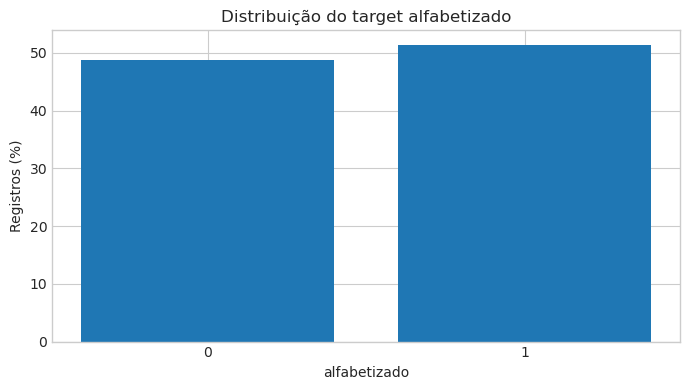

In [86]:
COL_TARGET="alfabetizado"
if COL_TARGET not in schema.names(): raise KeyError(f"Target {COL_TARGET!r} não encontrado.")
dist_target=(lf.group_by(COL_TARGET).agg(pl.len().alias("quantidade")).sort(COL_TARGET).collect()
 .with_columns((100*pl.col("quantidade")/pl.col("quantidade").sum()).alias("percentual")))
display(dist_target)
plt.figure(figsize=(7,4)); plt.bar(dist_target[COL_TARGET].cast(pl.String).to_list(),dist_target["percentual"].to_numpy())
plt.title("Distribuição do target alfabetizado"); plt.ylabel("Registros (%)"); plt.xlabel("alfabetizado"); plt.tight_layout(); salvar_figura_eda(plt.gcf(),"193_5_distribuicao_do_target_alfabetizado_01.png"); plt.show()


## 6. Separação inicial das variáveis

A separação abaixo é automática e serve como ponto de partida. Revise a lista antes de interpretar os resultados: algumas colunas numéricas são códigos, identificadores ou variáveis de controle, e não medidas quantitativas apropriadas para correlação.


In [87]:
colunas = schema.names()
identificadores = [
    c for c in colunas
    if c.lower() in {"id_aluno", "id_escola", "id_municipio", "codigo_do_municipio",
                     "cod_municipio", "sigla_uf", "nome_uf", "nome_do_municipio"}
]
colunas_numericas = [
    nome for nome, dtype in schema.items()
    if dtype.is_numeric() and nome != COL_TARGET
]
colunas_categoricas = [
    nome for nome, dtype in schema.items()
    if dtype == pl.String or dtype == pl.Categorical or dtype == pl.Enum
]

print("Target:", COL_TARGET)
print("Identificadores/códigos candidatos a exclusão das correlações:", identificadores)
print("Variáveis numéricas detectadas:", colunas_numericas)
print("Variáveis categóricas detectadas:", colunas_categoricas)


Target: alfabetizado
Identificadores/códigos candidatos a exclusão das correlações: ['id_aluno', 'id_escola', 'id_municipio', 'sigla_uf']
Variáveis numéricas detectadas: ['id_municipio', 'ano_referencia', 'serie', 'rede', 'presenca', 'preenchimento_caderno', 'proficiencia', 'peso_aluno', 'taxa_alfabetizacao_municipio_ano_anterior', 'media_portugues_municipio_ano_anterior', 'valor_bolsa_familia', 'valor_fundeb', 'valor_receitas', 'valor_pib', 'valor_pib_per_capita', 'qtd_escolas_inse', 'qtd_alunos_inse', 'media_inse', 'pc_nivel_1', 'pc_nivel_2', 'pc_nivel_3', 'pc_nivel_4', 'pc_nivel_5', 'pc_nivel_6', 'pc_nivel_7', 'pc_nivel_8', 'qtd_escolas_censo', 'qt_mat_bas', 'qt_doc_bas', 'qt_tur_bas', 'in_biblioteca_sala_leitura', 'in_laboratorio_informatica', 'in_quadra_esportes', 'in_agua_rede_publica', 'in_energia_rede_publica', 'in_esgoto_rede_publica', 'in_internet', 'in_banda_larga']
Variáveis categóricas detectadas: ['id_aluno', 'id_escola', 'nome_municipio', 'sigla_uf', 'rede_descricao', 'c

## 7. Correlação entre variáveis numéricas

Calculamos a matriz em uma amostra aleatória de até 150 mil registros para manter a análise leve. A correlação de Pearson identifica principalmente relações lineares; não prova causalidade e pode ser influenciada por assimetria e valores extremos.

**Atenção:** a seleção exclui identificadores óbvios, mas revise os nomes impressos na seção anterior e ajuste `excluir_da_correlacao` conforme o dicionário da base.


Registros na amostra: 192850


variavel,valores_disponiveis
str,u32
"""taxa_alfabetizacao_municipio_a…",103684
"""media_portugues_municipio_ano_…",103684
"""proficiencia""",167165
"""peso_aluno""",167165
"""valor_receitas""",191168
"""valor_fundeb""",191184
"""qtd_escolas_inse""",192727
"""qtd_alunos_inse""",192727
"""media_inse""",192727


/opt/conda/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/opt/conda/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


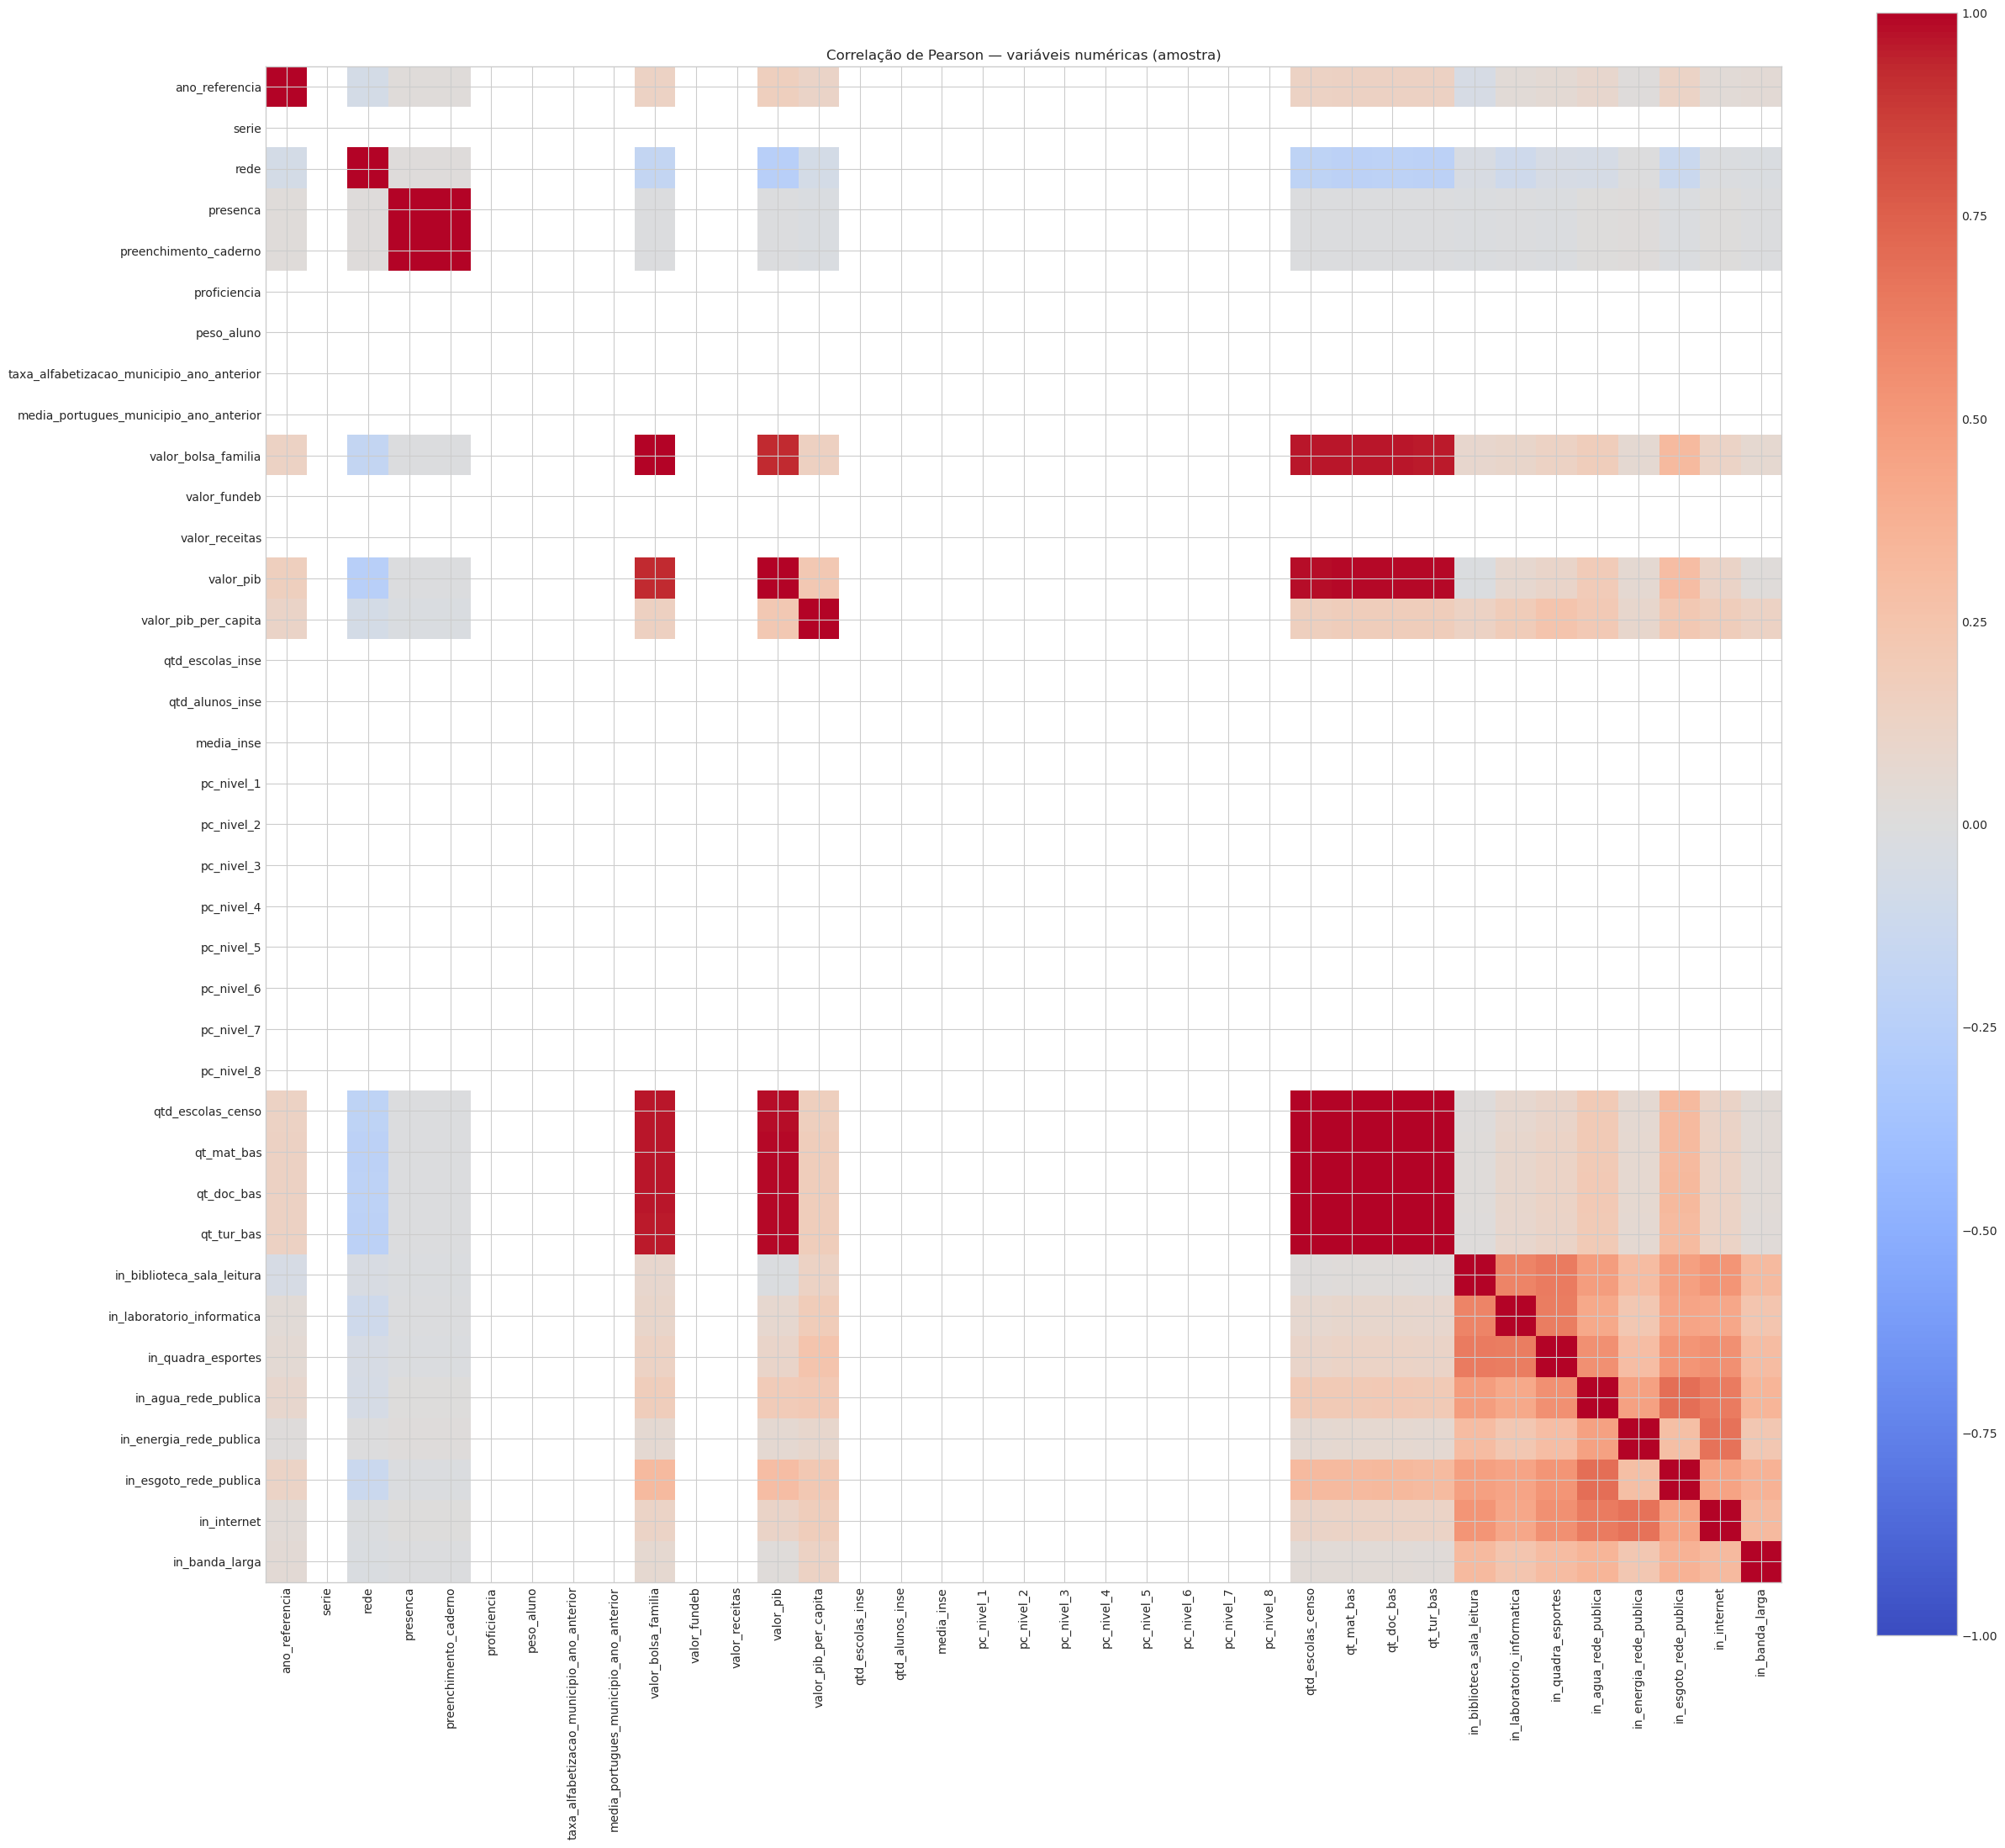

variavel_1,variavel_2,correlacao,correlacao_abs
str,str,f64,f64
"""qt_mat_bas""","""qt_tur_bas""",0.999257,0.999257
"""qt_mat_bas""","""qt_doc_bas""",0.998772,0.998772
"""presenca""","""preenchimento_caderno""",0.998607,0.998607
"""qtd_escolas_censo""","""qt_doc_bas""",0.998464,0.998464
"""qt_doc_bas""","""qt_tur_bas""",0.998451,0.998451
"""qtd_escolas_censo""","""qt_tur_bas""",0.996999,0.996999
"""qtd_escolas_censo""","""qt_mat_bas""",0.996983,0.996983
"""valor_pib""","""qt_tur_bas""",0.990369,0.990369
"""valor_pib""","""qt_mat_bas""",0.986924,0.986924


In [88]:
FRACAO_AMOSTRA=FRACOES_AMOSTRAGEM["eda_correlacao"]
excluir_da_correlacao=set(identificadores)|{COL_TARGET}; numericas_correlacao=[c for c in colunas_numericas if c not in excluir_da_correlacao]
if len(numericas_correlacao)<2: print("Não há variáveis numéricas suficientes para calcular correlações.")
else:
    limite_hash=max(1,round(FRACAO_AMOSTRA*10_000))
    df_corr=(lf.filter((pl.col("id_aluno").hash(seed=SEED_GLOBAL)%10_000)<limite_hash).select(numericas_correlacao).collect(engine="streaming"))
    print("Registros na amostra:",df_corr.height); display(df_corr.select([pl.col(c).count().alias(c) for c in numericas_correlacao]).unpivot(variable_name="variavel",value_name="valores_disponiveis").sort("valores_disponiveis"))
    matriz_corr=df_corr.corr(); nomes=matriz_corr.columns; valores=matriz_corr.to_numpy()
    plt.figure(figsize=(max(10,len(nomes)*.7),max(8,len(nomes)*.6))); plt.imshow(valores,cmap="coolwarm",vmin=-1,vmax=1); plt.colorbar(); plt.xticks(range(len(nomes)),nomes,rotation=90); plt.yticks(range(len(nomes)),nomes); plt.title("Correlação de Pearson — variáveis numéricas (amostra)"); plt.tight_layout(); salvar_figura_eda(plt.gcf(),"197_7_correlacao_entre_variaveis_numericas_01.png"); plt.show()
    pares=pl.DataFrame([{"variavel_1":nomes[a],"variavel_2":nomes[b],"correlacao":float(valores[a,b])} for a in range(len(nomes)) for b in range(a+1,len(nomes)) if np.isfinite(valores[a,b])]).with_columns(pl.col("correlacao").abs().alias("correlacao_abs")).sort("correlacao_abs",descending=True)
    display(pares.head(20))


## 8. Relação entre variáveis numéricas e o target

Quando o target é binário (0/1), a correlação ponto-bisserial equivale à correlação de Pearson entre a variável numérica e o target codificado numericamente. Aqui apresentamos a correlação como triagem exploratória, desde que os valores do target sejam realmente binários.

Correlação próxima de zero não exclui uma relação não linear. Variáveis com muitos nulos também podem apresentar resultados enviesados se a análise considerar apenas linhas completas.


Valores distintos do target: [1, 0]


variavel,correlacao_com_target,abs_correlacao
str,f64,f64
"""serie""",NaN,NaN
"""proficiencia""",0.795599,0.795599
"""preenchimento_caderno""",0.401542,0.401542
"""presenca""",0.401007,0.401007
"""media_portugues_municipio_ano_…",0.246996,0.246996
"""taxa_alfabetizacao_municipio_a…",0.235955,0.235955
"""in_laboratorio_informatica""",0.069195,0.069195
"""in_quadra_esportes""",0.059441,0.059441
"""in_biblioteca_sala_leitura""",0.057111,0.057111


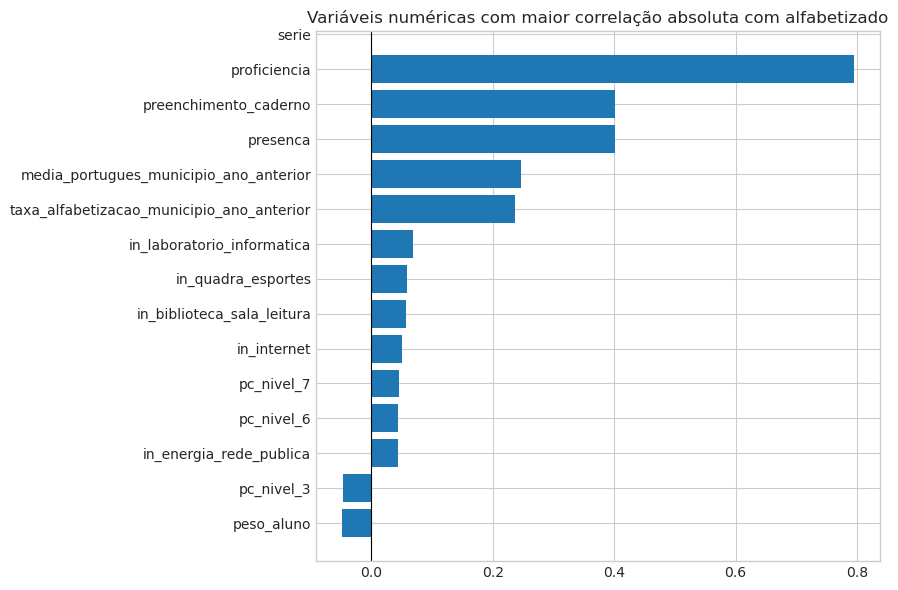

In [89]:
valores_target=lf.select(pl.col(COL_TARGET).drop_nulls().unique()).collect()[COL_TARGET].to_list(); print("Valores distintos do target:",valores_target)
if set(valores_target).issubset({0,1,0.0,1.0,True,False}) and len(valores_target)==2:
    cols_target_num=[c for c in numericas_correlacao if c in colunas]
    correlacoes=lf.select([pl.corr(pl.col(c).cast(pl.Float64),pl.col(COL_TARGET).cast(pl.Float64)).alias(c) for c in cols_target_num]).collect().row(0,named=True)
    corr_target=pl.DataFrame({"variavel":list(correlacoes),"correlacao_com_target":list(correlacoes.values())}).with_columns(pl.col("correlacao_com_target").abs().alias("abs_correlacao")).sort("abs_correlacao",descending=True)
    display(corr_target); top=corr_target.drop_nulls().head(15).sort("correlacao_com_target")
    plt.figure(figsize=(9,6)); plt.barh(top["variavel"].to_list(),top["correlacao_com_target"].to_numpy()); plt.axvline(0,color="black",linewidth=.8); plt.title("Variáveis numéricas com maior correlação absoluta com alfabetizado"); plt.tight_layout(); salvar_figura_eda(plt.gcf(),"199_8_relacao_entre_variaveis_numericas_e_o_target_01.png"); plt.show()
else: print("O target não tem exatamente dois valores binários conforme esperado.")


## 9. Comparação das variáveis numéricas por classe do target

Comparar mediana e média por classe ajuda a perceber diferenças entre alunos classificados como alfabetizados e não alfabetizados. Por ser uma base grande, a tabela agregada é preferível a um gráfico com milhões de pontos.


In [90]:
variaveis_comparacao=[nome for nome,dtype in schema.items() if dtype.is_numeric() and nome!=COL_TARGET and nome not in identificadores]
resumo_por_target=lf.group_by(COL_TARGET).agg([expr for c in variaveis_comparacao for expr in (pl.col(c).mean().alias(f"{c}_media"),pl.col(c).median().alias(f"{c}_mediana"),pl.col(c).std().alias(f"{c}_desvio_padrao"))]).sort(COL_TARGET).collect()
resumo_por_target_long=resumo_por_target.unpivot(index=COL_TARGET,variable_name="variavel_estatistica",value_name="valor").pivot(on=COL_TARGET,index="variavel_estatistica",values="valor")
display(resumo_por_target_long)


variavel_estatistica,0,1
str,f64,f64
"""ano_referencia_media""",2023.538076,2023.55787
"""ano_referencia_mediana""",2024.0,2024.0
"""ano_referencia_desvio_padrao""",0.498548,0.49664
"""serie_media""",2.0,2.0
"""serie_mediana""",2.0,2.0
"""serie_desvio_padrao""",0.0,0.0
"""rede_media""",2.891706,2.883396
"""rede_mediana""",3.0,3.0
"""rede_desvio_padrao""",0.310767,0.320973


## 10. Relações com variáveis categóricas

Para evitar gráficos ilegíveis, analisamos apenas variáveis categóricas com cardinalidade baixa. As categorias são agrupadas por target e mostramos as proporções dentro de cada categoria. Códigos de alta cardinalidade e identificadores não devem ser tratados como categorias comuns.


Categóricas de baixa cardinalidade: [('rede_descricao', 3), ('dataset_split', 3)]


rede_descricao,alfabetizado,quantidade,percentual_na_categoria
str,i32,u32,f64
"""Estadual""",0,203976,46.848171
"""Estadual""",1,231422,53.151829
"""Municipal""",0,1679468,48.927336
"""Municipal""",1,1753108,51.072664
"""Privada""",0,9,36.0
"""Privada""",1,16,64.0


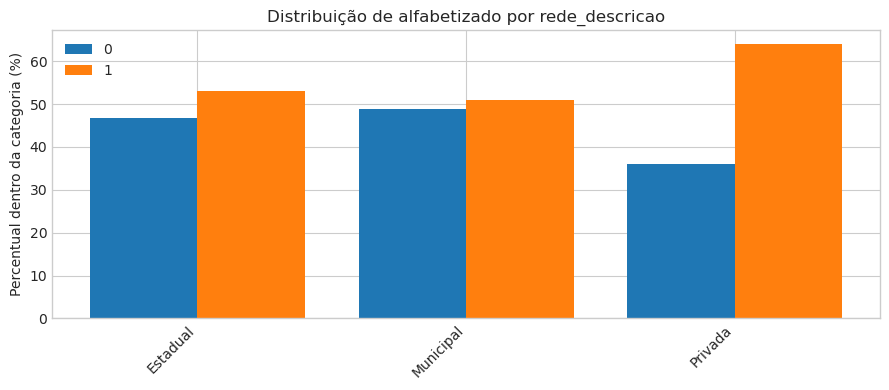

dataset_split,alfabetizado,quantidade,percentual_na_categoria
str,i32,u32,f64
"""teste""",0,282888,48.639949
"""teste""",1,298708,51.360051
"""treino""",0,1317452,48.699788
"""treino""",1,1387800,51.300212
"""validacao""",0,283113,48.71591
"""validacao""",1,298038,51.28409


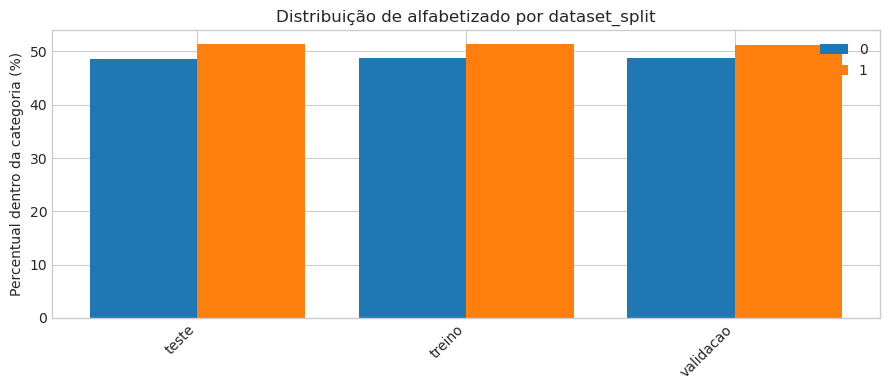

In [91]:
MAX_CATEGORIAS=12; MAX_CATEGORICAS=5; candidatas_cat=[]
for c in colunas_categoricas:
    n_cat=lf.select(pl.col(c).n_unique()).collect().item()
    if 2<=n_cat<=MAX_CATEGORIAS and c not in identificadores and c!=COL_TARGET: candidatas_cat.append((c,n_cat))
print("Categóricas de baixa cardinalidade:",candidatas_cat)
for c,n_cat in candidatas_cat[:MAX_CATEGORICAS]:
    tab=(lf.group_by([c,COL_TARGET]).agg(pl.len().alias("quantidade")).collect().with_columns((100*pl.col("quantidade")/pl.col("quantidade").sum().over(c)).alias("percentual_na_categoria")).sort([c,COL_TARGET]))
    display(tab); pivot=tab.pivot(on=COL_TARGET,index=c,values="percentual_na_categoria").fill_null(0); classes=[x for x in pivot.columns if x!=c]; x=np.arange(pivot.height); largura=.8/max(1,len(classes)); plt.figure(figsize=(9,4))
    for j,classe in enumerate(classes): plt.bar(x+j*largura,pivot[classe].to_numpy(),width=largura,label=str(classe))
    plt.xticks(x+largura*(len(classes)-1)/2,pivot[c].cast(pl.String).to_list(),rotation=45,ha="right"); plt.title(f"Distribuição de alfabetizado por {c}"); plt.ylabel("Percentual dentro da categoria (%)"); plt.legend(); plt.tight_layout(); salvar_figura_eda(plt.gcf(),"203_10_relacoes_com_variaveis_categoricas_01.png"); plt.show()


## 11. Inspeção de relações específicas

Use esta seção para investigar hipóteses levantadas nos gráficos. Por exemplo, compare indicadores socioeconômicos, infraestrutura escolar e contexto municipal. Ajuste os nomes conforme as colunas reais impressas na seção 2.

A tabela abaixo permite verificar se nomes de variáveis de interesse estão presentes sem gerar erro caso algum deles não exista.


In [92]:
variaveis_interesse = [
    "media_inse",
    "valor_pib_per_capita",
    "valor_fundeb",
    "valor_receitas",
    "taxa_alfabetizacao_municipio_ano_anterior",
    "media_portugues_municipio_ano_anterior",
    "proficiencia",
    "peso_aluno",
]
presentes = [c for c in variaveis_interesse if c in colunas]
ausentes = [c for c in variaveis_interesse if c not in colunas]

print("Variáveis de interesse presentes:", presentes)
print("Variáveis de interesse não encontradas:", ausentes)


Variáveis de interesse presentes: ['media_inse', 'valor_pib_per_capita', 'valor_fundeb', 'valor_receitas', 'taxa_alfabetizacao_municipio_ano_anterior', 'media_portugues_municipio_ano_anterior', 'proficiencia', 'peso_aluno']
Variáveis de interesse não encontradas: []


## 12. Registro dos principais achados

Preencha esta seção após executar e interpretar os resultados. Evite registrar apenas valores de correlação: descreva o padrão observado, a limitação e o que precisa ser verificado.


In [93]:
achados = pl.DataFrame([
    {
        "tema": "Distribuição do target",
        "observacao": (
            "As classes estão relativamente equilibradas: "
            "51,31% dos registros pertencem à classe 1 e 48,69% à classe 0."
        ),
        "limitacao/validacao": (
            "A classificação foi recebida pronta na base original. "
            "Sua regra de construção não foi reproduzida neste notebook."
        )
    },
    {
        "tema": "Relações entre variáveis numéricas",
        "observacao": (
            "Foram identificadas correlações elevadas entre algumas "
            "variáveis de volume e estrutura educacional, indicando "
            "possível sobreposição de informações."
        ),
        "limitacao/validacao": (
            "A correlação de Pearson identifica principalmente relações "
            "lineares e não comprova causalidade."
        )
    },
    {
        "tema": "Relações com o target",
        "observacao": (
            "As maiores correlações positivas foram observadas em "
            "proficiencia (0,795599), preenchimento_caderno (0,401542), "
            "presenca (0,401007), media_portugues_municipio_ano_anterior "
            "(0,246996) e taxa_alfabetizacao_municipio_ano_anterior (0,235955)."
        ),
        "limitacao/validacao": (
            "As associações não comprovam causalidade. A relação entre "
            "proficiencia e alfabetizado deve ser avaliada antes da "
            "modelagem para verificar possível vazamento de informação."
        )
    },
    {
        "tema": "Variáveis categóricas",
        "observacao": (
            "As proporções das classes são semelhantes nas redes estadual "
            "e municipal. Na rede privada, 64% dos registros pertencem "
            "à classe 1."
        ),
        "limitacao/validacao": (
            "A rede privada possui apenas 25 registros, quantidade "
            "insuficiente para conclusões robustas. dataset_split é "
            "uma variável de controle, não um preditor."
        )
    },
    {
        "tema": "Valores ausentes e cobertura temporal",
        "observacao": (
            "As análises anteriores identificaram valores ausentes em "
            "parte das variáveis da base."
        ),
        "limitacao/validacao": (
            "A cobertura e a disponibilidade temporal devem ser verificadas "
            "antes da seleção das variáveis para modelagem."
        )
    },
    {
        "tema": "Possível redundância entre variáveis",
        "observacao": (
            "A matriz de correlação mostrou associações elevadas entre "
            "algumas variáveis relacionadas a quantidades de escolas, "
            "alunos e estrutura educacional."
        ),
        "limitacao/validacao": (
            "É necessário avaliar a sobreposição de informações e o "
            "significado das variáveis antes de selecionar as features."
        )
    },
    {
        "tema": "Possível data leakage",
        "observacao": (
            "A elevada correlação entre proficiencia e alfabetizado "
            "merece investigação antes da construção dos modelos."
        ),
        "limitacao/validacao": (
            "A correlação, isoladamente, não comprova vazamento. "
            "É necessário avaliar a origem das variáveis e sua "
            "disponibilidade no momento da previsão."
        )
    }
])

display(achados)


tema,observacao,limitacao/validacao
str,str,str
"""Distribuição do target""","""As classes estão relativamente…","""A classificação foi recebida p…"
"""Relações entre variáveis numér…","""Foram identificadas correlaçõe…","""A correlação de Pearson identi…"
"""Relações com o target""","""As maiores correlações positiv…","""As associações não comprovam c…"
"""Variáveis categóricas""","""As proporções das classes são …","""A rede privada possui apenas 2…"
"""Valores ausentes e cobertura t…","""As análises anteriores identif…","""A cobertura e a disponibilidad…"
"""Possível redundância entre var…","""A matriz de correlação mostrou…","""É necessário avaliar a sobrepo…"
"""Possível data leakage""","""A elevada correlação entre pro…","""A correlação, isoladamente, nã…"


## 13. Conclusão

As análises exploratórias realizadas neste notebook permitiram investigar as relações entre as variáveis da base consolidada e o target `alfabetizado`, complementando as análises de distribuição e de valores ausentes realizadas anteriormente.

A análise de correlação identificou associações positivas entre `alfabetizado` e as variáveis `proficiencia`, `preenchimento_caderno`, `presenca`, `media_portugues_municipio_ano_anterior` e `taxa_alfabetizacao_municipio_ano_anterior`. Entre elas, `proficiencia` apresentou a maior correlação. Esses resultados contribuem para identificar relações que merecem investigação nas próximas etapas, mas não comprovam causalidade.

A comparação entre as classes do target também mostrou diferenças nas médias de algumas variáveis educacionais. Na análise das variáveis categóricas, as proporções das classes foram semelhantes nas redes estadual e municipal. Os resultados da rede privada devem ser interpretados com cautela, devido à pequena quantidade de registros observados.

A interpretação dos resultados deve considerar os valores ausentes, a cobertura temporal e a possível redundância entre variáveis. A relação entre `proficiencia` e `alfabetizado` também requer atenção antes da modelagem, para avaliar a origem das informações e o possível risco de *data leakage*.

Conclui-se que o TC3-46 contribui para o entendimento inicial das relações presentes na base e fornece subsídios para as próximas etapas do projeto. A seleção definitiva das variáveis para os modelos deverá considerar sua qualidade, seu significado, sua disponibilidade no momento da previsão e sua adequação aos objetivos de negócio.


## Caderno de origem: `TC3_47_Diferencas_Municipio_UF_Rede_Serie.ipynb`

> Código oficial incorporado de `notebooks/fase_3_analise_exploratória_de_dados/TC3_47_Diferencas_Municipio_UF_Rede_Serie.ipynb`.


# TC3-47 — Analisar diferenças por município, UF, rede e série

**Objetivo:** avaliar como a base e os resultados se comportam nos recortes geográficos e educacionais disponíveis, identificando diferenças entre municípios, unidades federativas (UF), redes de ensino e séries.

## Relação com os notebooks anteriores

- **TC3-43:** fornece o contexto da distribuição do target `alfabetizado` (aproximadamente 51,31% na classe 1 e 48,69% na classe 0, conforme análise anterior).
- **TC3-44 e TC3-45:** reforçam a necessidade de considerar distribuição, valores ausentes, duplicidades e possíveis valores extremos.
- **TC3-46:** identificou associação elevada entre `proficiencia` e `alfabetizado` (correlação aproximada de 0,796), além de associações moderadas com `presenca` e `preenchimento_caderno` (aproximadamente 0,402 cada). Este notebook aprofunda a exploração por grupos, sem tratar associação como causalidade.

## Escopo

1. Ler a base consolidada particionada por UF.
2. Identificar as colunas geográficas e educacionais realmente disponíveis.
3. Comparar quantidade de registros e proporção de `alfabetizado` por UF, rede e série.
4. Investigar diferenças entre municípios, incluindo tamanho da amostra e indicadores médios.
5. Explorar recortes combinados quando as colunas existirem.
6. Registrar achados, limitações e pontos que precisam de validação.

## Cuidados metodológicos

- A base contém milhões de linhas; as comparações devem ser agregadas antes de exibir ou plotar.
- Médias de municípios com poucos registros são instáveis. A tabela de municípios inclui um limite mínimo de observações ajustável.
- Diferenças descritivas não demonstram causalidade e não devem ser interpretadas automaticamente como desempenho atribuível à rede, UF ou município.
- `alfabetizado` é o target recebido pronto na base; este notebook não recalcula sua classificação.
- A associação entre `proficiencia` e `alfabetizado` observada no TC3-46 merece atenção antes da modelagem, mas não comprova, por si só, *data leakage*.


## 1. Preparação do ambiente

O notebook utiliza Polars para consultar os arquivos Parquet de forma eficiente e Polars/matplotlib/seaborn para tabelas e gráficos.


In [94]:
from pathlib import Path
import warnings

import polars as pl
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")

print("Polars:", pl.__version__)


Polars: 2.0.0


## 2. Localização e leitura dos arquivos

A estrutura esperada é `dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=SP/*.parquet`. O código procura a raiz do projeto a partir do diretório atual e dos diretórios pais.


In [95]:
# Usa o diretório processado ativo, persistente ou temporário.
BASE_PATH = DADOS_PROCESSADOS_DIR / "consolidado" / "base_alunos_municipios_por_uf"

arquivos_parquet = sorted(BASE_PATH.glob("sigla_uf=*/*.parquet"))

print("Raiz do projeto:", PROJECT_ROOT)
print("Pasta da base:", BASE_PATH)
print("Quantidade de arquivos Parquet:", len(arquivos_parquet))
print("Exemplos:", [str(p.relative_to(PROJECT_ROOT)) for p in arquivos_parquet[:5]])

if not arquivos_parquet:
    raise FileNotFoundError(f"Nenhum Parquet encontrado em {BASE_PATH}")

lf = pl.scan_parquet(
    [str(p) for p in arquivos_parquet],
    hive_partitioning=True
)

schema = lf.collect_schema()
colunas = schema.names()

print("Quantidade de colunas:", len(colunas))
print("Colunas disponíveis:")
print(colunas)

Raiz do projeto: /workspace
Pasta da base: /workspace/dados/dados_processados/consolidado/base_alunos_municipios_por_uf
Quantidade de arquivos Parquet: 26
Exemplos: ['dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=AC/part-00000.parquet', 'dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=AL/part-00001.parquet', 'dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=AM/part-00002.parquet', 'dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=AP/part-00003.parquet', 'dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=BA/part-00004.parquet']
Quantidade de colunas: 49
Colunas disponíveis:
['id_aluno', 'id_escola', 'id_municipio', 'nome_municipio', 'sigla_uf', 'ano_referencia', 'serie', 'rede', 'rede_descricao', 'caderno', 'presenca', 'preenchimento_caderno', 'proficiencia', 'peso_aluno', 'taxa_alfabetizacao_municipio_ano_anterior', 'media_portugues_municipio_ano_anterior

## 3. Definição das dimensões e indicadores

As colunas são identificadas de forma flexível para evitar assumir nomes que podem variar entre versões da base. A célula mostra quais campos serão utilizados em cada análise.


In [96]:
def primeira_coluna(candidatas, disponiveis):
    return next((c for c in candidatas if c in disponiveis), None)

COL_UF = primeira_coluna(
    ["sigla_uf", "uf", "nome_uf"], colunas
)
COL_MUNICIPIO = primeira_coluna(
    ["nome_municipio", "nome_do_municipio", "municipio", "id_municipio",
     "codigo_municipio", "cod_municipio", "id_municipio_ibge"], colunas
)
COL_REDE = primeira_coluna(["rede", "tipo_rede", "dependencia_administrativa"], colunas)
COL_SERIE = primeira_coluna(["serie", "ano_escolar", "etapa", "etapa_ensino"], colunas)
COL_ANO = primeira_coluna(["ano_referencia", "ano", "ano_base"], colunas)
COL_TARGET = "alfabetizado" if "alfabetizado" in colunas else None
COL_PROFICIENCIA = "proficiencia" if "proficiencia" in colunas else None
COL_PRESENCA = "presenca" if "presenca" in colunas else None
COL_PREENCHIMENTO = "preenchimento_caderno" if "preenchimento_caderno" in colunas else None

dimensoes = {
    "UF": COL_UF,
    "Município": COL_MUNICIPIO,
    "Rede": COL_REDE,
    "Série": COL_SERIE,
    "Ano de referência": COL_ANO,
}
indicadores = {
    "alfabetizado": COL_TARGET,
    "proficiencia": COL_PROFICIENCIA,
    "presenca": COL_PRESENCA,
    "preenchimento_caderno": COL_PREENCHIMENTO,
}

display(pl.DataFrame([
    {"grupo": grupo, "coluna_detectada": coluna, "disponivel": coluna is not None}
    for grupo, coluna in [*dimensoes.items(), *indicadores.items()]
]))

if COL_TARGET is None:
    print("Atenção: a coluna 'alfabetizado' não foi encontrada; análises de proporção do target serão ignoradas.")


grupo,coluna_detectada,disponivel
str,str,bool
"""UF""","""sigla_uf""",true
"""Município""","""nome_municipio""",true
"""Rede""","""rede""",true
"""Série""","""serie""",true
"""Ano de referência""","""ano_referencia""",true
"""alfabetizado""","""alfabetizado""",true
"""proficiencia""","""proficiencia""",true
"""presenca""","""presenca""",true
"""preenchimento_caderno""","""preenchimento_caderno""",true


## 4. Visão geral da base

Esta consulta calcula a quantidade de registros e, quando disponível, a distribuição geral do target. O valor é comparado com o contexto observado no TC3-43, mas pode variar conforme a versão e a cobertura da base.


In [97]:
resumo_geral=lf.select(pl.len().alias("quantidade_registros"),pl.lit(len(colunas)).alias("quantidade_colunas")).collect(); display(resumo_geral)
if COL_TARGET:
    dist_target=lf.group_by(COL_TARGET).agg(pl.len().alias("quantidade")).sort(COL_TARGET).collect().with_columns((100*pl.col("quantidade")/pl.col("quantidade").sum()).alias("percentual")); display(dist_target)


quantidade_registros,quantidade_colunas
u32,i32
3867999,49


alfabetizado,quantidade,percentual
i32,u32,f64
0,1883453,48.693213
1,1984546,51.306787


## 5. Comparação por UF

Para cada UF, a tabela apresenta o volume de registros e, se as colunas existirem, a proporção média de `alfabetizado`, a proficiência média, a presença e o preenchimento de caderno. A média do target binário é interpretada como proporção da classe 1.


In [98]:
def construir_agregacao(grupos):
    exprs = [pl.len().alias("quantidade_registros")]
    if COL_TARGET:
        exprs.append(pl.col(COL_TARGET).cast(pl.Float64, strict=False).mean().alias("proporcao_alfabetizado"))
    if COL_PROFICIENCIA:
        exprs.append(pl.col(COL_PROFICIENCIA).cast(pl.Float64, strict=False).mean().alias("proficiencia_media"))
        exprs.append(pl.col(COL_PROFICIENCIA).cast(pl.Float64, strict=False).median().alias("proficiencia_mediana"))
    if COL_PRESENCA:
        exprs.append(pl.col(COL_PRESENCA).cast(pl.Float64, strict=False).mean().alias("presenca_media"))
    if COL_PREENCHIMENTO:
        exprs.append(pl.col(COL_PREENCHIMENTO).cast(pl.Float64, strict=False).mean().alias("preenchimento_caderno_medio"))
    return exprs

def analisar_grupo(coluna, rotulo):
    if coluna is None:
        print(f"Análise por {rotulo} não executada: coluna não encontrada.")
        return None
    resultado = (
        lf.group_by(coluna)
          .agg(construir_agregacao([coluna]))
          .sort("quantidade_registros", descending=True)
          .collect()
          
    )
    print(f"Quantidade de categorias em {rotulo}: {len(resultado)}")
    display(resultado.head(50))
    return resultado

resumo_uf = analisar_grupo(COL_UF, "UF")


Quantidade de categorias em UF: 26


sigla_uf,quantidade_registros,proporcao_alfabetizado,proficiencia_media,proficiencia_mediana,presenca_media,preenchimento_caderno_medio
str,u32,f64,f64,f64,f64,f64
"""SP""",443777,0.521843,750.424067,754.248605,0.891173,0.891087
"""MG""",413557,0.594436,755.819952,761.6222,0.892276,0.892276
"""RJ""",311198,0.448547,738.949401,746.68,0.821361,0.821361
"""PR""",277446,0.622608,756.416088,761.33939,0.862117,0.862117
"""BA""",253300,0.319424,725.530427,729.625944,0.870434,0.870434
"""RS""",229410,0.456924,742.39021,749.081928,0.821093,0.820461
"""PA""",204949,0.401056,733.802618,742.19,0.818496,0.818496
"""SC""",201171,0.4697,749.853897,754.225515,0.744098,0.744098
"""CE""",190190,0.8211,796.747941,804.606515,0.965913,0.965913


In [99]:
print(lf.select("sigla_uf").unique().sort("sigla_uf").collect())


shape: (26, 1)
┌──────────┐
│ sigla_uf │
│ ---      │
│ str      │
╞══════════╡
│ AC       │
│ AL       │
│ AM       │
│ AP       │
│ BA       │
│ CE       │
│ DF       │
│ ES       │
│ GO       │
│ MA       │
│ MG       │
│ MS       │
│ MT       │
│ PA       │
│ PB       │
│ PE       │
│ PI       │
│ PR       │
│ RJ       │
│ RN       │
│ RO       │
│ RS       │
│ SC       │
│ SE       │
│ SP       │
│ TO       │
└──────────┘


## 6. Comparação por rede de ensino

A comparação por rede considera o tamanho de cada grupo. Diferenças na proporção de alfabetização ou na proficiência média são descritivas e podem refletir diferenças de composição, contexto socioeconômico, cobertura ou participação.


rede_descricao,quantidade_registros,proporcao_alfabetizado,proficiencia_media,proficiencia_mediana,presenca_media,preenchimento_caderno_medio
str,u32,f64,f64,f64,f64,f64
"""Municipal""",3432576,0.510727,748.02831,752.772355,0.869062,0.868747
"""Estadual""",435398,0.531518,751.192875,756.030362,0.855996,0.85576
"""Privada""",25,0.64,756.635,749.795,0.96,0.96


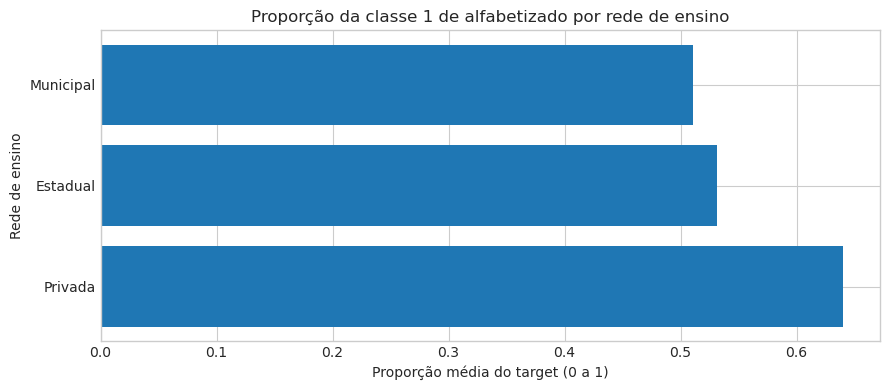

In [100]:
# Agregar os indicadores por código da rede, sem exibir a tabela ainda
resumo_rede = (
    lf.group_by(COL_REDE)
      .agg(construir_agregacao([COL_REDE]))
      .sort("quantidade_registros", descending=True)
      .collect()
      
)

# Obter a descrição correspondente a cada código
mapa_redes = (
    lf.select("rede", "rede_descricao")
      .unique()
      .collect()
      
)

# Associar os nomes das redes aos resultados
resumo_rede = resumo_rede.join(
    mapa_redes,
    on="rede",
    how="left"
)

# Exibir somente a tabela com os nomes das redes
colunas_exibicao = [
    "rede_descricao",
    "quantidade_registros",
    "proporcao_alfabetizado",
    "proficiencia_media",
    "proficiencia_mediana",
    "presenca_media",
    "preenchimento_caderno_medio",
]

display(resumo_rede.select([c for c in colunas_exibicao if c in resumo_rede.columns]))

# Gerar o gráfico com os nomes das redes
grafico = resumo_rede.drop_nulls("proporcao_alfabetizado").sort("proporcao_alfabetizado", descending=True)

plt.figure(figsize=(9, 4))
plt.barh(grafico["rede_descricao"].to_list(), grafico["proporcao_alfabetizado"].to_numpy())
plt.title("Proporção da classe 1 de alfabetizado por rede de ensino")
plt.xlabel("Proporção média do target (0 a 1)")
plt.ylabel("Rede de ensino")
plt.tight_layout()
salvar_figura_eda(plt.gcf(), "223_6_comparacao_por_rede_de_ensino_01.png"); plt.show()


## 7. Validação do recorte por série

A base consolidada utilizada neste projeto contém registros referentes exclusivamente à série 2, conforme verificado na coluna `serie`.

Como o objetivo do estudo é analisar o índice de alfabetização dos alunos da segunda série, não é necessário realizar uma comparação entre séries. A análise será direcionada às diferenças entre municípios, unidades federativas (UF) e redes de ensino, mantendo a série 2 como recorte fixo.

Essa validação garante que as análises seguintes estejam alinhadas ao escopo do projeto.


In [101]:
# Validar quais séries estão presentes na base
series_disponiveis = (
    lf.select(COL_SERIE)
      .drop_nulls()
      .unique()
      .sort(COL_SERIE)
      .collect()
)

display(series_disponiveis)

valores_serie = series_disponiveis[COL_SERIE].to_list()

if valores_serie == [2]:
    print("Validação concluída: todos os registros pertencem à série 2.")
else:
    print(
        "Atenção: foram encontrados valores diferentes de 2 "
        "ou mais de uma série na base:",
        valores_serie
    )


serie
i32
2


Validação concluída: todos os registros pertencem à série 2.


## 8. Diferenças entre municípios

A análise municipal usa um limite mínimo de registros para reduzir a instabilidade de grupos muito pequenos. O limite pode ser ajustado conforme o volume observado. A tabela completa de municípios fica disponível para inspeção, e as visualizações mostram apenas os municípios com amostra suficiente.


In [102]:
MIN_REGISTROS_MUNICIPIO = 30

if COL_MUNICIPIO is None:
    print("Análise municipal não executada: não foi encontrada uma coluna identificadora de município.")
else:
    grupos_municipio = [c for c in [COL_UF, COL_MUNICIPIO] if c is not None]
    resumo_municipio = (
        lf.group_by(grupos_municipio)
          .agg(construir_agregacao(grupos_municipio))
          .sort("quantidade_registros", descending=True)
          .collect()
    )
    print("Municípios/grupos encontrados:", resumo_municipio.height)
    display(resumo_municipio.head(30))
    municipios_validos = resumo_municipio.filter(pl.col("quantidade_registros") >= MIN_REGISTROS_MUNICIPIO)
    print(f"Grupos com pelo menos {MIN_REGISTROS_MUNICIPIO} registros:", municipios_validos.height)
    if COL_TARGET and "proporcao_alfabetizado" in municipios_validos.columns and not municipios_validos.is_empty():
        print("Menores proporções de alfabetizado entre grupos com amostra mínima:")
        display(municipios_validos.sort("proporcao_alfabetizado").head(15))
        print("Maiores proporções de alfabetizado entre grupos com amostra mínima:")
        display(municipios_validos.sort("proporcao_alfabetizado", descending=True).head(15))


Municípios/grupos encontrados: 5548


sigla_uf,nome_municipio,quantidade_registros,proporcao_alfabetizado,proficiencia_media,proficiencia_mediana,presenca_media,preenchimento_caderno_medio
str,str,u32,f64,f64,f64,f64,f64
"""SP""","""São Paulo""",107729,0.495763,748.632258,751.676226,0.876134,0.876022
"""RJ""","""Rio de Janeiro""",104495,0.514206,744.968275,752.2804,0.84472,0.84472
"""AM""","""Manaus""",63620,0.396416,737.510802,745.98,0.740616,0.740616
"""MG""","""Belo Horizonte""",39996,0.558031,754.208657,759.88,0.85151,0.85151
"""CE""","""Fortaleza""",38262,0.714233,774.20998,784.31,0.958105,0.958105
"""PR""","""Curitiba""",31889,0.550284,751.886689,758.682847,0.804133,0.804133
"""BA""","""Salvador""",29932,0.330115,726.727152,730.997145,0.858746,0.858746
"""DF""","""Brasília""",27698,0.474402,743.306689,750.2,0.798289,0.798289
"""MS""","""Campo Grande""",22422,0.40661,732.682204,738.815,0.871644,0.866203


Grupos com pelo menos 30 registros: 5445
Menores proporções de alfabetizado entre grupos com amostra mínima:


sigla_uf,nome_municipio,quantidade_registros,proporcao_alfabetizado,proficiencia_media,proficiencia_mediana,presenca_media,preenchimento_caderno_medio
str,str,u32,f64,f64,f64,f64,f64
"""GO""","""Santa Helena de Goiás""",410,0.0,null,null,0.0,0.0
"""BA""","""Macururé""",89,0.078652,684.199698,682.84,0.932584,0.932584
"""RN""","""Paraú""",43,0.093023,707.696348,713.5288,0.674419,0.674419
"""TO""","""Filadélfia""",156,0.108974,693.483857,690.64,0.884615,0.884615
"""AC""","""Santa Rosa do Purus""",76,0.118421,702.652759,716.46,0.763158,0.763158
"""RN""","""Poço Branco""",207,0.120773,701.941334,698.685,0.753623,0.753623
"""BA""","""Arataca""",172,0.122093,707.40482,711.95,0.773256,0.773256
"""MG""","""São João das Missões""",449,0.122494,727.812758,726.9,0.305122,0.305122
"""SE""","""Pedrinhas""",119,0.12605,694.201638,697.415,0.97479,0.97479


Maiores proporções de alfabetizado entre grupos com amostra mínima:


sigla_uf,nome_municipio,quantidade_registros,proporcao_alfabetizado,proficiencia_media,proficiencia_mediana,presenca_media,preenchimento_caderno_medio
str,str,u32,f64,f64,f64,f64,f64
"""CE""","""Coreaú""",510,1.0,868.104181,871.837387,1.0,1.0
"""PI""","""Caldeirão Grande do Piauí""",60,1.0,826.485582,838.136397,1.0,1.0
"""PI""","""Vila Nova do Piauí""",45,1.0,810.509448,810.57,1.0,1.0
"""CE""","""Nova Olinda""",430,0.997674,853.682992,857.073662,1.0,1.0
"""CE""","""Piquet Carneiro""",331,0.996979,831.791212,830.99,0.996979,0.996979
"""CE""","""Pedra Branca""",694,0.991354,836.78676,838.011549,0.995677,0.995677
"""CE""","""Milhã""",303,0.990099,819.078001,821.656476,1.0,1.0
"""CE""","""Pacujá""",163,0.98773,831.661991,831.277543,1.0,1.0
"""CE""","""Itatira""",483,0.987578,832.117302,831.232694,0.993789,0.993789


In [103]:
display(
    resumo_municipio.filter(
        (pl.col("quantidade_registros") >= MIN_REGISTROS_MUNICIPIO)
        & pl.col("proficiencia_media").is_not_null()
    ).sort("proporcao_alfabetizado").select(["sigla_uf", "nome_municipio", "quantidade_registros", "proporcao_alfabetizado", "proficiencia_media"]).head(10)
)


sigla_uf,nome_municipio,quantidade_registros,proporcao_alfabetizado,proficiencia_media
str,str,u32,f64,f64
"""BA""","""Macururé""",89,0.078652,684.199698
"""RN""","""Paraú""",43,0.093023,707.696348
"""TO""","""Filadélfia""",156,0.108974,693.483857
"""AC""","""Santa Rosa do Purus""",76,0.118421,702.652759
"""RN""","""Poço Branco""",207,0.120773,701.941334
"""BA""","""Arataca""",172,0.122093,707.40482
"""MG""","""São João das Missões""",449,0.122494,727.812758
"""SE""","""Pedrinhas""",119,0.12605,694.201638
"""BA""","""Buritirama""",317,0.126183,701.39563


In [104]:
(
    lf.filter(
        (pl.col("sigla_uf") == "GO") &
        (pl.col("nome_municipio") == "Santa Helena de Goiás")
    )
    .group_by("alfabetizado")
    .agg([
        pl.len().alias("quantidade_registros"),
        pl.col("proficiencia").is_null().sum().alias("proficiencia_nula"),
        pl.col("presenca").mean().alias("presenca_media"),
        pl.col("preenchimento_caderno").mean().alias("preenchimento_caderno_medio"),
    ])
    .sort("alfabetizado")
    .collect()
)


alfabetizado,quantidade_registros,proficiencia_nula,presenca_media,preenchimento_caderno_medio
i32,u32,u32,f64,f64
0,410,410,0.0,0.0


In [105]:
municipios_sem_proficiencia = resumo_municipio.filter(pl.col("proficiencia_media").is_null())
print("Quantidade de grupos municipais sem proficiência média:", municipios_sem_proficiencia.height)
display(municipios_sem_proficiencia.select([
    "sigla_uf", "nome_municipio", "quantidade_registros", "proporcao_alfabetizado",
    "proficiencia_media", "presenca_media", "preenchimento_caderno_medio",
]).head(20))


Quantidade de grupos municipais sem proficiência média: 1


sigla_uf,nome_municipio,quantidade_registros,proporcao_alfabetizado,proficiencia_media,presenca_media,preenchimento_caderno_medio
str,str,u32,f64,f64,f64,f64
"""GO""","""Santa Helena de Goiás""",410,0.0,null,0.0,0.0


In [106]:
display(
    resumo_municipio.filter(
        (pl.col("proporcao_alfabetizado") == 0) & pl.col("proficiencia_media").is_not_null()
    ).select([
        "sigla_uf", "nome_municipio", "quantidade_registros", "proporcao_alfabetizado",
        "proficiencia_media", "presenca_media", "preenchimento_caderno_medio",
    ]).head(20)
)


sigla_uf,nome_municipio,quantidade_registros,proporcao_alfabetizado,proficiencia_media,presenca_media,preenchimento_caderno_medio
str,str,u32,f64,f64,f64,f64


In [107]:
display(
    resumo_municipio.filter(pl.col("quantidade_registros") >= MIN_REGISTROS_MUNICIPIO)
    .sort("proporcao_alfabetizado").select(["sigla_uf", "nome_municipio", "quantidade_registros", "proporcao_alfabetizado", "proficiencia_media"]).head(10)
)


sigla_uf,nome_municipio,quantidade_registros,proporcao_alfabetizado,proficiencia_media
str,str,u32,f64,f64
"""GO""","""Santa Helena de Goiás""",410,0.0,null
"""BA""","""Macururé""",89,0.078652,684.199698
"""RN""","""Paraú""",43,0.093023,707.696348
"""TO""","""Filadélfia""",156,0.108974,693.483857
"""AC""","""Santa Rosa do Purus""",76,0.118421,702.652759
"""RN""","""Poço Branco""",207,0.120773,701.941334
"""BA""","""Arataca""",172,0.122093,707.40482
"""MG""","""São João das Missões""",449,0.122494,727.812758
"""SE""","""Pedrinhas""",119,0.12605,694.201638


In [108]:
display(
    resumo_municipio.filter(
        (pl.col("quantidade_registros") >= MIN_REGISTROS_MUNICIPIO)
        & pl.col("proficiencia_media").is_not_null()
    ).sort("proporcao_alfabetizado", descending=True).select(["sigla_uf", "nome_municipio", "quantidade_registros", "proporcao_alfabetizado", "proficiencia_media"]).head(10)
)


sigla_uf,nome_municipio,quantidade_registros,proporcao_alfabetizado,proficiencia_media
str,str,u32,f64,f64
"""CE""","""Coreaú""",510,1.0,868.104181
"""PI""","""Caldeirão Grande do Piauí""",60,1.0,826.485582
"""PI""","""Vila Nova do Piauí""",45,1.0,810.509448
"""CE""","""Nova Olinda""",430,0.997674,853.682992
"""CE""","""Piquet Carneiro""",331,0.996979,831.791212
"""CE""","""Pedra Branca""",694,0.991354,836.78676
"""CE""","""Milhã""",303,0.990099,819.078001
"""CE""","""Pacujá""",163,0.98773,831.661991
"""CE""","""Itatira""",483,0.987578,832.117302


In [109]:
print(lf.select("alfabetizado").unique().sort("alfabetizado").collect())


shape: (2, 1)
┌──────────────┐
│ alfabetizado │
│ ---          │
│ i32          │
╞══════════════╡
│ 0            │
│ 1            │
└──────────────┘


In [110]:
municipios_validos = resumo_municipio.filter(
    (pl.col("quantidade_registros") >= MIN_REGISTROS_MUNICIPIO)
    & pl.col("proficiencia_media").is_not_null()
)
print("Grupos municipais válidos para comparação:", municipios_validos.height)
print("Menor proporção observada:", round(municipios_validos["proporcao_alfabetizado"].min() * 100, 2), "%")
print("Maior proporção observada:", round(municipios_validos["proporcao_alfabetizado"].max() * 100, 2), "%")
print("Mediana das proporções municipais:", round(municipios_validos["proporcao_alfabetizado"].median() * 100, 2), "%")


Grupos municipais válidos para comparação: 5444
Menor proporção observada: 7.87 %
Maior proporção observada: 100.0 %
Mediana das proporções municipais: 56.55 %


## 9. Recorte combinado: UF, rede e série

O recorte combinado ajuda a observar se as diferenças encontradas em análises isoladas persistem quando cruzamos as dimensões. Para evitar combinações excessivamente detalhadas, exibimos os grupos com maior volume de registros.


In [111]:
grupos_combinados = [c for c in [COL_UF, COL_REDE, COL_SERIE] if c is not None]

if len(grupos_combinados) < 2:
    print("Recorte combinado não executado: são necessárias pelo menos duas dimensões disponíveis.")
else:
    resumo_combinado = (
        lf.group_by(grupos_combinados)
          .agg(construir_agregacao(grupos_combinados))
          .sort("quantidade_registros", descending=True)
          .collect()
          
    )
    print("Quantidade de combinações observadas:", len(resumo_combinado))
    display(resumo_combinado.head(50))


Quantidade de combinações observadas: 51


sigla_uf,rede,serie,quantidade_registros,proporcao_alfabetizado,proficiencia_media,proficiencia_mediana,presenca_media,preenchimento_caderno_medio
str,i32,i32,u32,f64,f64,f64,f64,f64
"""SP""",3,2,337804,0.496356,747.320418,750.942142,0.884939,0.884844
"""MG""",3,2,325723,0.583444,754.68619,760.48,0.887782,0.887782
"""RJ""",3,2,310978,0.448527,738.940132,746.665751,0.821508,0.821508
"""PR""",3,2,277041,0.622673,756.413252,761.335787,0.862194,0.862194
"""BA""",3,2,252748,0.319397,725.523223,729.62,0.870523,0.870523
"""PA""",3,2,190869,0.393113,733.180144,741.633267,0.813658,0.813658
"""CE""",3,2,189172,0.821702,796.794454,804.62708,0.966242,0.966242
"""PE""",3,2,168300,0.559525,747.625482,756.982562,0.932799,0.931664
"""GO""",3,2,160718,0.624585,755.835996,762.506104,0.894418,0.892837


## 10. Recorte por ano de referência, quando disponível

O ano é apresentado como dimensão categórica. Este recorte é uma comparação descritiva por período; a investigação temporal aprofundada será tratada no TC3-48. Mudanças na quantidade de registros entre anos não significam, por si só, erros ou duplicidades: podem refletir coortes, ingresso, saída ou mudanças de cobertura.


In [112]:
resumo_ano = analisar_grupo(COL_ANO, "ano de referência")


Quantidade de categorias em ano de referência: 2


ano_referencia,quantidade_registros,proporcao_alfabetizado,proficiencia_media,proficiencia_mediana,presenca_media,preenchimento_caderno_medio
i64,u32,f64,f64,f64,f64,f64
2024,2120560,0.522088,749.042072,753.95,0.873726,0.873284
2023,1747439,0.502122,747.563828,752.147831,0.860149,0.860007


## 11. Síntese automática dos resultados

A síntese abaixo registra os principais grupos observados e as limitações que devem acompanhar a interpretação. Os resultados devem ser revisados após a execução completa do notebook.


In [113]:
achados = [
    {
        "tema": "Distribuição geral do target",
        "observacao": (
            "A base apresenta aproximadamente 51,31% dos registros "
            "na classe 1 e 48,69% na classe 0."
        ),
        "limitacao": (
            "A variável alfabetizado foi utilizada conforme recebida "
            "na base, sem recalcular a classificação."
        )
    },
    {
        "tema": "Diferenças entre redes de ensino",
        "observacao": (
            "A proporção da classe 1 foi de 51,07% na rede municipal, "
            "53,15% na estadual e 64,00% na privada."
        ),
        "limitacao": (
            "A rede privada possui apenas 25 registros, quantidade "
            "insuficiente para uma comparação robusta."
        )
    },
    {
        "tema": "Diferenças entre municípios",
        "observacao": (
            "Foram identificados 5.444 grupos municipais com pelo menos "
            "30 registros e proficiência média disponível. As proporções "
            "variaram de 7,87% a 100%, com mediana de 56,55%."
        ),
        "limitacao": (
            "As proporções são descritivas e dependem da composição e "
            "da cobertura dos registros de cada município."
        )
    },
    {
        "tema": "Registros sem proficiência",
        "observacao": (
            "Santa Helena de Goiás apresentou 410 registros com "
            "alfabetizado igual a 0, proficiência ausente, presença "
            "igual a 0 e preenchimento do caderno igual a 0."
        ),
        "limitacao": (
            "Não é possível concluir que esses registros representem "
            "alunos não alfabetizados sem investigar a origem dos dados."
        )
    },
    {
        "tema": "Relação com o TC3-46",
        "observacao": (
            "O TC3-46 identificou correlação de aproximadamente 0,796 "
            "entre proficiencia e alfabetizado."
        ),
        "limitacao": (
            "A correlação não comprova causalidade nem data leakage. "
            "A origem e a disponibilidade temporal das variáveis "
            "devem ser verificadas antes da modelagem."
        )
    }
]

display(pl.DataFrame(achados))


tema,observacao,limitacao
str,str,str
"""Distribuição geral do target""","""A base apresenta aproximadamen…","""A variável alfabetizado foi ut…"
"""Diferenças entre redes de ensi…","""A proporção da classe 1 foi de…","""A rede privada possui apenas 2…"
"""Diferenças entre municípios""","""Foram identificados 5.444 grup…","""As proporções são descritivas …"
"""Registros sem proficiência""","""Santa Helena de Goiás apresent…","""Não é possível concluir que es…"
"""Relação com o TC3-46""","""O TC3-46 identificou correlaçã…","""A correlação não comprova caus…"


## 12. Conclusão

A análise exploratória do TC3-47 permitiu investigar diferenças na proporção de registros classificados como alfabetizados entre unidades federativas, redes de ensino e municípios, considerando a base disponível e o recorte da segunda série.

Na comparação entre redes de ensino, a proporção da classe 1 foi de 51,07% na rede municipal, 53,15% na estadual e 64,00% na privada. Entretanto, a rede privada possui apenas 25 registros, o que limita a confiabilidade dessa comparação.

Na análise municipal, foram identificados 5.444 grupos com pelo menos 30 registros e proficiência média disponível. As proporções observadas variaram de 7,87% a 100%, com mediana de 56,55%. Essa amplitude evidencia diferenças descritivas entre os grupos analisados, mas não permite atribuir suas causas ao município ou a outras características sem investigações adicionais.

Também foi identificado um grupo municipal com 410 registros sem proficiência disponível, presença igual a zero e preenchimento do caderno igual a zero. Esse caso requer investigação da origem dos dados antes de qualquer interpretação sobre alfabetização.

Os resultados devem ser interpretados considerando a cobertura dos dados, a quantidade de registros válidos por grupo e as limitações dos indicadores utilizados. A variável `alfabetizado` foi utilizada conforme recebida na base, sem recalcular sua classificação. Além disso, a relação entre `proficiencia` e `alfabetizado`, observada no TC3-46, deve ser investigada antes da modelagem para avaliar a disponibilidade temporal das informações e o possível risco de *data leakage*.

Conclui-se que o TC3-47 contribui para o entendimento das diferenças observadas na base e fornece subsídios para as próximas etapas do projeto. As comparações realizadas são descritivas e não devem ser interpretadas como comprovação de causalidade nem como reprodução automática do índice oficial de alfabetização.


## Caderno de origem: `TC3-48_Analise_Relacoes_Temporais.ipynb`

> Código oficial incorporado de `notebooks/fase_3_analise_exploratória_de_dados/TC3-48_Analise_Relacoes_Temporais.ipynb`.


# TC3-48 — Analisar relações temporais

**Objetivo:** avaliar diferenças e padrões entre os anos disponíveis na base consolidada, considerando o recorte do estudo: alunos da série 2 e o target `alfabetizado`.

## Relação com os notebooks anteriores

- **TC3-43:** forneceu o contexto da distribuição do target `alfabetizado`.
- **TC3-44 e TC3-45:** reforçaram a necessidade de considerar distribuição, valores ausentes e cobertura dos dados.
- **TC3-46:** investigou associações entre variáveis, incluindo a correlação elevada entre `proficiencia` e `alfabetizado`.
- **TC3-47:** comparou os resultados por município, UF e rede de ensino.

## Cuidados metodológicos

- O target `alfabetizado` será utilizado conforme recebido na base, sem recalcular sua classificação.
- A análise será restrita à série 2 quando a coluna de série estiver disponível.
- A média do target binário pode ser interpretada como proporção da classe 1.
- Diferenças entre anos são descritivas e não comprovam causalidade.
- É necessário verificar se os anos são comparáveis quanto à cobertura, à definição das variáveis e à composição dos registros.
- `id_aluno` não será utilizado para vinculação longitudinal individual: a estabilidade desse identificador entre anos não está validada para esta análise, e a documentação do Inep descreve a reestruturação dos microdados para reduzir riscos de identificação.
- As comparações temporais serão feitas por grupos agregados (por exemplo, município/ano, UF/ano e rede/ano), sem interpretar diferenças como acompanhamento dos mesmos estudantes.
- Se houver apenas dois anos, os resultados permitem comparar os períodos observados, mas não estabelecer uma tendência de longo prazo.


## 1. Preparação do ambiente

Utilizaremos Polars para consultar os arquivos Parquet e Polars/matplotlib/seaborn para apresentar tabelas e gráficos.


In [114]:
from pathlib import Path
import warnings

import polars as pl
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")

print("Polars:", pl.__version__)


Polars: 2.0.0


## 2. Localização e leitura dos arquivos

O código procura a pasta da base a partir do diretório atual e de seus diretórios pais. Se a estrutura local for diferente, ajuste `BASE_PATH` para apontar para a pasta `base_alunos_municipios_por_uf`.


In [115]:
NOME_PASTA_BASE = "base_alunos_municipios_por_uf"
BASE_PATH = DADOS_PROCESSADOS_DIR / "consolidado" / NOME_PASTA_BASE
if not BASE_PATH.exists():
    raise FileNotFoundError(
        f"Base consolidada ausente em {BASE_PATH}. Execute as etapas anteriores do notebook."
    )

arquivos_parquet = sorted(BASE_PATH.glob("sigla_uf=*/*.parquet"))

if not arquivos_parquet:
    raise FileNotFoundError(f"Nenhum arquivo Parquet encontrado em {BASE_PATH}")

lf = pl.scan_parquet([str(p) for p in arquivos_parquet], hive_partitioning=True)
schema = lf.collect_schema()
colunas = schema.names()

print("Pasta da base:", BASE_PATH)
print("Quantidade de arquivos Parquet:", len(arquivos_parquet))
print("Quantidade de colunas:", len(colunas))
print("Quantidade de registros:", lf.select(pl.len()).collect().item())


Pasta da base: /workspace/dados/dados_processados/consolidado/base_alunos_municipios_por_uf
Quantidade de arquivos Parquet: 26
Quantidade de colunas: 49
Quantidade de registros: 3867999


## 3. Identificação das dimensões e indicadores

Esta etapa verifica quais colunas temporais e educacionais estão disponíveis, evitando assumir que todos os nomes existem em todas as versões da base.


In [116]:
def primeira_coluna(candidatas, disponiveis):
    return next((c for c in candidatas if c in disponiveis), None)

COL_ANO = primeira_coluna(
    ["ano_referencia", "ano", "ano_base", "ano_letivo", "nu_ano"],
    colunas
)
COL_SERIE = primeira_coluna(
    ["serie", "ano_escolar", "etapa", "etapa_ensino"],
    colunas
)
COL_TARGET = "alfabetizado" if "alfabetizado" in colunas else None
COL_PROFICIENCIA = "proficiencia" if "proficiencia" in colunas else None
COL_PRESENCA = "presenca" if "presenca" in colunas else None
COL_PREENCHIMENTO = "preenchimento_caderno" if "preenchimento_caderno" in colunas else None
COL_UF = primeira_coluna(["sigla_uf", "uf", "nome_uf"], colunas)
COL_MUNICIPIO = primeira_coluna(["id_municipio", "codigo_municipio", "cod_municipio"], colunas)
COL_REDE = primeira_coluna(["rede_descricao", "rede", "tipo_rede"], colunas)

display(pl.DataFrame([
    {"dimensao_ou_indicador": nome, "coluna_detectada": coluna, "disponivel": coluna is not None}
    for nome, coluna in [
        ("Ano de referência", COL_ANO),
        ("Série", COL_SERIE),
        ("Target alfabetizado", COL_TARGET),
        ("Proficiência", COL_PROFICIENCIA),
        ("Presença", COL_PRESENCA),
        ("Preenchimento do caderno", COL_PREENCHIMENTO),
        ("UF", COL_UF),
        ("Município", COL_MUNICIPIO),
        ("Rede de ensino", COL_REDE),
    ]
]))

if COL_ANO is None:
    raise ValueError(
        "Não foi encontrada uma coluna de ano reconhecida. Confira as colunas acima "
        "e ajuste a lista de candidatas em COL_ANO."
    )

if COL_TARGET is None:
    raise ValueError("A coluna 'alfabetizado' não foi encontrada na base.")


dimensao_ou_indicador,coluna_detectada,disponivel
str,str,bool
"""Ano de referência""","""ano_referencia""",true
"""Série""","""serie""",true
"""Target alfabetizado""","""alfabetizado""",true
"""Proficiência""","""proficiencia""",true
"""Presença""","""presenca""",true
"""Preenchimento do caderno""","""preenchimento_caderno""",true
"""UF""","""sigla_uf""",true
"""Município""","""id_municipio""",true
"""Rede de ensino""","""rede_descricao""",true


## 4. Validar o recorte da série e a cobertura temporal

Quando a coluna de série existir, a análise será restrita à série 2. Em seguida, serão identificados os anos disponíveis e a quantidade de registros em cada ano.


In [117]:
lf_analise = lf

if COL_SERIE is not None:
    series_disponiveis = (
        lf.select(COL_SERIE)
          .drop_nulls()
          .unique()
          .sort(COL_SERIE)
          .collect()
    )
    print("Valores encontrados na coluna de série:")
    display(series_disponiveis)

    valores_serie = series_disponiveis[COL_SERIE].to_list()
    if 2 in valores_serie:
        lf_analise = lf_analise.filter(pl.col(COL_SERIE) == 2)
        print("Análise restrita à série 2.")
    else:
        warnings.warn("O valor 2 não foi encontrado na coluna de série; confira o recorte antes de interpretar os resultados.")
else:
    print("Coluna de série não encontrada; o recorte não pôde ser validado automaticamente.")

cobertura_anos = (
    lf_analise.group_by(COL_ANO)
    .agg(pl.len().alias("quantidade_registros"))
    .sort(COL_ANO)
    .collect()
)

display(cobertura_anos)
print("Quantidade de anos distintos:", cobertura_anos.height)

# Cobertura territorial por ano: comparação agregada, sem vincular estudantes individualmente.
campos_cobertura = [COL_ANO]
if COL_UF is not None:
    campos_cobertura.append(COL_UF)
if COL_MUNICIPIO is not None:
    campos_cobertura.append(COL_MUNICIPIO)

if len(campos_cobertura) > 1:
    agregacoes_cobertura = [pl.len().alias("quantidade_registros")]
    if COL_UF is not None:
        agregacoes_cobertura.append(pl.col(COL_UF).n_unique().alias("ufs_distintas"))
    if COL_MUNICIPIO is not None:
        agregacoes_cobertura.append(pl.col(COL_MUNICIPIO).n_unique().alias("municipios_distintos"))
    cobertura_territorial = (
        lf_analise.group_by(COL_ANO)
        .agg(agregacoes_cobertura)
        .sort(COL_ANO)
        .collect()
        
    )
    print("Cobertura territorial por ano:")
    display(cobertura_territorial)
else:
    print("Não há campos territoriais suficientes para resumir a cobertura por ano.")


Valores encontrados na coluna de série:


serie
i32
2


Análise restrita à série 2.


ano_referencia,quantidade_registros
i64,u32
2023,1747439
2024,2120560


Quantidade de anos distintos: 2
Cobertura territorial por ano:


ano_referencia,quantidade_registros,ufs_distintas,municipios_distintos
i64,u32,u32,u32
2023,1747439,23,4873
2024,2120560,26,5519


### Nota metodológica — identificador individual

Durante a investigação exploratória, observou-se que alguns valores de `id_aluno` aparecem associados a municípios diferentes em 2023 e 2024. Isso não será interpretado como mudança de município pelos estudantes. A documentação do Inep informa que os formatos dos microdados estão sendo reestruturados para suprimir a possibilidade de identificação de pessoas, em atendimento à LGPD; contudo, esse princípio geral não comprova, isoladamente, como o identificador específico foi gerado. Portanto, até validar sua estabilidade, `id_aluno` não será utilizado para cruzamentos longitudinais individuais. As análises deste notebook permanecem agregadas por ano e por dimensões compatíveis, como município, UF e rede.


## 5. Resumo anual dos indicadores

A tabela apresenta a quantidade de registros, a proporção da classe 1 do target e, quando disponíveis, as médias dos indicadores educacionais por ano.


In [118]:
agregacoes = [
    pl.len().alias("quantidade_registros"),
    pl.col(COL_TARGET).mean().alias("proporcao_alfabetizado"),
    pl.col(COL_TARGET).count().alias("target_validos"),
    pl.col(COL_TARGET).is_null().sum().alias("target_nulo"),
]

if COL_PROFICIENCIA is not None:
    agregacoes.extend([
        pl.col(COL_PROFICIENCIA).count().alias("proficiencia_validos"),
        pl.col(COL_PROFICIENCIA).mean().alias("proficiencia_media"),
        pl.col(COL_PROFICIENCIA).median().alias("proficiencia_mediana"),
        pl.col(COL_PROFICIENCIA).is_null().sum().alias("proficiencia_nula"),
    ])

if COL_PRESENCA is not None:
    agregacoes.extend([
        pl.col(COL_PRESENCA).count().alias("presenca_validos"),
        pl.col(COL_PRESENCA).mean().alias("presenca_media"),
    ])

if COL_PREENCHIMENTO is not None:
    agregacoes.extend([
        pl.col(COL_PREENCHIMENTO).count().alias("preenchimento_validos"),
        pl.col(COL_PREENCHIMENTO).mean().alias("preenchimento_caderno_medio"),
    ])

resumo_anual = (
    lf_analise.group_by(COL_ANO)
    .agg(agregacoes)
    .sort(COL_ANO)
    .collect()
    
)

display(resumo_anual)


ano_referencia,quantidade_registros,proporcao_alfabetizado,target_validos,target_nulo,proficiencia_validos,proficiencia_media,proficiencia_mediana,proficiencia_nula,presenca_validos,presenca_media,preenchimento_validos,preenchimento_caderno_medio
i64,u32,f64,u32,u32,u32,f64,f64,u32,u32,f64,u32,f64
2023,1747439,0.502122,1747439,0,1502809,747.563828,752.147831,244630,1747439,0.860149,1747439,0.860007
2024,2120560,0.522088,2120560,0,1851852,749.042072,753.95,268708,2120560,0.873726,2120560,0.873284


## 6. Evolução da proporção de registros na classe 1

O gráfico mostra a proporção anual de registros com `alfabetizado = 1`. Ele descreve os anos observados e não representa, por si só, o índice oficial de alfabetização.


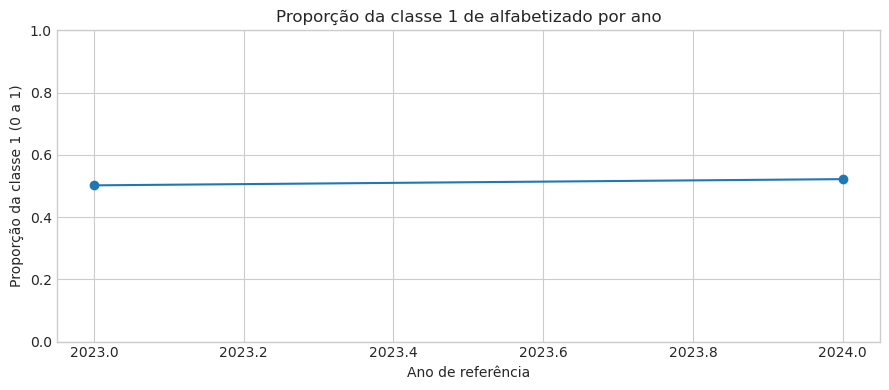

In [119]:
grafico_target=resumo_anual.drop_nulls("proporcao_alfabetizado")
if not grafico_target.is_empty():
    plt.figure(figsize=(9,4)); plt.plot(grafico_target[COL_ANO].to_numpy(),grafico_target["proporcao_alfabetizado"].to_numpy(),marker="o"); plt.title("Proporção da classe 1 de alfabetizado por ano"); plt.xlabel("Ano de referência"); plt.ylabel("Proporção da classe 1 (0 a 1)"); plt.ylim(0,1); plt.tight_layout(); salvar_figura_eda(plt.gcf(),"257_6_evolucao_da_proporcao_de_registros_na_classe_1_01.png"); plt.show()
else: print("Não há valores válidos de alfabetizado para gerar o gráfico.")


## 7. Evolução da proficiência

Quando a variável estiver disponível, comparamos a média e a mediana da proficiência por ano. A comparação deve considerar eventuais mudanças de cobertura e de composição dos registros.


ano_referencia,indicador,valor
i64,str,f64
2023,"""proficiencia_media""",747.563828
2024,"""proficiencia_media""",749.042072
2023,"""proficiencia_mediana""",752.147831
2024,"""proficiencia_mediana""",753.95


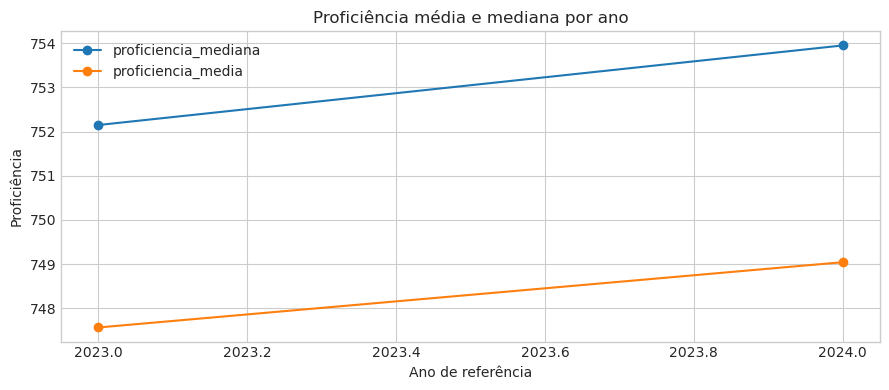

In [120]:
if COL_PROFICIENCIA is not None and "proficiencia_media" in resumo_anual.columns:
    proficiencia_long = resumo_anual.unpivot(
        index=[COL_ANO],
        on=[c for c in ["proficiencia_media", "proficiencia_mediana"] if c in resumo_anual.columns],
        variable_name="indicador",
        value_name="valor"
    )

    display(proficiencia_long)

    plt.figure(figsize=(9, 4))
    for indicador in proficiencia_long["indicador"].unique().to_list():
        trecho = proficiencia_long.filter(pl.col("indicador") == indicador).sort(COL_ANO)
        plt.plot(trecho[COL_ANO].to_numpy(), trecho["valor"].to_numpy(), marker="o", label=indicador)
    plt.legend()
    plt.title("Proficiência média e mediana por ano")
    plt.xlabel("Ano de referência")
    plt.ylabel("Proficiência")
    plt.tight_layout()
    salvar_figura_eda(plt.gcf(), "259_7_evolucao_da_proficiencia_01.png"); plt.show()
else:
    print("A variável proficiencia não está disponível; gráfico não gerado.")


## 8. Variação entre anos consecutivos

A tabela calcula diferenças entre as linhas anuais ordenadas. Antes de interpretar como variação entre anos consecutivos, confirme que os anos são de fato consecutivos e que cobertura e definições são comparáveis. A variação da proporção é apresentada em pontos percentuais. Não é uma análise longitudinal dos mesmos alunos.


In [121]:
resumo_ordenado=resumo_anual.with_columns(pl.col(COL_ANO).cast(pl.Float64,strict=False).alias("_ano_ordem")).sort("_ano_ordem")
indicadores_variacao=[c for c in ["quantidade_registros","proporcao_alfabetizado","proficiencia_media","proficiencia_mediana","presenca_media","preenchimento_caderno_medio"] if c in resumo_ordenado.columns]
variacoes=resumo_ordenado.select([COL_ANO,*indicadores_variacao]).with_columns([pl.col(c).diff().alias(f"variacao_{c}") for c in indicadores_variacao])
if "variacao_proporcao_alfabetizado" in variacoes.columns: variacoes=variacoes.with_columns((100*pl.col("variacao_proporcao_alfabetizado")).alias("variacao_proporcao_pontos_percentuais"))
display(variacoes)


ano_referencia,quantidade_registros,proporcao_alfabetizado,proficiencia_media,proficiencia_mediana,presenca_media,preenchimento_caderno_medio,variacao_quantidade_registros,variacao_proporcao_alfabetizado,variacao_proficiencia_media,variacao_proficiencia_mediana,variacao_presenca_media,variacao_preenchimento_caderno_medio,variacao_proporcao_pontos_percentuais
i64,u32,f64,f64,f64,f64,f64,i64,f64,f64,f64,f64,f64,f64
2023,1747439,0.502122,747.563828,752.147831,0.860149,0.860007,null,null,null,null,null,null,null
2024,2120560,0.522088,749.042072,753.95,0.873726,0.873284,373121,0.019966,1.478244,1.802169,0.013577,0.013278,1.996636


## 9. Comparação temporal por UF

Quando a coluna de UF estiver disponível, esta análise compara a proporção da classe 1 por UF e ano. O gráfico usa apenas os grupos observados; mudanças na quantidade de registros devem ser consideradas na interpretação.


ano_referencia,sigla_uf,quantidade_registros,proporcao_alfabetizado
i64,str,u32,f64
2023,"""AL""",35503,0.410782
2023,"""AM""",63055,0.405709
2023,"""AP""",12349,0.373229
2023,"""BA""",137724,0.315747
2023,"""CE""",100349,0.806605
2023,"""ES""",50482,0.604394
2023,"""GO""",83741,0.583
2023,"""MA""",74958,0.507471
2023,"""MG""",210107,0.54547


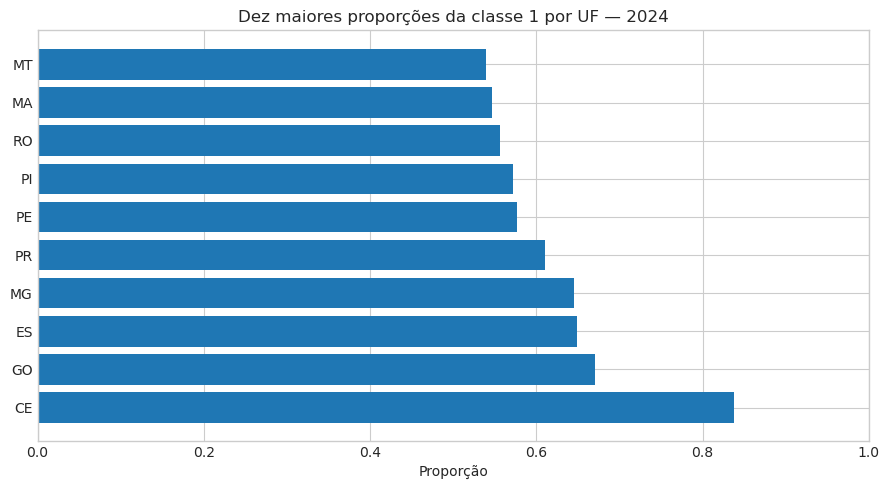

In [122]:
if COL_UF is not None:
    resumo_uf_ano=lf_analise.group_by([COL_ANO,COL_UF]).agg(pl.len().alias("quantidade_registros"),pl.col(COL_TARGET).mean().alias("proporcao_alfabetizado")).sort([COL_ANO,COL_UF]).collect(); display(resumo_uf_ano.head(30))
    anos_lista=resumo_uf_ano[COL_ANO].drop_nulls().unique().sort().to_list()
    if anos_lista:
        ano_recente=anos_lista[-1]; recorte=resumo_uf_ano.filter(pl.col(COL_ANO)==ano_recente).sort("proporcao_alfabetizado",descending=True).head(10)
        plt.figure(figsize=(9,5)); plt.barh(recorte[COL_UF].to_list(),recorte["proporcao_alfabetizado"].to_numpy()); plt.title(f"Dez maiores proporções da classe 1 por UF — {ano_recente}"); plt.xlabel("Proporção"); plt.xlim(0,1); plt.tight_layout(); salvar_figura_eda(plt.gcf(),"263_9_comparacao_temporal_por_uf_01.png"); plt.show()
else: print("Coluna de UF não encontrada; comparação temporal por UF não realizada.")


## 10. Comparação temporal por rede de ensino

Quando a coluna de rede estiver disponível, a tabela permite comparar proporções e volumes entre anos e redes. Se `rede_descricao` estiver disponível, ela será utilizada para facilitar a leitura.


In [123]:
if COL_REDE is not None:
    resumo_rede_ano = (
        lf_analise.group_by([COL_ANO, COL_REDE])
        .agg([
            pl.len().alias("quantidade_registros"),
            pl.col(COL_TARGET).mean().alias("proporcao_alfabetizado"),
        ])
        .sort([COL_ANO, COL_REDE])
        .collect()
        
    )

    display(resumo_rede_ano)
else:
    print("Coluna de rede não encontrada; comparação temporal por rede não realizada.")


ano_referencia,rede_descricao,quantidade_registros,proporcao_alfabetizado
i64,str,u32,f64
2023,"""Estadual""",155140,0.51993
2023,"""Municipal""",1592299,0.500387
2024,"""Estadual""",280258,0.537933
2024,"""Municipal""",1840277,0.519673
2024,"""Privada""",25,0.64


## 11. Síntese dos achados

A síntese abaixo é preenchida a partir dos resultados calculados, sem atribuir causalidade. Os resultados devem ser interpretados à luz da cobertura e da comparabilidade dos anos.


In [124]:
anos_observados = cobertura_anos[COL_ANO].drop_nulls().to_list()
n_anos = len(anos_observados)

achados_temporais = []

achados_temporais.append({
    "tema": "Cobertura temporal",
    "observacao": f"Foram identificados {n_anos} anos distintos na coluna {COL_ANO}: {anos_observados}.",
    "limitacao": "A existência de vários anos não garante, por si só, que a cobertura e a composição dos registros sejam comparáveis."
})

if not resumo_anual.is_empty() and resumo_anual["proporcao_alfabetizado"].drop_nulls().len() > 0:
    validos_target = resumo_anual.drop_nulls("proporcao_alfabetizado")
    ano_min = validos_target.sort("proporcao_alfabetizado")[COL_ANO][0]
    ano_max = validos_target.sort("proporcao_alfabetizado", descending=True)[COL_ANO][0]
    min_pct = validos_target["proporcao_alfabetizado"].min() * 100
    max_pct = validos_target["proporcao_alfabetizado"].max() * 100
    achados_temporais.append({
        "tema": "Proporção do target",
        "observacao": f"A proporção anual da classe 1 variou de {min_pct:.2f}% ({ano_min}) a {max_pct:.2f}% ({ano_max}).",
        "limitacao": "A proporção corresponde à média do target binário na base, não necessariamente ao índice oficial calculado por outra metodologia."
    })

if "quantidade_registros" in resumo_anual.columns and len(resumo_anual) > 0:
    achados_temporais.append({
        "tema": "Volume de registros",
        "observacao": f"A quantidade de registros por ano variou de {int(resumo_anual['quantidade_registros'].min())} a {int(resumo_anual['quantidade_registros'].max())}.",
        "limitacao": "Variações de volume podem afetar a comparabilidade dos indicadores entre anos."
    })

achados_temporais.append({
    "tema": "Interpretação",
    "observacao": "As análises comparam indicadores agregados nos períodos observados, por ano e por grupos territoriais/administrativos disponíveis.",
    "limitacao": "Não foi realizado acompanhamento individual dos estudantes: a estabilidade de id_aluno entre anos não está validada. Diferenças temporais não comprovam causalidade e exigem avaliar cobertura, definições e disponibilidade das variáveis."
})

if n_anos < 3:
    achados_temporais.append({
        "tema": "Quantidade de períodos",
        "observacao": f"A base contém {n_anos} ano(s) distinto(s) identificado(s).",
        "limitacao": "Com menos de três períodos, a análise não deve ser descrita como uma tendência de longo prazo."
    })

display(pl.DataFrame(achados_temporais))


tema,observacao,limitacao
str,str,str
"""Cobertura temporal""","""Foram identificados 2 anos dis…","""A existência de vários anos nã…"
"""Proporção do target""","""A proporção anual da classe 1 …","""A proporção corresponde à médi…"
"""Volume de registros""","""A quantidade de registros por …","""Variações de volume podem afet…"
"""Interpretação""","""As análises comparam indicador…","""Não foi realizado acompanhamen…"
"""Quantidade de períodos""","""A base contém 2 ano(s) distint…","""Com menos de três períodos, a …"


## 12. Conclusão

Após executar as células, revise os resultados anuais, as diferenças observadas na proporção do target e nos indicadores educacionais, bem como as variações de volume e cobertura.

A interpretação deve se limitar aos anos e grupos efetivamente observados. Diferenças temporais são descritivas e não comprovam causalidade. A proporção da classe 1 de `alfabetizado` deve ser distinguida do índice oficial de alfabetização caso as metodologias de cálculo não sejam equivalentes.

As comparações deste notebook são agregadas por ano e, quando disponível, por UF, município ou rede. O campo `id_aluno` não é usado para vinculação longitudinal individual, pois sua estabilidade entre anos não está validada para esta análise. Antes de concluir, confira se os anos comparados possuem cobertura e definições compatíveis e registre limitações relevantes para as próximas etapas do projeto.

A cobertura territorial também variou entre os períodos: foram identificadas 23 UFs e 4.873 municípios em 2023, frente a 26 UFs e 5.519 municípios em 2024. Essa diferença deve ser considerada na interpretação das variações observadas, pois parte dos resultados pode refletir mudanças na cobertura e na composição dos registros.


<a id="fase-4"></a>

# Fase 4 — preparação, prevenção de leakage e baseline


## Caderno de origem: `TC3_Main_Fluxo_Unificado_Fase4_Preparacao_Baseline_Metas_Chave_Escola.ipynb`

> Código oficial incorporado de `notebooks/TC3_Main_Fluxo_Unificado_Fase4_Preparacao_Baseline_Metas_Chave_Escola.ipynb`.


# TC3 — Fluxo unificado com metas e rastreabilidade por escola/ano

Cópia evolutiva do fluxo validado. Mantém as 18 features não constantes do contrato atualizado e
preserva `id_escola` e `chave_escola_ano` exclusivamente como chaves técnicas.
Nenhuma das duas entra no treinamento.


## 1. Premissas e decisões metodológicas

- Unidade analítica: uma observação de aluno por ano de referência.
- Integração das fontes externas: município, ano e UF.
- `id_escola` é anonimizado e não corresponde a `CO_ENTIDADE` ou `ID_ESCOLA`; não é usado para relacionar as fontes.
- INSE e Censo Escolar foram agregados ao nível municipal antes da integração.
- As colunas `in_*` provenientes do Censo representam proporções municipais de escolas com o recurso, apesar do nome herdado da fonte.
- Variáveis ligadas à aplicação da avaliação ou à construção do target são excluídas das features.
- Imputações são estimadas exclusivamente no conjunto de treino indicado por `dataset_split`.
- Identificadores são preservados somente para rastreabilidade.
- `chave_escola_ano` combina ano, município e identificador anônimo para agrupar alunos na mesma edição.
- A chave não identifica a escola real, não relaciona Censo/INSE e não rastreia a mesma unidade entre anos.


### Linhagem das fontes

| Fonte | Granularidade original | Tratamento no TC3-82 | Uso neste fluxo |
|---|---|---|---|
| `ml_aluno` | Aluno/ano | Base principal | Target, tempo, UF, rede e controles |
| Bolsa Família | Município/ano | Join municipal anual | Contexto financeiro transformado |
| Fundeb | Município/ano | Join municipal anual | Contexto financeiro transformado, preservando sinal |
| Receitas | Município/ano | Join municipal anual | Contexto financeiro transformado |
| PIB | Município/ano | Join municipal anual | PIB per capita de 2023 como fotografia contextual |
| INSE | Escola | Agregação ponderada por município/ano | Média INSE de 2023 como fotografia contextual |
| Censo Escolar | Escola | Agregação por município/ano | Proporções municipais de infraestrutura de 2023 |

A reconstrução das fontes brutas permanece no TC3-82. Este notebook começa na camada consolidada, verifica seu contrato e produz a camada final de modelagem.


In [125]:
from pathlib import Path
import json
import math
import polars as pl
import matplotlib.pyplot as plt


pl.Config.set_tbl_rows(100)
pl.Config.set_tbl_cols(100)
plt.style.use("seaborn-v0_8-whitegrid")


In [126]:
# PROJECT_ROOT e herdado da configuracao central.
INPUT_DIR = DADOS_PROCESSADOS_DIR / "consolidado" / "base_alunos_municipios_por_uf"
OUTPUT_DIR = DADOS_PROCESSADOS_DIR / "preparado" / "base_modelagem_final_com_chave_escola_por_uf"
DECISION_PATH = RESULTADOS_TABELAS_DIR / "dicionario_dados" / "decisoes_features_modelagem_com_chave_escola.csv"
DATA_DICTIONARY_PATH = RESULTADOS_TABELAS_DIR / "dicionario_dados" / "base_modelagem_catalogo_com_chave_escola.csv"

arquivos = sorted(INPUT_DIR.glob("sigla_uf=*/*.parquet"))
if not arquivos:
    raise FileNotFoundError(f"Nenhum Parquet localizado em {INPUT_DIR}")

lf = pl.scan_parquet([str(p) for p in arquivos], hive_partitioning=True)
schema = lf.collect_schema()
print(f"Raiz: {PROJECT_ROOT}")
print(f"Partições/arquivos: {len(arquivos)}")
print(f"Colunas: {len(schema)}")


Raiz: /workspace
Partições/arquivos: 26
Colunas: 49


## 2. Contrato de variáveis

A seleção abaixo substitui as decisões preliminares baseadas apenas nas 19 colunas originais. O contrato diferencia features, chaves, controles, target e exclusões.


In [127]:
TARGET = "alfabetizado"
SOURCE_KEY_COLUMNS = ["id_aluno", "id_municipio", "id_escola"]
KEY_COLUMNS = SOURCE_KEY_COLUMNS + ["chave_escola_ano"]
CONTROL_COLUMNS = ["dataset_split"]
CATEGORICAL_FEATURES = ["sigla_uf", "rede"]
NUMERIC_FEATURES = [
    "ano_referencia",
    "taxa_alfabetizacao_municipio_ano_anterior",
    "media_portugues_municipio_ano_anterior",
    "valor_bolsa_familia", "valor_fundeb", "valor_receitas",
    "valor_pib", "valor_pib_per_capita",
    "qtd_escolas_inse", "qtd_alunos_inse", "media_inse",
    "pc_nivel_1", "pc_nivel_2", "pc_nivel_3", "pc_nivel_4",
    "pc_nivel_5", "pc_nivel_6", "pc_nivel_7", "pc_nivel_8",
    "qtd_escolas_censo", "qt_mat_bas", "qt_doc_bas", "qt_tur_bas",
    "in_biblioteca_sala_leitura", "in_laboratorio_informatica",
    "in_quadra_esportes", "in_agua_rede_publica",
    "in_energia_rede_publica", "in_esgoto_rede_publica",
    "in_internet", "in_banda_larga",
]
LEAKAGE_COLUMNS = ["proficiencia", "presenca", "preenchimento_caderno", "caderno"]
EXCLUDED_NETWORKS = {4: "Privada — 25 registros de uma única escola/município"}
TECHNICAL_COLUMNS = ["processed_at", "peso_aluno"]
REDUNDANT_COLUMNS = ["nome_municipio", "rede_descricao", "serie", "nome uf", "nome do município"]

# Conjunto enxuto definido após o EDA. Os demais campos numéricos acima continuam
# disponíveis somente para análise e documentação das exclusões.
STATIC_2023_FEATURES = [
    "valor_pib_per_capita", "media_inse",
    "in_biblioteca_sala_leitura", "in_laboratorio_informatica",
    "in_quadra_esportes", "in_agua_rede_publica",
    "in_energia_rede_publica", "in_esgoto_rede_publica",
    "in_internet", "in_banda_larga",
]
CURRENT_FINANCIAL_FEATURES = ["valor_bolsa_familia", "valor_fundeb", "valor_receitas"]
FINAL_SOURCE_FEATURES = ["ano_referencia"] + CURRENT_FINANCIAL_FEATURES + STATIC_2023_FEATURES
FINAL_MODEL_FEATURES = (
    CATEGORICAL_FEATURES + ["ano_referencia"]
    + [f"{c}__signed_log1p" for c in CURRENT_FINANCIAL_FEATURES + ["valor_pib_per_capita"]]
    + ["media_inse"]
    + [c for c in STATIC_2023_FEATURES if c.startswith("in_")]
    + ["cobertura_financeira_ausente", "cobertura_inse_ausente"]
)
FEATURES = FINAL_MODEL_FEATURES
required = set(SOURCE_KEY_COLUMNS + CONTROL_COLUMNS + CATEGORICAL_FEATURES + FINAL_SOURCE_FEATURES + [TARGET])
missing_required = sorted(required - set(schema.names()))
if missing_required:
    raise KeyError(f"Colunas necessárias ausentes: {missing_required}")

print(f"Features finais aprovadas: {len(FEATURES)}")
print(f"Chaves de rastreabilidade: {KEY_COLUMNS}")
print(f"Excluídas por leakage: {LEAKAGE_COLUMNS}")


Features finais aprovadas: 18
Chaves de rastreabilidade: ['id_aluno', 'id_municipio', 'id_escola', 'chave_escola_ano']
Excluídas por leakage: ['proficiencia', 'presenca', 'preenchimento_caderno', 'caderno']


In [128]:
motivos = {
    TARGET: ("target", "Variável-alvo; nunca entra nas features."),
    **{c: ("chave", "Mantida apenas para rastreabilidade e validação.") for c in KEY_COLUMNS},
    **{c: ("controle", "Controla a separação dos dados; não entra no modelo.") for c in CONTROL_COLUMNS},
    **{c: ("feature_categorica", "Contexto disponível; encoding será ajustado no pipeline do modelo.") for c in CATEGORICAL_FEATURES},
    **{c: ("feature_numerica_final", "Indicador mantido no conjunto final; pode ser transformado antes da persistência.") for c in FINAL_SOURCE_FEATURES},
    **{c: ("excluir_pos_eda", "Removida após o EDA por redundância, cobertura temporal inadequada ou representação equivalente mais enxuta.") for c in set(NUMERIC_FEATURES) - set(FINAL_SOURCE_FEATURES)},
    **{c: ("excluir_leakage", "Ligada à aplicação da avaliação ou à construção/mensuração do target.") for c in LEAKAGE_COLUMNS},
    **{c: ("excluir_tecnica", "Campo técnico ou peso amostral; não representa característica preditiva.") for c in TECHNICAL_COLUMNS},
    **{c: ("excluir_redundante", "Identificador de alta cardinalidade, constante ou representação redundante.") for c in REDUNDANT_COLUMNS},
}
motivos["rede"] = ("feature_categorica", "Somente redes estadual (2) e municipal (3); a rede privada (4) é excluída antes da modelagem por conter apenas 25 registros de uma única escola/município.")
decisoes = pl.DataFrame([
    {"coluna": c, "decisao": motivos.get(c, ("revisar", "Não classificada no contrato."))[0],
     "justificativa": motivos.get(c, ("revisar", "Não classificada no contrato."))[1]}
    for c in schema.names()
]).sort(["decisao", "coluna"])
display(decisoes)

nao_classificadas = decisoes.filter(pl.col("decisao") == "revisar")
assert nao_classificadas.is_empty(), f"Há colunas sem decisão: {nao_classificadas['coluna'].to_list()}"


coluna,decisao,justificativa
str,str,str
"""id_aluno""","""chave""","""Mantida apenas para rastreabil…"
"""id_escola""","""chave""","""Mantida apenas para rastreabil…"
"""id_municipio""","""chave""","""Mantida apenas para rastreabil…"
"""dataset_split""","""controle""","""Controla a separação dos dados…"
"""caderno""","""excluir_leakage""","""Ligada à aplicação da avaliaçã…"
"""preenchimento_caderno""","""excluir_leakage""","""Ligada à aplicação da avaliaçã…"
"""presenca""","""excluir_leakage""","""Ligada à aplicação da avaliaçã…"
"""proficiencia""","""excluir_leakage""","""Ligada à aplicação da avaliaçã…"
"""media_portugues_municipio_ano_…","""excluir_pos_eda""","""Removida após o EDA por redund…"


## 3. Auditoria estrutural e qualidade

As verificações abaixo substituem suposições por testes executáveis: esquema das partições, volume, granularidade, duplicidades, nulos e distribuição do target.


In [129]:
schemas_particoes = []
for arquivo in arquivos:
    nomes = pl.scan_parquet(arquivo).collect_schema().names()
    schemas_particoes.append({"arquivo": str(arquivo.relative_to(PROJECT_ROOT)), "colunas": nomes})

schema_referencia = schemas_particoes[0]["colunas"]
divergentes = [x["arquivo"] for x in schemas_particoes if x["colunas"] != schema_referencia]
assert not divergentes, f"Partições com esquema divergente: {divergentes}"

resumo_estrutura = lf.select(
    pl.len().alias("registros"),
    pl.col("id_aluno").n_unique().alias("alunos_distintos"),
    pl.col("id_municipio").n_unique().alias("municipios_distintos"),
    pl.col("sigla_uf").n_unique().alias("ufs_distintas"),
    pl.col("ano_referencia").min().alias("ano_min"),
    pl.col("ano_referencia").max().alias("ano_max"),
).collect()
display(resumo_estrutura)
print("Todas as partições têm o mesmo esquema.")


registros,alunos_distintos,municipios_distintos,ufs_distintas,ano_min,ano_max
u32,u32,u32,u32,i64,i64
3867999,2352328,5548,26,2023,2024


Todas as partições têm o mesmo esquema.


In [130]:
duplicatas_aluno_ano = (
    lf.group_by(["id_aluno", "ano_referencia"])
      .agg(pl.len().alias("quantidade"))
      .filter(pl.col("quantidade") > 1)
      .select(pl.len().alias("chaves_duplicadas"))
      .collect()
)
display(duplicatas_aluno_ano)
assert duplicatas_aluno_ano.item() == 0, "Existem duplicatas por aluno/ano."


chaves_duplicadas
u32
0


In [131]:
# O projeto trabalha exclusivamente com a 2ª série.
series_observadas = lf.select(pl.col("serie").drop_nulls().unique().sort()).collect()["serie"].to_list()
assert series_observadas == [2], f"Recorte inesperado de série: {series_observadas}"
print("Recorte de série validado:", series_observadas)

# O mesmo aluno não pode aparecer em mais de um split, mesmo quando ocorre nos dois anos.
alunos_multiplos_splits = (
    lf.group_by("id_aluno")
      .agg(pl.col("dataset_split").n_unique().alias("quantidade_splits"))
      .filter(pl.col("quantidade_splits") > 1)
      .select(pl.len().alias("alunos_em_multiplos_splits"))
      .collect()
)
display(alunos_multiplos_splits)
assert alunos_multiplos_splits.item() == 0, "Há alunos compartilhados entre os splits."

distribuicao_split = lf.group_by("dataset_split").agg(
    pl.len().alias("registros"),
    pl.col("id_aluno").n_unique().alias("alunos_distintos"),
    pl.col(TARGET).mean().alias("proporcao_alfabetizado"),
).sort("dataset_split").collect()
display(distribuicao_split)


Recorte de série validado: [2]


alunos_em_multiplos_splits
u32
0


dataset_split,registros,alunos_distintos,proporcao_alfabetizado
str,u32,u32,f64
"""teste""",581596,353855,0.513601
"""treino""",2705252,1645229,0.513002
"""validacao""",581151,353244,0.512841


**Limite do identificador:** a ausência de alunos compartilhados entre splits protege a avaliação. Ainda assim, `id_aluno` é anonimizado e não deve ser usado para inferir mobilidade entre municípios nem trajetórias individuais entre anos.


In [132]:
total = lf.select(pl.len()).collect().item()
nulos = (
    lf.select([pl.col(c).null_count().alias(c) for c in schema.names()])
      .collect()
      .unpivot(variable_name="coluna", value_name="nulos")
      .with_columns((100 * pl.col("nulos") / total).round(2).alias("percentual_nulos"))
      .sort("percentual_nulos", descending=True)
)
display(nulos)


coluna,nulos,percentual_nulos
str,u32,f64
"""taxa_alfabetizacao_municipio_a…",1791646,46.32
"""media_portugues_municipio_ano_…",1791646,46.32
"""proficiencia""",513338,13.27
"""peso_aluno""",513338,13.27
"""valor_receitas""",34500,0.89
"""valor_fundeb""",33712,0.87
"""qtd_escolas_inse""",2330,0.06
"""qtd_alunos_inse""",2330,0.06
"""media_inse""",2330,0.06


## 4. EDA consolidada

A EDA é executada sobre a base consolidada, mas as conclusões e os tratamentos são vinculados ao contrato de variáveis. Não são criadas regras a partir dos conjuntos de validação ou teste.


alfabetizado,quantidade,percentual
i32,u32,f64
0,1883453,48.69
1,1984546,51.31


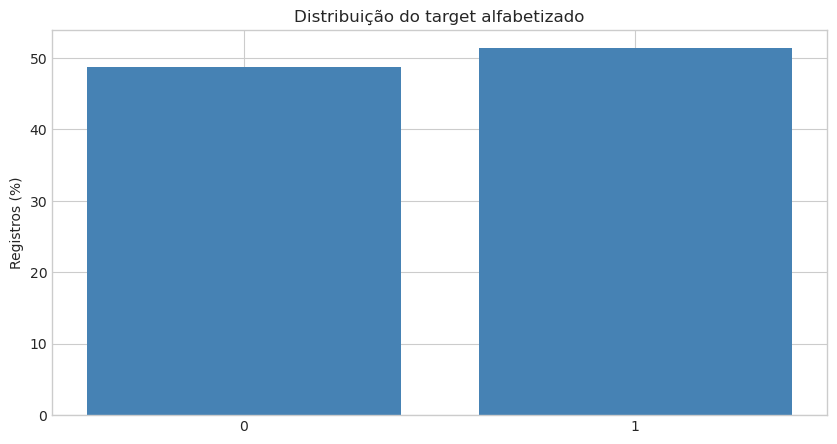

In [133]:
distribuicao_target = (
    lf.group_by(TARGET)
      .agg(pl.len().alias("quantidade"))
      .with_columns((100 * pl.col("quantidade") / pl.col("quantidade").sum()).round(2).alias("percentual"))
      .sort(TARGET)
      .collect()
)
display(distribuicao_target)
target_plot = distribuicao_target
plt.bar(target_plot[TARGET].cast(pl.String).to_list(), target_plot["percentual"].to_numpy(), color="steelblue")
plt.title("Distribuição do target alfabetizado")
plt.ylabel("Registros (%)")
salvar_figura_eda(plt.gcf(), "286_4_eda_consolidada_01.png"); plt.show()


In [134]:
cobertura_temporal = (
    lf.group_by("ano_referencia")
      .agg(
          pl.len().alias("registros"),
          *[pl.col(c).is_not_null().mean().round(4).alias(f"cobertura__{c}") for c in NUMERIC_FEATURES if c != "ano_referencia"]
      )
      .sort("ano_referencia")
      .collect()
)
display(cobertura_temporal)


ano_referencia,registros,cobertura__taxa_alfabetizacao_municipio_ano_anterior,cobertura__media_portugues_municipio_ano_anterior,cobertura__valor_bolsa_familia,cobertura__valor_fundeb,cobertura__valor_receitas,cobertura__valor_pib,cobertura__valor_pib_per_capita,cobertura__qtd_escolas_inse,cobertura__qtd_alunos_inse,cobertura__media_inse,cobertura__pc_nivel_1,cobertura__pc_nivel_2,cobertura__pc_nivel_3,cobertura__pc_nivel_4,cobertura__pc_nivel_5,cobertura__pc_nivel_6,cobertura__pc_nivel_7,cobertura__pc_nivel_8,cobertura__qtd_escolas_censo,cobertura__qt_mat_bas,cobertura__qt_doc_bas,cobertura__qt_tur_bas,cobertura__in_biblioteca_sala_leitura,cobertura__in_laboratorio_informatica,cobertura__in_quadra_esportes,cobertura__in_agua_rede_publica,cobertura__in_energia_rede_publica,cobertura__in_esgoto_rede_publica,cobertura__in_internet,cobertura__in_banda_larga
i64,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2023,1747439,0.0,0.0,1.0,0.9983,0.9985,1.0,1.0,0.9993,0.9993,0.9993,0.9993,0.9993,0.9993,0.9993,0.9993,0.9993,0.9993,0.9993,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2024,2120560,0.9792,0.9792,1.0,0.9855,0.9849,1.0,1.0,0.9995,0.9995,0.9995,0.9995,0.9995,0.9995,0.9995,0.9995,0.9995,0.9995,0.9995,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [135]:
numericas_eda = [c for c in NUMERIC_FEATURES if c != "ano_referencia"]

# Estatísticas descritivas e quantis exigem materialização. Para evitar que essa
# etapa exploratória esgote a RAM, usamos amostra determinística e limitada pelo
# perfil detectado. Contagens oficiais continuam sendo calculadas integralmente
# nas células anteriores.
limites_eda_por_perfil = {
    "baixo": 50_000,
    "medio": 100_000,
    "normal": 200_000,
    "alto": 300_000,
}
limite_linhas_eda = limites_eda_por_perfil[PERFIL_ATIVO]
fracao_eda = min(FRACOES_AMOSTRAGEM["eda_correlacao"], limite_linhas_eda / max(total, 1))
limite_hash_eda = max(1, round(fracao_eda * 10_000))

amostra_numerica_eda = (
    lf.filter((pl.col("id_aluno").hash(seed=SEED_GLOBAL) % 10_000) < limite_hash_eda)
      .select(numericas_eda)
      .head(limite_linhas_eda)
      .collect(engine="streaming")
)
print(
    f"Resumo numérico: {amostra_numerica_eda.height:,}/{total:,} registros "
    f"({amostra_numerica_eda.height / max(total, 1):.2%}); perfil={PERFIL_ATIVO}."
)
resumo_numerico = amostra_numerica_eda.describe()
display(resumo_numerico)

del amostra_numerica_eda
_liberar_memoria_global(agressiva=True)


Resumo numérico: 192,850/3,867,999 registros (4.99%); perfil=normal.


statistic,taxa_alfabetizacao_municipio_ano_anterior,media_portugues_municipio_ano_anterior,valor_bolsa_familia,valor_fundeb,valor_receitas,valor_pib,valor_pib_per_capita,qtd_escolas_inse,qtd_alunos_inse,media_inse,pc_nivel_1,pc_nivel_2,pc_nivel_3,pc_nivel_4,pc_nivel_5,pc_nivel_6,pc_nivel_7,pc_nivel_8,qtd_escolas_censo,qt_mat_bas,qt_doc_bas,qt_tur_bas,in_biblioteca_sala_leitura,in_laboratorio_informatica,in_quadra_esportes,in_agua_rede_publica,in_energia_rede_publica,in_esgoto_rede_publica,in_internet,in_banda_larga
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",103684.0,103684.0,192850.0,191184.0,191168.0,192850.0,192850.0,192727.0,192727.0,192727.0,192727.0,192727.0,192727.0,192727.0,192727.0,192727.0,192727.0,192727.0,192850.0,192850.0,192850.0,192850.0,192850.0,192850.0,192850.0,192850.0,192850.0,192850.0,192850.0,192850.0
"""null_count""",89166.0,89166.0,0.0,1666.0,1682.0,0.0,0.0,123.0,123.0,123.0,123.0,123.0,123.0,123.0,123.0,123.0,123.0,123.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",56.262114,744.985233,4.6570e8,-6.7873e8,5.2915e10,5.9418e10,50193.647384,156.357589,24155.687236,4.919099,1.508505,13.005624,17.267879,21.948456,20.585448,14.515737,10.104855,1.063503,586.620109,183800.990397,10659.156801,8155.795266,0.589698,0.340704,0.432514,0.818846,0.981923,0.624323,0.946107,0.877071
"""std""",15.373921,19.625143,1.0908e9,9.2326e9,1.7838e11,1.8723e11,50540.261463,339.25219,63393.449998,0.428919,2.20288,11.091847,7.468014,4.183394,6.13878,7.567246,7.256687,0.934085,1535.243235,484563.311889,28276.264494,21975.310209,0.202798,0.162344,0.171892,0.236753,0.080417,0.341691,0.12404,0.149915
"""min""",3.41,673.2983,45671.0,-4.5338e10,8.3986e6,2.1017664e7,6757.48,1.0,15.0,3.504799,0.0,0.0,0.0,3.262136,2.713333,0.0,0.0,0.0,2.0,183.0,15.0,14.0,0.0,0.0,0.0,0.0,0.063492,0.0,0.047619,0.0
"""25%""",46.56,733.5938,2.1213354e7,-1.2144e7,1.3348e9,7.83841e8,23203.21,13.0,1059.0,4.555143,0.221307,4.223407,10.761524,19.211454,15.402391,7.374293,3.50074,0.338464,38.0,6924.0,451.0,342.0,0.454545,0.230137,0.333333,0.740469,0.993915,0.338028,0.964286,0.824493
"""50%""",55.62,742.7747,7.0022127e7,1.4180e8,4.5886e9,4.1387e9,39993.15,36.0,3578.0,4.998492,0.574672,8.293117,16.450475,22.51141,22.483609,15.039165,8.858812,0.863381,100.0,24869.0,1471.0,1122.0,0.625,0.351145,0.458824,0.928571,1.0,0.72,0.993105,0.930818
"""75%""",65.74,753.1549,2.53392656e8,6.9188e8,1.9224e10,2.2791e10,63192.47,108.0,14066.0,5.270837,2.000339,20.88724,24.400391,25.219683,25.365505,20.729098,15.396681,1.578969,327.0,96373.0,5873.0,4246.0,0.743083,0.440341,0.555556,0.991597,1.0,0.939394,1.0,0.976923
"""max""",100.0,868.4554,5.2370e9,3.5589e10,2.5756e12,1.0668e12,842004.6,1677.0,356802.0,5.940142,41.774715,58.557768,40.247683,40.819,48.24,40.368571,50.835156,11.292616,8449.0,2.670096e6,155496.0,122981.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [136]:
categorias = []
for coluna in CATEGORICAL_FEATURES + ["ano_referencia", "dataset_split"]:
    tabela = (
        lf.group_by(coluna).agg(pl.len().alias("quantidade"))
          .with_columns((100 * pl.col("quantidade") / pl.col("quantidade").sum()).round(2).alias("percentual"))
          .sort("quantidade", descending=True).collect()
    )
    print(f"\n{coluna}")
    display(tabela)



sigla_uf


sigla_uf,quantidade,percentual
str,u32,f64
"""SP""",443777,11.47
"""MG""",413557,10.69
"""RJ""",311198,8.05
"""PR""",277446,7.17
"""BA""",253300,6.55
"""RS""",229410,5.93
"""PA""",204949,5.3
"""SC""",201171,5.2
"""CE""",190190,4.92



rede


rede,quantidade,percentual
i32,u32,f64
3,3432576,88.74
2,435398,11.26
4,25,0.0



ano_referencia


ano_referencia,quantidade,percentual
i64,u32,f64
2024,2120560,54.82
2023,1747439,45.18



dataset_split


dataset_split,quantidade,percentual
str,u32,f64
"""treino""",2705252,69.94
"""teste""",581596,15.04
"""validacao""",581151,15.02


In [137]:
# Categorias raras são registradas para tratamento no pipeline, sem alterar a semântica da base.
MIN_CATEGORIA_TREINO = 1_000
categorias_raras = (
    lf.filter(pl.col("dataset_split") == "treino")
      .group_by("rede").agg(pl.len().alias("registros_treino"))
      .filter(pl.col("registros_treino") < MIN_CATEGORIA_TREINO)
      .sort("registros_treino")
      .collect()
)
display(categorias_raras)
print("Categorias raras exigem decisão explícita de escopo ou tratamento; a decisão aplicada consta na seção 5.")


rede,registros_treino
i32,u32
4,16


Categorias raras exigem decisão explícita de escopo ou tratamento; a decisão aplicada consta na seção 5.


In [138]:
# Correlações são triagem descritiva; não comprovam causalidade.
corr_target = lf.select([
    pl.corr(pl.col(c).cast(pl.Float64), pl.col(TARGET).cast(pl.Float64)).alias(c)
    for c in numericas_eda
]).collect().unpivot(variable_name="feature", value_name="correlacao_target")
corr_target = corr_target.with_columns(pl.col("correlacao_target").abs().alias("abs_correlacao")).sort("abs_correlacao", descending=True)
display(corr_target)


feature,correlacao_target,abs_correlacao
str,f64,f64
"""media_portugues_municipio_ano_…",0.246996,0.246996
"""taxa_alfabetizacao_municipio_a…",0.235955,0.235955
"""in_laboratorio_informatica""",0.069195,0.069195
"""in_quadra_esportes""",0.059441,0.059441
"""in_biblioteca_sala_leitura""",0.057111,0.057111
"""in_internet""",0.050351,0.050351
"""pc_nivel_3""",-0.047412,0.047412
"""pc_nivel_7""",0.04513,0.04513
"""pc_nivel_6""",0.044552,0.044552


### 4.1 Distribuições e assimetria

As visualizações usam uma amostra reprodutível para evitar materializar milhões de pontos. As estatísticas descritivas anteriores continuam calculadas sobre a base completa.


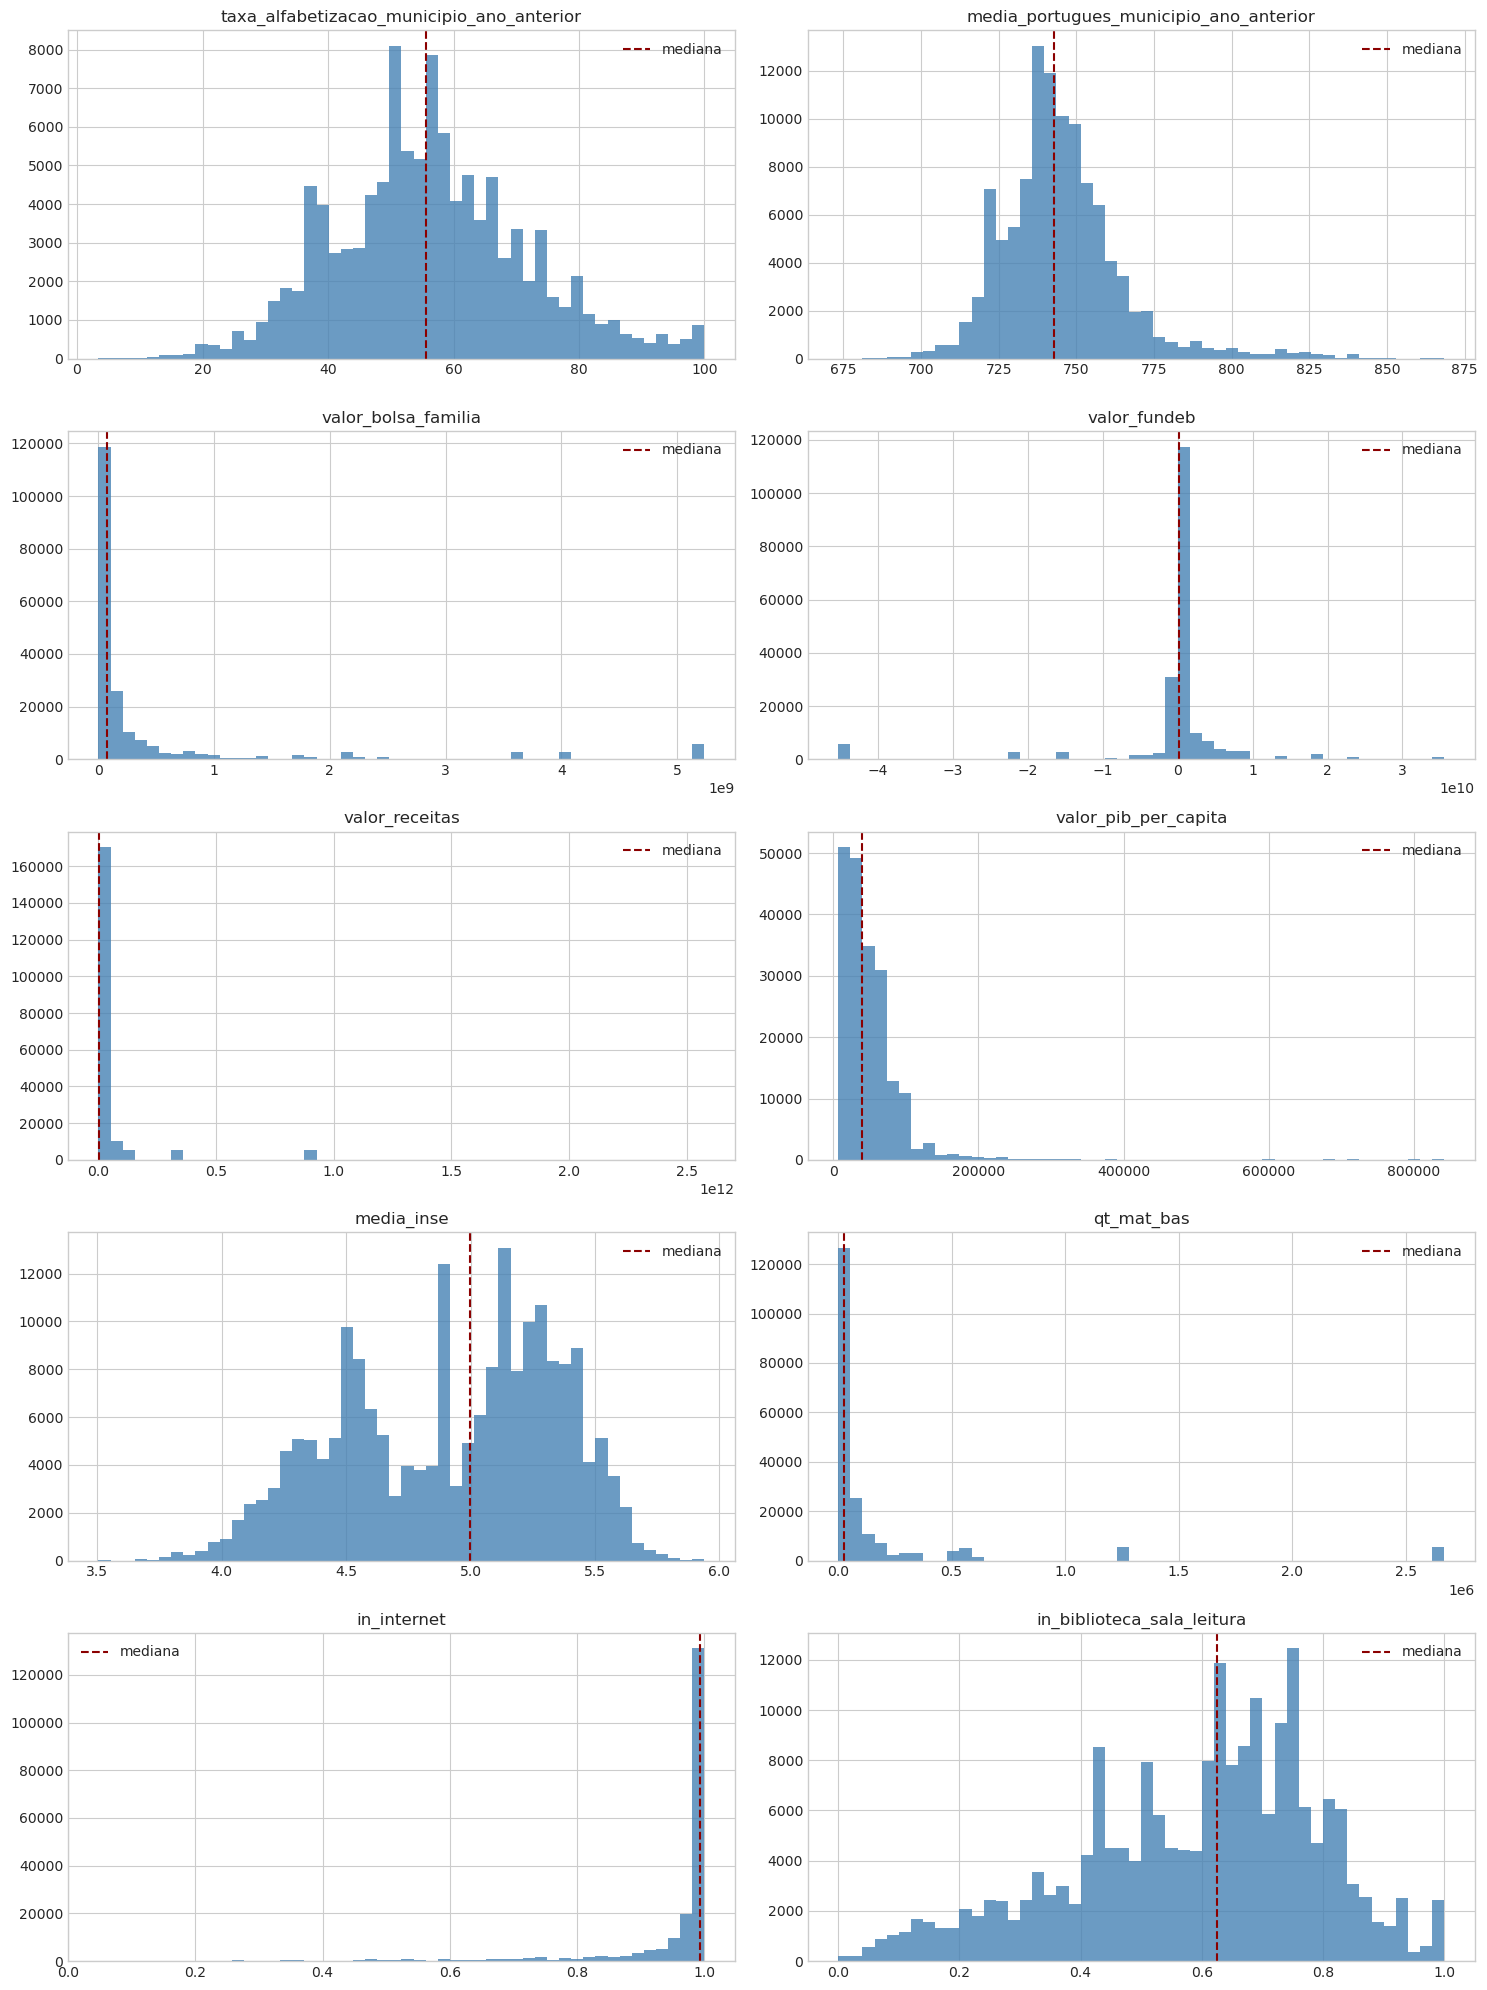

In [139]:
FEATURES_DISTRIBUICAO = [
    "taxa_alfabetizacao_municipio_ano_anterior",
    "media_portugues_municipio_ano_anterior", "valor_bolsa_familia",
    "valor_fundeb", "valor_receitas", "valor_pib_per_capita",
    "media_inse", "qt_mat_bas", "in_internet", "in_biblioteca_sala_leitura",
]
fracao_eda_distribuicao = min(1.0, 200_000 / total)
limite_hash_eda = max(1, round(fracao_eda_distribuicao * 10_000))
amostra_eda = (
    lf.filter((pl.col("id_aluno").hash(seed=SEED_GLOBAL) % 10_000) < limite_hash_eda)
    .select(FEATURES_DISTRIBUICAO + [TARGET])
    .head(200_000)
    .collect(engine="streaming")
)

fig, axes = plt.subplots(5, 2, figsize=(15, 20))
for eixo, coluna in zip(axes.flatten(), FEATURES_DISTRIBUICAO):
    valores = amostra_eda[coluna].drop_nulls().to_numpy()
    eixo.hist(valores, bins=50, color="steelblue", alpha=0.8)
    eixo.axvline(float(np.median(valores)), color="darkred", linestyle="--", label="mediana")
    eixo.set_title(coluna)
    eixo.legend()
plt.tight_layout()
salvar_figura_eda(plt.gcf(), "293_4_1_distribuicoes_e_assimetria_01.png"); plt.show()


### 4.2 Outliers e limites de domínio

O IQR sinaliza valores extremos, mas não determina remoção automática. Valores financeiros, matrículas e quantidades municipais podem ser legitimamente assimétricos. As proporções de infraestrutura, por outro lado, devem respeitar o intervalo de 0 a 1.


In [140]:
FEATURES_OUTLIERS = [
    "taxa_alfabetizacao_municipio_ano_anterior", "media_portugues_municipio_ano_anterior",
    "valor_bolsa_familia", "valor_fundeb", "valor_receitas",
    "valor_pib", "valor_pib_per_capita", "media_inse",
    "qtd_alunos_inse", "qt_mat_bas", "qt_doc_bas", "qt_tur_bas",
]
quartis = lf.select([
    expr
    for c in FEATURES_OUTLIERS
    for expr in (pl.col(c).quantile(0.25).alias(f"{c}__q1"), pl.col(c).quantile(0.75).alias(f"{c}__q3"))
]).collect().row(0, named=True)

expressoes_outliers = []
limites_iqr = {}
for c in FEATURES_OUTLIERS:
    q1, q3 = quartis[f"{c}__q1"], quartis[f"{c}__q3"]
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    limites_iqr[c] = (inferior, superior)
    expressoes_outliers.append(((pl.col(c) < inferior) | (pl.col(c) > superior)).sum().alias(c))

contagem_outliers = lf.select(expressoes_outliers).collect().unpivot(
    variable_name="feature", value_name="quantidade_outliers"
).with_columns((100 * pl.col("quantidade_outliers") / total).round(2).alias("percentual_total")).sort(
    "percentual_total", descending=True
)
display(contagem_outliers)

PROPORCOES_INFRA = [c for c in NUMERIC_FEATURES if c.startswith("in_")]
violacoes_proporcao = lf.select([
    ((pl.col(c) < 0) | (pl.col(c) > 1)).sum().alias(c) for c in PROPORCOES_INFRA
]).collect().unpivot(variable_name="feature", value_name="fora_intervalo_0_1")
display(violacoes_proporcao)
assert violacoes_proporcao["fora_intervalo_0_1"].sum() == 0, "Há proporções de infraestrutura fora de 0 a 1."


feature,quantidade_outliers,percentual_total
str,u32,f64
"""valor_fundeb""",986371,25.5
"""valor_pib""",604083,15.62
"""qt_doc_bas""",583210,15.08
"""valor_bolsa_familia""",576396,14.9
"""qt_mat_bas""",570640,14.75
"""qt_tur_bas""",570640,14.75
"""valor_receitas""",551499,14.26
"""qtd_alunos_inse""",512940,13.26
"""valor_pib_per_capita""",152756,3.95


feature,fora_intervalo_0_1
str,u32
"""in_biblioteca_sala_leitura""",0
"""in_laboratorio_informatica""",0
"""in_quadra_esportes""",0
"""in_agua_rede_publica""",0
"""in_energia_rede_publica""",0
"""in_esgoto_rede_publica""",0
"""in_internet""",0
"""in_banda_larga""",0


### 4.3 Relações entre features e target

A matriz usa uma amostra reprodutível. Correlações altas entre features ajudam a identificar redundância; associação com o target é apenas evidência exploratória e não autoriza uma variável bloqueada por leakage.


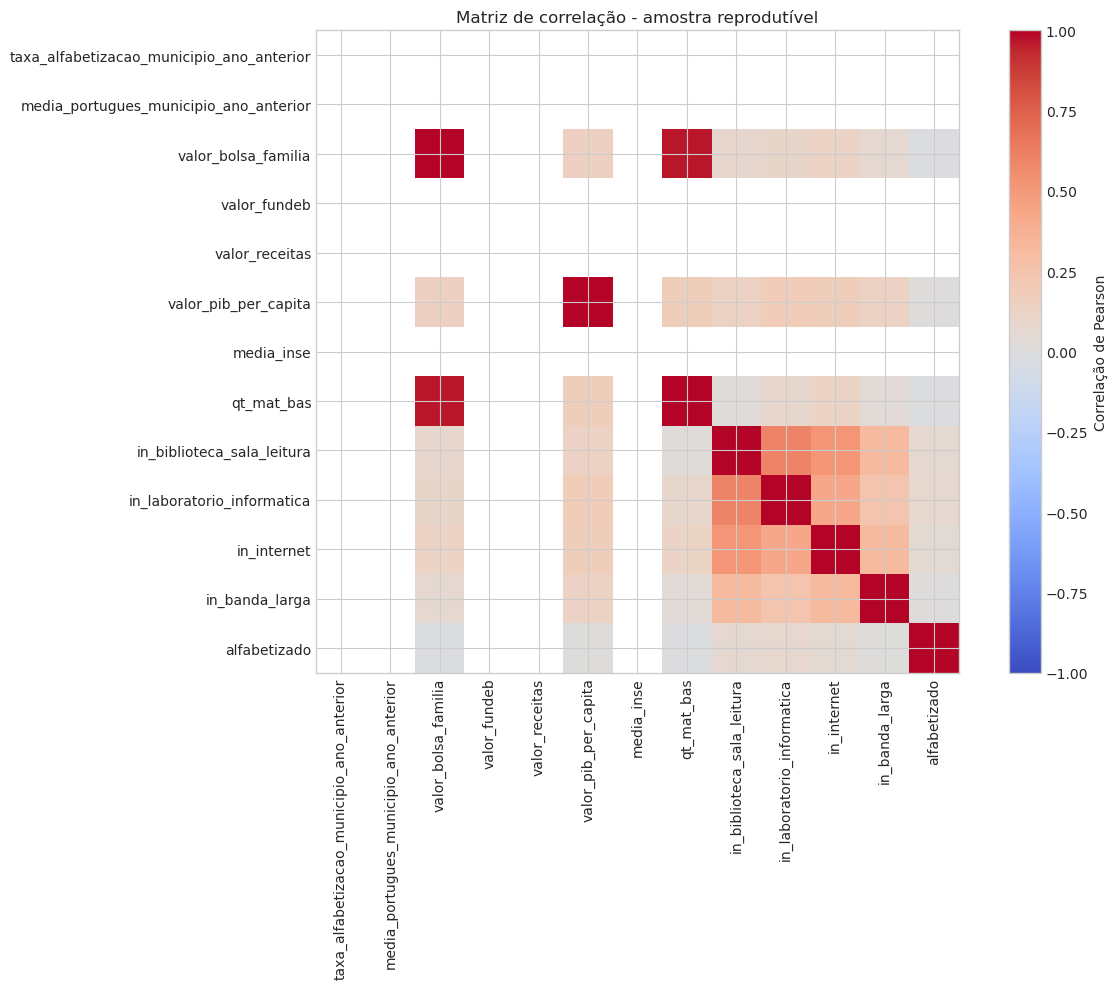

alfabetizado,taxa_alfabetizacao_municipio_ano_anterior__media,taxa_alfabetizacao_municipio_ano_anterior__mediana,media_portugues_municipio_ano_anterior__media,media_portugues_municipio_ano_anterior__mediana,valor_bolsa_familia__media,valor_bolsa_familia__mediana,valor_fundeb__media,valor_fundeb__mediana,valor_receitas__media,valor_receitas__mediana,valor_pib_per_capita__media,valor_pib_per_capita__mediana,media_inse__media,media_inse__mediana,qt_mat_bas__media,qt_mat_bas__mediana,in_internet__media,in_internet__mediana,in_biblioteca_sala_leitura__media,in_biblioteca_sala_leitura__mediana
i32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0,52.524938,52.2,739.974094,739.3033,4.8311e8,8.2065933e7,-7.1724e8,1.4971e8,5.4865e10,5.2082e9,49970.858879,39364.74,4.901466,4.920591,189254.263822,28897.0,0.939752,0.992624,0.578192,0.622449
1,59.767943,58.0,749.668175,746.3576,4.4037e8,5.8318002e7,-5.9367e8,1.4067e8,4.9676e10,4.0771e9,50163.076947,40350.57,4.937153,5.038918,174923.001202,21828.0,0.952242,0.994413,0.601334,0.631285


In [141]:
FEATURES_CORRELACAO = [
    "taxa_alfabetizacao_municipio_ano_anterior", "media_portugues_municipio_ano_anterior",
    "valor_bolsa_familia", "valor_fundeb", "valor_receitas",
    "valor_pib_per_capita", "media_inse", "qt_mat_bas",
    "in_biblioteca_sala_leitura", "in_laboratorio_informatica",
    "in_internet", "in_banda_larga", TARGET,
]
limite_hash_corr = max(1, round(FRACOES_AMOSTRAGEM["eda_correlacao"] * 10_000))
amostra_corr = (
    lf.filter((pl.col("id_aluno").hash(seed=SEED_GLOBAL) % 10_000) < limite_hash_corr)
    .select(FEATURES_CORRELACAO)
    .collect(engine="streaming")
)
matriz_corr = amostra_corr.corr()
plt.figure(figsize=(13, 10))
plt.imshow(matriz_corr.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlação de Pearson")
plt.xticks(range(len(matriz_corr.columns)), matriz_corr.columns, rotation=90)
plt.yticks(range(len(matriz_corr.columns)), matriz_corr.columns)
plt.title("Matriz de correlação - amostra reprodutível")
plt.tight_layout()
salvar_figura_eda(plt.gcf(), "297_4_3_relacoes_entre_features_e_target_01.png"); plt.show()

resumo_por_target = lf.group_by(TARGET).agg([
    expr for c in FEATURES_DISTRIBUICAO
    for expr in (pl.col(c).mean().alias(f"{c}__media"), pl.col(c).median().alias(f"{c}__mediana"))
]).sort(TARGET).collect()
display(resumo_por_target)


In [142]:
for coluna in CATEGORICAL_FEATURES:
    associacao = (
        lf.group_by([coluna, TARGET]).agg(pl.len().alias("quantidade"))
          .with_columns((100 * pl.col("quantidade") / pl.col("quantidade").sum().over(coluna)).round(2).alias("percentual_na_categoria"))
          .sort([coluna, TARGET]).collect()
    )
    print(f"\nAssociação de {coluna} com {TARGET}")
    display(associacao)



Associação de sigla_uf com alfabetizado


sigla_uf,alfabetizado,quantidade,percentual_na_categoria
str,i32,u32,f64
"""AC""",0,7344,58.03
"""AC""",1,5311,41.97
"""AL""",0,39133,56.57
"""AL""",1,30038,43.43
"""AM""",0,72843,59.87
"""AM""",1,48820,40.13
"""AP""",0,15018,60.24
"""AP""",1,9911,39.76
"""BA""",0,172390,68.06



Associação de rede com alfabetizado


rede,alfabetizado,quantidade,percentual_na_categoria
i32,i32,u32,f64
2,0,203976,46.85
2,1,231422,53.15
3,0,1679468,48.93
3,1,1753108,51.07
4,0,9,36.0
4,1,16,64.0


### 4.4 Recortes geográficos e de rede

Os resultados são descritivos. Diferenças entre grupos podem refletir composição, cobertura e participação; não demonstram efeito causal. Municípios são exibidos apenas quando possuem volume mínimo.


In [143]:
resumo_uf = lf.group_by("sigla_uf").agg(
    pl.len().alias("registros"),
    pl.col(TARGET).mean().alias("proporcao_alfabetizado"),
    pl.col("media_inse").mean().alias("media_inse"),
    pl.col("valor_pib_per_capita").mean().alias("pib_per_capita_medio"),
).sort("proporcao_alfabetizado", descending=True).collect()
display(resumo_uf)

resumo_rede = lf.group_by(["sigla_uf", "rede"]).agg(
    pl.len().alias("registros"),
    pl.col(TARGET).mean().alias("proporcao_alfabetizado"),
).sort(["sigla_uf", "registros"], descending=[False, True]).collect()
display(resumo_rede)

MIN_REGISTROS_MUNICIPIO = 500
resumo_municipio = lf.group_by(["id_municipio", "nome_municipio", "sigla_uf"]).agg(
    pl.len().alias("registros"),
    pl.col(TARGET).mean().alias("proporcao_alfabetizado"),
).filter(pl.col("registros") >= MIN_REGISTROS_MUNICIPIO).sort(
    "proporcao_alfabetizado", descending=True
).collect()
display(resumo_municipio.head(20))
display(resumo_municipio.tail(20))


sigla_uf,registros,proporcao_alfabetizado,media_inse,pib_per_capita_medio
str,u32,f64,f64,f64
"""CE""",190190,0.8211,4.396767,25163.876081
"""ES""",98020,0.625678,5.034294,52223.972404
"""GO""",160907,0.624702,5.127209,45820.226015
"""PR""",277446,0.622608,5.362918,55710.800054
"""MG""",413557,0.594436,5.103546,46402.706808
"""RO""",45507,0.565781,4.952906,45449.107718
"""PE""",168630,0.559788,4.494298,29116.4913
"""PI""",68207,0.532643,4.317957,23842.905066
"""MA""",144242,0.526393,4.368148,20903.997953


sigla_uf,rede,registros,proporcao_alfabetizado
str,i32,u32,f64
"""AC""",3,7098,0.395323
"""AC""",2,5557,0.450783
"""AL""",3,66031,0.438536
"""AL""",2,3140,0.344268
"""AM""",3,94032,0.370076
"""AM""",2,27631,0.507437
"""AP""",3,18214,0.415834
"""AP""",2,6715,0.348027
"""BA""",3,252748,0.319397


id_municipio,nome_municipio,sigla_uf,registros,proporcao_alfabetizado
i64,str,str,u32,f64
2304004,"""Coreaú""","""CE""",510,1.0
2310506,"""Pedra Branca""","""CE""",694,0.991354
2309409,"""Novo Oriente""","""CE""",759,0.985507
2312007,"""Santana do Acaraú""","""CE""",642,0.984424
2304236,"""Croatá""","""CE""",500,0.984
2305902,"""Ipueiras""","""CE""",883,0.983012
2201903,"""Bom Jesus""","""PI""",512,0.974609
2305001,"""Guaraciaba do Norte""","""CE""",1232,0.969968
2311959,"""Salitre""","""CE""",521,0.96737


id_municipio,nome_municipio,sigla_uf,registros,proporcao_alfabetizado
i64,str,str,u32,f64
2407104,"""Macaíba""","""RN""",1488,0.212366
2402600,"""Ceará-Mirim""","""RN""",1904,0.211134
2930105,"""Senhor do Bonfim""","""BA""",1025,0.206829
1502806,"""Curralinho""","""PA""",1439,0.205003
4218004,"""Tijucas""","""SC""",1472,0.203804
1505205,"""Oeiras do Pará""","""PA""",1076,0.201673
2910602,"""Esplanada""","""BA""",741,0.20108
2910503,"""Entre Rios""","""BA""",667,0.1994
2805406,"""Poço Redondo""","""SE""",763,0.199214


### 4.5 Relações temporais

A comparação é agregada por ano e não representa acompanhamento longitudinal garantido dos mesmos alunos. Mudanças também podem refletir cobertura diferente das fontes complementares.


In [144]:
resumo_temporal = lf.group_by("ano_referencia").agg(
    pl.len().alias("registros"),
    pl.col(TARGET).mean().alias("proporcao_alfabetizado"),
    *[pl.col(c).mean().alias(f"media__{c}") for c in [
        "taxa_alfabetizacao_municipio_ano_anterior", "media_portugues_municipio_ano_anterior",
        "valor_bolsa_familia", "valor_fundeb", "valor_receitas",
        "valor_pib_per_capita", "media_inse", "in_internet",
    ]],
).sort("ano_referencia").collect()
display(resumo_temporal)

resumo_uf_ano = lf.group_by(["ano_referencia", "sigla_uf"]).agg(
    pl.len().alias("registros"),
    pl.col(TARGET).mean().alias("proporcao_alfabetizado"),
).sort(["sigla_uf", "ano_referencia"]).collect()
display(resumo_uf_ano)

resumo_rede_ano = lf.group_by(["ano_referencia", "rede"]).agg(
    pl.len().alias("registros"),
    pl.col(TARGET).mean().alias("proporcao_alfabetizado"),
).sort(["rede", "ano_referencia"]).collect()
display(resumo_rede_ano)


ano_referencia,registros,proporcao_alfabetizado,media__taxa_alfabetizacao_municipio_ano_anterior,media__media_portugues_municipio_ano_anterior,media__valor_bolsa_familia,media__valor_fundeb,media__valor_receitas,media__valor_pib_per_capita,media__media_inse,media__in_internet
i64,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64
2023,1747439,0.502122,null,null,3.0974e8,4.0149e8,2.9606e10,43918.979755,4.868315,0.941589
2024,2120560,0.522088,56.315463,745.047354,5.8597e8,-1.5347e9,7.1076e10,55137.774789,4.96217,0.949927


ano_referencia,sigla_uf,registros,proporcao_alfabetizado
i64,str,u32,f64
2024,"""AC""",12655,0.419676
2023,"""AL""",35503,0.410782
2024,"""AL""",33668,0.459012
2023,"""AM""",63055,0.405709
2024,"""AM""",58608,0.396499
2023,"""AP""",12349,0.373229
2024,"""AP""",12580,0.421463
2023,"""BA""",137724,0.315747
2024,"""BA""",115576,0.323804


ano_referencia,rede,registros,proporcao_alfabetizado
i64,i32,u32,f64
2023,2,155140,0.51993
2024,2,280258,0.537933
2023,3,1592299,0.500387
2024,3,1840277,0.519673
2024,4,25,0.64


### 4.6 Fechamento do EDA

Decisões aplicadas na preparação:

- excluir variáveis da aplicação da avaliação por risco de leakage;
- manter somente `media_inse`, removendo os percentuais INSE correlacionados e composicionais;
- manter as proporções de infraestrutura e remover contagens redundantes de porte escolar;
- manter PIB per capita e remover PIB total;
- manter somente versões `signed_log1p` das variáveis financeiras;
- usar a fotografia municipal de INSE, Censo e PIB de 2023 também como contexto de 2024;
- excluir indicadores históricos municipais que não existem para 2023, evitando imputação de quase metade da base;
- não remover outliers municipais automaticamente; usar transformações robustas para valores financeiros;
- consolidar ausência em três flags de cobertura e imputar resíduos usando somente estatísticas do treino;
- manter chaves apenas para auditoria;
- deixar encoding e padronização dependentes do algoritmo dentro do pipeline de modelagem.


### 4.7 EDA e validação das metas oficiais

As metas oficiais são avaliadas como uma dimensão analítica separada. O target do modelo por aluno continua sendo `alfabetizado`; `meta_alfabetizacao` não entra nas features nem é usada no ajuste dos modelos. Depois da inferência, as probabilidades serão agregadas territorialmente e comparadas com esta referência.

Regras de granularidade:

- município: `id_municipio + rede=3 + ano_publicacao + ano_meta`;
- UF: `sigla_uf + rede=5 + ano_publicacao + ano_meta`;
- Brasil: `rede=5 + ano_publicacao + ano_meta`;
- rede 5 representa o agregado público das redes estadual (2) e municipal (3); não deve ser ligada diretamente a uma linha de aluno.


In [145]:
METAS_INPUT_ROOT = PROJECT_ROOT / "dados" / "fontes_originais" / "complementar" / "metas_alfabetizacao_oficiais"
METAS_OUTPUT_DIR = DADOS_PROCESSADOS_DIR / "preparado" / "metas_alfabetizacao_validadas"
METAS_MANIFEST_PATH = METAS_OUTPUT_DIR.parent / "manifesto_metas_alfabetizacao.json"

METAS_PATHS = {
    "municipio": METAS_INPUT_ROOT / "metas_vs_resultado_municipio",
    "uf": METAS_INPUT_ROOT / "metas_vs_resultado_uf",
    "brasil": METAS_INPUT_ROOT / "metas_vs_resultado_brasil",
}

def scan_meta(diretorio: Path) -> pl.LazyFrame:
    arquivos_meta = sorted(diretorio.glob("ano=*/*.parquet"))
    if not arquivos_meta:
        raise FileNotFoundError(f"Nenhum Parquet de metas localizado em {diretorio}")
    return pl.scan_parquet([str(p) for p in arquivos_meta], hive_partitioning=True)

metas_municipio = scan_meta(METAS_PATHS["municipio"])
metas_uf = scan_meta(METAS_PATHS["uf"])
metas_brasil = scan_meta(METAS_PATHS["brasil"])

for nome, frame in {
    "municipio": metas_municipio,
    "uf": metas_uf,
    "brasil": metas_brasil,
}.items():
    print(nome, frame.collect_schema().names())


municipio ['nivel_geografico', 'id_municipio', 'nome_municipio', 'sigla_uf', 'ano_observacao', 'serie', 'serie_descricao', 'rede', 'rede_descricao', 'taxa_alfabetizacao', 'qtd_alunos', 'origem_indicador', 'escopo_meta', 'ano_meta', 'meta_alfabetizacao', 'gap_pp', 'percentual_da_meta', 'atingiu_meta', 'meta_ja_vencida', 'processed_at', 'ano']
uf ['nivel_geografico', 'sigla_uf', 'ano_observacao', 'serie', 'serie_descricao', 'rede', 'rede_descricao', 'taxa_alfabetizacao', 'qtd_alunos', 'origem_indicador', 'escopo_meta', 'ano_meta', 'meta_alfabetizacao', 'gap_pp', 'percentual_da_meta', 'atingiu_meta', 'meta_ja_vencida', 'processed_at', 'ano']
brasil ['nivel_geografico', 'ano_observacao', 'serie', 'serie_descricao', 'rede', 'rede_descricao', 'taxa_alfabetizacao', 'qtd_alunos', 'origem_indicador', 'escopo_meta', 'ano_meta', 'meta_alfabetizacao', 'gap_pp', 'percentual_da_meta', 'atingiu_meta', 'meta_ja_vencida', 'processed_at', 'ano']


In [146]:
def resumo_qualidade_meta(nome: str, frame: pl.LazyFrame) -> pl.DataFrame:
    return frame.select(
        pl.lit(nome).alias("base"),
        pl.len().alias("registros"),
        pl.col("ano_observacao").min().alias("ano_observacao_min"),
        pl.col("ano_observacao").max().alias("ano_observacao_max"),
        pl.col("ano_meta").min().alias("ano_meta_min"),
        pl.col("ano_meta").max().alias("ano_meta_max"),
        pl.col("meta_alfabetizacao").null_count().alias("metas_nulas"),
        ((pl.col("meta_alfabetizacao") < 0) | (pl.col("meta_alfabetizacao") > 100)).sum().alias("metas_fora_0_100"),
    ).collect()

resumo_metas = pl.concat([
    resumo_qualidade_meta("municipio", metas_municipio),
    resumo_qualidade_meta("uf", metas_uf),
    resumo_qualidade_meta("brasil", metas_brasil),
])
display(resumo_metas)

assert resumo_metas["metas_nulas"].sum() == 0, "Existem metas nulas."
assert resumo_metas["metas_fora_0_100"].sum() == 0, "Existem metas fora do intervalo percentual."

redes_por_escopo = pl.concat([
    metas_municipio.select("escopo_meta", "rede", "rede_descricao"),
    metas_uf.select("escopo_meta", "rede", "rede_descricao"),
    metas_brasil.select("escopo_meta", "rede", "rede_descricao"),
]).unique().sort(["escopo_meta", "rede"]).collect()
display(redes_por_escopo)

assert set(
    redes_por_escopo.filter(pl.col("escopo_meta") == "municipio")["rede"].to_list()
) == {3}
assert set(
    redes_por_escopo.filter(pl.col("escopo_meta").is_in(["uf", "brasil"]))["rede"].to_list()
) == {5}


base,registros,ano_observacao_min,ano_observacao_max,ano_meta_min,ano_meta_max,metas_nulas,metas_fora_0_100
str,u32,i32,i32,i32,i32,u32,u32
"""municipio""",147650,2023,2024,2024,2030,0,0
"""uf""",685,2023,2024,2024,2030,0,0
"""brasil""",14,2023,2024,2024,2030,0,0


escopo_meta,rede,rede_descricao
str,i32,str
"""brasil""",5,"""Pública (Estadual e Municipal)"""
"""municipio""",3,"""Municipal"""
"""uf""",5,"""Pública (Estadual e Municipal)"""


In [147]:
metas_municipais_ids = (
    metas_municipio
    .filter((pl.col("escopo_meta") == "municipio") & (pl.col("rede") == 3))
    .select(pl.col("id_municipio").cast(pl.String))
    .unique()
    .with_columns(pl.lit(True).alias("tem_meta_municipal"))
)

municipios_tc3_rede_municipal = (
    lf.filter(pl.col("rede") == 3)
    .select(
        pl.col("id_municipio").cast(pl.String),
        pl.col("nome_municipio"),
        pl.col("sigla_uf"),
    )
    .unique()
)

cobertura_municipal = (
    municipios_tc3_rede_municipal
    .join(metas_municipais_ids, on="id_municipio", how="left")
    .with_columns(pl.col("tem_meta_municipal").fill_null(False))
)

resumo_cobertura_municipal = cobertura_municipal.select(
    pl.len().alias("municipios_tc3_rede_municipal"),
    pl.col("tem_meta_municipal").sum().alias("municipios_com_meta"),
    (~pl.col("tem_meta_municipal")).sum().alias("municipios_sem_meta"),
    pl.col("tem_meta_municipal").mean().alias("proporcao_coberta"),
).collect()
display(resumo_cobertura_municipal)

municipios_sem_meta = (
    cobertura_municipal.filter(~pl.col("tem_meta_municipal"))
    .select("id_municipio", "nome_municipio", "sigla_uf")
    .sort(["sigla_uf", "nome_municipio"])
    .collect()
)
display(municipios_sem_meta.head(30))

ufs_tc3 = set(lf.select(pl.col("sigla_uf").drop_nulls().unique()).collect()["sigla_uf"].to_list())
ufs_meta = set(
    metas_uf.filter(pl.col("escopo_meta") == "uf")
    .select(pl.col("sigla_uf").drop_nulls().unique())
    .collect()["sigla_uf"].to_list()
)
ufs_sem_meta_propria = sorted(ufs_tc3 - ufs_meta)
display(pl.DataFrame({
    "uf_sem_meta_propria": ufs_sem_meta_propria,
    "tratamento": [
        "Distrito Federal: usar somente a referência Brasil/rede pública; a fonte não publica meta no escopo UF."
        if uf == "DF" else "Revisar ausência não prevista"
        for uf in ufs_sem_meta_propria
    ],
}))

# O Distrito Federal não é dividido em municípios e, na base do TC3, aparece
# somente como rede estadual (2). A fonte oficial não trouxe linha de escopo UF
# para DF; há, porém, a trajetória Brasil/rede pública (5). A exceção é
# documentada, não imputada como se fosse uma meta própria do DF.
EXCECOES_UF_SEM_META_PROPRIA = {"DF"}
ausencias_uf_inesperadas = set(ufs_sem_meta_propria) - EXCECOES_UF_SEM_META_PROPRIA
assert not ausencias_uf_inesperadas, (
    f"Há UFs sem referência oficial e sem regra documentada: {sorted(ausencias_uf_inesperadas)}"
)
assert metas_brasil.filter(
    (pl.col("escopo_meta") == "brasil") & (pl.col("rede") == 5)
).select(pl.len()).collect().item() > 0, "A referência Brasil/rede pública está ausente."


municipios_tc3_rede_municipal,municipios_com_meta,municipios_sem_meta,proporcao_coberta
u32,u32,u32,f64
5498,5352,146,0.973445


id_municipio,nome_municipio,sigla_uf
str,str,str
"""1300300""","""Autazes""","""AM"""
"""1300631""","""Beruri""","""AM"""
"""1300904""","""Canutama""","""AM"""
"""1301100""","""Careiro""","""AM"""
"""1301407""","""Eirunepé""","""AM"""
"""1301605""","""Fonte Boa""","""AM"""
"""1302009""","""Itapiranga""","""AM"""
"""2904753""","""Buritirama""","""BA"""
"""2904852""","""Cabaceiras do Paraguaçu""","""BA"""


uf_sem_meta_propria,tratamento
str,str
"""DF""","""Distrito Federal: usar somente…"


escopo_meta,ano_publicacao,ano_meta,referencias,meta_min,meta_mediana,meta_max
str,i32,i32,u32,f64,f64,f64
"""brasil""",2023,2024,1,59.9,59.9,59.9
"""brasil""",2023,2025,1,63.77,63.77,63.77
"""brasil""",2023,2026,1,67.47,67.47,67.47
"""brasil""",2023,2027,1,70.97,70.97,70.97
"""brasil""",2023,2028,1,74.23,74.23,74.23
"""brasil""",2023,2029,1,77.24,77.24,77.24
"""brasil""",2023,2030,1,80.0,80.0,80.0
"""brasil""",2024,2024,1,59.9,59.9,59.9
"""brasil""",2024,2025,1,63.77,63.77,63.77


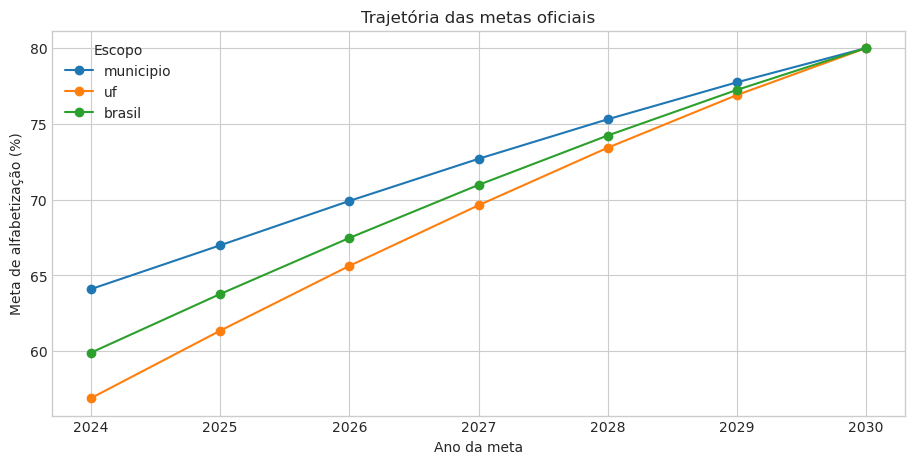

In [148]:
metas_municipio_ref = (
    metas_municipio.filter(pl.col("escopo_meta") == "municipio")
    .select(
        pl.lit("municipio").alias("escopo_meta"),
        pl.col("id_municipio").cast(pl.String),
        pl.col("sigla_uf").cast(pl.String),
        pl.col("rede").cast(pl.Int32),
        pl.col("rede_descricao"),
        pl.col("ano_observacao").cast(pl.Int32).alias("ano_publicacao"),
        pl.col("ano_meta").cast(pl.Int32),
        pl.col("meta_alfabetizacao").cast(pl.Float64),
        pl.lit("metas_vs_resultado_municipio").alias("produto_origem"),
    )
)

metas_uf_ref = (
    metas_uf.filter(pl.col("escopo_meta") == "uf")
    .select(
        pl.lit("uf").alias("escopo_meta"),
        pl.lit(None, dtype=pl.String).alias("id_municipio"),
        pl.col("sigla_uf").cast(pl.String),
        pl.col("rede").cast(pl.Int32),
        pl.col("rede_descricao"),
        pl.col("ano_observacao").cast(pl.Int32).alias("ano_publicacao"),
        pl.col("ano_meta").cast(pl.Int32),
        pl.col("meta_alfabetizacao").cast(pl.Float64),
        pl.lit("metas_vs_resultado_uf").alias("produto_origem"),
    )
)

metas_brasil_ref = (
    metas_brasil.filter(pl.col("escopo_meta") == "brasil")
    .select(
        pl.lit("brasil").alias("escopo_meta"),
        pl.lit(None, dtype=pl.String).alias("id_municipio"),
        pl.lit(None, dtype=pl.String).alias("sigla_uf"),
        pl.col("rede").cast(pl.Int32),
        pl.col("rede_descricao"),
        pl.col("ano_observacao").cast(pl.Int32).alias("ano_publicacao"),
        pl.col("ano_meta").cast(pl.Int32),
        pl.col("meta_alfabetizacao").cast(pl.Float64),
        pl.lit("metas_vs_resultado_brasil").alias("produto_origem"),
    )
)

metas_canonicas = pl.concat(
    [metas_municipio_ref, metas_uf_ref, metas_brasil_ref],
    how="diagonal_relaxed",
)

CHAVE_META = [
    "escopo_meta", "id_municipio", "sigla_uf", "rede",
    "ano_publicacao", "ano_meta",
]
duplicidades_meta = (
    metas_canonicas.group_by(CHAVE_META).len()
    .filter(pl.col("len") > 1)
    .collect()
)
assert duplicidades_meta.is_empty(), f"Chaves duplicadas na referência de metas: {duplicidades_meta}"
assert metas_canonicas.filter(pl.col("ano_meta") < pl.col("ano_publicacao")).select(pl.len()).collect().item() == 0

evolucao_metas = (
    metas_canonicas.group_by("escopo_meta", "ano_publicacao", "ano_meta")
    .agg(
        pl.len().alias("referencias"),
        pl.col("meta_alfabetizacao").min().alias("meta_min"),
        pl.col("meta_alfabetizacao").median().alias("meta_mediana"),
        pl.col("meta_alfabetizacao").max().alias("meta_max"),
    )
    .sort(["escopo_meta", "ano_publicacao", "ano_meta"])
    .collect()
)
display(evolucao_metas)

fig, ax = plt.subplots(figsize=(11, 5))
for escopo in ["municipio", "uf", "brasil"]:
    serie = (
        evolucao_metas.filter(pl.col("escopo_meta") == escopo)
        .group_by("ano_meta")
        .agg(pl.col("meta_mediana").mean().alias("meta_mediana"))
        .sort("ano_meta")
    )
    ax.plot(serie["ano_meta"], serie["meta_mediana"], marker="o", label=escopo)
ax.set(title="Trajetória das metas oficiais", xlabel="Ano da meta", ylabel="Meta de alfabetização (%)")
ax.legend(title="Escopo")
salvar_figura_eda(plt.gcf(), "308_4_7_eda_e_validacao_das_metas_oficiais_01.png"); plt.show()


In [149]:
METAS_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
arquivos_metas_existentes = list(METAS_OUTPUT_DIR.rglob("*.parquet"))

if deve_recalcular(METAS_OUTPUT_DIR) or not arquivos_metas_existentes:
    quantidade_publicada = publicar_parquet_particionado(
        metas_canonicas, METAS_OUTPUT_DIR, particionar_por="escopo_meta"
    )
    print(f"Referência canônica de metas gravada: {quantidade_publicada} arquivo(s).")
else:
    metas_publicadas = pl.scan_parquet(
        str(METAS_OUTPUT_DIR / "escopo_meta=*" / "*.parquet"),
        hive_partitioning=True,
    )
    assert metas_publicadas.collect_schema().names() == metas_canonicas.collect_schema().names()
    print(f"Referência existente validada e reutilizada: {len(arquivos_metas_existentes)} arquivos.")

resumo_canonico = metas_canonicas.select(
    pl.len().alias("registros"),
    pl.col("escopo_meta").n_unique().alias("escopos"),
    pl.col("ano_meta").min().alias("ano_meta_min"),
    pl.col("ano_meta").max().alias("ano_meta_max"),
).collect()

manifesto_metas = {
    "produto": "metas_alfabetizacao_validadas_tc3",
    "versao_contrato": 1,
    "uso": "referencia_pos_modelagem; nao utilizar como feature do modelo por aluno",
    "fontes": [str(path.relative_to(PROJECT_ROOT)).replace("\\", "/") for path in METAS_PATHS.values()],
    "caminho_relativo": str(METAS_OUTPUT_DIR.relative_to(PROJECT_ROOT)).replace("\\", "/"),
    "graos": {
        "municipio": "id_municipio + rede=3 + ano_publicacao + ano_meta",
        "uf": "sigla_uf + rede=5 + ano_publicacao + ano_meta",
        "brasil": "rede=5 + ano_publicacao + ano_meta",
    },
    "registros": resumo_canonico["registros"].item(),
    "ano_meta_min": resumo_canonico["ano_meta_min"].item(),
    "ano_meta_max": resumo_canonico["ano_meta_max"].item(),
    "municipios_tc3_rede_municipal": resumo_cobertura_municipal["municipios_tc3_rede_municipal"].item(),
    "municipios_com_meta": resumo_cobertura_municipal["municipios_com_meta"].item(),
    "municipios_sem_meta": resumo_cobertura_municipal["municipios_sem_meta"].item(),
}
METAS_MANIFEST_PATH.write_text(
    json.dumps(manifesto_metas, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
print(f"Metas validadas: {METAS_OUTPUT_DIR}")
print(f"Manifesto: {METAS_MANIFEST_PATH}")


Referência canônica de metas gravada: 3 arquivo(s).
Metas validadas: /workspace/dados/dados_processados/preparado/metas_alfabetizacao_validadas
Manifesto: /workspace/dados/dados_processados/preparado/manifesto_metas_alfabetizacao.json


#### Decisão metodológica sobre as metas

O EDA das metas não altera o contrato da base de modelagem. A referência canônica será consumida somente após a inferência:

1. gerar probabilidades individuais de alfabetização;
2. agregar as probabilidades no grão compatível com a meta;
3. para município, comparar somente a rede municipal (`rede=3`);
4. para UF e Brasil, combinar as redes estadual e municipal antes de comparar com a rede pública agregada (`rede=5`);
5. escolher a revisão da meta que já estava publicada no ano da previsão;
6. registrar separadamente territórios sem correspondência, sem imputar metas oficiais.

Os campos `gap_pp`, `atingiu_meta` e `meta_ja_vencida` das tabelas de origem descrevem resultados históricos. Eles não são transportados para a referência canônica porque deverão ser recalculados sobre as previsões do modelo.


## 5. Preparação sem vazamento entre splits

Antes da preparação, a rede privada (`rede = 4`) é excluída do produto de modelagem: são apenas 25 registros, todos de 2024 e concentrados em uma única escola anonimizada de Gurupi/TO. Essa cobertura não sustenta aprendizado ou avaliação representativa da rede privada. A camada consolidada permanece intacta e a decisão restringe explicitamente o escopo do modelo às redes estadual e municipal.

Valores ausentes recebem uma flag explícita. A mediana usada na imputação é calculada somente no treino. Variáveis categóricas ausentes recebem `DESCONHECIDO`. Valores financeiros são preservados e recebem também uma transformação logarítmica com sinal, adequada inclusive para valores negativos de Fundeb.

Encoding e padronização dependentes do algoritmo devem ser ajustados posteriormente dentro do pipeline de treinamento, nunca sobre a base completa.


In [150]:
valores_split = lf.select(pl.col("dataset_split").drop_nulls().unique().sort()).collect()["dataset_split"].to_list()
print("Valores de dataset_split:", valores_split)
train_candidates = [v for v in valores_split if str(v).strip().lower() in {"train", "treino", "training"}]
if len(train_candidates) != 1:
    raise ValueError("Não foi possível identificar unicamente o conjunto de treino em dataset_split.")
TRAIN_LABEL = train_candidates[0]

# A rede privada tem somente 25 observações de uma escola em Gurupi/TO. Ela é
# preservada na camada consolidada, mas retirada do escopo de modelagem.
base_escopo = lf.filter(~pl.col("rede").is_in(list(EXCLUDED_NETWORKS)))
total_modelagem = base_escopo.select(pl.len()).collect().item()
registros_excluidos_rede = total - total_modelagem
assert registros_excluidos_rede == 25, f"Quantidade inesperada excluída por rede: {registros_excluidos_rede}"
print(f"Registros fora do escopo de modelagem: {registros_excluidos_rede}")
print(f"Registros no escopo estadual/municipal: {total_modelagem:,}")

# INSE, Censo e PIB de 2023 são uma fotografia contextual. Para 2024, usa-se a
# referência municipal de 2023, sem recorrer a informação futura.
CHAVES_CONTEXTO = ["id_municipio", "sigla_uf"]
referencia_2023 = (
    base_escopo.filter(pl.col("ano_referencia") == 2023)
      .group_by(CHAVES_CONTEXTO)
      .agg([pl.col(c).drop_nulls().first().alias(f"{c}__ref_2023") for c in STATIC_2023_FEATURES])
)
base_enriquecida = (
    base_escopo.join(referencia_2023, on=CHAVES_CONTEXTO, how="left", validate="m:1")
      .with_columns([pl.coalesce([pl.col(c), pl.col(f"{c}__ref_2023")]).alias(c) for c in STATIC_2023_FEATURES])
      .drop([f"{c}__ref_2023" for c in STATIC_2023_FEATURES])
)

medianas_treino = (
    base_enriquecida.filter(pl.col("dataset_split") == TRAIN_LABEL)
      .select([pl.col(c).cast(pl.Float64, strict=False).median().alias(c) for c in FINAL_SOURCE_FEATURES if c != "ano_referencia"])
      .collect()
      .row(0, named=True)
)
medianas_treino


Valores de dataset_split: ['teste', 'treino', 'validacao']
Registros fora do escopo de modelagem: 25
Registros no escopo estadual/municipal: 3,867,974


{'valor_bolsa_familia': 69476037.0,
 'valor_fundeb': 145010051.03,
 'valor_receitas': 4588630098.32,
 'valor_pib_per_capita': 40059.08,
 'media_inse': 4.999194373401535,
 'in_biblioteca_sala_leitura': 0.625,
 'in_laboratorio_informatica': 0.3503861003861004,
 'in_quadra_esportes': 0.4603174603174603,
 'in_agua_rede_publica': 0.9285714285714286,
 'in_energia_rede_publica': 1.0,
 'in_esgoto_rede_publica': 0.71875,
 'in_internet': 0.9931053502482073,
 'in_banda_larga': 0.9302325581395349}

In [151]:
MONETARY_COLUMNS = CURRENT_FINANCIAL_FEATURES + ["valor_pib_per_capita"]
base_rastreavel = base_enriquecida.with_columns(
    pl.concat_str(
        [
            pl.col("ano_referencia").cast(pl.String),
            pl.col("id_municipio").cast(pl.String),
            pl.col("id_escola").cast(pl.String),
        ],
        separator="|",
    ).alias("chave_escola_ano")
)
prepared = (
    base_rastreavel.select(KEY_COLUMNS + CONTROL_COLUMNS + CATEGORICAL_FEATURES + FINAL_SOURCE_FEATURES + [TARGET])
      .with_columns(
          pl.any_horizontal([pl.col(c).is_null() for c in CURRENT_FINANCIAL_FEATURES]).cast(pl.Int8).alias("cobertura_financeira_ausente"),
          pl.col("media_inse").is_null().cast(pl.Int8).alias("cobertura_inse_ausente"),
      )
      .with_columns([pl.col(c).cast(pl.Float64, strict=False).fill_null(medianas_treino[c]).alias(c) for c in FINAL_SOURCE_FEATURES if c != "ano_referencia"])
      .with_columns([pl.col(c).cast(pl.String).fill_null("DESCONHECIDO").alias(c) for c in CATEGORICAL_FEATURES])
      .with_columns([
          (pl.col(c).sign() * (pl.col(c).abs() + 1).log()).alias(f"{c}__signed_log1p")
          for c in MONETARY_COLUMNS
      ])
      .select(KEY_COLUMNS + CONTROL_COLUMNS + [TARGET] + FINAL_MODEL_FEATURES)
)

prepared_schema = prepared.collect_schema()
print(f"Colunas da base preparada: {len(prepared_schema)}")
print(prepared_schema.names())


Colunas da base preparada: 24
['id_aluno', 'id_municipio', 'id_escola', 'chave_escola_ano', 'dataset_split', 'alfabetizado', 'sigla_uf', 'rede', 'ano_referencia', 'valor_bolsa_familia__signed_log1p', 'valor_fundeb__signed_log1p', 'valor_receitas__signed_log1p', 'valor_pib_per_capita__signed_log1p', 'media_inse', 'in_biblioteca_sala_leitura', 'in_laboratorio_informatica', 'in_quadra_esportes', 'in_agua_rede_publica', 'in_energia_rede_publica', 'in_esgoto_rede_publica', 'in_internet', 'in_banda_larga', 'cobertura_financeira_ausente', 'cobertura_inse_ausente']


## 6. Validações da base preparada

O fluxo valida explicitamente as 25 exclusões de escopo da rede privada e falha se perder qualquer outra linha, mantiver uma coluna de leakage ou produzir nulos nas features finais.


In [152]:
MODEL_FEATURE_COLUMNS = [
    c for c in prepared_schema.names()
    if c not in KEY_COLUMNS + CONTROL_COLUMNS + [TARGET]
]
assert MODEL_FEATURE_COLUMNS == FINAL_MODEL_FEATURES, (
    "O esquema preparado diverge do contrato final. "
    f"Esperado: {FINAL_MODEL_FEATURES}; obtido: {MODEL_FEATURE_COLUMNS}"
)
leakage_presente = sorted(set(LEAKAGE_COLUMNS) & set(prepared_schema.names()))
assert not leakage_presente, f"Colunas de leakage na base preparada: {leakage_presente}"

validacao = prepared.select(
    pl.len().alias("registros"),
    pl.col(TARGET).null_count().alias("target_nulo"),
    pl.sum_horizontal([pl.col(c).null_count() for c in MODEL_FEATURE_COLUMNS]).alias("nulos_features"),
).collect()
display(validacao)
assert validacao["registros"].item() == total_modelagem, "A preparação alterou a quantidade de linhas além da exclusão documentada."
assert prepared.filter(pl.col("rede") == "4").select(pl.len()).collect().item() == 0, "A rede privada permaneceu na base preparada."
assert validacao["target_nulo"].item() == 0, "O target contém nulos."
assert validacao["nulos_features"].item() == 0, "Ainda existem nulos nas features preparadas."
assert len(MODEL_FEATURE_COLUMNS) == len(FINAL_MODEL_FEATURES), f"Quantidade inesperada de features: {len(MODEL_FEATURE_COLUMNS)}"
assert set(["id_escola", "chave_escola_ano"]).issubset(KEY_COLUMNS)
assert not set(["id_escola", "chave_escola_ano"]) & set(MODEL_FEATURE_COLUMNS)

cardinalidade_final = prepared.select([pl.col(c).n_unique().alias(c) for c in MODEL_FEATURE_COLUMNS]).collect()
constantes = [c for c in MODEL_FEATURE_COLUMNS if cardinalidade_final[c].item() <= 1]
assert not constantes, f"Features constantes encontradas: {constantes}"
print(f"Contrato final validado: {len(MODEL_FEATURE_COLUMNS)} features, nenhuma constante, nenhum leakage e chaves escolares fora do modelo.")


registros,target_nulo,nulos_features
u32,u32,u32
3867974,0,0


Contrato final validado: 18 features, nenhuma constante, nenhum leakage e chaves escolares fora do modelo.


### 6.1 Auditoria da chave escolar anual

`chave_escola_ano` é uma chave técnica formada por ano, município e `id_escola`.
Ela serve para agrupamento e validação dentro de uma edição, mas não identifica a
escola real e não estabelece continuidade entre 2023 e 2024.


In [153]:
assert prepared.select(pl.col("id_escola").null_count()).collect().item() == 0
assert prepared.select(pl.col("chave_escola_ano").null_count()).collect().item() == 0

auditoria_chave_escola = prepared.select(
    pl.len().alias("registros"),
    pl.col("id_escola").n_unique().alias("ids_escola_distintos"),
    pl.col("chave_escola_ano").n_unique().alias("escolas_ano_distintas"),
).collect()
display(auditoria_chave_escola)

escolas_por_split = {
    split: set(
        prepared.filter(pl.col("dataset_split") == split)
        .select("chave_escola_ano").unique().collect()["chave_escola_ano"].to_list()
    )
    for split in ["treino", "validacao", "teste"]
}
sobreposicao_escolas = pl.DataFrame([
    {"pares": "treino x validacao", "escolas_ano_em_comum": len(escolas_por_split["treino"] & escolas_por_split["validacao"])},
    {"pares": "treino x teste", "escolas_ano_em_comum": len(escolas_por_split["treino"] & escolas_por_split["teste"])},
    {"pares": "validacao x teste", "escolas_ano_em_comum": len(escolas_por_split["validacao"] & escolas_por_split["teste"])},
])
display(sobreposicao_escolas)
print("A sobreposição é apenas diagnosticada: o split oficial atual é por aluno.")
print(f"Uma validação futura por escola/ano deverá construir splits agrupados sem alterar as {len(MODEL_FEATURE_COLUMNS)} features.")


registros,ids_escola_distintos,escolas_ano_distintas
u32,u32,u32
3867974,42811,79272


pares,escolas_ano_em_comum
str,i64
"""treino x validacao""",77177
"""treino x teste""",77120
"""validacao x teste""",75177


A sobreposição é apenas diagnosticada: o split oficial atual é por aluno.
Uma validação futura por escola/ano deverá construir splits agrupados sem alterar as 18 features.


## 7. Persistência dos produtos

A execução grava uma nova camada em `dados/dados_processados/preparado`, particionada por UF, além do contrato de decisões e do catálogo do produto final. A pasta do TC3-82 permanece intacta. A publicação contém somente as redes estadual e municipal.


In [154]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DECISION_PATH.parent.mkdir(parents=True, exist_ok=True)

# Se a saída já existe, ela é validada e reutilizada. A regeneração deve ser uma decisão explícita.
arquivos_saida_existentes = list(OUTPUT_DIR.rglob("*.parquet"))
if deve_recalcular(OUTPUT_DIR) or not arquivos_saida_existentes:
    quantidade_publicada = publicar_parquet_particionado(
        prepared, OUTPUT_DIR, particionar_por="sigla_uf"
    )
    print(f"Nova base preparada gravada: {quantidade_publicada} arquivo(s).")
else:
    print(f"Saída existente reutilizada: {len(arquivos_saida_existentes)} arquivos.")
decisoes.write_csv(DECISION_PATH)

catalogo_final = pl.DataFrame([
    {
        "coluna": c,
        "tipo": str(prepared_schema[c]),
        "papel": ("target" if c == TARGET else "chave" if c in KEY_COLUMNS else "controle" if c in CONTROL_COLUMNS else "feature_derivada" if c.endswith(("__ausente", "__signed_log1p")) else "feature"),
    }
    for c in prepared_schema.names()
])
catalogo_final.write_csv(DATA_DICTIONARY_PATH)
print(f"Base preparada: {OUTPUT_DIR}")
print(f"Decisões: {DECISION_PATH}")
print(f"Catálogo: {DATA_DICTIONARY_PATH}")


Nova base preparada gravada: 26 arquivo(s).
Base preparada: /workspace/dados/dados_processados/preparado/base_modelagem_final_com_chave_escola_por_uf
Decisões: /workspace/resultados/tabelas/dicionario_dados/decisoes_features_modelagem_com_chave_escola.csv
Catálogo: /workspace/resultados/tabelas/dicionario_dados/base_modelagem_catalogo_com_chave_escola.csv


## 8. Disponibilização para os próximos notebooks

A base preparada é publicada com um manifesto legível por máquina. Novos notebooks devem localizar o projeto, ler o manifesto e usar o padrão Parquet informado, evitando caminhos locais fixos e evitando retornar à base consolidada de 49 colunas sem justificativa.


In [155]:
OUTPUT_GLOB = str(OUTPUT_DIR / "sigla_uf=*" / "*.parquet")
base_publicada = pl.scan_parquet(OUTPUT_GLOB, hive_partitioning=True)
schema_publicado = base_publicada.collect_schema()
validacao_publicacao = base_publicada.select(
    pl.len().alias("registros"),
    pl.col("sigla_uf").n_unique().alias("ufs"),
    pl.col(TARGET).null_count().alias("target_nulo"),
).collect()
assert validacao_publicacao["registros"].item() == total_modelagem
assert base_publicada.filter(pl.col("rede") == "4").select(pl.len()).collect().item() == 0
assert validacao_publicacao["ufs"].item() == 26
assert schema_publicado.names() == prepared_schema.names()
display(validacao_publicacao)

manifesto = {
    "produto": "base_modelagem_final_tc3_com_chave_escola",
    "versao_contrato": 4,
    "escopo_redes": ["2 - Estadual", "3 - Municipal"],
    "exclusoes_escopo": {"rede_4_privada": registros_excluidos_rede},
    "formato": "parquet_particionado",
    "caminho_relativo": str(OUTPUT_DIR.relative_to(PROJECT_ROOT)).replace("\\", "/"),
    "padrao_leitura": str((OUTPUT_DIR / "sigla_uf=*" / "*.parquet").relative_to(PROJECT_ROOT)).replace("\\", "/"),
    "particionamento": ["sigla_uf"],
    "registros": validacao_publicacao["registros"].item(),
    "quantidade_colunas": len(schema_publicado),
    "target": TARGET,
    "controle_split": "dataset_split",
    "chaves_rastreabilidade": KEY_COLUMNS,
    "semantica_chave_escola": "agrupamento anonimo anual; nao identifica escola real nem garante continuidade entre anos",
    "features_modelagem": [c for c in schema_publicado.names() if c not in KEY_COLUMNS + CONTROL_COLUMNS + [TARGET]],
    "catalogo_relativo": str(DATA_DICTIONARY_PATH.relative_to(PROJECT_ROOT)).replace("\\", "/"),
    "decisoes_relativo": str(DECISION_PATH.relative_to(PROJECT_ROOT)).replace("\\", "/"),
}
MANIFEST_PATH = OUTPUT_DIR.parent / "manifesto_base_modelagem_com_chave_escola.json"
MANIFEST_PATH.write_text(json.dumps(manifesto, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Manifesto publicado em: {MANIFEST_PATH}")


registros,ufs,target_nulo
u32,u32,u32
3867974,26,0


Manifesto publicado em: /workspace/dados/dados_processados/preparado/manifesto_base_modelagem_com_chave_escola.json


### Célula padrão para novos notebooks

Copie a célula seguinte para qualquer etapa de modelagem. Ela lê o manifesto, resolve o caminho a partir da raiz do repositório e devolve um `LazyFrame`.


In [156]:
from pathlib import Path
import json
import polars as pl

def carregar_base_modelagem() -> tuple[pl.LazyFrame, dict]:
    manifesto_path = DADOS_PROCESSADOS_DIR / "preparado" / "manifesto_base_modelagem_com_chave_escola.json"
    if not manifesto_path.exists():
        raise FileNotFoundError("Manifesto da base preparada não localizado. Execute as etapas anteriores.")
    contrato = json.loads(manifesto_path.read_text(encoding="utf-8"))
    # O manifesto sempre registra o caminho relativo à raiz do projeto,
    # inclusive quando os artefatos ficam na área temporária da sessão.
    padrao = PROJECT_ROOT / Path(contrato["padrao_leitura"])
    return pl.scan_parquet(str(padrao), hive_partitioning=True), contrato

dados_modelagem, contrato_modelagem = carregar_base_modelagem()
print(contrato_modelagem["produto"], contrato_modelagem["registros"], "registros")
print("Features disponíveis:", len(contrato_modelagem["features_modelagem"]))


base_modelagem_final_tc3_com_chave_escola 3867974 registros
Features disponíveis: 18


## 9. Critérios de conclusão

O fluxo é considerado concluído quando: todas as partições de entrada possuem o mesmo esquema; não existem duplicatas por aluno/ano; todas as 49 colunas recebem uma decisão; nenhuma coluna de leakage entra na base preparada; imputações são aprendidas apenas no treino; somente os 25 registros privados documentados são retirados; e os produtos finais são gravados separadamente da base consolidada.


# Continuação — Fase 4 e baseline da Fase 5

Esta seção continua o fluxo validado até a Fase 3 sem alterar sua base consolidada. Ela cobre:

- **TC3-49:** estratégia de pré-processamento;
- **TC3-50:** seleção e engenharia de features;
- **TC3-51:** pipeline reprodutível de preparação;
- **TC3-52:** baseline ingênuo para comparação dos próximos modelos.

O treino dos modelos supervisionados posteriores deve sempre ajustar transformações somente no split de treino.


## 10. TC3-49 — Estratégia de pré-processamento

| Grupo | Estratégia | Justificativa |
|---|---|---|
| `sigla_uf`, `rede` | One-hot encoding com categoria desconhecida ignorada | Evita impor ordem artificial e aceita categorias novas na inferência |
| Numéricas contínuas | Imputação defensiva pela mediana + padronização | A base já não possui nulos, mas o pipeline continua robusto a dados futuros |
| Flags de cobertura | Mantidas como 0/1 | Preservam informação sobre ausência original antes da imputação |
| Target | Sem transformação | Classificação binária |
| Identificadores | Fora de `X` | Servem apenas para rastreabilidade |

O `ColumnTransformer` será ajustado dentro de cada pipeline de modelo. Nenhum encoder, imputador ou scaler é ajustado previamente sobre validação ou teste.


In [157]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
    average_precision_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import numpy as np

TARGET_MODELAGEM = contrato_modelagem["target"]
SPLIT_COLUMN = contrato_modelagem["controle_split"]
FEATURE_COLUMNS = contrato_modelagem["features_modelagem"]
CATEGORICAL_COLUMNS = ["sigla_uf", "rede"]
NUMERIC_COLUMNS = [c for c in FEATURE_COLUMNS if c not in CATEGORICAL_COLUMNS]
TRACE_COLUMNS = contrato_modelagem["chaves_rastreabilidade"]

schema_modelagem = dados_modelagem.collect_schema()
assert FEATURE_COLUMNS == contrato_modelagem["features_modelagem"]
assert set(CATEGORICAL_COLUMNS).issubset(FEATURE_COLUMNS)
assert not set(TRACE_COLUMNS) & set(FEATURE_COLUMNS)
assert TARGET_MODELAGEM not in FEATURE_COLUMNS
assert set(FEATURE_COLUMNS).issubset(schema_modelagem.names())
print(f"Contrato carregado: {len(FEATURE_COLUMNS)} features ({len(CATEGORICAL_COLUMNS)} categóricas e {len(NUMERIC_COLUMNS)} numéricas).")


Contrato carregado: 18 features (2 categóricas e 16 numéricas).


## 11. TC3-50 — Seleção e engenharia de features

A seleção foi concluída no EDA e é consumida diretamente do manifesto. As transformações já materializadas são:

- log com sinal para valores financeiros e PIB per capita;
- proporções municipais de infraestrutura no intervalo de 0 a 1;
- `media_inse` como indicador socioeconômico contínuo;
- flags binárias de cobertura para distinguir valor observado de valor imputado.

Não são criadas interações manuais nesta etapa. Elas aumentariam a dimensionalidade e poderiam favorecer ajuste excessivo antes de existir uma comparação de modelos.


In [158]:
auditoria_features = pl.DataFrame({
    "feature": FEATURE_COLUMNS,
    "grupo": ["categorica" if c in CATEGORICAL_COLUMNS else "numerica" for c in FEATURE_COLUMNS],
    "transformacao_previa": [
        "one_hot_no_pipeline" if c in CATEGORICAL_COLUMNS
        else "signed_log1p" if c.endswith("__signed_log1p")
        else "flag_binaria" if c.startswith("cobertura_")
        else "manter"
        for c in FEATURE_COLUMNS
    ],
})
display(auditoria_features)


feature,grupo,transformacao_previa
str,str,str
"""sigla_uf""","""categorica""","""one_hot_no_pipeline"""
"""rede""","""categorica""","""one_hot_no_pipeline"""
"""ano_referencia""","""numerica""","""manter"""
"""valor_bolsa_familia__signed_lo…","""numerica""","""signed_log1p"""
"""valor_fundeb__signed_log1p""","""numerica""","""signed_log1p"""
"""valor_receitas__signed_log1p""","""numerica""","""signed_log1p"""
"""valor_pib_per_capita__signed_l…","""numerica""","""signed_log1p"""
"""media_inse""","""numerica""","""manter"""
"""in_biblioteca_sala_leitura""","""numerica""","""manter"""


## 12. TC3-51 — Pipeline de preparação

O objeto abaixo é apenas a especificação das transformações. O ajuste acontece quando um estimador é incluído no pipeline e `fit` é chamado exclusivamente com o treino. `StandardScaler(with_mean=False)` preserva a matriz esparsa criada pelo one-hot encoding.


In [159]:
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy=IMPUTACAO_CATEGORICA_GLOBAL)),
    ("one_hot", OneHotEncoder(handle_unknown=ONE_HOT_DESCONHECIDO_GLOBAL, sparse_output=ONE_HOT_SPARSO_GLOBAL, dtype=np.float32)),
])

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy=IMPUTACAO_NUMERICA_GLOBAL)),
    ("scaler", StandardScaler(with_mean=ESCALONADOR_CENTRALIZAR_GLOBAL)),
])

# O scikit-learn 1.9 não aceita nomes de colunas quando a entrada é um DataFrame Polars:
# internamente ele espera o método pandas Index.get_loc(). Selecionar por posição
# preserva o Polars no fluxo e mantém a ordem definida pelo contrato.
CATEGORICAL_INDICES = [FEATURE_COLUMNS.index(c) for c in CATEGORICAL_COLUMNS]
NUMERIC_INDICES = [FEATURE_COLUMNS.index(c) for c in NUMERIC_COLUMNS]

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_pipeline, CATEGORICAL_INDICES),
        ("numeric", numeric_pipeline, NUMERIC_INDICES),
    ],
    remainder="drop",
    sparse_threshold=SPARSE_THRESHOLD_GLOBAL,  # formato denso compatível com ambos os backends
)

def criar_pipeline_modelo(estimator):
    return Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator),
    ])

# Pipeline único usado pelos perfis CPU e GPU em todos os modelos da Fase 5.
# O pré-processamento denso também permite aceleração dos estimadores compatíveis.
def build_pipeline(estimator, contract, *, kind):
    from sklearn.preprocessing import OrdinalEncoder
    features = contract["features_modelagem"]
    categoricas = ["sigla_uf", "rede"]
    numericas = [c for c in features if c not in categoricas]
    indices_categoricas = [features.index(c) for c in categoricas]
    indices_numericas = [features.index(c) for c in numericas]
    if kind in {"linear", "tree"}:
        categorical = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_CATEGORICA_GLOBAL)),
            ("encoder", OneHotEncoder(handle_unknown=ONE_HOT_DESCONHECIDO_GLOBAL, sparse_output=ONE_HOT_SPARSO_GLOBAL, dtype=np.float32)),
        ])
        numeric_steps = [("imputer", SimpleImputer(strategy=IMPUTACAO_NUMERICA_GLOBAL))]
        if kind == "linear":
            numeric_steps.append(("scaler", StandardScaler(with_mean=ESCALONADOR_CENTRALIZAR_GLOBAL)))
        numeric = Pipeline(numeric_steps)
    elif kind == "hist":
        categorical = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_CATEGORICA_GLOBAL)),
            ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
        ])
        numeric = Pipeline([("imputer", SimpleImputer(strategy=IMPUTACAO_NUMERICA_GLOBAL))])
    else:
        raise ValueError(f"Tipo de pipeline desconhecido: {kind}")
    model_preprocessor = ColumnTransformer(
        [("categorical", categorical, indices_categoricas), ("numeric", numeric, indices_numericas)],
        sparse_threshold=SPARSE_THRESHOLD_GLOBAL,
    )
    return Pipeline([("preprocessor", model_preprocessor), ("model", estimator)])

MODELOS_GPU_OBRIGATORIOS = {"LogisticRegression", "KNeighborsClassifier", "LinearSVC", "RandomForestClassifier"}
def validar_backend_modelo(modelo):
    estimador = modelo.named_steps.get("model", modelo) if hasattr(modelo, "named_steps") else modelo
    nome = type(estimador).__name__
    executou_gpu = getattr(estimador, "_gpu", None) is not None
    if USAR_GPU:
        if nome in MODELOS_GPU_OBRIGATORIOS and not executou_gpu:
            raise RuntimeError(f"{nome} não executou na GPU. Interrompa: não publique este resultado como GPU.")
        backend = "GPU" if executou_gpu else "CPU esperada"
    else:
        backend = "CPU"
    print(f"Backend validado — {nome}: {backend}")

print(preprocessor)


ColumnTransformer(sparse_threshold=0.0,
                  transformers=[('categorical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('one_hot',
                                                  OneHotEncoder(dtype=<class 'numpy.float32'>,
                                                                handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 [0, 1]),
                                ('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler',
                                                  StandardScaler(with_mean=False))]),
                                 [2, 3, 4, 5, 6

### Materialização controlada dos splits

A função permite trabalhar primeiro com uma amostra determinística e distribuída entre as partições durante o desenvolvimento. A seleção usa o hash de `id_aluno`, evitando o viés de `head()`, que capturava somente as primeiras UFs armazenadas. Para o treinamento definitivo, use `limite=None`. O teste deve permanecer reservado para a avaliação final.


In [160]:
def materializar_split(nome_split: str, limite: int | None = None, seed: int = 42):
    frame = dados_modelagem.filter(pl.col(SPLIT_COLUMN) == nome_split)
    if limite is not None:
        frame = (
            frame.with_columns(pl.col("id_aluno").hash(seed=seed).alias("_sample_key"))
            .sort("_sample_key")
            .head(limite)
            .drop("_sample_key")
        )
    frame = frame.select(FEATURE_COLUMNS + [TARGET_MODELAGEM]).collect()
    X = frame.select(FEATURE_COLUMNS)
    y = frame[TARGET_MODELAGEM].to_numpy()
    return X, y

distribuicao_splits_modelagem = (
    dados_modelagem.group_by(SPLIT_COLUMN)
    .agg(pl.len().alias("registros"), pl.col(TARGET_MODELAGEM).mean().alias("taxa_positiva"))
    .sort(SPLIT_COLUMN)
    .collect()
)
display(distribuicao_splits_modelagem)

# Smoke test proporcional: deve preservar a cobertura territorial do treino.
treino_validacao = dados_modelagem.filter(pl.col(SPLIT_COLUMN) == "treino")
total_treino_validacao = treino_validacao.select(pl.len()).collect().item()
quantidade_validacao = tamanho_por_fracao(
    total_treino_validacao, FRACOES_AMOSTRAGEM["validacao_preparacao"]
)
amostra_validacao = (
    treino_validacao
    .with_columns(pl.col("id_aluno").hash(seed=SEED_GLOBAL).alias("_sample_key"))
    .sort("_sample_key")
    .head(quantidade_validacao)
    .select(
        pl.len().alias("registros"),
        pl.col("sigla_uf").n_unique().alias("ufs"),
        pl.col("rede").n_unique().alias("redes"),
        pl.col(TARGET_MODELAGEM).mean().alias("taxa_positiva"),
    )
    .collect()
)
display(amostra_validacao)
assert amostra_validacao["ufs"].item() == 26, "A amostra não cobriu todas as UFs do treino."
assert amostra_validacao["redes"].item() == 2, "A amostra não cobriu as duas redes do escopo."


dataset_split,registros,taxa_positiva
str,u32,f64
"""teste""",581591,0.5136
"""treino""",2705236,0.513001
"""validacao""",581147,0.512841


registros,ufs,redes,taxa_positiva
u32,u32,u32,f64
54105,26,2,0.512522


## 13. TC3-52 — Modelo baseline

O baseline usa `DummyClassifier(strategy='prior')`. Ele aprende apenas a prevalência do target no treino e fornece o patamar mínimo que os modelos reais devem superar. Como ignora as features por definição, não executamos o `ColumnTransformer` sobre milhões de linhas desnecessariamente.

As métricas principais serão `balanced_accuracy`, F1, ROC AUC e average precision. A acurácia também é registrada, mas não deve ser analisada isoladamente.


In [161]:
def carregar_target_split(nome_split: str) -> np.ndarray:
    return (
        dados_modelagem.filter(pl.col(SPLIT_COLUMN) == nome_split)
        .select(TARGET_MODELAGEM)
        .collect()[TARGET_MODELAGEM]
        .to_numpy()
    )

y_train = carregar_target_split("treino")
y_valid = carregar_target_split("validacao")
X_dummy_train = np.zeros((len(y_train), 1), dtype=np.int8)
X_dummy_valid = np.zeros((len(y_valid), 1), dtype=np.int8)

baseline = DummyClassifier(strategy="prior", random_state=SEED_GLOBAL)
baseline.fit(X_dummy_train, y_train)
pred_valid = baseline.predict(X_dummy_valid)
proba_valid = baseline.predict_proba(X_dummy_valid)[:, 1]

metricas_baseline = {
    "modelo": "DummyClassifier_prior",
    "split_avaliacao": "validacao",
    "registros_treino": int(len(y_train)),
    "registros_validacao": int(len(y_valid)),
    "accuracy": float(accuracy_score(y_valid, pred_valid)),
    "balanced_accuracy": float(balanced_accuracy_score(y_valid, pred_valid)),
    "precision": float(precision_score(y_valid, pred_valid, zero_division=0)),
    "recall": float(recall_score(y_valid, pred_valid, zero_division=0)),
    "f1": float(f1_score(y_valid, pred_valid, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_valid, proba_valid)),
    "average_precision": float(average_precision_score(y_valid, proba_valid)),
    "matriz_confusao": confusion_matrix(y_valid, pred_valid).tolist(),
}
display(pl.DataFrame([{k: v for k, v in metricas_baseline.items() if k != "matriz_confusao"}]))
print("Matriz de confusão:", metricas_baseline["matriz_confusao"])


modelo,split_avaliacao,registros_treino,registros_validacao,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
str,str,i64,i64,f64,f64,f64,f64,f64,f64,f64
"""DummyClassifier_prior""","""validacao""",2705236,581147,0.512841,0.5,0.512841,1.0,0.677984,0.5,0.512841


Matriz de confusão: [[0, 283111], [0, 298036]]


In [162]:
BASELINE_METRICS_PATH = RESULTADOS_METRICAS_DIR / "fase_5" / "baseline_dummy_metrics_com_chave_escola.json"
BASELINE_METRICS_PATH.parent.mkdir(parents=True, exist_ok=True)
BASELINE_METRICS_PATH.write_text(
    json.dumps(metricas_baseline, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(f"Métricas do baseline salvas em: {BASELINE_METRICS_PATH}")


Métricas do baseline salvas em: /workspace/resultados/metricas/fase_5/baseline_dummy_metrics_com_chave_escola.json


## 14. Pronto para os treinamentos

Ao concluir esta seção, o contrato de features, o pré-processador, a função de materialização e o baseline estarão disponíveis. Os próximos notebooks ou seções podem criar cada modelo chamando `criar_pipeline_modelo(estimator)`, ajustar somente em `treino`, escolher hiperparâmetros com `validacao` e usar `teste` uma única vez na avaliação final.


<a id="fase-5"></a>

# Fase 5 — comparação inicial: Dummy + seis modelos


## Caderno de origem: `TC3-52_Modelo_Baseline.ipynb`

> Código oficial incorporado de `notebooks/fase_5_modelagem/TC3-52_Modelo_Baseline.ipynb`.


# TC3-52 — Modelo baseline

Baseline ingênuo que aprende apenas a prevalência do target no treino. Ele define o patamar mínimo para os modelos supervisionados.


In [163]:
from pathlib import Path
import json
import time

import numpy as np
import polars as pl
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)


def load_modeling_data(_project_root=None):
    """Carrega contrato e LazyFrame sem depender de scripts externos."""
    manifest_path = DADOS_PROCESSADOS_DIR / "preparado" / "manifesto_base_modelagem_com_chave_escola.json"
    if not manifest_path.exists():
        raise FileNotFoundError("Execute primeiro a preparação da base e a publicação do manifesto.")
    contract = json.loads(manifest_path.read_text(encoding="utf-8"))
    data_glob = PROJECT_ROOT / Path(contract["padrao_leitura"])
    data = pl.scan_parquet(str(data_glob), hive_partitioning=True)
    schema = data.collect_schema()
    required = contract["features_modelagem"] + [contract["target"], contract["controle_split"]]
    missing = sorted(set(required) - set(schema.names()))
    if missing:
        raise KeyError(f"Colunas do contrato ausentes na base: {missing}")
    return data, contract


def materialize_split(data, contract, split, *, limit, seed):
    """Materializa somente treino ou validação, com amostragem reprodutível."""
    features = contract["features_modelagem"]
    target = contract["target"]
    split_column = contract["controle_split"]
    frame = data.filter(pl.col(split_column) == split)
    if limit is not None:
        frame = (
            frame.with_columns(pl.col("id_aluno").hash(seed=seed).alias("_sample_key"))
            .sort("_sample_key").head(limit).drop("_sample_key")
        )
    frame = frame.select(features + [target]).collect()
    if frame.is_empty():
        raise ValueError(f"O split {split!r} ficou vazio.")
    return frame.select(features), frame[target].to_numpy()


def _prediction_score(model, X):
    if hasattr(model, "predict_proba"):
        return np.asarray(model.predict_proba(X))[:, 1]
    if hasattr(model, "decision_function"):
        return np.asarray(model.decision_function(X))
    return np.asarray(model.predict(X), dtype=float)


def evaluate_classifier(model, X_train, y_train, X_valid, y_valid, *, model_id, model_name, execution_mode, config):
    started = time.perf_counter()
    model.fit(X_train, y_train)
    train_seconds = time.perf_counter() - started
    started = time.perf_counter()
    prediction = np.asarray(model.predict(X_valid))
    score = _prediction_score(model, X_valid)
    inference_seconds = time.perf_counter() - started
    metrics = {
        "accuracy": float(accuracy_score(y_valid, prediction)),
        "balanced_accuracy": float(balanced_accuracy_score(y_valid, prediction)),
        "precision": float(precision_score(y_valid, prediction, zero_division=0)),
        "recall": float(recall_score(y_valid, prediction, zero_division=0)),
        "f1": float(f1_score(y_valid, prediction, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_valid, score)),
        "average_precision": float(average_precision_score(y_valid, score)),
    }
    return {
        "schema_resultado": 1,
        "modelo": {"id": model_id, "nome": model_name},
        "execucao": {"modo": execution_mode, "split_avaliacao": "validacao"},
        "dados": {"registros_treino": int(len(y_train)), "registros_validacao": int(len(y_valid))},
        "configuracao": config,
        "metricas": metrics,
        "matriz_confusao": confusion_matrix(y_valid, prediction).tolist(),
        "tempos_segundos": {"treino": float(train_seconds), "inferencia": float(inference_seconds)},
        "limitacoes": [
            "São Paulo possui registros somente em 2024.",
            "O teste permanece reservado até a avaliação final.",
        ],
    }


def export_result(result, _project_root=None):
    result_dir = RESULTADOS_METRICAS_DIR / "fase_5"
    result_dir.mkdir(parents=True, exist_ok=True)
    output = result_dir / f"{result['modelo']['id']}_resultado.json"
    temporario = output.with_suffix(output.suffix + ".tmp")
    temporario.write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")
    temporario.replace(output)
    return output


dados, contrato = load_modeling_data()
FEATURES = contrato["features_modelagem"]
TARGET = contrato["target"]
print(contrato["produto"], contrato["registros"], "registros", len(FEATURES), "features")

from sklearn.dummy import DummyClassifier

y_train = dados.filter(pl.col(contrato["controle_split"]) == "treino").select(TARGET).collect()[TARGET].to_numpy()
y_valid = dados.filter(pl.col(contrato["controle_split"]) == "validacao").select(TARGET).collect()[TARGET].to_numpy()
X_train = np.zeros((len(y_train), 1), dtype=np.int8)
X_valid = np.zeros((len(y_valid), 1), dtype=np.int8)


base_modelagem_final_tc3_com_chave_escola 3867974 registros 18 features


In [164]:
CONFIG = {"strategy": "prior", "seed": SEED_GLOBAL, "observacao": "Baseline sem uso de features"}
baseline = DummyClassifier(strategy="prior", random_state=CONFIG["seed"])
resultado = evaluate_classifier(
    baseline, X_train, y_train, X_valid, y_valid,
    model_id="TC3-52", model_name="DummyClassifier (prior)",
    execution_mode="final", config=CONFIG,
)
display(resultado["metricas"])
print("Matriz de confusão:", resultado["matriz_confusao"])


{'accuracy': 0.5128409851552189,
 'balanced_accuracy': 0.5,
 'precision': 0.5128409851552189,
 'recall': 1.0,
 'f1': 0.6779839919561684,
 'roc_auc': 0.5,
 'average_precision': 0.5128409851552189}

Matriz de confusão: [[0, 283111], [0, 298036]]


In [165]:
RESULT_PATH = export_result(resultado, PROJECT_ROOT)
print(f"Resultado exportado para: {RESULT_PATH}")


Resultado exportado para: /workspace/resultados/metricas/fase_5/TC3-52_resultado.json


## Caderno de origem: `TC3-53_Regressao_Logistica.ipynb`

> Código oficial incorporado de `notebooks/fase_5_modelagem/TC3-53_Regressao_Logistica.ipynb`.


<a id="modelo-regressao-logistica"></a>

# TC3-53 — Regressão Logística

## Objetivo

Avaliar esta família de modelo de forma independente e reproduzível. O notebook preserva dois momentos do trabalho:

1. **Análise inicial:** configuração básica utilizada na primeira comparação entre famílias.
2. **Refinamento leve:** configurações direcionadas pelos resultados iniciais, sem busca exaustiva.

Todos os cenários usam exatamente a mesma amostra de treino e validação. O conjunto de teste não é acessado.


## Fundamentação e hipótese

Modelo linear interpretável, usado como primeira referência supervisionada. O pipeline aplica one-hot encoding e padronização.

### Critério de comparação

- Métrica principal: ROC-AUC de validação.
- Métricas de apoio: balanced accuracy, F1 e average precision.
- Controle de overfitting: diferença entre ROC-AUC de treino e validação.
- Desempate: menor gap e menor custo computacional.


In [166]:
from pathlib import Path
import json
import sys
import time
import warnings

import numpy as np
import polars as pl
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)

# Funções de dados definidas no próprio notebook (TC3-52).
dados, contrato = load_modeling_data()
FEATURES = contrato["features_modelagem"]
TARGET = contrato["target"]
print(contrato["produto"], contrato["registros"], "registros", len(FEATURES), "features")
print("Splits permitidos nesta etapa: treino e validacao. O teste permanece reservado.")

from sklearn.linear_model import LogisticRegression


base_modelagem_final_tc3_com_chave_escola 3867974 registros 18 features
Splits permitidos nesta etapa: treino e validacao. O teste permanece reservado.


## Regressao Logistica — amostra controlada

Esta etapa pertence à **Fase 5 — comparação inicial** e avalia o modelo **Regressao Logistica**. Treino e validação são amostrados separadamente, preservando os splits já definidos e mantendo o teste totalmente reservado. A proporção utilizada vem de `FRACOES_AMOSTRAGEM["fase5_modelos"]`, declarada na configuração inicial.


In [167]:
SEED = SEED_GLOBAL
FRACAO_MODELO = FRACOES_AMOSTRAGEM["fase5_modelos"]

X_train, y_train = materializar_split_percentual(
    dados, contrato, "treino", FRACAO_MODELO, SEED, materialize_split
)
X_valid, y_valid = materializar_split_percentual(
    dados, contrato, "validacao", FRACAO_MODELO, SEED + 1, materialize_split
)

print("Modelo em avaliacao: Regressao Logistica")
print("Taxa positiva treino:", round(float(np.mean(y_train)), 4))
print("Taxa positiva validacao:", round(float(np.mean(y_valid)), 4))


treino: 270,524/2,705,236 registros (10.0%)
validacao: 58,115/581,147 registros (10.0%)
Modelo em avaliacao: Regressao Logistica
Taxa positiva treino: 0.5129
Taxa positiva validacao: 0.5101


In [168]:
def pontuar(modelo, X, y):
    predicao = np.asarray(modelo.predict(X))
    if hasattr(modelo, "predict_proba"):
        escore = np.asarray(modelo.predict_proba(X))[:, 1]
    else:
        escore = np.asarray(modelo.decision_function(X))
    return {
        "accuracy": float(accuracy_score(y, predicao)),
        "balanced_accuracy": float(balanced_accuracy_score(y, predicao)),
        "precision": float(precision_score(y, predicao, zero_division=0)),
        "recall": float(recall_score(y, predicao, zero_division=0)),
        "f1": float(f1_score(y, predicao, zero_division=0)),
        "roc_auc": float(roc_auc_score(y, escore)),
        "average_precision": float(average_precision_score(y, escore)),
        "matriz_confusao": confusion_matrix(y, predicao).tolist(),
    }

def avaliar_cenario(nome, estimador, tipo_pipeline, parametros):
    modelo = build_pipeline(estimador, contrato, kind=tipo_pipeline)
    inicio = time.perf_counter()
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        modelo.fit(X_train, y_train)
        validar_backend_modelo(modelo)
    tempo_treino = time.perf_counter() - inicio
    avisos_convergencia = [a for a in avisos if issubclass(a.category, ConvergenceWarning)]
    estimador_treinado = modelo.named_steps["model"]
    iteracoes = int(np.max(estimador_treinado.n_iter_))
    convergiu = not avisos_convergencia and iteracoes < estimador_treinado.max_iter
    if not convergiu:
        raise RuntimeError(
            f"{nome} não convergiu em {iteracoes} iterações; a configuração não pode ser comparada."
        )
    metricas_treino = pontuar(modelo, X_train, y_train)
    inicio = time.perf_counter()
    metricas_validacao = pontuar(modelo, X_valid, y_valid)
    tempo_inferencia = time.perf_counter() - inicio
    return {
        "cenario": nome,
        "parametros": parametros,
        "modelo_treinado": modelo,
        "convergiu": convergiu,
        "iteracoes": iteracoes,
        "metricas_treino": metricas_treino,
        "metricas_validacao": metricas_validacao,
        "gap_roc_auc": metricas_treino["roc_auc"] - metricas_validacao["roc_auc"],
        "tempo_treino_s": tempo_treino,
        "tempo_inferencia_s": tempo_inferencia,
    }


## Regressao Logistica — 1. Análise inicial — configuração básica

A configuração inicial usa C=1 e solver LBFGS. A tolerância configurada evita exigir precisão numérica sem ganho preditivo material, e a convergência é verificada explicitamente.


In [169]:
resultados = []
PARAMS_INICIAL = {"C": 1.0, "max_iter": 10_000, "solver": "lbfgs", "tol": 1e-3}
resultado_inicial = avaliar_cenario(
    "inicial",
    LogisticRegression(**PARAMS_INICIAL, random_state=SEED),
    "linear",
    PARAMS_INICIAL,
)
resultados.append(resultado_inicial)
display(pl.DataFrame([{
    "cenario": resultado_inicial["cenario"],
    "convergiu": resultado_inicial["convergiu"],
    "iteracoes": resultado_inicial["iteracoes"],
    "roc_auc_validacao": resultado_inicial["metricas_validacao"]["roc_auc"],
    "balanced_accuracy_validacao": resultado_inicial["metricas_validacao"]["balanced_accuracy"],
    "f1_validacao": resultado_inicial["metricas_validacao"]["f1"],
    "gap_roc_auc": resultado_inicial["gap_roc_auc"],
    "tempo_treino_s": resultado_inicial["tempo_treino_s"],
}]))
print("Matriz de confusão:", resultado_inicial["metricas_validacao"]["matriz_confusao"])


[cuml.accel] `LogisticRegression.fit` ran on GPU
Backend validado — LogisticRegression: GPU
[cuml.accel] `LogisticRegression.predict` ran on GPU
[cuml.accel] `LogisticRegression.predict_proba` ran on GPU
[cuml.accel] `LogisticRegression.predict` ran on GPU
[cuml.accel] `LogisticRegression.predict_proba` ran on GPU


cenario,convergiu,iteracoes,roc_auc_validacao,balanced_accuracy_validacao,f1_validacao,gap_roc_auc,tempo_treino_s
str,bool,i64,f64,f64,f64,f64,f64
"""inicial""",true,79,0.594385,0.561746,0.574955,-0.000606,1.753257


Matriz de confusão: [[15457, 13012], [12435, 17211]]


## Regressao Logistica — 2. Refinamento leve — análise direcionada

Testamos regularização mais forte e solver LBFGS com mais iterações, motivados pela estabilidade e pela necessidade de convergência.

O objetivo não é encontrar artificialmente o melhor resultado, mas verificar se pequenos ajustes coerentes melhoram generalização ou custo.


In [170]:
PARAMS_1 = {"C": 0.1, "max_iter": 10_000, "solver": "lbfgs", "tol": 1e-3}
resultados.append(avaliar_cenario(
    "refinado_c01",
    LogisticRegression(**PARAMS_1, random_state=SEED),
    "linear",
    PARAMS_1,
))
PARAMS_2 = {"C": 1.0, "max_iter": 10_000, "solver": "lbfgs", "tol": 1e-3}
resultados.append(avaliar_cenario(
    "refinado_c1",
    LogisticRegression(**PARAMS_2, random_state=SEED),
    "linear",
    PARAMS_2,
))


[cuml.accel] `LogisticRegression.fit` ran on GPU
Backend validado — LogisticRegression: GPU
[cuml.accel] `LogisticRegression.predict` ran on GPU
[cuml.accel] `LogisticRegression.predict_proba` ran on GPU
[cuml.accel] `LogisticRegression.predict` ran on GPU
[cuml.accel] `LogisticRegression.predict_proba` ran on GPU
[cuml.accel] `LogisticRegression.fit` ran on GPU
Backend validado — LogisticRegression: GPU
[cuml.accel] `LogisticRegression.predict` ran on GPU
[cuml.accel] `LogisticRegression.predict_proba` ran on GPU
[cuml.accel] `LogisticRegression.predict` ran on GPU
[cuml.accel] `LogisticRegression.predict_proba` ran on GPU


## Regressao Logistica — 3. Comparação dos cenários


In [171]:
comparacao = pl.DataFrame([
    {
        "cenario": r["cenario"],
        "roc_auc_treino": r["metricas_treino"]["roc_auc"],
        "roc_auc_validacao": r["metricas_validacao"]["roc_auc"],
        "gap_roc_auc": r["gap_roc_auc"],
        "balanced_accuracy_validacao": r["metricas_validacao"]["balanced_accuracy"],
        "f1_validacao": r["metricas_validacao"]["f1"],
        "average_precision_validacao": r["metricas_validacao"]["average_precision"],
        "tempo_treino_s": r["tempo_treino_s"],
        "tempo_inferencia_s": r["tempo_inferencia_s"],
    }
    for r in resultados
]).sort(["roc_auc_validacao", "balanced_accuracy_validacao", "f1_validacao"], descending=True)
display(comparacao)

melhor_nome = comparacao.row(0, named=True)["cenario"]
melhor = next(r for r in resultados if r["cenario"] == melhor_nome)
print("Cenário selecionado:", melhor_nome)
print("Parâmetros selecionados:", melhor["parametros"])


cenario,roc_auc_treino,roc_auc_validacao,gap_roc_auc,balanced_accuracy_validacao,f1_validacao,average_precision_validacao,tempo_treino_s,tempo_inferencia_s
str,f64,f64,f64,f64,f64,f64,f64,f64
"""refinado_c01""",0.59432,0.59474,-0.00042,0.56663,0.581235,0.599814,0.913414,0.080028
"""inicial""",0.59378,0.594385,-0.000606,0.561746,0.574955,0.60074,1.753257,0.099914
"""refinado_c1""",0.593767,0.594368,-0.000601,0.561745,0.57497,0.600766,0.842643,0.084624


Cenário selecionado: refinado_c01
Parâmetros selecionados: {'C': 0.1, 'max_iter': 10000, 'solver': 'lbfgs', 'tol': 0.001}


## Regressao Logistica — 4. Exportação e rastreabilidade

O JSON detalhado preserva todos os cenários. O JSON padrão do modelo contém o cenário selecionado e continua compatível com o notebook TC3-59.


In [172]:
RESULT_DIR = RESULTADOS_DIR / "metricas" / "fase_5"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

def serializar_cenario(r):
    return {k: v for k, v in r.items() if k != "modelo_treinado"}

detalhado = {
    "schema_resultado": 2,
    "modelo": {"id": "TC3-53", "nome": 'Regressão Logística'},
    "metodologia": {
        "comparacao_controlada": True,
        "split_avaliacao": "validacao",
        "teste_utilizado": False,
        "registros_treino": len(y_train),
        "registros_validacao": len(y_valid),
        "seed": SEED,
    },
    "cenario_selecionado": melhor["cenario"],
    "cenarios": [serializar_cenario(r) for r in resultados],
}

resultado_padrao = {
    "schema_resultado": 2,
    "modelo": detalhado["modelo"],
    "execucao": {"modo": "comparacao_inicial_refinada", "split_avaliacao": "validacao"},
    "dados": {"registros_treino": len(y_train), "registros_validacao": len(y_valid)},
    "configuracao": {
        "seed": SEED,
        "cenario_selecionado": melhor["cenario"],
        "parametros": melhor["parametros"],
    },
    "metricas": {k: v for k, v in melhor["metricas_validacao"].items() if k != "matriz_confusao"},
    "matriz_confusao": melhor["metricas_validacao"]["matriz_confusao"],
    "tempos_segundos": {
        "treino": melhor["tempo_treino_s"],
        "inferencia": melhor["tempo_inferencia_s"],
    },
    "limitacoes": [
        "São Paulo possui registros somente em 2024; não há validação temporal de SP para 2023.",
        "O split de teste permanece reservado para avaliação final após seleção e tuning.",
    ],
}

detalhado_path = RESULT_DIR / "TC3-53_comparacao_detalhada.json"
padrao_path = RESULT_DIR / "TC3-53_resultado.json"
detalhado_path.write_text(json.dumps(detalhado, ensure_ascii=False, indent=2), encoding="utf-8")
padrao_path.write_text(json.dumps(resultado_padrao, ensure_ascii=False, indent=2), encoding="utf-8")
print("Comparação detalhada:", detalhado_path)
print("Resultado para consolidação:", padrao_path)


Comparação detalhada: /workspace/resultados/metricas/fase_5/TC3-53_comparacao_detalhada.json
Resultado para consolidação: /workspace/resultados/metricas/fase_5/TC3-53_resultado.json


## Regressao Logistica — 5. Conclusão do modelo

Ao concluir a execução, registre na apresentação:

- comportamento da configuração inicial;
- motivo dos ajustes testados;
- ganho ou perda do refinamento;
- evidência de overfitting pelo gap;
- custo de treino e inferência;
- justificativa para manter ou descartar esta família.

O resultado ainda é de validação. Ele não constitui a avaliação final no conjunto de teste.


## Caderno de origem: `TC3-54_KNN.ipynb`

> Código oficial incorporado de `notebooks/fase_5_modelagem/TC3-54_KNN.ipynb`.


<a id="modelo-knn"></a>

# TC3-54 — K-Nearest Neighbors (KNN)

## Objetivo

Avaliar esta família de modelo de forma independente e reproduzível. O notebook preserva dois momentos do trabalho:

1. **Análise inicial:** configuração básica utilizada na primeira comparação entre famílias.
2. **Refinamento leve:** configurações direcionadas pelos resultados iniciais, sem busca exaustiva.

Todos os cenários usam exatamente a mesma amostra de treino e validação. O conjunto de teste não é acessado.


## Fundamentação e hipótese

Modelo baseado em proximidade. Seu custo de inferência cresce com o volume, portanto a análise usa uma amostra menor e registra essa limitação.

### Critério de comparação

- Métrica principal: ROC-AUC de validação.
- Métricas de apoio: balanced accuracy, F1 e average precision.
- Controle de overfitting: diferença entre ROC-AUC de treino e validação.
- Desempate: menor gap e menor custo computacional.


In [173]:
from pathlib import Path
import json
import sys
import time

import numpy as np
import polars as pl
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)

# Funções de dados definidas no próprio notebook (TC3-52).
dados, contrato = load_modeling_data()
FEATURES = contrato["features_modelagem"]
TARGET = contrato["target"]
print(contrato["produto"], contrato["registros"], "registros", len(FEATURES), "features")
print("Splits permitidos nesta etapa: treino e validacao. O teste permanece reservado.")

from sklearn.neighbors import KNeighborsClassifier


base_modelagem_final_tc3_com_chave_escola 3867974 registros 18 features
Splits permitidos nesta etapa: treino e validacao. O teste permanece reservado.


## K-Nearest Neighbors (KNN) — amostra controlada

Esta etapa pertence à **Fase 5 — comparação inicial** e avalia o modelo **K-Nearest Neighbors (KNN)**. Treino e validação são amostrados separadamente, preservando os splits já definidos e mantendo o teste totalmente reservado. A proporção utilizada vem de `FRACOES_AMOSTRAGEM["fase5_knn"]`, declarada na configuração inicial.


In [174]:
SEED = SEED_GLOBAL
FRACAO_MODELO = FRACOES_AMOSTRAGEM["fase5_knn"]

X_train, y_train = materializar_split_percentual(
    dados, contrato, "treino", FRACAO_MODELO, SEED, materialize_split
)
X_valid, y_valid = materializar_split_percentual(
    dados, contrato, "validacao", FRACAO_MODELO, SEED + 1, materialize_split
)

print("Modelo em avaliacao: K-Nearest Neighbors (KNN)")
print("Taxa positiva treino:", round(float(np.mean(y_train)), 4))
print("Taxa positiva validacao:", round(float(np.mean(y_valid)), 4))


treino: 54,105/2,705,236 registros (2.0%)
validacao: 11,623/581,147 registros (2.0%)
Modelo em avaliacao: K-Nearest Neighbors (KNN)
Taxa positiva treino: 0.5125
Taxa positiva validacao: 0.5123


In [175]:
def pontuar(modelo, X, y):
    predicao = np.asarray(modelo.predict(X))
    if hasattr(modelo, "predict_proba"):
        escore = np.asarray(modelo.predict_proba(X))[:, 1]
    else:
        escore = np.asarray(modelo.decision_function(X))
    return {
        "accuracy": float(accuracy_score(y, predicao)),
        "balanced_accuracy": float(balanced_accuracy_score(y, predicao)),
        "precision": float(precision_score(y, predicao, zero_division=0)),
        "recall": float(recall_score(y, predicao, zero_division=0)),
        "f1": float(f1_score(y, predicao, zero_division=0)),
        "roc_auc": float(roc_auc_score(y, escore)),
        "average_precision": float(average_precision_score(y, escore)),
        "matriz_confusao": confusion_matrix(y, predicao).tolist(),
    }

def avaliar_cenario(nome, estimador, tipo_pipeline, parametros):
    modelo = build_pipeline(estimador, contrato, kind=tipo_pipeline)
    inicio = time.perf_counter()
    modelo.fit(X_train, y_train)
    validar_backend_modelo(modelo)
    tempo_treino = time.perf_counter() - inicio
    metricas_treino = pontuar(modelo, X_train, y_train)
    inicio = time.perf_counter()
    metricas_validacao = pontuar(modelo, X_valid, y_valid)
    tempo_inferencia = time.perf_counter() - inicio
    return {
        "cenario": nome,
        "parametros": parametros,
        "modelo_treinado": modelo,
        "metricas_treino": metricas_treino,
        "metricas_validacao": metricas_validacao,
        "gap_roc_auc": metricas_treino["roc_auc"] - metricas_validacao["roc_auc"],
        "tempo_treino_s": tempo_treino,
        "tempo_inferencia_s": tempo_inferencia,
    }


## K-Nearest Neighbors (KNN) — 1. Análise inicial — configuração básica

A configuração inicial usa 25 vizinhos e pesos uniformes. Essa escolha é compatível tanto com scikit-learn em CPU quanto com a aceleração opcional via RAPIDS cuML.


In [176]:
resultados = []
PARAMS_INICIAL = {'n_neighbors': 25, 'weights': 'uniform', 'n_jobs': N_JOBS_MODELAGEM_GLOBAL}
resultado_inicial = avaliar_cenario(
    "inicial",
    KNeighborsClassifier(**PARAMS_INICIAL),
    'linear',
    PARAMS_INICIAL,
)
resultados.append(resultado_inicial)
display(pl.DataFrame([{
    "cenario": resultado_inicial["cenario"],
    "roc_auc_validacao": resultado_inicial["metricas_validacao"]["roc_auc"],
    "balanced_accuracy_validacao": resultado_inicial["metricas_validacao"]["balanced_accuracy"],
    "f1_validacao": resultado_inicial["metricas_validacao"]["f1"],
    "gap_roc_auc": resultado_inicial["gap_roc_auc"],
    "tempo_treino_s": resultado_inicial["tempo_treino_s"],
}]))
print("Matriz de confusão:", resultado_inicial["metricas_validacao"]["matriz_confusao"])


[cuml.accel] `KNeighborsClassifier.fit` ran on GPU
Backend validado — KNeighborsClassifier: GPU
[cuml.accel] `KNeighborsClassifier.predict` ran on GPU
[cuml.accel] `KNeighborsClassifier.predict_proba` ran on GPU
[cuml.accel] `KNeighborsClassifier.predict` ran on GPU
[cuml.accel] `KNeighborsClassifier.predict_proba` ran on GPU


cenario,roc_auc_validacao,balanced_accuracy_validacao,f1_validacao,gap_roc_auc,tempo_treino_s
str,f64,f64,f64,f64,f64
"""inicial""",0.615642,0.586205,0.6002,0.060191,0.097661


Matriz de confusão: [[3213, 2456], [2348, 3606]]


## K-Nearest Neighbors (KNN) — 2. Refinamento leve — análise direcionada

Comparamos menor e maior suavização, usando 15 e 35 vizinhos, para observar viés, variância e custo.

O objetivo não é encontrar artificialmente o melhor resultado, mas verificar se pequenos ajustes coerentes melhoram generalização ou custo.


In [177]:
PARAMS_1 = {'n_neighbors': 15, 'weights': 'uniform', 'n_jobs': N_JOBS_MODELAGEM_GLOBAL}
resultados.append(avaliar_cenario(
    'refinado_k15',
    KNeighborsClassifier(**PARAMS_1),
    'linear',
    PARAMS_1,
))
PARAMS_2 = {'n_neighbors': 35, 'weights': 'uniform', 'n_jobs': N_JOBS_MODELAGEM_GLOBAL}
resultados.append(avaliar_cenario(
    'refinado_k35',
    KNeighborsClassifier(**PARAMS_2),
    'linear',
    PARAMS_2,
))


[cuml.accel] `KNeighborsClassifier.fit` ran on GPU
Backend validado — KNeighborsClassifier: GPU
[cuml.accel] `KNeighborsClassifier.predict` ran on GPU
[cuml.accel] `KNeighborsClassifier.predict_proba` ran on GPU
[cuml.accel] `KNeighborsClassifier.predict` ran on GPU
[cuml.accel] `KNeighborsClassifier.predict_proba` ran on GPU
[cuml.accel] `KNeighborsClassifier.fit` ran on GPU
Backend validado — KNeighborsClassifier: GPU
[cuml.accel] `KNeighborsClassifier.predict` ran on GPU
[cuml.accel] `KNeighborsClassifier.predict_proba` ran on GPU
[cuml.accel] `KNeighborsClassifier.predict` ran on GPU
[cuml.accel] `KNeighborsClassifier.predict_proba` ran on GPU


## K-Nearest Neighbors (KNN) — 3. Comparação dos cenários


In [178]:
comparacao = pl.DataFrame([
    {
        "cenario": r["cenario"],
        "roc_auc_treino": r["metricas_treino"]["roc_auc"],
        "roc_auc_validacao": r["metricas_validacao"]["roc_auc"],
        "gap_roc_auc": r["gap_roc_auc"],
        "balanced_accuracy_validacao": r["metricas_validacao"]["balanced_accuracy"],
        "f1_validacao": r["metricas_validacao"]["f1"],
        "average_precision_validacao": r["metricas_validacao"]["average_precision"],
        "tempo_treino_s": r["tempo_treino_s"],
        "tempo_inferencia_s": r["tempo_inferencia_s"],
    }
    for r in resultados
]).sort(["roc_auc_validacao", "balanced_accuracy_validacao", "f1_validacao"], descending=True)
display(comparacao)

melhor_nome = comparacao.row(0, named=True)["cenario"]
melhor = next(r for r in resultados if r["cenario"] == melhor_nome)
print("Cenário selecionado:", melhor_nome)
print("Parâmetros selecionados:", melhor["parametros"])


cenario,roc_auc_treino,roc_auc_validacao,gap_roc_auc,balanced_accuracy_validacao,f1_validacao,average_precision_validacao,tempo_treino_s,tempo_inferencia_s
str,f64,f64,f64,f64,f64,f64,f64,f64
"""refinado_k35""",0.668434,0.617992,0.050442,0.586502,0.615137,0.615668,0.107623,1.876741
"""inicial""",0.675833,0.615642,0.060191,0.586205,0.6002,0.609909,0.097661,1.859074
"""refinado_k15""",0.684142,0.610749,0.073393,0.581247,0.591878,0.603389,0.081762,1.858001


Cenário selecionado: refinado_k35
Parâmetros selecionados: {'n_neighbors': 35, 'weights': 'uniform', 'n_jobs': 1}


## K-Nearest Neighbors (KNN) — 4. Exportação e rastreabilidade

O JSON detalhado preserva todos os cenários. O JSON padrão do modelo contém o cenário selecionado e continua compatível com o notebook TC3-59.


In [179]:
RESULT_DIR = RESULTADOS_DIR / "metricas" / "fase_5"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

def serializar_cenario(r):
    return {k: v for k, v in r.items() if k != "modelo_treinado"}

detalhado = {
    "schema_resultado": 2,
    "modelo": {"id": "TC3-54", "nome": 'K-Nearest Neighbors (KNN)'},
    "metodologia": {
        "comparacao_controlada": True,
        "split_avaliacao": "validacao",
        "teste_utilizado": False,
        "registros_treino": len(y_train),
        "registros_validacao": len(y_valid),
        "seed": SEED,
    },
    "cenario_selecionado": melhor["cenario"],
    "cenarios": [serializar_cenario(r) for r in resultados],
}

resultado_padrao = {
    "schema_resultado": 2,
    "modelo": detalhado["modelo"],
    "execucao": {"modo": "comparacao_inicial_refinada", "split_avaliacao": "validacao"},
    "dados": {"registros_treino": len(y_train), "registros_validacao": len(y_valid)},
    "configuracao": {
        "seed": SEED,
        "cenario_selecionado": melhor["cenario"],
        "parametros": melhor["parametros"],
    },
    "metricas": {k: v for k, v in melhor["metricas_validacao"].items() if k != "matriz_confusao"},
    "matriz_confusao": melhor["metricas_validacao"]["matriz_confusao"],
    "tempos_segundos": {
        "treino": melhor["tempo_treino_s"],
        "inferencia": melhor["tempo_inferencia_s"],
    },
    "limitacoes": [
        "São Paulo possui registros somente em 2024; não há validação temporal de SP para 2023.",
        "O split de teste permanece reservado para avaliação final após seleção e tuning.",
    ],
}

detalhado_path = RESULT_DIR / "TC3-54_comparacao_detalhada.json"
padrao_path = RESULT_DIR / "TC3-54_resultado.json"
detalhado_path.write_text(json.dumps(detalhado, ensure_ascii=False, indent=2), encoding="utf-8")
padrao_path.write_text(json.dumps(resultado_padrao, ensure_ascii=False, indent=2), encoding="utf-8")
print("Comparação detalhada:", detalhado_path)
print("Resultado para consolidação:", padrao_path)


Comparação detalhada: /workspace/resultados/metricas/fase_5/TC3-54_comparacao_detalhada.json
Resultado para consolidação: /workspace/resultados/metricas/fase_5/TC3-54_resultado.json


## K-Nearest Neighbors (KNN) — 5. Conclusão do modelo

Ao concluir a execução, registre na apresentação:

- comportamento da configuração inicial;
- motivo dos ajustes testados;
- ganho ou perda do refinamento;
- evidência de overfitting pelo gap;
- custo de treino e inferência;
- justificativa para manter ou descartar esta família.

O resultado ainda é de validação. Ele não constitui a avaliação final no conjunto de teste.


## Caderno de origem: `TC3-55_SVM.ipynb`

> Código oficial incorporado de `notebooks/fase_5_modelagem/TC3-55_SVM.ipynb`.


<a id="modelo-svm"></a>

# TC3-55 — Support Vector Machine linear

## Objetivo

Avaliar esta família de modelo de forma independente e reproduzível. O notebook preserva dois momentos do trabalho:

1. **Análise inicial:** configuração básica utilizada na primeira comparação entre famílias.
2. **Refinamento leve:** configurações direcionadas pelos resultados iniciais, sem busca exaustiva.

Todos os cenários usam exatamente a mesma amostra de treino e validação. O conjunto de teste não é acessado.


## Fundamentação e hipótese

A SVM com kernel não é viável nesta escala. LinearSVC trabalha com a matriz esparsa produzida pelo pré-processamento.

### Critério de comparação

- Métrica principal: ROC-AUC de validação.
- Métricas de apoio: balanced accuracy, F1 e average precision.
- Controle de overfitting: diferença entre ROC-AUC de treino e validação.
- Desempate: menor gap e menor custo computacional.


In [180]:
from pathlib import Path
import json
import sys
import time

import numpy as np
import polars as pl
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)

# Funções de dados definidas no próprio notebook (TC3-52).
dados, contrato = load_modeling_data()
FEATURES = contrato["features_modelagem"]
TARGET = contrato["target"]
print(contrato["produto"], contrato["registros"], "registros", len(FEATURES), "features")
print("Splits permitidos nesta etapa: treino e validacao. O teste permanece reservado.")

from sklearn.svm import LinearSVC


base_modelagem_final_tc3_com_chave_escola 3867974 registros 18 features
Splits permitidos nesta etapa: treino e validacao. O teste permanece reservado.


## Support Vector Machine linear — amostra controlada

Esta etapa pertence à **Fase 5 — comparação inicial** e avalia o modelo **Support Vector Machine linear**. Treino e validação são amostrados separadamente, preservando os splits já definidos e mantendo o teste totalmente reservado. A proporção utilizada vem de `FRACOES_AMOSTRAGEM["fase5_modelos"]`, declarada na configuração inicial.


In [181]:
SEED = SEED_GLOBAL
FRACAO_MODELO = FRACOES_AMOSTRAGEM["fase5_modelos"]

X_train, y_train = materializar_split_percentual(
    dados, contrato, "treino", FRACAO_MODELO, SEED, materialize_split
)
X_valid, y_valid = materializar_split_percentual(
    dados, contrato, "validacao", FRACAO_MODELO, SEED + 1, materialize_split
)

print("Modelo em avaliacao: Support Vector Machine linear")
print("Taxa positiva treino:", round(float(np.mean(y_train)), 4))
print("Taxa positiva validacao:", round(float(np.mean(y_valid)), 4))


treino: 270,524/2,705,236 registros (10.0%)
validacao: 58,115/581,147 registros (10.0%)
Modelo em avaliacao: Support Vector Machine linear
Taxa positiva treino: 0.5129
Taxa positiva validacao: 0.5101


In [182]:
def pontuar(modelo, X, y):
    predicao = np.asarray(modelo.predict(X))
    if hasattr(modelo, "predict_proba"):
        escore = np.asarray(modelo.predict_proba(X))[:, 1]
    else:
        escore = np.asarray(modelo.decision_function(X))
    return {
        "accuracy": float(accuracy_score(y, predicao)),
        "balanced_accuracy": float(balanced_accuracy_score(y, predicao)),
        "precision": float(precision_score(y, predicao, zero_division=0)),
        "recall": float(recall_score(y, predicao, zero_division=0)),
        "f1": float(f1_score(y, predicao, zero_division=0)),
        "roc_auc": float(roc_auc_score(y, escore)),
        "average_precision": float(average_precision_score(y, escore)),
        "matriz_confusao": confusion_matrix(y, predicao).tolist(),
    }

def avaliar_cenario(nome, estimador, tipo_pipeline, parametros):
    modelo = build_pipeline(estimador, contrato, kind=tipo_pipeline)
    inicio = time.perf_counter()
    modelo.fit(X_train, y_train)
    validar_backend_modelo(modelo)
    tempo_treino = time.perf_counter() - inicio
    metricas_treino = pontuar(modelo, X_train, y_train)
    inicio = time.perf_counter()
    metricas_validacao = pontuar(modelo, X_valid, y_valid)
    tempo_inferencia = time.perf_counter() - inicio
    return {
        "cenario": nome,
        "parametros": parametros,
        "modelo_treinado": modelo,
        "metricas_treino": metricas_treino,
        "metricas_validacao": metricas_validacao,
        "gap_roc_auc": metricas_treino["roc_auc"] - metricas_validacao["roc_auc"],
        "tempo_treino_s": tempo_treino,
        "tempo_inferencia_s": tempo_inferencia,
    }


## Support Vector Machine linear — 1. Análise inicial — configuração básica

A configuração inicial usa C=1, equilibrando margem e penalização de erros.


In [183]:
resultados = []
PARAMS_INICIAL = {'C': 1.0, 'max_iter': 5000, 'class_weight': None}
resultado_inicial = avaliar_cenario(
    "inicial",
    LinearSVC(**PARAMS_INICIAL, random_state=SEED),
    'linear',
    PARAMS_INICIAL,
)
resultados.append(resultado_inicial)
display(pl.DataFrame([{
    "cenario": resultado_inicial["cenario"],
    "roc_auc_validacao": resultado_inicial["metricas_validacao"]["roc_auc"],
    "balanced_accuracy_validacao": resultado_inicial["metricas_validacao"]["balanced_accuracy"],
    "f1_validacao": resultado_inicial["metricas_validacao"]["f1"],
    "gap_roc_auc": resultado_inicial["gap_roc_auc"],
    "tempo_treino_s": resultado_inicial["tempo_treino_s"],
}]))
print("Matriz de confusão:", resultado_inicial["metricas_validacao"]["matriz_confusao"])


[cuml.accel] `LinearSVC.fit` ran on GPU
Backend validado — LinearSVC: GPU
[cuml.accel] `LinearSVC.predict` ran on GPU
[cuml.accel] `LinearSVC.decision_function` ran on GPU
[cuml.accel] `LinearSVC.predict` ran on GPU
[cuml.accel] `LinearSVC.decision_function` ran on GPU


cenario,roc_auc_validacao,balanced_accuracy_validacao,f1_validacao,gap_roc_auc,tempo_treino_s
str,f64,f64,f64,f64,f64
"""inicial""",0.59595,0.562642,0.575067,-0.000594,1.146979


Matriz de confusão: [[15533, 12936], [12461, 17185]]


## Support Vector Machine linear — 2. Refinamento leve — análise direcionada

Testamos C menor e C maior para avaliar regularização sem introduzir uma busca exaustiva.

O objetivo não é encontrar artificialmente o melhor resultado, mas verificar se pequenos ajustes coerentes melhoram generalização ou custo.


In [184]:
PARAMS_1 = {'C': 0.1, 'max_iter': 5000, 'class_weight': None}
resultados.append(avaliar_cenario(
    'refinado_c01',
    LinearSVC(**PARAMS_1, random_state=SEED),
    'linear',
    PARAMS_1,
))
PARAMS_2 = {'C': 2.0, 'max_iter': 5000, 'class_weight': None}
resultados.append(avaliar_cenario(
    'refinado_c2',
    LinearSVC(**PARAMS_2, random_state=SEED),
    'linear',
    PARAMS_2,
))


[cuml.accel] `LinearSVC.fit` ran on GPU
Backend validado — LinearSVC: GPU
[cuml.accel] `LinearSVC.predict` ran on GPU
[cuml.accel] `LinearSVC.decision_function` ran on GPU
[cuml.accel] `LinearSVC.predict` ran on GPU
[cuml.accel] `LinearSVC.decision_function` ran on GPU
[cuml.accel] `LinearSVC.fit` ran on GPU
Backend validado — LinearSVC: GPU
[cuml.accel] `LinearSVC.predict` ran on GPU
[cuml.accel] `LinearSVC.decision_function` ran on GPU
[cuml.accel] `LinearSVC.predict` ran on GPU
[cuml.accel] `LinearSVC.decision_function` ran on GPU


## Support Vector Machine linear — 3. Comparação dos cenários


In [185]:
comparacao = pl.DataFrame([
    {
        "cenario": r["cenario"],
        "roc_auc_treino": r["metricas_treino"]["roc_auc"],
        "roc_auc_validacao": r["metricas_validacao"]["roc_auc"],
        "gap_roc_auc": r["gap_roc_auc"],
        "balanced_accuracy_validacao": r["metricas_validacao"]["balanced_accuracy"],
        "f1_validacao": r["metricas_validacao"]["f1"],
        "average_precision_validacao": r["metricas_validacao"]["average_precision"],
        "tempo_treino_s": r["tempo_treino_s"],
        "tempo_inferencia_s": r["tempo_inferencia_s"],
    }
    for r in resultados
]).sort(["roc_auc_validacao", "balanced_accuracy_validacao", "f1_validacao"], descending=True)
display(comparacao)

melhor_nome = comparacao.row(0, named=True)["cenario"]
melhor = next(r for r in resultados if r["cenario"] == melhor_nome)
print("Cenário selecionado:", melhor_nome)
print("Parâmetros selecionados:", melhor["parametros"])


cenario,roc_auc_treino,roc_auc_validacao,gap_roc_auc,balanced_accuracy_validacao,f1_validacao,average_precision_validacao,tempo_treino_s,tempo_inferencia_s
str,f64,f64,f64,f64,f64,f64,f64,f64
"""refinado_c01""",0.610567,0.610944,-0.000377,0.580664,0.589781,0.612149,0.803186,0.08929
"""inicial""",0.595355,0.59595,-0.000594,0.562642,0.575067,0.602723,1.146979,0.087173
"""refinado_c2""",0.592375,0.592539,-0.000164,0.561072,0.604528,0.595067,0.660702,0.090427


Cenário selecionado: refinado_c01
Parâmetros selecionados: {'C': 0.1, 'max_iter': 5000, 'class_weight': None}


## Support Vector Machine linear — 4. Exportação e rastreabilidade

O JSON detalhado preserva todos os cenários. O JSON padrão do modelo contém o cenário selecionado e continua compatível com o notebook TC3-59.


In [186]:
RESULT_DIR = RESULTADOS_DIR / "metricas" / "fase_5"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

def serializar_cenario(r):
    return {k: v for k, v in r.items() if k != "modelo_treinado"}

detalhado = {
    "schema_resultado": 2,
    "modelo": {"id": "TC3-55", "nome": 'Support Vector Machine linear'},
    "metodologia": {
        "comparacao_controlada": True,
        "split_avaliacao": "validacao",
        "teste_utilizado": False,
        "registros_treino": len(y_train),
        "registros_validacao": len(y_valid),
        "seed": SEED,
    },
    "cenario_selecionado": melhor["cenario"],
    "cenarios": [serializar_cenario(r) for r in resultados],
}

resultado_padrao = {
    "schema_resultado": 2,
    "modelo": detalhado["modelo"],
    "execucao": {"modo": "comparacao_inicial_refinada", "split_avaliacao": "validacao"},
    "dados": {"registros_treino": len(y_train), "registros_validacao": len(y_valid)},
    "configuracao": {
        "seed": SEED,
        "cenario_selecionado": melhor["cenario"],
        "parametros": melhor["parametros"],
    },
    "metricas": {k: v for k, v in melhor["metricas_validacao"].items() if k != "matriz_confusao"},
    "matriz_confusao": melhor["metricas_validacao"]["matriz_confusao"],
    "tempos_segundos": {
        "treino": melhor["tempo_treino_s"],
        "inferencia": melhor["tempo_inferencia_s"],
    },
    "limitacoes": [
        "São Paulo possui registros somente em 2024; não há validação temporal de SP para 2023.",
        "O split de teste permanece reservado para avaliação final após seleção e tuning.",
    ],
}

detalhado_path = RESULT_DIR / "TC3-55_comparacao_detalhada.json"
padrao_path = RESULT_DIR / "TC3-55_resultado.json"
detalhado_path.write_text(json.dumps(detalhado, ensure_ascii=False, indent=2), encoding="utf-8")
padrao_path.write_text(json.dumps(resultado_padrao, ensure_ascii=False, indent=2), encoding="utf-8")
print("Comparação detalhada:", detalhado_path)
print("Resultado para consolidação:", padrao_path)


Comparação detalhada: /workspace/resultados/metricas/fase_5/TC3-55_comparacao_detalhada.json
Resultado para consolidação: /workspace/resultados/metricas/fase_5/TC3-55_resultado.json


## Support Vector Machine linear — 5. Conclusão do modelo

Ao concluir a execução, registre na apresentação:

- comportamento da configuração inicial;
- motivo dos ajustes testados;
- ganho ou perda do refinamento;
- evidência de overfitting pelo gap;
- custo de treino e inferência;
- justificativa para manter ou descartar esta família.

O resultado ainda é de validação. Ele não constitui a avaliação final no conjunto de teste.


## Caderno de origem: `TC3-56_Arvore_Decisao.ipynb`

> Código oficial incorporado de `notebooks/fase_5_modelagem/TC3-56_Arvore_Decisao.ipynb`.


<a id="modelo-arvore-decisao"></a>

# TC3-56 — Árvore de Decisão

## Objetivo

Avaliar esta família de modelo de forma independente e reproduzível. O notebook preserva dois momentos do trabalho:

1. **Análise inicial:** configuração básica utilizada na primeira comparação entre famílias.
2. **Refinamento leve:** configurações direcionadas pelos resultados iniciais, sem busca exaustiva.

Todos os cenários usam exatamente a mesma amostra de treino e validação. O conjunto de teste não é acessado.


## Fundamentação e hipótese

Modelo não linear e interpretável. Profundidade e tamanho mínimo de folha controlam diretamente o sobreajuste.

### Critério de comparação

- Métrica principal: ROC-AUC de validação.
- Métricas de apoio: balanced accuracy, F1 e average precision.
- Controle de overfitting: diferença entre ROC-AUC de treino e validação.
- Desempate: menor gap e menor custo computacional.


In [187]:
from pathlib import Path
import json
import sys
import time

import numpy as np
import polars as pl
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)

# Funções de dados definidas no próprio notebook (TC3-52).
dados, contrato = load_modeling_data()
FEATURES = contrato["features_modelagem"]
TARGET = contrato["target"]
print(contrato["produto"], contrato["registros"], "registros", len(FEATURES), "features")
print("Splits permitidos nesta etapa: treino e validacao. O teste permanece reservado.")

from sklearn.tree import DecisionTreeClassifier


base_modelagem_final_tc3_com_chave_escola 3867974 registros 18 features
Splits permitidos nesta etapa: treino e validacao. O teste permanece reservado.


## Arvore de Decisao — amostra controlada

Esta etapa pertence à **Fase 5 — comparação inicial** e avalia o modelo **Arvore de Decisao**. Treino e validação são amostrados separadamente, preservando os splits já definidos e mantendo o teste totalmente reservado. A proporção utilizada vem de `FRACOES_AMOSTRAGEM["fase5_modelos"]`, declarada na configuração inicial.


In [188]:
SEED = SEED_GLOBAL
FRACAO_MODELO = FRACOES_AMOSTRAGEM["fase5_modelos"]

X_train, y_train = materializar_split_percentual(
    dados, contrato, "treino", FRACAO_MODELO, SEED, materialize_split
)
X_valid, y_valid = materializar_split_percentual(
    dados, contrato, "validacao", FRACAO_MODELO, SEED + 1, materialize_split
)

print("Modelo em avaliacao: Arvore de Decisao")
print("Taxa positiva treino:", round(float(np.mean(y_train)), 4))
print("Taxa positiva validacao:", round(float(np.mean(y_valid)), 4))


treino: 270,524/2,705,236 registros (10.0%)
validacao: 58,115/581,147 registros (10.0%)
Modelo em avaliacao: Arvore de Decisao
Taxa positiva treino: 0.5129
Taxa positiva validacao: 0.5101


In [189]:
def pontuar(modelo, X, y):
    predicao = np.asarray(modelo.predict(X))
    if hasattr(modelo, "predict_proba"):
        escore = np.asarray(modelo.predict_proba(X))[:, 1]
    else:
        escore = np.asarray(modelo.decision_function(X))
    return {
        "accuracy": float(accuracy_score(y, predicao)),
        "balanced_accuracy": float(balanced_accuracy_score(y, predicao)),
        "precision": float(precision_score(y, predicao, zero_division=0)),
        "recall": float(recall_score(y, predicao, zero_division=0)),
        "f1": float(f1_score(y, predicao, zero_division=0)),
        "roc_auc": float(roc_auc_score(y, escore)),
        "average_precision": float(average_precision_score(y, escore)),
        "matriz_confusao": confusion_matrix(y, predicao).tolist(),
    }

def avaliar_cenario(nome, estimador, tipo_pipeline, parametros):
    modelo = build_pipeline(estimador, contrato, kind=tipo_pipeline)
    inicio = time.perf_counter()
    modelo.fit(X_train, y_train)
    tempo_treino = time.perf_counter() - inicio
    metricas_treino = pontuar(modelo, X_train, y_train)
    inicio = time.perf_counter()
    metricas_validacao = pontuar(modelo, X_valid, y_valid)
    tempo_inferencia = time.perf_counter() - inicio
    return {
        "cenario": nome,
        "parametros": parametros,
        "modelo_treinado": modelo,
        "metricas_treino": metricas_treino,
        "metricas_validacao": metricas_validacao,
        "gap_roc_auc": metricas_treino["roc_auc"] - metricas_validacao["roc_auc"],
        "tempo_treino_s": tempo_treino,
        "tempo_inferencia_s": tempo_inferencia,
    }


## Arvore de Decisao — 1. Análise inicial — configuração básica

A configuração inicial usa profundidade 12 e mínimo de 100 registros por folha.


In [190]:
resultados = []
PARAMS_INICIAL = {'max_depth': 12, 'min_samples_leaf': 100, 'class_weight': None}
resultado_inicial = avaliar_cenario(
    "inicial",
    DecisionTreeClassifier(**PARAMS_INICIAL, random_state=SEED),
    'tree',
    PARAMS_INICIAL,
)
resultados.append(resultado_inicial)
display(pl.DataFrame([{
    "cenario": resultado_inicial["cenario"],
    "roc_auc_validacao": resultado_inicial["metricas_validacao"]["roc_auc"],
    "balanced_accuracy_validacao": resultado_inicial["metricas_validacao"]["balanced_accuracy"],
    "f1_validacao": resultado_inicial["metricas_validacao"]["f1"],
    "gap_roc_auc": resultado_inicial["gap_roc_auc"],
    "tempo_treino_s": resultado_inicial["tempo_treino_s"],
}]))
print("Matriz de confusão:", resultado_inicial["metricas_validacao"]["matriz_confusao"])


cenario,roc_auc_validacao,balanced_accuracy_validacao,f1_validacao,gap_roc_auc,tempo_treino_s
str,f64,f64,f64,f64,f64
"""inicial""",0.649098,0.605604,0.627316,0.00996,1.690349


Matriz de confusão: [[15999, 12470], [10399, 19247]]


## Arvore de Decisao — 2. Refinamento leve — análise direcionada

Comparamos uma árvore mais conservadora e outra mais flexível para medir o ganho frente ao aumento do gap.

O objetivo não é encontrar artificialmente o melhor resultado, mas verificar se pequenos ajustes coerentes melhoram generalização ou custo.


In [191]:
PARAMS_1 = {'max_depth': 10, 'min_samples_leaf': 200, 'class_weight': None}
resultados.append(avaliar_cenario(
    'refinado_d10',
    DecisionTreeClassifier(**PARAMS_1, random_state=SEED),
    'tree',
    PARAMS_1,
))
PARAMS_2 = {'max_depth': 16, 'min_samples_leaf': 50, 'class_weight': None}
resultados.append(avaliar_cenario(
    'refinado_d16',
    DecisionTreeClassifier(**PARAMS_2, random_state=SEED),
    'tree',
    PARAMS_2,
))


## Arvore de Decisao — 3. Comparação dos cenários


In [192]:
comparacao = pl.DataFrame([
    {
        "cenario": r["cenario"],
        "roc_auc_treino": r["metricas_treino"]["roc_auc"],
        "roc_auc_validacao": r["metricas_validacao"]["roc_auc"],
        "gap_roc_auc": r["gap_roc_auc"],
        "balanced_accuracy_validacao": r["metricas_validacao"]["balanced_accuracy"],
        "f1_validacao": r["metricas_validacao"]["f1"],
        "average_precision_validacao": r["metricas_validacao"]["average_precision"],
        "tempo_treino_s": r["tempo_treino_s"],
        "tempo_inferencia_s": r["tempo_inferencia_s"],
    }
    for r in resultados
]).sort(["roc_auc_validacao", "balanced_accuracy_validacao", "f1_validacao"], descending=True)
display(comparacao)

melhor_nome = comparacao.row(0, named=True)["cenario"]
melhor = next(r for r in resultados if r["cenario"] == melhor_nome)
print("Cenário selecionado:", melhor_nome)
print("Parâmetros selecionados:", melhor["parametros"])


cenario,roc_auc_treino,roc_auc_validacao,gap_roc_auc,balanced_accuracy_validacao,f1_validacao,average_precision_validacao,tempo_treino_s,tempo_inferencia_s
str,f64,f64,f64,f64,f64,f64,f64,f64
"""refinado_d16""",0.674231,0.655211,0.01902,0.611084,0.620826,0.663643,1.782883,0.078992
"""inicial""",0.659058,0.649098,0.00996,0.605604,0.627316,0.656535,1.690349,0.077381
"""refinado_d10""",0.649552,0.642958,0.006594,0.602436,0.632129,0.649818,1.549641,0.077066


Cenário selecionado: refinado_d16
Parâmetros selecionados: {'max_depth': 16, 'min_samples_leaf': 50, 'class_weight': None}


## Arvore de Decisao — 4. Exportação e rastreabilidade

O JSON detalhado preserva todos os cenários. O JSON padrão do modelo contém o cenário selecionado e continua compatível com o notebook TC3-59.


In [193]:
RESULT_DIR = RESULTADOS_DIR / "metricas" / "fase_5"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

def serializar_cenario(r):
    return {k: v for k, v in r.items() if k != "modelo_treinado"}

detalhado = {
    "schema_resultado": 2,
    "modelo": {"id": "TC3-56", "nome": 'Árvore de Decisão'},
    "metodologia": {
        "comparacao_controlada": True,
        "split_avaliacao": "validacao",
        "teste_utilizado": False,
        "registros_treino": len(y_train),
        "registros_validacao": len(y_valid),
        "seed": SEED,
    },
    "cenario_selecionado": melhor["cenario"],
    "cenarios": [serializar_cenario(r) for r in resultados],
}

resultado_padrao = {
    "schema_resultado": 2,
    "modelo": detalhado["modelo"],
    "execucao": {"modo": "comparacao_inicial_refinada", "split_avaliacao": "validacao"},
    "dados": {"registros_treino": len(y_train), "registros_validacao": len(y_valid)},
    "configuracao": {
        "seed": SEED,
        "cenario_selecionado": melhor["cenario"],
        "parametros": melhor["parametros"],
    },
    "metricas": {k: v for k, v in melhor["metricas_validacao"].items() if k != "matriz_confusao"},
    "matriz_confusao": melhor["metricas_validacao"]["matriz_confusao"],
    "tempos_segundos": {
        "treino": melhor["tempo_treino_s"],
        "inferencia": melhor["tempo_inferencia_s"],
    },
    "limitacoes": [
        "São Paulo possui registros somente em 2024; não há validação temporal de SP para 2023.",
        "O split de teste permanece reservado para avaliação final após seleção e tuning.",
    ],
}

detalhado_path = RESULT_DIR / "TC3-56_comparacao_detalhada.json"
padrao_path = RESULT_DIR / "TC3-56_resultado.json"
detalhado_path.write_text(json.dumps(detalhado, ensure_ascii=False, indent=2), encoding="utf-8")
padrao_path.write_text(json.dumps(resultado_padrao, ensure_ascii=False, indent=2), encoding="utf-8")
print("Comparação detalhada:", detalhado_path)
print("Resultado para consolidação:", padrao_path)


Comparação detalhada: /workspace/resultados/metricas/fase_5/TC3-56_comparacao_detalhada.json
Resultado para consolidação: /workspace/resultados/metricas/fase_5/TC3-56_resultado.json


## Arvore de Decisao — 5. Conclusão do modelo

Ao concluir a execução, registre na apresentação:

- comportamento da configuração inicial;
- motivo dos ajustes testados;
- ganho ou perda do refinamento;
- evidência de overfitting pelo gap;
- custo de treino e inferência;
- justificativa para manter ou descartar esta família.

O resultado ainda é de validação. Ele não constitui a avaliação final no conjunto de teste.


## Caderno de origem: `TC3-57_Random_Forest.ipynb`

> Código oficial incorporado de `notebooks/fase_5_modelagem/TC3-57_Random_Forest.ipynb`.


<a id="modelo-random-forest"></a>

# TC3-57 — Random Forest

## Objetivo

Avaliar esta família de modelo de forma independente e reproduzível. O notebook preserva dois momentos do trabalho:

1. **Análise inicial:** configuração básica utilizada na primeira comparação entre famílias.
2. **Refinamento leve:** configurações direcionadas pelos resultados iniciais, sem busca exaustiva.

Todos os cenários usam exatamente a mesma amostra de treino e validação. O conjunto de teste não é acessado.


## Fundamentação e hipótese

Ensemble de árvores robusto a relações não lineares. Profundidade, folhas e número de árvores equilibram desempenho, generalização e custo.

### Critério de comparação

- Métrica principal: ROC-AUC de validação.
- Métricas de apoio: balanced accuracy, F1 e average precision.
- Controle de overfitting: diferença entre ROC-AUC de treino e validação.
- Desempate: menor gap e menor custo computacional.


In [194]:
from pathlib import Path
import json
import sys
import time

import numpy as np
import polars as pl
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)

# Funções de dados definidas no próprio notebook (TC3-52).
dados, contrato = load_modeling_data()
FEATURES = contrato["features_modelagem"]
TARGET = contrato["target"]
print(contrato["produto"], contrato["registros"], "registros", len(FEATURES), "features")
print("Splits permitidos nesta etapa: treino e validacao. O teste permanece reservado.")

from sklearn.ensemble import RandomForestClassifier


base_modelagem_final_tc3_com_chave_escola 3867974 registros 18 features
Splits permitidos nesta etapa: treino e validacao. O teste permanece reservado.


## Random Forest — amostra controlada

Esta etapa pertence à **Fase 5 — comparação inicial** e avalia o modelo **Random Forest**. Treino e validação são amostrados separadamente, preservando os splits já definidos e mantendo o teste totalmente reservado. A proporção utilizada vem de `FRACOES_AMOSTRAGEM["fase5_modelos"]`, declarada na configuração inicial.


In [195]:
SEED = SEED_GLOBAL
FRACAO_MODELO = FRACOES_AMOSTRAGEM["fase5_modelos"]

X_train, y_train = materializar_split_percentual(
    dados, contrato, "treino", FRACAO_MODELO, SEED, materialize_split
)
X_valid, y_valid = materializar_split_percentual(
    dados, contrato, "validacao", FRACAO_MODELO, SEED + 1, materialize_split
)

print("Modelo em avaliacao: Random Forest")
print("Taxa positiva treino:", round(float(np.mean(y_train)), 4))
print("Taxa positiva validacao:", round(float(np.mean(y_valid)), 4))


treino: 270,524/2,705,236 registros (10.0%)
validacao: 58,115/581,147 registros (10.0%)
Modelo em avaliacao: Random Forest
Taxa positiva treino: 0.5129
Taxa positiva validacao: 0.5101


In [196]:
def pontuar(modelo, X, y):
    predicao = np.asarray(modelo.predict(X))
    if hasattr(modelo, "predict_proba"):
        escore = np.asarray(modelo.predict_proba(X))[:, 1]
    else:
        escore = np.asarray(modelo.decision_function(X))
    return {
        "accuracy": float(accuracy_score(y, predicao)),
        "balanced_accuracy": float(balanced_accuracy_score(y, predicao)),
        "precision": float(precision_score(y, predicao, zero_division=0)),
        "recall": float(recall_score(y, predicao, zero_division=0)),
        "f1": float(f1_score(y, predicao, zero_division=0)),
        "roc_auc": float(roc_auc_score(y, escore)),
        "average_precision": float(average_precision_score(y, escore)),
        "matriz_confusao": confusion_matrix(y, predicao).tolist(),
    }

def avaliar_cenario(nome, estimador, tipo_pipeline, parametros):
    modelo = build_pipeline(estimador, contrato, kind=tipo_pipeline)
    inicio = time.perf_counter()
    modelo.fit(X_train, y_train)
    validar_backend_modelo(modelo)
    tempo_treino = time.perf_counter() - inicio
    metricas_treino = pontuar(modelo, X_train, y_train)
    inicio = time.perf_counter()
    metricas_validacao = pontuar(modelo, X_valid, y_valid)
    tempo_inferencia = time.perf_counter() - inicio
    return {
        "cenario": nome,
        "parametros": parametros,
        "modelo_treinado": modelo,
        "metricas_treino": metricas_treino,
        "metricas_validacao": metricas_validacao,
        "gap_roc_auc": metricas_treino["roc_auc"] - metricas_validacao["roc_auc"],
        "tempo_treino_s": tempo_treino,
        "tempo_inferencia_s": tempo_inferencia,
    }


## Random Forest — 1. Análise inicial — configuração básica

A configuração inicial usa 200 árvores, profundidade 18 e mínimo de 20 registros por folha.


In [197]:
resultados = []
PARAMS_INICIAL = {'n_estimators': 200, 'max_depth': 18, 'min_samples_leaf': 20, 'n_jobs': N_JOBS_MODELAGEM_GLOBAL, 'class_weight': None}
resultado_inicial = avaliar_cenario(
    "inicial",
    RandomForestClassifier(**PARAMS_INICIAL, random_state=SEED),
    'tree',
    PARAMS_INICIAL,
)
resultados.append(resultado_inicial)
display(pl.DataFrame([{
    "cenario": resultado_inicial["cenario"],
    "roc_auc_validacao": resultado_inicial["metricas_validacao"]["roc_auc"],
    "balanced_accuracy_validacao": resultado_inicial["metricas_validacao"]["balanced_accuracy"],
    "f1_validacao": resultado_inicial["metricas_validacao"]["f1"],
    "gap_roc_auc": resultado_inicial["gap_roc_auc"],
    "tempo_treino_s": resultado_inicial["tempo_treino_s"],
}]))
print("Matriz de confusão:", resultado_inicial["metricas_validacao"]["matriz_confusao"])


[cuml.accel] `RandomForestClassifier.fit` ran on GPU
Backend validado — RandomForestClassifier: GPU
[cuml.accel] `RandomForestClassifier.predict` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU


cenario,roc_auc_validacao,balanced_accuracy_validacao,f1_validacao,gap_roc_auc,tempo_treino_s
str,f64,f64,f64,f64,f64
"""inicial""",0.665732,0.615123,0.636334,0.015893,6.394501


Matriz de confusão: [[16275, 12194], [10122, 19524]]


## Random Forest — 2. Refinamento leve — análise direcionada

Comparamos uma floresta mais regularizada e outra mais profunda para confirmar se o ganho compensa o gap e o custo.

O objetivo não é encontrar artificialmente o melhor resultado, mas verificar se pequenos ajustes coerentes melhoram generalização ou custo.


In [198]:
PARAMS_1 = {'n_estimators': 150, 'max_depth': 16, 'min_samples_leaf': 40, 'n_jobs': N_JOBS_MODELAGEM_GLOBAL, 'class_weight': None}
resultados.append(avaliar_cenario(
    'refinado_d16',
    RandomForestClassifier(**PARAMS_1, random_state=SEED),
    'tree',
    PARAMS_1,
))
PARAMS_2 = {'n_estimators': 200, 'max_depth': 22, 'min_samples_leaf': 20, 'n_jobs': N_JOBS_MODELAGEM_GLOBAL, 'class_weight': None}
resultados.append(avaliar_cenario(
    'refinado_d22',
    RandomForestClassifier(**PARAMS_2, random_state=SEED),
    'tree',
    PARAMS_2,
))


[cuml.accel] `RandomForestClassifier.fit` ran on GPU
Backend validado — RandomForestClassifier: GPU
[cuml.accel] `RandomForestClassifier.predict` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.fit` ran on GPU
Backend validado — RandomForestClassifier: GPU
[cuml.accel] `RandomForestClassifier.predict` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU


## Random Forest — 3. Comparação dos cenários


In [199]:
comparacao = pl.DataFrame([
    {
        "cenario": r["cenario"],
        "roc_auc_treino": r["metricas_treino"]["roc_auc"],
        "roc_auc_validacao": r["metricas_validacao"]["roc_auc"],
        "gap_roc_auc": r["gap_roc_auc"],
        "balanced_accuracy_validacao": r["metricas_validacao"]["balanced_accuracy"],
        "f1_validacao": r["metricas_validacao"]["f1"],
        "average_precision_validacao": r["metricas_validacao"]["average_precision"],
        "tempo_treino_s": r["tempo_treino_s"],
        "tempo_inferencia_s": r["tempo_inferencia_s"],
    }
    for r in resultados
]).sort(["roc_auc_validacao", "balanced_accuracy_validacao", "f1_validacao"], descending=True)
display(comparacao)

melhor_nome = comparacao.row(0, named=True)["cenario"]
melhor = next(r for r in resultados if r["cenario"] == melhor_nome)
print("Cenário selecionado:", melhor_nome)
print("Parâmetros selecionados:", melhor["parametros"])


cenario,roc_auc_treino,roc_auc_validacao,gap_roc_auc,balanced_accuracy_validacao,f1_validacao,average_precision_validacao,tempo_treino_s,tempo_inferencia_s
str,f64,f64,f64,f64,f64,f64,f64,f64
"""refinado_d22""",0.686986,0.666909,0.020077,0.616368,0.634616,0.677397,6.548173,0.100764
"""inicial""",0.681625,0.665732,0.015893,0.615123,0.636334,0.676156,6.394501,0.096794
"""refinado_d16""",0.674084,0.662937,0.011148,0.613244,0.637679,0.673038,4.459355,0.091138


Cenário selecionado: refinado_d22
Parâmetros selecionados: {'n_estimators': 200, 'max_depth': 22, 'min_samples_leaf': 20, 'n_jobs': 1, 'class_weight': None}


## Random Forest — 4. Exportação e rastreabilidade

O JSON detalhado preserva todos os cenários. O JSON padrão do modelo contém o cenário selecionado e continua compatível com o notebook TC3-59.


In [200]:
RESULT_DIR = RESULTADOS_DIR / "metricas" / "fase_5"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

def serializar_cenario(r):
    return {k: v for k, v in r.items() if k != "modelo_treinado"}

detalhado = {
    "schema_resultado": 2,
    "modelo": {"id": "TC3-57", "nome": 'Random Forest'},
    "metodologia": {
        "comparacao_controlada": True,
        "split_avaliacao": "validacao",
        "teste_utilizado": False,
        "registros_treino": len(y_train),
        "registros_validacao": len(y_valid),
        "seed": SEED,
    },
    "cenario_selecionado": melhor["cenario"],
    "cenarios": [serializar_cenario(r) for r in resultados],
}

resultado_padrao = {
    "schema_resultado": 2,
    "modelo": detalhado["modelo"],
    "execucao": {"modo": "comparacao_inicial_refinada", "split_avaliacao": "validacao"},
    "dados": {"registros_treino": len(y_train), "registros_validacao": len(y_valid)},
    "configuracao": {
        "seed": SEED,
        "cenario_selecionado": melhor["cenario"],
        "parametros": melhor["parametros"],
    },
    "metricas": {k: v for k, v in melhor["metricas_validacao"].items() if k != "matriz_confusao"},
    "matriz_confusao": melhor["metricas_validacao"]["matriz_confusao"],
    "tempos_segundos": {
        "treino": melhor["tempo_treino_s"],
        "inferencia": melhor["tempo_inferencia_s"],
    },
    "limitacoes": [
        "São Paulo possui registros somente em 2024; não há validação temporal de SP para 2023.",
        "O split de teste permanece reservado para avaliação final após seleção e tuning.",
    ],
}

detalhado_path = RESULT_DIR / "TC3-57_comparacao_detalhada.json"
padrao_path = RESULT_DIR / "TC3-57_resultado.json"
detalhado_path.write_text(json.dumps(detalhado, ensure_ascii=False, indent=2), encoding="utf-8")
padrao_path.write_text(json.dumps(resultado_padrao, ensure_ascii=False, indent=2), encoding="utf-8")
print("Comparação detalhada:", detalhado_path)
print("Resultado para consolidação:", padrao_path)


Comparação detalhada: /workspace/resultados/metricas/fase_5/TC3-57_comparacao_detalhada.json
Resultado para consolidação: /workspace/resultados/metricas/fase_5/TC3-57_resultado.json


## Random Forest — 5. Conclusão do modelo

Ao concluir a execução, registre na apresentação:

- comportamento da configuração inicial;
- motivo dos ajustes testados;
- ganho ou perda do refinamento;
- evidência de overfitting pelo gap;
- custo de treino e inferência;
- justificativa para manter ou descartar esta família.

O resultado ainda é de validação. Ele não constitui a avaliação final no conjunto de teste.


## Caderno de origem: `TC3-58_Gradient_Boosting.ipynb`

> Código oficial incorporado de `notebooks/fase_5_modelagem/TC3-58_Gradient_Boosting.ipynb`.


<a id="modelo-gradient-boosting"></a>

# TC3-58 — Gradient Boosting

## Objetivo

Avaliar esta família de modelo de forma independente e reproduzível. O notebook preserva dois momentos do trabalho:

1. **Análise inicial:** configuração básica utilizada na primeira comparação entre famílias.
2. **Refinamento leve:** configurações direcionadas pelos resultados iniciais, sem busca exaustiva.

Todos os cenários usam exatamente a mesma amostra de treino e validação. O conjunto de teste não é acessado.


## Fundamentação e hipótese

HistGradientBoosting é adequado a grandes bases e aprende relações não lineares por boosting sequencial.

### Critério de comparação

- Métrica principal: ROC-AUC de validação.
- Métricas de apoio: balanced accuracy, F1 e average precision.
- Controle de overfitting: diferença entre ROC-AUC de treino e validação.
- Desempate: menor gap e menor custo computacional.


In [201]:
from pathlib import Path
import json
import sys
import time

import numpy as np
import polars as pl
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)

# Funções de dados definidas no próprio notebook (TC3-52).
dados, contrato = load_modeling_data()
FEATURES = contrato["features_modelagem"]
TARGET = contrato["target"]
print(contrato["produto"], contrato["registros"], "registros", len(FEATURES), "features")
print("Splits permitidos nesta etapa: treino e validacao. O teste permanece reservado.")

from sklearn.ensemble import HistGradientBoostingClassifier


base_modelagem_final_tc3_com_chave_escola 3867974 registros 18 features
Splits permitidos nesta etapa: treino e validacao. O teste permanece reservado.


## Gradient Boosting — amostra controlada

Esta etapa pertence à **Fase 5 — comparação inicial** e avalia o modelo **Gradient Boosting**. Treino e validação são amostrados separadamente, preservando os splits já definidos e mantendo o teste totalmente reservado. A proporção utilizada vem de `FRACOES_AMOSTRAGEM["fase5_modelos"]`, declarada na configuração inicial.


In [202]:
SEED = SEED_GLOBAL
FRACAO_MODELO = FRACOES_AMOSTRAGEM["fase5_modelos"]

X_train, y_train = materializar_split_percentual(
    dados, contrato, "treino", FRACAO_MODELO, SEED, materialize_split
)
X_valid, y_valid = materializar_split_percentual(
    dados, contrato, "validacao", FRACAO_MODELO, SEED + 1, materialize_split
)

print("Modelo em avaliacao: Gradient Boosting")
print("Taxa positiva treino:", round(float(np.mean(y_train)), 4))
print("Taxa positiva validacao:", round(float(np.mean(y_valid)), 4))


treino: 270,524/2,705,236 registros (10.0%)
validacao: 58,115/581,147 registros (10.0%)
Modelo em avaliacao: Gradient Boosting
Taxa positiva treino: 0.5129
Taxa positiva validacao: 0.5101


In [203]:
def pontuar(modelo, X, y):
    predicao = np.asarray(modelo.predict(X))
    if hasattr(modelo, "predict_proba"):
        escore = np.asarray(modelo.predict_proba(X))[:, 1]
    else:
        escore = np.asarray(modelo.decision_function(X))
    return {
        "accuracy": float(accuracy_score(y, predicao)),
        "balanced_accuracy": float(balanced_accuracy_score(y, predicao)),
        "precision": float(precision_score(y, predicao, zero_division=0)),
        "recall": float(recall_score(y, predicao, zero_division=0)),
        "f1": float(f1_score(y, predicao, zero_division=0)),
        "roc_auc": float(roc_auc_score(y, escore)),
        "average_precision": float(average_precision_score(y, escore)),
        "matriz_confusao": confusion_matrix(y, predicao).tolist(),
    }

def avaliar_cenario(nome, estimador, tipo_pipeline, parametros):
    modelo = build_pipeline(estimador, contrato, kind=tipo_pipeline)
    inicio = time.perf_counter()
    modelo.fit(X_train, y_train)
    tempo_treino = time.perf_counter() - inicio
    metricas_treino = pontuar(modelo, X_train, y_train)
    inicio = time.perf_counter()
    metricas_validacao = pontuar(modelo, X_valid, y_valid)
    tempo_inferencia = time.perf_counter() - inicio
    return {
        "cenario": nome,
        "parametros": parametros,
        "modelo_treinado": modelo,
        "metricas_treino": metricas_treino,
        "metricas_validacao": metricas_validacao,
        "gap_roc_auc": metricas_treino["roc_auc"] - metricas_validacao["roc_auc"],
        "tempo_treino_s": tempo_treino,
        "tempo_inferencia_s": tempo_inferencia,
    }


## Gradient Boosting — 1. Análise inicial — configuração básica

A configuração inicial usa learning rate 0,08 e 200 iterações.


In [204]:
resultados = []
PARAMS_INICIAL = {'learning_rate': 0.08, 'max_iter': 200, 'max_leaf_nodes': 31, 'l2_regularization': 1.0}
resultado_inicial = avaliar_cenario(
    "inicial",
    HistGradientBoostingClassifier(**PARAMS_INICIAL, random_state=SEED, categorical_features=[0, 1]),
    'hist',
    PARAMS_INICIAL,
)
resultados.append(resultado_inicial)
display(pl.DataFrame([{
    "cenario": resultado_inicial["cenario"],
    "roc_auc_validacao": resultado_inicial["metricas_validacao"]["roc_auc"],
    "balanced_accuracy_validacao": resultado_inicial["metricas_validacao"]["balanced_accuracy"],
    "f1_validacao": resultado_inicial["metricas_validacao"]["f1"],
    "gap_roc_auc": resultado_inicial["gap_roc_auc"],
    "tempo_treino_s": resultado_inicial["tempo_treino_s"],
}]))
print("Matriz de confusão:", resultado_inicial["metricas_validacao"]["matriz_confusao"])


cenario,roc_auc_validacao,balanced_accuracy_validacao,f1_validacao,gap_roc_auc,tempo_treino_s
str,f64,f64,f64,f64,f64
"""inicial""",0.664174,0.615325,0.6335,0.013417,2.074063


Matriz de confusão: [[16516, 11953], [10361, 19285]]


## Gradient Boosting — 2. Refinamento leve — análise direcionada

Comparamos uma versão mais curta e outra com learning rate menor e maior capacidade, buscando ganho estável sem busca exaustiva.

O objetivo não é encontrar artificialmente o melhor resultado, mas verificar se pequenos ajustes coerentes melhoram generalização ou custo.


In [205]:
PARAMS_1 = {'learning_rate': 0.08, 'max_iter': 150, 'max_leaf_nodes': 31, 'l2_regularization': 1.0}
resultados.append(avaliar_cenario(
    'refinado_lr008',
    HistGradientBoostingClassifier(**PARAMS_1, random_state=SEED, categorical_features=[0, 1]),
    'hist',
    PARAMS_1,
))
PARAMS_2 = {'learning_rate': 0.04, 'max_iter': 250, 'max_leaf_nodes': 63, 'l2_regularization': 1.0}
resultados.append(avaliar_cenario(
    'refinado_lr004',
    HistGradientBoostingClassifier(**PARAMS_2, random_state=SEED, categorical_features=[0, 1]),
    'hist',
    PARAMS_2,
))


## Gradient Boosting — 3. Comparação dos cenários


In [206]:
comparacao = pl.DataFrame([
    {
        "cenario": r["cenario"],
        "roc_auc_treino": r["metricas_treino"]["roc_auc"],
        "roc_auc_validacao": r["metricas_validacao"]["roc_auc"],
        "gap_roc_auc": r["gap_roc_auc"],
        "balanced_accuracy_validacao": r["metricas_validacao"]["balanced_accuracy"],
        "f1_validacao": r["metricas_validacao"]["f1"],
        "average_precision_validacao": r["metricas_validacao"]["average_precision"],
        "tempo_treino_s": r["tempo_treino_s"],
        "tempo_inferencia_s": r["tempo_inferencia_s"],
    }
    for r in resultados
]).sort(["roc_auc_validacao", "balanced_accuracy_validacao", "f1_validacao"], descending=True)
display(comparacao)

melhor_nome = comparacao.row(0, named=True)["cenario"]
melhor = next(r for r in resultados if r["cenario"] == melhor_nome)
print("Cenário selecionado:", melhor_nome)
print("Parâmetros selecionados:", melhor["parametros"])


cenario,roc_auc_treino,roc_auc_validacao,gap_roc_auc,balanced_accuracy_validacao,f1_validacao,average_precision_validacao,tempo_treino_s,tempo_inferencia_s
str,f64,f64,f64,f64,f64,f64,f64,f64
"""refinado_lr004""",0.681295,0.665621,0.015674,0.616535,0.632669,0.676725,3.00619,0.393518
"""inicial""",0.67759,0.664174,0.013417,0.615325,0.6335,0.675125,2.074063,0.284176
"""refinado_lr008""",0.673413,0.662928,0.010485,0.614138,0.634534,0.673842,1.682676,0.24168


Cenário selecionado: refinado_lr004
Parâmetros selecionados: {'learning_rate': 0.04, 'max_iter': 250, 'max_leaf_nodes': 63, 'l2_regularization': 1.0}


## Gradient Boosting — 4. Exportação e rastreabilidade

O JSON detalhado preserva todos os cenários. O JSON padrão do modelo contém o cenário selecionado e continua compatível com o notebook TC3-59.


In [207]:
RESULT_DIR = RESULTADOS_DIR / "metricas" / "fase_5"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

def serializar_cenario(r):
    return {k: v for k, v in r.items() if k != "modelo_treinado"}

detalhado = {
    "schema_resultado": 2,
    "modelo": {"id": "TC3-58", "nome": 'Gradient Boosting'},
    "metodologia": {
        "comparacao_controlada": True,
        "split_avaliacao": "validacao",
        "teste_utilizado": False,
        "registros_treino": len(y_train),
        "registros_validacao": len(y_valid),
        "seed": SEED,
    },
    "cenario_selecionado": melhor["cenario"],
    "cenarios": [serializar_cenario(r) for r in resultados],
}

resultado_padrao = {
    "schema_resultado": 2,
    "modelo": detalhado["modelo"],
    "execucao": {"modo": "comparacao_inicial_refinada", "split_avaliacao": "validacao"},
    "dados": {"registros_treino": len(y_train), "registros_validacao": len(y_valid)},
    "configuracao": {
        "seed": SEED,
        "cenario_selecionado": melhor["cenario"],
        "parametros": melhor["parametros"],
    },
    "metricas": {k: v for k, v in melhor["metricas_validacao"].items() if k != "matriz_confusao"},
    "matriz_confusao": melhor["metricas_validacao"]["matriz_confusao"],
    "tempos_segundos": {
        "treino": melhor["tempo_treino_s"],
        "inferencia": melhor["tempo_inferencia_s"],
    },
    "limitacoes": [
        "São Paulo possui registros somente em 2024; não há validação temporal de SP para 2023.",
        "O split de teste permanece reservado para avaliação final após seleção e tuning.",
    ],
}

detalhado_path = RESULT_DIR / "TC3-58_comparacao_detalhada.json"
padrao_path = RESULT_DIR / "TC3-58_resultado.json"
detalhado_path.write_text(json.dumps(detalhado, ensure_ascii=False, indent=2), encoding="utf-8")
padrao_path.write_text(json.dumps(resultado_padrao, ensure_ascii=False, indent=2), encoding="utf-8")
print("Comparação detalhada:", detalhado_path)
print("Resultado para consolidação:", padrao_path)


Comparação detalhada: /workspace/resultados/metricas/fase_5/TC3-58_comparacao_detalhada.json
Resultado para consolidação: /workspace/resultados/metricas/fase_5/TC3-58_resultado.json


## Gradient Boosting — 5. Conclusão do modelo

Ao concluir a execução, registre na apresentação:

- comportamento da configuração inicial;
- motivo dos ajustes testados;
- ganho ou perda do refinamento;
- evidência de overfitting pelo gap;
- custo de treino e inferência;
- justificativa para manter ou descartar esta família.

O resultado ainda é de validação. Ele não constitui a avaliação final no conjunto de teste.


## Caderno de origem: `TC3-59_Consolidar_Resultados.ipynb`

> Código oficial incorporado de `notebooks/fase_5_modelagem/TC3-59_Consolidar_Resultados.ipynb`.


# TC3-59 — Consolidar resultados dos modelos

Lê os JSONs exportados pelos notebooks TC3-52 a TC3-58, verifica completude e cria um ranking único. O split de teste não é usado nesta consolidação.


In [208]:
from pathlib import Path
import json
import polars as pl

# PROJECT_ROOT e herdado da configuracao central.
RESULT_DIR = RESULTADOS_DIR / "metricas" / "fase_5"
EXPECTED = {
    "TC3-52", "TC3-53", "TC3-54", "TC3-55",
    "TC3-56", "TC3-57", "TC3-58",
}
arquivos = [RESULT_DIR / f"{ticket}_resultado.json" for ticket in sorted(EXPECTED)]
arquivos = [arquivo for arquivo in arquivos if arquivo.exists()]
resultados = [json.loads(p.read_text(encoding="utf-8")) for p in arquivos]
print(f"Resultados encontrados: {len(resultados)} de {len(EXPECTED)}")


Resultados encontrados: 7 de 7


In [209]:
if resultados:
    tabela = pl.DataFrame([
        {
            "ticket": r["modelo"]["id"],
            "modelo": r["modelo"]["nome"],
            "modo": r["execucao"]["modo"],
            "treino": r["dados"]["registros_treino"],
            "validacao": r["dados"]["registros_validacao"],
            "accuracy": r["metricas"]["accuracy"],
            "balanced_accuracy": r["metricas"]["balanced_accuracy"],
            "precision": r["metricas"]["precision"],
            "recall": r["metricas"]["recall"],
            "f1": r["metricas"]["f1"],
            "roc_auc": r["metricas"]["roc_auc"],
            "average_precision": r["metricas"]["average_precision"],
            "tempo_treino_s": r["tempos_segundos"]["treino"],
            "tempo_inferencia_s": r["tempos_segundos"]["inferencia"],
        }
        for r in resultados
    ]).sort(["roc_auc", "balanced_accuracy", "f1"], descending=True)
else:
    tabela = pl.DataFrame()

display(tabela)
encontrados = {r["modelo"]["id"] for r in resultados}
faltantes = sorted(EXPECTED - encontrados)
print("Resultados faltantes:", faltantes if faltantes else "nenhum")


ticket,modelo,modo,treino,validacao,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,tempo_treino_s,tempo_inferencia_s
str,str,str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""TC3-57""","""Random Forest""","""comparacao_inicial_refinada""",270524,58115,0.617087,0.616368,0.618262,0.651859,0.634616,0.666909,0.677397,6.548173,0.100764
"""TC3-58""","""Gradient Boosting""","""comparacao_inicial_refinada""",270524,58115,0.617138,0.616535,0.619576,0.646327,0.632669,0.665621,0.676725,3.00619,0.393518
"""TC3-56""","""Árvore de Decisão""","""comparacao_inicial_refinada""",270524,58115,0.61134,0.611084,0.617953,0.623727,0.620826,0.655211,0.663643,1.782883,0.078992
"""TC3-54""","""K-Nearest Neighbors (KNN)""","""comparacao_inicial_refinada""",54105,11623,0.587886,0.586502,0.589649,0.642929,0.615137,0.617992,0.615668,0.107623,1.876741
"""TC3-55""","""Support Vector Machine linear""","""comparacao_inicial_refinada""",270524,58115,0.580866,0.580664,0.588928,0.590636,0.589781,0.610944,0.612149,0.803186,0.08929
"""TC3-53""","""Regressão Logística""","""comparacao_inicial_refinada""",270524,58115,0.567083,0.56663,0.573719,0.58895,0.581235,0.59474,0.599814,0.913414,0.080028
"""TC3-52""","""DummyClassifier (prior)""","""final""",2705236,581147,0.512841,0.5,0.512841,1.0,0.677984,0.5,0.512841,0.039881,0.004791


Resultados faltantes: nenhum


In [210]:
if not tabela.is_empty():
    CONSOLIDATED_CSV = RESULT_DIR / "TC3-59_resultados_consolidados.csv"
    CONSOLIDATED_JSON = RESULT_DIR / "TC3-59_resultados_consolidados.json"
    tabela.write_csv(CONSOLIDATED_CSV)
    CONSOLIDATED_JSON.write_text(
        json.dumps({"ranking": tabela.to_dicts(), "resultados_faltantes": faltantes}, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    print(f"Consolidação CSV: {CONSOLIDATED_CSV}")
    print(f"Consolidação JSON: {CONSOLIDATED_JSON}")


Consolidação CSV: /workspace/resultados/metricas/fase_5/TC3-59_resultados_consolidados.csv
Consolidação JSON: /workspace/resultados/metricas/fase_5/TC3-59_resultados_consolidados.json


## Regra de seleção

O ranking prioriza ROC AUC, depois balanced accuracy e F1. Tempo de treino e inferência devem ser considerados antes da escolha final. O melhor modelo deve ser confirmado no teste somente após a seleção e o tuning, evitando usar o teste repetidamente.


<a id="fase-6"></a>

# Fase 6 — otimização dos três finalistas e seleção


## Caderno de origem: `TC3-60_Otimizar_Regressao_Logistica.ipynb`

> Código oficial incorporado de `notebooks/fase_6_otimizacao/TC3-60_Otimizar_Regressao_Logistica.ipynb`.


<a id="otimizacao-regressao-logistica"></a>

# TC3-60 — Otimização: Regressão Logística

**Responsabilidade sugerida:** Modelo linear e interpretável de referência.

Este notebook executa uma rodada intermediária e comparável de otimização. Ele usa exatamente o mesmo contrato, amostra, separação por grupos, métricas e orçamento de busca dos demais candidatos da Fase 6.

> Execute este notebook localmente. O conjunto de teste permanece reservado até que o grupo selecione um único modelo.


## 1. Protocolo comum

- `chave_escola_ano` é usada para impedir que alunos do mesmo agrupamento escola-ano apareçam simultaneamente em treino e validação;
- a chave **não é feature** e não identifica a escola real;
- treino e validação da Fase 4 compõem o universo de desenvolvimento;
- o split `teste` não é lido;
- a seleção prioriza ROC AUC e também registra average precision, balanced accuracy, F1, estabilidade e gap.


In [211]:
from pathlib import Path
import json
import time
import warnings

import numpy as np
import polars as pl
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit, RandomizedSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

SEED = SEED_GLOBAL
FRACAO_DESENVOLVIMENTO = FRACOES_AMOSTRAGEM["fase6_desenvolvimento"]
FRACAO_VALIDACAO = FRACOES_AMOSTRAGEM["fase6_validacao_interna"]
N_SPLITS_CV = N_SPLITS_CV_GLOBAL
N_ITER_BUSCA = N_ITER_BUSCA_GLOBAL
CHAVE_GRUPO = CHAVE_GRUPO_GLOBAL

# PROJECT_ROOT e herdado da configuracao central.
MANIFEST_PATH = DADOS_PROCESSADOS_DIR / "preparado" / "manifesto_base_modelagem_com_chave_escola.json"
RESULT_DIR = RESULTADOS_DIR / "metricas" / "fase_6"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

contrato = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
FEATURES = contrato["features_modelagem"]
TARGET = contrato["target"]
SPLIT = contrato["controle_split"]

assert CHAVE_GRUPO in contrato["chaves_rastreabilidade"]
assert CHAVE_GRUPO not in FEATURES, "A chave de escola não pode entrar como feature."
print("Projeto:", PROJECT_ROOT)
print("Features:", len(FEATURES), "| agrupamento:", CHAVE_GRUPO)
print("Teste reservado: sim")


Projeto: /workspace
Features: 18 | agrupamento: chave_escola_ano
Teste reservado: sim


## 2. Leitura e separação agrupada dos dados


In [212]:
data_glob = PROJECT_ROOT / Path(contrato["padrao_leitura"])
lf = pl.scan_parquet(str(data_glob), hive_partitioning=True)
schema = lf.collect_schema()
obrigatorias = set(FEATURES + [TARGET, SPLIT, "id_aluno", CHAVE_GRUPO])
ausentes = sorted(obrigatorias - set(schema.names()))
if ausentes:
    raise KeyError(f"Colunas obrigatórias ausentes: {ausentes}")

# O teste nao e lido: treino e validacao formam o universo de desenvolvimento.
lf_desenvolvimento = lf.filter(pl.col(SPLIT).is_in(["treino", "validacao"]))
total_desenvolvimento = lf_desenvolvimento.select(pl.len()).collect().item()
quantidade_desenvolvimento = tamanho_por_fracao(
    total_desenvolvimento, FRACAO_DESENVOLVIMENTO
)
desenvolvimento = (
    lf_desenvolvimento
    .with_columns(pl.col("id_aluno").hash(seed=SEED).alias("_ordem_amostra"))
    .sort("_ordem_amostra")
    .head(quantidade_desenvolvimento)
    .select(FEATURES + [TARGET, CHAVE_GRUPO])
    .collect()
)
print(
    f"Fase 6 — Regressao Logistica: {quantidade_desenvolvimento:,}/"
    f"{total_desenvolvimento:,} registros de desenvolvimento "
    f"({FRACAO_DESENVOLVIMENTO:.1%})."
)
if desenvolvimento.is_empty():
    raise ValueError("A amostra de desenvolvimento ficou vazia.")

grupos = desenvolvimento[CHAVE_GRUPO].cast(pl.String).to_numpy()
separador = GroupShuffleSplit(
    n_splits=N_SPLITS_HOLDOUT_GLOBAL,
    test_size=FRACAO_VALIDACAO,
    random_state=SEED,
)
idx_treino, idx_validacao = next(
    separador.split(
        desenvolvimento.select(FEATURES),
        desenvolvimento[TARGET].to_numpy(),
        groups=grupos,
    )
)

X_train = desenvolvimento[idx_treino.tolist()].select(FEATURES)
y_train = desenvolvimento[idx_treino.tolist()][TARGET].to_numpy()
g_train = grupos[idx_treino]
X_valid = desenvolvimento[idx_validacao.tolist()].select(FEATURES)
y_valid = desenvolvimento[idx_validacao.tolist()][TARGET].to_numpy()
g_valid = grupos[idx_validacao]

sobreposicao = set(g_train.tolist()) & set(g_valid.tolist())
assert not sobreposicao, f"Há {len(sobreposicao)} grupos repetidos entre treino e validação."
print({
    "treino": len(y_train), "validacao": len(y_valid),
    "grupos_treino": int(np.unique(g_train).size),
    "grupos_validacao": int(np.unique(g_valid).size),
    "sobreposicao_grupos": len(sobreposicao),
    "prevalencia_treino": float(np.mean(y_train)),
    "prevalencia_validacao": float(np.mean(y_valid)),
})


Fase 6 — Regressao Logistica: 394,366/3,286,383 registros de desenvolvimento (12.0%).
{'treino': 295312, 'validacao': 99054, 'grupos_treino': 55506, 'grupos_validacao': 18503, 'sobreposicao_grupos': 0, 'prevalencia_treino': 0.5136465839518882, 'prevalencia_validacao': 0.5117612615341127}


## 3. Funções e métricas comuns


In [213]:
CATEGORICAS = ["sigla_uf", "rede"]
NUMERICAS = [c for c in FEATURES if c not in CATEGORICAS]
# Seletores posicionais evitam a chamada pandas-específica Index.get_loc()
# do ColumnTransformer quando X é um DataFrame Polars.
INDICES_CATEGORICAS = [FEATURES.index(c) for c in CATEGORICAS]
INDICES_NUMERICAS = [FEATURES.index(c) for c in NUMERICAS]

def criar_preprocessador(tipo: str) -> ColumnTransformer:
    if tipo == "linear":
        cat = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_CATEGORICA_GLOBAL)),
            ("encoder", OneHotEncoder(handle_unknown=ONE_HOT_DESCONHECIDO_GLOBAL, sparse_output=ONE_HOT_SPARSO_GLOBAL, dtype=np.float32)),
        ])
        num = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_NUMERICA_GLOBAL)),
            ("scaler", StandardScaler(with_mean=ESCALONADOR_CENTRALIZAR_GLOBAL)),
        ])
        return ColumnTransformer(
            [("categoricas", cat, INDICES_CATEGORICAS), ("numericas", num, INDICES_NUMERICAS)],
            sparse_threshold=SPARSE_THRESHOLD_GLOBAL,  # força matriz densa para o cuML
        )
    if tipo == "tree":
        cat = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_CATEGORICA_GLOBAL)),
            ("encoder", OneHotEncoder(handle_unknown=ONE_HOT_DESCONHECIDO_GLOBAL, sparse_output=ONE_HOT_SPARSO_GLOBAL, dtype=np.float32)),
        ])
        num = Pipeline([("imputer", SimpleImputer(strategy=IMPUTACAO_NUMERICA_GLOBAL))])
        return ColumnTransformer(
            [("categoricas", cat, INDICES_CATEGORICAS), ("numericas", num, INDICES_NUMERICAS)],
            sparse_threshold=SPARSE_THRESHOLD_GLOBAL,  # força matriz densa para o cuML
        )
    if tipo == "hist":
        cat = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_CATEGORICA_GLOBAL)),
            ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
        ])
        num = Pipeline([("imputer", SimpleImputer(strategy=IMPUTACAO_NUMERICA_GLOBAL))])
        return ColumnTransformer(
            [("categoricas", cat, INDICES_CATEGORICAS), ("numericas", num, INDICES_NUMERICAS)],
            sparse_threshold=SPARSE_THRESHOLD_GLOBAL,
        )
    raise ValueError(f"Preprocessador desconhecido: {tipo}")

def pontuacao(modelo, X):
    if hasattr(modelo, "predict_proba"):
        return np.asarray(modelo.predict_proba(X))[:, 1]
    return np.asarray(modelo.decision_function(X))

def metricas(y_true, y_pred, y_score):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, y_score)),
        "average_precision": float(average_precision_score(y_true, y_score)),
        "matriz_confusao": confusion_matrix(y_true, y_pred).tolist(),
    }

SCORING = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "balanced_accuracy": "balanced_accuracy",
    "f1": "f1",
}
cv_agrupada = StratifiedGroupKFold(n_splits=N_SPLITS_CV, shuffle=True, random_state=SEED)


## 4. Busca moderada — Regressão Logística

A busca é deliberadamente limitada a **10 configurações × 3 folds agrupados**. Isso representa evolução comparável dos candidatos, sem transformar esta etapa em tuning exaustivo.


In [214]:
from sklearn.linear_model import LogisticRegression

# `lbfgs` é determinístico neste pipeline. A tolerância 1e-3 evita exigir
# precisão numérica sem ganho preditivo material; a convergência vencedora é
# verificada explicitamente antes da exportação.
estimador = LogisticRegression(
    random_state=SEED,
    solver="lbfgs",
    max_iter=10_000,
    tol=1e-3,
)
pipeline = Pipeline([
    ("preprocessor", criar_preprocessador("linear")),
    ("model", estimador),
])
espaco_busca = {
    "model__C": np.logspace(-3, 1, 20),
    "model__class_weight": [None, "balanced"],
}

busca = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=espaco_busca,
    n_iter=N_ITER_BUSCA,
    scoring=SCORING,
    refit=SCORING_PRINCIPAL_GLOBAL,
    cv=cv_agrupada,
    random_state=SEED,
    n_jobs=N_JOBS_MODELAGEM_GLOBAL,  # uma busca por vez para não disputar a GPU
    verbose=VERBOSE_BUSCA_GLOBAL,
    return_train_score=RETORNAR_SCORE_TREINO_GLOBAL,
    error_score=ERRO_BUSCA_GLOBAL,
)

inicio = time.perf_counter()
with warnings.catch_warnings(record=True) as avisos_busca:
    warnings.simplefilter("always")
    busca.fit(X_train, y_train, groups=g_train)
    validar_backend_modelo(busca.best_estimator_)
tempo_busca = time.perf_counter() - inicio
avisos_convergencia_busca = [
    aviso for aviso in avisos_busca if issubclass(aviso.category, ConvergenceWarning)
]

print("Melhores parâmetros:", busca.best_params_)
print("ROC AUC médio na CV agrupada:", busca.best_score_)
print("Tempo total da busca (s):", tempo_busca)
print("Avisos de convergência durante a busca:", len(avisos_convergencia_busca))


Fitting 3 folds for each of 10 candidates, totalling 30 fits
[cuml.accel] `LogisticRegression.fit` ran on GPU
[cuml.accel] `LogisticRegression.decision_function` ran on GPU
[cuml.accel] `LogisticRegression.predict` ran on GPU
[cuml.accel] `LogisticRegression.decision_function` ran on GPU
[cuml.accel] `LogisticRegression.predict` ran on GPU
[CV] END model__C=0.07847599703514611, model__class_weight=balanced; total time=   1.0s
[cuml.accel] `LogisticRegression.fit` ran on GPU
[cuml.accel] `LogisticRegression.decision_function` ran on GPU
[cuml.accel] `LogisticRegression.predict` ran on GPU
[cuml.accel] `LogisticRegression.decision_function` ran on GPU
[cuml.accel] `LogisticRegression.predict` ran on GPU
[CV] END model__C=0.07847599703514611, model__class_weight=balanced; total time=   1.2s
[cuml.accel] `LogisticRegression.fit` ran on GPU
[cuml.accel] `LogisticRegression.decision_function` ran on GPU
[cuml.accel] `LogisticRegression.predict` ran on GPU
[cuml.accel] `LogisticRegression.dec

## 5. Avaliação na validação agrupada externa


In [215]:
melhor_modelo = busca.best_estimator_
estimador_vencedor = melhor_modelo.named_steps["model"]
iteracoes_vencedor = int(np.max(estimador_vencedor.n_iter_))
convergiu_vencedor = iteracoes_vencedor < estimador_vencedor.max_iter
if not convergiu_vencedor:
    raise RuntimeError(
        "A configuração logística vencedora não convergiu; não exporte nem compare este resultado."
    )
print("Convergência da configuração vencedora: sim | iterações:", iteracoes_vencedor)

pred_treino = melhor_modelo.predict(X_train)
score_treino = pontuacao(melhor_modelo, X_train)
pred_valid = melhor_modelo.predict(X_valid)
score_valid = pontuacao(melhor_modelo, X_valid)

metricas_treino = metricas(y_train, pred_treino, score_treino)
metricas_validacao = metricas(y_valid, pred_valid, score_valid)
gap_auc = metricas_treino["roc_auc"] - metricas_validacao["roc_auc"]

display(pl.DataFrame([
    {"conjunto": "treino", **{k: v for k, v in metricas_treino.items() if k != "matriz_confusao"}},
    {"conjunto": "validacao_agrupada", **{k: v for k, v in metricas_validacao.items() if k != "matriz_confusao"}},
]))
print("Gap ROC AUC treino-validação:", gap_auc)
print("Matriz de confusão da validação:", metricas_validacao["matriz_confusao"])

colunas_cv = [
    "rank_test_roc_auc", "mean_test_roc_auc", "std_test_roc_auc",
    "mean_test_average_precision", "mean_test_balanced_accuracy", "mean_test_f1",
    "mean_train_roc_auc", "mean_fit_time", "params",
]
dados_cv = {}
for coluna in colunas_cv:
    valores = busca.cv_results_[coluna]
    if coluna == "params":
        dados_cv[coluna] = [json.dumps(item, ensure_ascii=False, sort_keys=True, default=str) for item in valores]
    else:
        if hasattr(valores, "filled"):
            valores = valores.filled(np.nan)
        dados_cv[coluna] = valores.tolist() if hasattr(valores, "tolist") else list(valores)
cv_resultados = pl.DataFrame(dados_cv, strict=False).sort("rank_test_roc_auc")
display(cv_resultados.select(colunas_cv).head(10))


Convergência da configuração vencedora: sim | iterações: 65
[cuml.accel] `LogisticRegression.predict` ran on GPU
[cuml.accel] `LogisticRegression.predict_proba` ran on GPU
[cuml.accel] `LogisticRegression.predict` ran on GPU
[cuml.accel] `LogisticRegression.predict_proba` ran on GPU


conjunto,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
str,f64,f64,f64,f64,f64,f64,f64
"""treino""",0.562903,0.562359,0.573375,0.582288,0.577797,0.593806,0.603526
"""validacao_agrupada""",0.560916,0.560474,0.569851,0.579283,0.574528,0.591683,0.599023


Gap ROC AUC treino-validação: 0.0021231007838619087
Matriz de confusão da validação: [[26196, 22166], [21327, 29365]]


rank_test_roc_auc,mean_test_roc_auc,std_test_roc_auc,mean_test_average_precision,mean_test_balanced_accuracy,mean_test_f1,mean_train_roc_auc,mean_fit_time,params
i64,f64,f64,f64,f64,f64,f64,f64,str
1,0.612312,0.012053,0.623334,0.578313,0.598685,0.612314,0.747013,"""{""model__C"": 0.002636650898730…"
2,0.597443,0.00572,0.609403,0.565441,0.582594,0.597391,0.617167,"""{""model__C"": 0.004281332398719…"
3,0.59095,0.021193,0.598667,0.567759,0.56775,0.592199,0.834505,"""{""model__C"": 0.078475997035146…"
4,0.58911,0.010443,0.596622,0.561046,0.58131,0.589848,0.63325,"""{""model__C"": 0.018329807108324…"
5,0.588735,0.010367,0.597384,0.561261,0.581237,0.589652,0.630994,"""{""model__C"": 0.048329302385717…"
6,0.588396,0.008414,0.59603,0.564171,0.556206,0.588061,0.623408,"""{""model__C"": 0.029763514416313…"
7,0.588376,0.008407,0.596027,0.563847,0.554847,0.588068,0.615065,"""{""model__C"": 0.545559478116851…"
8,0.587098,0.008621,0.594977,0.560221,0.580057,0.587905,0.607527,"""{""model__C"": 0.545559478116851…"
9,0.5822,0.007937,0.588316,0.560647,0.555708,0.582216,0.580422,"""{""model__C"": 6.158482110660261…"


## 6. Exportação padronizada para a seleção dos modelos


In [216]:
def tornar_json(valor):
    if isinstance(valor, (np.integer,)):
        return int(valor)
    if isinstance(valor, (np.floating,)):
        return float(valor)
    if isinstance(valor, np.ndarray):
        return valor.tolist()
    raise TypeError(f"Tipo não serializável: {type(valor).__name__}")

melhor_indice = int(busca.best_index_)
resultado = {
    "schema_resultado": 1,
    "fase": 6,
    "modelo": {"id": "TC3-60", "nome": "Regressão Logística"},
    "protocolo": {
        "manifesto": MANIFEST_PATH.relative_to(PROJECT_ROOT).as_posix(),
        "features": FEATURES,
        "chave_agrupamento": CHAVE_GRUPO,
        "semantica_agrupamento": contrato.get("semantica_chave_escola"),
        "amostra_desenvolvimento": int(desenvolvimento.height),
        "registros_treino": int(len(y_train)),
        "registros_validacao": int(len(y_valid)),
        "grupos_treino": int(np.unique(g_train).size),
        "grupos_validacao": int(np.unique(g_valid).size),
        "sobreposicao_grupos": int(len(sobreposicao)),
        "cv": "StratifiedGroupKFold",
        "n_splits_cv": N_SPLITS_CV,
        "seed": SEED,
        "teste_utilizado": False,
    },
    "busca": {
        "metodo": "RandomizedSearchCV",
        "n_iter": N_ITER_BUSCA,
        "metrica_selecao": "roc_auc",
        "melhores_parametros": busca.best_params_,
        "roc_auc_cv_media": float(busca.best_score_),
        "roc_auc_cv_desvio": float(busca.cv_results_["std_test_roc_auc"][melhor_indice]),
        "tempo_total_segundos": float(tempo_busca),
        "convergiu_vencedor": bool(convergiu_vencedor),
        "iteracoes_vencedor": int(iteracoes_vencedor),
        "avisos_convergencia_busca": len(avisos_convergencia_busca),
        "convergiu_vencedor": bool(convergiu_vencedor),
        "iteracoes_vencedor": int(iteracoes_vencedor),
        "avisos_convergencia_busca": len(avisos_convergencia_busca),
    },
    "metricas_treino": metricas_treino,
    "metricas_validacao": metricas_validacao,
    "gap_roc_auc": float(gap_auc),
    "top_resultados_cv": cv_resultados.select(colunas_cv).head(10).to_dicts(),
    "observacoes": [
        "id_escola e chave_escola_ano foram usados somente para agrupamento/rastreabilidade.",
        "O conjunto de teste não foi carregado nem utilizado na seleção.",
        "A chave de escola é anônima e anual; não identifica a escola real nem conecta anos diferentes.",
        "São Paulo possui dados somente em 2024.",
    ],
}

OUTPUT_PATH = RESULT_DIR / "TC3-60_resultado_otimizacao.json"
OUTPUT_PATH.write_text(
    json.dumps(resultado, ensure_ascii=False, indent=2, default=tornar_json),
    encoding="utf-8",
)
print("Resultado salvo em:", OUTPUT_PATH)


Resultado salvo em: /workspace/resultados/metricas/fase_6/TC3-60_resultado_otimizacao.json


## 7. Como interpretar

O resultado deste notebook ainda **não é a avaliação final**. Compare-o aos outros candidatos no notebook TC3-63. O vencedor será escolhido antes de qualquer uso do teste. Convergência, estabilidade entre folds, gap e custo computacional devem ser discutidos junto com as métricas.


## Caderno de origem: `TC3-61_Otimizar_Random_Forest.ipynb`

> Código oficial incorporado de `notebooks/fase_6_otimizacao/TC3-61_Otimizar_Random_Forest.ipynb`.


<a id="otimizacao-random-forest"></a>

# TC3-61 — Otimização: Random Forest

**Responsabilidade sugerida:** Candidato baseado em ensemble de árvores.

Este notebook executa uma rodada intermediária e comparável de otimização. Ele usa exatamente o mesmo contrato, amostra, separação por grupos, métricas e orçamento de busca dos demais candidatos da Fase 6.

> Execute este notebook localmente. O conjunto de teste permanece reservado até que o grupo selecione um único modelo.


## 1. Protocolo comum

- `chave_escola_ano` é usada para impedir que alunos do mesmo agrupamento escola-ano apareçam simultaneamente em treino e validação;
- a chave **não é feature** e não identifica a escola real;
- treino e validação da Fase 4 compõem o universo de desenvolvimento;
- o split `teste` não é lido;
- a seleção prioriza ROC AUC e também registra average precision, balanced accuracy, F1, estabilidade e gap.


In [217]:
from pathlib import Path
import json
import time
import warnings

import numpy as np
import polars as pl
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit, RandomizedSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

SEED = SEED_GLOBAL
FRACAO_DESENVOLVIMENTO = FRACOES_AMOSTRAGEM["fase6_desenvolvimento"]
FRACAO_VALIDACAO = FRACOES_AMOSTRAGEM["fase6_validacao_interna"]
N_SPLITS_CV = N_SPLITS_CV_GLOBAL
N_ITER_BUSCA = N_ITER_BUSCA_GLOBAL
CHAVE_GRUPO = CHAVE_GRUPO_GLOBAL

# PROJECT_ROOT e herdado da configuracao central.
MANIFEST_PATH = DADOS_PROCESSADOS_DIR / "preparado" / "manifesto_base_modelagem_com_chave_escola.json"
RESULT_DIR = RESULTADOS_DIR / "metricas" / "fase_6"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

contrato = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
FEATURES = contrato["features_modelagem"]
TARGET = contrato["target"]
SPLIT = contrato["controle_split"]

assert CHAVE_GRUPO in contrato["chaves_rastreabilidade"]
assert CHAVE_GRUPO not in FEATURES, "A chave de escola não pode entrar como feature."
print("Projeto:", PROJECT_ROOT)
print("Features:", len(FEATURES), "| agrupamento:", CHAVE_GRUPO)
print("Teste reservado: sim")


Projeto: /workspace
Features: 18 | agrupamento: chave_escola_ano
Teste reservado: sim


## 2. Leitura e separação agrupada dos dados


In [218]:
data_glob = PROJECT_ROOT / Path(contrato["padrao_leitura"])
lf = pl.scan_parquet(str(data_glob), hive_partitioning=True)
schema = lf.collect_schema()
obrigatorias = set(FEATURES + [TARGET, SPLIT, "id_aluno", CHAVE_GRUPO])
ausentes = sorted(obrigatorias - set(schema.names()))
if ausentes:
    raise KeyError(f"Colunas obrigatórias ausentes: {ausentes}")

# O teste nao e lido: treino e validacao formam o universo de desenvolvimento.
lf_desenvolvimento = lf.filter(pl.col(SPLIT).is_in(["treino", "validacao"]))
total_desenvolvimento = lf_desenvolvimento.select(pl.len()).collect().item()
quantidade_desenvolvimento = tamanho_por_fracao(
    total_desenvolvimento, FRACAO_DESENVOLVIMENTO
)
desenvolvimento = (
    lf_desenvolvimento
    .with_columns(pl.col("id_aluno").hash(seed=SEED).alias("_ordem_amostra"))
    .sort("_ordem_amostra")
    .head(quantidade_desenvolvimento)
    .select(FEATURES + [TARGET, CHAVE_GRUPO])
    .collect()
)
print(
    f"Fase 6 — Random Forest: {quantidade_desenvolvimento:,}/"
    f"{total_desenvolvimento:,} registros de desenvolvimento "
    f"({FRACAO_DESENVOLVIMENTO:.1%})."
)
if desenvolvimento.is_empty():
    raise ValueError("A amostra de desenvolvimento ficou vazia.")

grupos = desenvolvimento[CHAVE_GRUPO].cast(pl.String).to_numpy()
separador = GroupShuffleSplit(
    n_splits=N_SPLITS_HOLDOUT_GLOBAL,
    test_size=FRACAO_VALIDACAO,
    random_state=SEED,
)
idx_treino, idx_validacao = next(
    separador.split(
        desenvolvimento.select(FEATURES),
        desenvolvimento[TARGET].to_numpy(),
        groups=grupos,
    )
)

X_train = desenvolvimento[idx_treino.tolist()].select(FEATURES)
y_train = desenvolvimento[idx_treino.tolist()][TARGET].to_numpy()
g_train = grupos[idx_treino]
X_valid = desenvolvimento[idx_validacao.tolist()].select(FEATURES)
y_valid = desenvolvimento[idx_validacao.tolist()][TARGET].to_numpy()
g_valid = grupos[idx_validacao]

sobreposicao = set(g_train.tolist()) & set(g_valid.tolist())
assert not sobreposicao, f"Há {len(sobreposicao)} grupos repetidos entre treino e validação."
print({
    "treino": len(y_train), "validacao": len(y_valid),
    "grupos_treino": int(np.unique(g_train).size),
    "grupos_validacao": int(np.unique(g_valid).size),
    "sobreposicao_grupos": len(sobreposicao),
    "prevalencia_treino": float(np.mean(y_train)),
    "prevalencia_validacao": float(np.mean(y_valid)),
})


Fase 6 — Random Forest: 394,366/3,286,383 registros de desenvolvimento (12.0%).
{'treino': 295312, 'validacao': 99054, 'grupos_treino': 55506, 'grupos_validacao': 18503, 'sobreposicao_grupos': 0, 'prevalencia_treino': 0.5136465839518882, 'prevalencia_validacao': 0.5117612615341127}


## 3. Funções e métricas comuns


In [219]:
CATEGORICAS = ["sigla_uf", "rede"]
NUMERICAS = [c for c in FEATURES if c not in CATEGORICAS]
# Seletores posicionais evitam a chamada pandas-específica Index.get_loc()
# do ColumnTransformer quando X é um DataFrame Polars.
INDICES_CATEGORICAS = [FEATURES.index(c) for c in CATEGORICAS]
INDICES_NUMERICAS = [FEATURES.index(c) for c in NUMERICAS]

def criar_preprocessador(tipo: str) -> ColumnTransformer:
    if tipo == "linear":
        cat = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_CATEGORICA_GLOBAL)),
            ("encoder", OneHotEncoder(handle_unknown=ONE_HOT_DESCONHECIDO_GLOBAL, sparse_output=ONE_HOT_SPARSO_GLOBAL, dtype=np.float32)),
        ])
        num = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_NUMERICA_GLOBAL)),
            ("scaler", StandardScaler(with_mean=ESCALONADOR_CENTRALIZAR_GLOBAL)),
        ])
        return ColumnTransformer(
            [("categoricas", cat, INDICES_CATEGORICAS), ("numericas", num, INDICES_NUMERICAS)],
            sparse_threshold=SPARSE_THRESHOLD_GLOBAL,  # força matriz densa para o cuML
        )
    if tipo == "tree":
        cat = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_CATEGORICA_GLOBAL)),
            ("encoder", OneHotEncoder(handle_unknown=ONE_HOT_DESCONHECIDO_GLOBAL, sparse_output=ONE_HOT_SPARSO_GLOBAL, dtype=np.float32)),
        ])
        num = Pipeline([("imputer", SimpleImputer(strategy=IMPUTACAO_NUMERICA_GLOBAL))])
        return ColumnTransformer(
            [("categoricas", cat, INDICES_CATEGORICAS), ("numericas", num, INDICES_NUMERICAS)],
            sparse_threshold=SPARSE_THRESHOLD_GLOBAL,  # força matriz densa para o cuML
        )
    if tipo == "hist":
        cat = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_CATEGORICA_GLOBAL)),
            ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
        ])
        num = Pipeline([("imputer", SimpleImputer(strategy=IMPUTACAO_NUMERICA_GLOBAL))])
        return ColumnTransformer(
            [("categoricas", cat, INDICES_CATEGORICAS), ("numericas", num, INDICES_NUMERICAS)],
            sparse_threshold=SPARSE_THRESHOLD_GLOBAL,
        )
    raise ValueError(f"Preprocessador desconhecido: {tipo}")

def pontuacao(modelo, X):
    if hasattr(modelo, "predict_proba"):
        return np.asarray(modelo.predict_proba(X))[:, 1]
    return np.asarray(modelo.decision_function(X))

def metricas(y_true, y_pred, y_score):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, y_score)),
        "average_precision": float(average_precision_score(y_true, y_score)),
        "matriz_confusao": confusion_matrix(y_true, y_pred).tolist(),
    }

SCORING = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "balanced_accuracy": "balanced_accuracy",
    "f1": "f1",
}
cv_agrupada = StratifiedGroupKFold(n_splits=N_SPLITS_CV, shuffle=True, random_state=SEED)


## 4. Busca moderada — Random Forest

A busca é deliberadamente limitada a **10 configurações × 3 folds agrupados**. Isso representa evolução comparável dos candidatos, sem transformar esta etapa em tuning exaustivo.


In [220]:
from sklearn.ensemble import RandomForestClassifier

estimador = RandomForestClassifier(random_state=SEED, n_jobs=N_JOBS_MODELAGEM_GLOBAL)
pipeline = Pipeline([
    ("preprocessor", criar_preprocessador("tree")),
    ("model", estimador),
])
espaco_busca = {
    "model__n_estimators": [150, 250, 400],
    "model__max_depth": [12, 16, 20, 24, None],
    "model__min_samples_leaf": [10, 20, 40, 80],
    "model__max_features": ["sqrt", 0.5, None],
}

busca = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=espaco_busca,
    n_iter=N_ITER_BUSCA,
    scoring=SCORING,
    refit=SCORING_PRINCIPAL_GLOBAL,
    cv=cv_agrupada,
    random_state=SEED,
    n_jobs=N_JOBS_MODELAGEM_GLOBAL,  # uma busca por vez para não disputar a GPU
    verbose=VERBOSE_BUSCA_GLOBAL,
    return_train_score=RETORNAR_SCORE_TREINO_GLOBAL,
    error_score=ERRO_BUSCA_GLOBAL,
)

inicio = time.perf_counter()
with warnings.catch_warnings():
    warnings.simplefilter("default")
    busca.fit(X_train, y_train, groups=g_train)
    validar_backend_modelo(busca.best_estimator_)
tempo_busca = time.perf_counter() - inicio

print("Melhores parâmetros:", busca.best_params_)
print("ROC AUC médio na CV agrupada:", busca.best_score_)
print("Tempo total da busca (s):", tempo_busca)


Fitting 3 folds for each of 10 candidates, totalling 30 fits
[cuml.accel] `RandomForestClassifier.fit` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict` ran on GPU
[CV] END model__max_depth=12, model__max_features=0.5, model__min_samples_leaf=40, model__n_estimators=250; total time=   8.0s
[cuml.accel] `RandomForestClassifier.fit` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict` ran on GPU
[CV] END model__max_depth=12, model__max_features=0.5, model__min_samples_leaf=40, model__n_estimators=250; total time=   8.0s
[cuml.accel] `RandomForestClassifier.fit` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_p

## 5. Avaliação na validação agrupada externa


In [221]:
melhor_modelo = busca.best_estimator_

pred_treino = melhor_modelo.predict(X_train)
score_treino = pontuacao(melhor_modelo, X_train)
pred_valid = melhor_modelo.predict(X_valid)
score_valid = pontuacao(melhor_modelo, X_valid)

metricas_treino = metricas(y_train, pred_treino, score_treino)
metricas_validacao = metricas(y_valid, pred_valid, score_valid)
gap_auc = metricas_treino["roc_auc"] - metricas_validacao["roc_auc"]

display(pl.DataFrame([
    {"conjunto": "treino", **{k: v for k, v in metricas_treino.items() if k != "matriz_confusao"}},
    {"conjunto": "validacao_agrupada", **{k: v for k, v in metricas_validacao.items() if k != "matriz_confusao"}},
]))
print("Gap ROC AUC treino-validação:", gap_auc)
print("Matriz de confusão da validação:", metricas_validacao["matriz_confusao"])

colunas_cv = [
    "rank_test_roc_auc", "mean_test_roc_auc", "std_test_roc_auc",
    "mean_test_average_precision", "mean_test_balanced_accuracy", "mean_test_f1",
    "mean_train_roc_auc", "mean_fit_time", "params",
]
dados_cv = {}
for coluna in colunas_cv:
    valores = busca.cv_results_[coluna]
    if coluna == "params":
        dados_cv[coluna] = [json.dumps(item, ensure_ascii=False, sort_keys=True, default=str) for item in valores]
    else:
        if hasattr(valores, "filled"):
            valores = valores.filled(np.nan)
        dados_cv[coluna] = valores.tolist() if hasattr(valores, "tolist") else list(valores)
cv_resultados = pl.DataFrame(dados_cv, strict=False).sort("rank_test_roc_auc")
display(cv_resultados.select(colunas_cv).head(10))


[cuml.accel] `RandomForestClassifier.predict` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU


conjunto,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
str,f64,f64,f64,f64,f64,f64,f64
"""treino""",0.628254,0.62715,0.630442,0.667603,0.64849,0.682324,0.696983
"""validacao_agrupada""",0.611939,0.610818,0.612403,0.658467,0.6346,0.656461,0.665646


Gap ROC AUC treino-validação: 0.02586346082501767
Matriz de confusão da validação: [[27236, 21126], [17313, 33379]]


rank_test_roc_auc,mean_test_roc_auc,std_test_roc_auc,mean_test_average_precision,mean_test_balanced_accuracy,mean_test_f1,mean_train_roc_auc,mean_fit_time,params
i64,f64,f64,f64,f64,f64,f64,f64,str
1,0.657374,0.001713,0.670086,0.609651,0.633141,0.685969,3.290042,"""{""model__max_depth"": 20, ""mode…"
2,0.657238,0.001665,0.67036,0.610434,0.631,0.694995,9.064198,"""{""model__max_depth"": 24, ""mode…"
3,0.657172,0.001675,0.669665,0.609447,0.634728,0.682251,5.460267,"""{""model__max_depth"": 24, ""mode…"
4,0.656757,0.001915,0.669474,0.609655,0.633997,0.685739,5.009803,"""{""model__max_depth"": null, ""mo…"
5,0.656267,0.001993,0.668679,0.609463,0.63592,0.679178,3.075512,"""{""model__max_depth"": 16, ""mode…"
6,0.655506,0.002009,0.667831,0.608809,0.636001,0.674817,3.056292,"""{""model__max_depth"": null, ""mo…"
7,0.655081,0.001926,0.668003,0.607694,0.634665,0.677568,7.453607,"""{""model__max_depth"": 12, ""mode…"
8,0.654975,0.00128,0.667813,0.609253,0.629421,0.693985,20.325535,"""{""model__max_depth"": 16, ""mode…"
9,0.654809,0.001915,0.667748,0.607279,0.633909,0.678928,4.526226,"""{""model__max_depth"": 12, ""mode…"


## 6. Exportação padronizada para a seleção dos modelos


In [222]:
def tornar_json(valor):
    if isinstance(valor, (np.integer,)):
        return int(valor)
    if isinstance(valor, (np.floating,)):
        return float(valor)
    if isinstance(valor, np.ndarray):
        return valor.tolist()
    raise TypeError(f"Tipo não serializável: {type(valor).__name__}")

melhor_indice = int(busca.best_index_)
resultado = {
    "schema_resultado": 1,
    "fase": 6,
    "modelo": {"id": "TC3-61", "nome": "Random Forest"},
    "protocolo": {
        "manifesto": MANIFEST_PATH.relative_to(PROJECT_ROOT).as_posix(),
        "features": FEATURES,
        "chave_agrupamento": CHAVE_GRUPO,
        "semantica_agrupamento": contrato.get("semantica_chave_escola"),
        "amostra_desenvolvimento": int(desenvolvimento.height),
        "registros_treino": int(len(y_train)),
        "registros_validacao": int(len(y_valid)),
        "grupos_treino": int(np.unique(g_train).size),
        "grupos_validacao": int(np.unique(g_valid).size),
        "sobreposicao_grupos": int(len(sobreposicao)),
        "cv": "StratifiedGroupKFold",
        "n_splits_cv": N_SPLITS_CV,
        "seed": SEED,
        "teste_utilizado": False,
    },
    "busca": {
        "metodo": "RandomizedSearchCV",
        "n_iter": N_ITER_BUSCA,
        "metrica_selecao": "roc_auc",
        "melhores_parametros": busca.best_params_,
        "roc_auc_cv_media": float(busca.best_score_),
        "roc_auc_cv_desvio": float(busca.cv_results_["std_test_roc_auc"][melhor_indice]),
        "tempo_total_segundos": float(tempo_busca),
    },
    "metricas_treino": metricas_treino,
    "metricas_validacao": metricas_validacao,
    "gap_roc_auc": float(gap_auc),
    "top_resultados_cv": cv_resultados.select(colunas_cv).head(10).to_dicts(),
    "observacoes": [
        "id_escola e chave_escola_ano foram usados somente para agrupamento/rastreabilidade.",
        "O conjunto de teste não foi carregado nem utilizado na seleção.",
        "A chave de escola é anônima e anual; não identifica a escola real nem conecta anos diferentes.",
        "São Paulo possui dados somente em 2024.",
    ],
}

OUTPUT_PATH = RESULT_DIR / "TC3-61_resultado_otimizacao.json"
OUTPUT_PATH.write_text(
    json.dumps(resultado, ensure_ascii=False, indent=2, default=tornar_json),
    encoding="utf-8",
)
print("Resultado salvo em:", OUTPUT_PATH)


Resultado salvo em: /workspace/resultados/metricas/fase_6/TC3-61_resultado_otimizacao.json


## 7. Como interpretar

O resultado deste notebook ainda **não é a avaliação final**. Compare-o aos outros candidatos no notebook TC3-63. O vencedor será escolhido antes de qualquer uso do teste. Convergência, estabilidade entre folds, gap e custo computacional devem ser discutidos junto com as métricas.


## Caderno de origem: `TC3-62_Otimizar_Gradient_Boosting.ipynb`

> Código oficial incorporado de `notebooks/fase_6_otimizacao/TC3-62_Otimizar_Gradient_Boosting.ipynb`.


<a id="otimizacao-gradient-boosting"></a>

# TC3-62 — Otimização: Gradient Boosting

**Responsabilidade sugerida:** Candidato de boosting eficiente para dados tabulares.

Este notebook executa uma rodada intermediária e comparável de otimização. Ele usa exatamente o mesmo contrato, amostra, separação por grupos, métricas e orçamento de busca dos demais candidatos da Fase 6.

> Execute este notebook localmente. O conjunto de teste permanece reservado até que o grupo selecione um único modelo.


## 1. Protocolo comum

- `chave_escola_ano` é usada para impedir que alunos do mesmo agrupamento escola-ano apareçam simultaneamente em treino e validação;
- a chave **não é feature** e não identifica a escola real;
- treino e validação da Fase 4 compõem o universo de desenvolvimento;
- o split `teste` não é lido;
- a seleção prioriza ROC AUC e também registra average precision, balanced accuracy, F1, estabilidade e gap.


In [223]:
from pathlib import Path
import json
import time
import warnings

import numpy as np
import polars as pl
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit, RandomizedSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

SEED = SEED_GLOBAL
FRACAO_DESENVOLVIMENTO = FRACOES_AMOSTRAGEM["fase6_desenvolvimento"]
FRACAO_VALIDACAO = FRACOES_AMOSTRAGEM["fase6_validacao_interna"]
N_SPLITS_CV = N_SPLITS_CV_GLOBAL
N_ITER_BUSCA = N_ITER_BUSCA_GLOBAL
CHAVE_GRUPO = CHAVE_GRUPO_GLOBAL

# PROJECT_ROOT e herdado da configuracao central.
MANIFEST_PATH = DADOS_PROCESSADOS_DIR / "preparado" / "manifesto_base_modelagem_com_chave_escola.json"
RESULT_DIR = RESULTADOS_DIR / "metricas" / "fase_6"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

contrato = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
FEATURES = contrato["features_modelagem"]
TARGET = contrato["target"]
SPLIT = contrato["controle_split"]

assert CHAVE_GRUPO in contrato["chaves_rastreabilidade"]
assert CHAVE_GRUPO not in FEATURES, "A chave de escola não pode entrar como feature."
print("Projeto:", PROJECT_ROOT)
print("Features:", len(FEATURES), "| agrupamento:", CHAVE_GRUPO)
print("Teste reservado: sim")


Projeto: /workspace
Features: 18 | agrupamento: chave_escola_ano
Teste reservado: sim


## 2. Leitura e separação agrupada dos dados


In [224]:
data_glob = PROJECT_ROOT / Path(contrato["padrao_leitura"])
lf = pl.scan_parquet(str(data_glob), hive_partitioning=True)
schema = lf.collect_schema()
obrigatorias = set(FEATURES + [TARGET, SPLIT, "id_aluno", CHAVE_GRUPO])
ausentes = sorted(obrigatorias - set(schema.names()))
if ausentes:
    raise KeyError(f"Colunas obrigatórias ausentes: {ausentes}")

# O teste nao e lido: treino e validacao formam o universo de desenvolvimento.
lf_desenvolvimento = lf.filter(pl.col(SPLIT).is_in(["treino", "validacao"]))
total_desenvolvimento = lf_desenvolvimento.select(pl.len()).collect().item()
quantidade_desenvolvimento = tamanho_por_fracao(
    total_desenvolvimento, FRACAO_DESENVOLVIMENTO
)
desenvolvimento = (
    lf_desenvolvimento
    .with_columns(pl.col("id_aluno").hash(seed=SEED).alias("_ordem_amostra"))
    .sort("_ordem_amostra")
    .head(quantidade_desenvolvimento)
    .select(FEATURES + [TARGET, CHAVE_GRUPO])
    .collect()
)
print(
    f"Fase 6 — Gradient Boosting: {quantidade_desenvolvimento:,}/"
    f"{total_desenvolvimento:,} registros de desenvolvimento "
    f"({FRACAO_DESENVOLVIMENTO:.1%})."
)
if desenvolvimento.is_empty():
    raise ValueError("A amostra de desenvolvimento ficou vazia.")

grupos = desenvolvimento[CHAVE_GRUPO].cast(pl.String).to_numpy()
separador = GroupShuffleSplit(
    n_splits=N_SPLITS_HOLDOUT_GLOBAL,
    test_size=FRACAO_VALIDACAO,
    random_state=SEED,
)
idx_treino, idx_validacao = next(
    separador.split(
        desenvolvimento.select(FEATURES),
        desenvolvimento[TARGET].to_numpy(),
        groups=grupos,
    )
)

X_train = desenvolvimento[idx_treino.tolist()].select(FEATURES)
y_train = desenvolvimento[idx_treino.tolist()][TARGET].to_numpy()
g_train = grupos[idx_treino]
X_valid = desenvolvimento[idx_validacao.tolist()].select(FEATURES)
y_valid = desenvolvimento[idx_validacao.tolist()][TARGET].to_numpy()
g_valid = grupos[idx_validacao]

sobreposicao = set(g_train.tolist()) & set(g_valid.tolist())
assert not sobreposicao, f"Há {len(sobreposicao)} grupos repetidos entre treino e validação."
print({
    "treino": len(y_train), "validacao": len(y_valid),
    "grupos_treino": int(np.unique(g_train).size),
    "grupos_validacao": int(np.unique(g_valid).size),
    "sobreposicao_grupos": len(sobreposicao),
    "prevalencia_treino": float(np.mean(y_train)),
    "prevalencia_validacao": float(np.mean(y_valid)),
})


Fase 6 — Gradient Boosting: 394,366/3,286,383 registros de desenvolvimento (12.0%).
{'treino': 295312, 'validacao': 99054, 'grupos_treino': 55506, 'grupos_validacao': 18503, 'sobreposicao_grupos': 0, 'prevalencia_treino': 0.5136465839518882, 'prevalencia_validacao': 0.5117612615341127}


## 3. Funções e métricas comuns


In [225]:
CATEGORICAS = ["sigla_uf", "rede"]
NUMERICAS = [c for c in FEATURES if c not in CATEGORICAS]
# Seletores posicionais evitam a chamada pandas-específica Index.get_loc()
# do ColumnTransformer quando X é um DataFrame Polars.
INDICES_CATEGORICAS = [FEATURES.index(c) for c in CATEGORICAS]
INDICES_NUMERICAS = [FEATURES.index(c) for c in NUMERICAS]

def criar_preprocessador(tipo: str) -> ColumnTransformer:
    if tipo == "linear":
        cat = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_CATEGORICA_GLOBAL)),
            ("encoder", OneHotEncoder(handle_unknown=ONE_HOT_DESCONHECIDO_GLOBAL, sparse_output=ONE_HOT_SPARSO_GLOBAL, dtype=np.float32)),
        ])
        num = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_NUMERICA_GLOBAL)),
            ("scaler", StandardScaler(with_mean=ESCALONADOR_CENTRALIZAR_GLOBAL)),
        ])
        return ColumnTransformer(
            [("categoricas", cat, INDICES_CATEGORICAS), ("numericas", num, INDICES_NUMERICAS)],
            sparse_threshold=SPARSE_THRESHOLD_GLOBAL,  # força matriz densa para o cuML
        )
    if tipo == "tree":
        cat = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_CATEGORICA_GLOBAL)),
            ("encoder", OneHotEncoder(handle_unknown=ONE_HOT_DESCONHECIDO_GLOBAL, sparse_output=ONE_HOT_SPARSO_GLOBAL, dtype=np.float32)),
        ])
        num = Pipeline([("imputer", SimpleImputer(strategy=IMPUTACAO_NUMERICA_GLOBAL))])
        return ColumnTransformer(
            [("categoricas", cat, INDICES_CATEGORICAS), ("numericas", num, INDICES_NUMERICAS)],
            sparse_threshold=SPARSE_THRESHOLD_GLOBAL,  # força matriz densa para o cuML
        )
    if tipo == "hist":
        cat = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_CATEGORICA_GLOBAL)),
            ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
        ])
        num = Pipeline([("imputer", SimpleImputer(strategy=IMPUTACAO_NUMERICA_GLOBAL))])
        return ColumnTransformer(
            [("categoricas", cat, INDICES_CATEGORICAS), ("numericas", num, INDICES_NUMERICAS)],
            sparse_threshold=SPARSE_THRESHOLD_GLOBAL,
        )
    raise ValueError(f"Preprocessador desconhecido: {tipo}")

def pontuacao(modelo, X):
    if hasattr(modelo, "predict_proba"):
        return np.asarray(modelo.predict_proba(X))[:, 1]
    return np.asarray(modelo.decision_function(X))

def metricas(y_true, y_pred, y_score):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, y_score)),
        "average_precision": float(average_precision_score(y_true, y_score)),
        "matriz_confusao": confusion_matrix(y_true, y_pred).tolist(),
    }

SCORING = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "balanced_accuracy": "balanced_accuracy",
    "f1": "f1",
}
cv_agrupada = StratifiedGroupKFold(n_splits=N_SPLITS_CV, shuffle=True, random_state=SEED)


## 4. Busca moderada — Gradient Boosting

A busca é deliberadamente limitada a **10 configurações × 3 folds agrupados**. Isso representa evolução comparável dos candidatos, sem transformar esta etapa em tuning exaustivo.


In [226]:
from sklearn.ensemble import HistGradientBoostingClassifier

estimador = HistGradientBoostingClassifier(random_state=SEED, early_stopping=True)
pipeline = Pipeline([
    ("preprocessor", criar_preprocessador("hist")),
    ("model", estimador),
])
espaco_busca = {
    "model__learning_rate": [0.025, 0.04, 0.06, 0.08, 0.12],
    "model__max_iter": [150, 250, 350],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__min_samples_leaf": [20, 50, 100],
    "model__l2_regularization": [0.0, 0.5, 1.0, 2.0, 5.0],
}

busca = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=espaco_busca,
    n_iter=N_ITER_BUSCA,
    scoring=SCORING,
    refit=SCORING_PRINCIPAL_GLOBAL,
    cv=cv_agrupada,
    random_state=SEED,
    n_jobs=N_JOBS_MODELAGEM_GLOBAL,  # uma busca por vez para não disputar a GPU
    verbose=VERBOSE_BUSCA_GLOBAL,
    return_train_score=RETORNAR_SCORE_TREINO_GLOBAL,
    error_score=ERRO_BUSCA_GLOBAL,
)

inicio = time.perf_counter()
with warnings.catch_warnings():
    warnings.simplefilter("default")
    busca.fit(X_train, y_train, groups=g_train)
tempo_busca = time.perf_counter() - inicio

print("Melhores parâmetros:", busca.best_params_)
print("ROC AUC médio na CV agrupada:", busca.best_score_)
print("Tempo total da busca (s):", tempo_busca)


Fitting 3 folds for each of 10 candidates, totalling 30 fits
[CV] END model__l2_regularization=1.0, model__learning_rate=0.12, model__max_iter=350, model__max_leaf_nodes=15, model__min_samples_leaf=20; total time=   1.9s
[CV] END model__l2_regularization=1.0, model__learning_rate=0.12, model__max_iter=350, model__max_leaf_nodes=15, model__min_samples_leaf=20; total time=   2.4s
[CV] END model__l2_regularization=1.0, model__learning_rate=0.12, model__max_iter=350, model__max_leaf_nodes=15, model__min_samples_leaf=20; total time=   1.9s
[CV] END model__l2_regularization=1.0, model__learning_rate=0.04, model__max_iter=150, model__max_leaf_nodes=31, model__min_samples_leaf=100; total time=   1.8s
[CV] END model__l2_regularization=1.0, model__learning_rate=0.04, model__max_iter=150, model__max_leaf_nodes=31, model__min_samples_leaf=100; total time=   1.8s
[CV] END model__l2_regularization=1.0, model__learning_rate=0.04, model__max_iter=150, model__max_leaf_nodes=31, model__min_samples_leaf=

## 5. Avaliação na validação agrupada externa


In [227]:
melhor_modelo = busca.best_estimator_

pred_treino = melhor_modelo.predict(X_train)
score_treino = pontuacao(melhor_modelo, X_train)
pred_valid = melhor_modelo.predict(X_valid)
score_valid = pontuacao(melhor_modelo, X_valid)

metricas_treino = metricas(y_train, pred_treino, score_treino)
metricas_validacao = metricas(y_valid, pred_valid, score_valid)
gap_auc = metricas_treino["roc_auc"] - metricas_validacao["roc_auc"]

display(pl.DataFrame([
    {"conjunto": "treino", **{k: v for k, v in metricas_treino.items() if k != "matriz_confusao"}},
    {"conjunto": "validacao_agrupada", **{k: v for k, v in metricas_validacao.items() if k != "matriz_confusao"}},
]))
print("Gap ROC AUC treino-validação:", gap_auc)
print("Matriz de confusão da validação:", metricas_validacao["matriz_confusao"])

colunas_cv = [
    "rank_test_roc_auc", "mean_test_roc_auc", "std_test_roc_auc",
    "mean_test_average_precision", "mean_test_balanced_accuracy", "mean_test_f1",
    "mean_train_roc_auc", "mean_fit_time", "params",
]
dados_cv = {}
for coluna in colunas_cv:
    valores = busca.cv_results_[coluna]
    if coluna == "params":
        dados_cv[coluna] = [json.dumps(item, ensure_ascii=False, sort_keys=True, default=str) for item in valores]
    else:
        if hasattr(valores, "filled"):
            valores = valores.filled(np.nan)
        dados_cv[coluna] = valores.tolist() if hasattr(valores, "tolist") else list(valores)
cv_resultados = pl.DataFrame(dados_cv, strict=False).sort("rank_test_roc_auc")
display(cv_resultados.select(colunas_cv).head(10))


conjunto,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
str,f64,f64,f64,f64,f64,f64,f64
"""treino""",0.630001,0.629538,0.637989,0.646507,0.64222,0.684578,0.700097
"""validacao_agrupada""",0.610899,0.610357,0.616674,0.633414,0.624932,0.65578,0.665462


Gap ROC AUC treino-validação: 0.028798224922975013
Matriz de confusão da validação: [[28403, 19959], [18583, 32109]]


rank_test_roc_auc,mean_test_roc_auc,std_test_roc_auc,mean_test_average_precision,mean_test_balanced_accuracy,mean_test_f1,mean_train_roc_auc,mean_fit_time,params
i64,f64,f64,f64,f64,f64,f64,f64,str
1,0.656106,0.00136,0.669484,0.60973,0.62523,0.690152,2.011674,"""{""model__l2_regularization"": 5…"
2,0.655944,0.001469,0.669253,0.609722,0.625331,0.690923,1.570103,"""{""model__l2_regularization"": 5…"
3,0.655914,0.001708,0.669277,0.609826,0.625227,0.691896,1.724885,"""{""model__l2_regularization"": 1…"
4,0.655896,0.001502,0.668995,0.609561,0.626597,0.682305,1.601328,"""{""model__l2_regularization"": 1…"
5,0.655877,0.001814,0.669478,0.6097,0.6243,0.690304,1.490547,"""{""model__l2_regularization"": 0…"
6,0.655578,0.001249,0.669028,0.61019,0.624907,0.693116,1.233116,"""{""model__l2_regularization"": 5…"
7,0.655526,0.002046,0.668697,0.609055,0.628513,0.674662,1.918559,"""{""model__l2_regularization"": 2…"
8,0.654481,0.002169,0.667366,0.608022,0.629578,0.668701,1.379705,"""{""model__l2_regularization"": 1…"
9,0.652183,0.002523,0.665087,0.60606,0.626765,0.662528,1.094569,"""{""model__l2_regularization"": 0…"


## 6. Exportação padronizada para a seleção dos modelos


In [228]:
def tornar_json(valor):
    if isinstance(valor, (np.integer,)):
        return int(valor)
    if isinstance(valor, (np.floating,)):
        return float(valor)
    if isinstance(valor, np.ndarray):
        return valor.tolist()
    raise TypeError(f"Tipo não serializável: {type(valor).__name__}")

melhor_indice = int(busca.best_index_)
resultado = {
    "schema_resultado": 1,
    "fase": 6,
    "modelo": {"id": "TC3-62", "nome": "Gradient Boosting"},
    "protocolo": {
        "manifesto": MANIFEST_PATH.relative_to(PROJECT_ROOT).as_posix(),
        "features": FEATURES,
        "chave_agrupamento": CHAVE_GRUPO,
        "semantica_agrupamento": contrato.get("semantica_chave_escola"),
        "amostra_desenvolvimento": int(desenvolvimento.height),
        "registros_treino": int(len(y_train)),
        "registros_validacao": int(len(y_valid)),
        "grupos_treino": int(np.unique(g_train).size),
        "grupos_validacao": int(np.unique(g_valid).size),
        "sobreposicao_grupos": int(len(sobreposicao)),
        "cv": "StratifiedGroupKFold",
        "n_splits_cv": N_SPLITS_CV,
        "seed": SEED,
        "teste_utilizado": False,
    },
    "busca": {
        "metodo": "RandomizedSearchCV",
        "n_iter": N_ITER_BUSCA,
        "metrica_selecao": "roc_auc",
        "melhores_parametros": busca.best_params_,
        "roc_auc_cv_media": float(busca.best_score_),
        "roc_auc_cv_desvio": float(busca.cv_results_["std_test_roc_auc"][melhor_indice]),
        "tempo_total_segundos": float(tempo_busca),
    },
    "metricas_treino": metricas_treino,
    "metricas_validacao": metricas_validacao,
    "gap_roc_auc": float(gap_auc),
    "top_resultados_cv": cv_resultados.select(colunas_cv).head(10).to_dicts(),
    "observacoes": [
        "id_escola e chave_escola_ano foram usados somente para agrupamento/rastreabilidade.",
        "O conjunto de teste não foi carregado nem utilizado na seleção.",
        "A chave de escola é anônima e anual; não identifica a escola real nem conecta anos diferentes.",
        "São Paulo possui dados somente em 2024.",
    ],
}

OUTPUT_PATH = RESULT_DIR / "TC3-62_resultado_otimizacao.json"
OUTPUT_PATH.write_text(
    json.dumps(resultado, ensure_ascii=False, indent=2, default=tornar_json),
    encoding="utf-8",
)
print("Resultado salvo em:", OUTPUT_PATH)


Resultado salvo em: /workspace/resultados/metricas/fase_6/TC3-62_resultado_otimizacao.json


## 7. Como interpretar

O resultado deste notebook ainda **não é a avaliação final**. Compare-o aos outros candidatos no notebook TC3-63. O vencedor será escolhido antes de qualquer uso do teste. Convergência, estabilidade entre folds, gap e custo computacional devem ser discutidos junto com as métricas.


## Caderno de origem: `TC3-63_Selecionar_Modelo.ipynb`

> Código oficial incorporado de `notebooks/fase_6_otimizacao/TC3-63_Selecionar_Modelo.ipynb`.


<a id="selecao-modelo"></a>

# TC3-63 — Comparar, avaliar generalização e selecionar o modelo

Consolida os três candidatos desenvolvidos em paralelo na Fase 6:

1. Regressão Logística;
2. Random Forest;
3. Gradient Boosting.

Este notebook **não treina modelos e não acessa o teste**. Ele verifica a equivalência metodológica, consolida resultados e produz uma recomendação transparente para a próxima etapa.


In [229]:
from pathlib import Path
import json

# PROJECT_ROOT e herdado da configuracao central.
RESULT_DIR = RESULTADOS_DIR / "metricas" / "fase_6"
EXPECTED = {
    "TC3-60": RESULT_DIR / "TC3-60_resultado_otimizacao.json",
    "TC3-61": RESULT_DIR / "TC3-61_resultado_otimizacao.json",
    "TC3-62": RESULT_DIR / "TC3-62_resultado_otimizacao.json",
}

faltantes = [ticket for ticket, path in EXPECTED.items() if not path.exists()]
if faltantes:
    raise FileNotFoundError(f"Execute primeiro os notebooks: {faltantes}")

resultados = [json.loads(path.read_text(encoding="utf-8")) for path in EXPECTED.values()]
print("Resultados carregados:", len(resultados))


Resultados carregados: 3


## 1. Validação do protocolo comum


In [230]:
campos_comuns = [
    "manifesto", "features", "chave_agrupamento", "amostra_desenvolvimento",
    "registros_treino", "registros_validacao", "n_splits_cv", "seed",
]
referencia = resultados[0]["protocolo"]
for resultado in resultados:
    protocolo = resultado["protocolo"]
    divergencias = [campo for campo in campos_comuns if protocolo[campo] != referencia[campo]]
    assert not divergencias, f"{resultado['modelo']['id']} diverge em: {divergencias}"
    assert protocolo["teste_utilizado"] is False
    assert protocolo["sobreposicao_grupos"] == 0

print("Protocolos equivalentes: sim")
print("Teste utilizado: não")
print("Sobreposição de grupos: zero")


Protocolos equivalentes: sim
Teste utilizado: não
Sobreposição de grupos: zero


## 2. Ranking dos candidatos


In [231]:
linhas = [{
    "ticket": r["modelo"]["id"], "modelo": r["modelo"]["nome"],
    "roc_auc_cv": r["busca"]["roc_auc_cv_media"],
    "desvio_auc_cv": r["busca"]["roc_auc_cv_desvio"],
    "roc_auc_validacao": r["metricas_validacao"]["roc_auc"],
    "average_precision": r["metricas_validacao"]["average_precision"],
    "balanced_accuracy": r["metricas_validacao"]["balanced_accuracy"],
    "f1": r["metricas_validacao"]["f1"], "gap_roc_auc": r["gap_roc_auc"],
    "tempo_busca_s": r["busca"]["tempo_total_segundos"],
} for r in resultados]
ranking = (
    pl.DataFrame(linhas)
    .sort(["roc_auc_validacao", "average_precision", "desvio_auc_cv", "gap_roc_auc"],
          descending=[True, True, False, False])
    .with_row_index("posicao", offset=1)
)
display(ranking)


posicao,ticket,modelo,roc_auc_cv,desvio_auc_cv,roc_auc_validacao,average_precision,balanced_accuracy,f1,gap_roc_auc,tempo_busca_s
u32,str,str,f64,f64,f64,f64,f64,f64,f64,f64
1,"""TC3-61""","""Random Forest""",0.657374,0.001713,0.656461,0.665646,0.610818,0.6346,0.025863,237.628812
2,"""TC3-62""","""Gradient Boosting""",0.656106,0.00136,0.65578,0.665462,0.610357,0.624932,0.028798,94.325108
3,"""TC3-60""","""Regressão Logística""",0.612312,0.012053,0.591683,0.599023,0.560474,0.574528,0.002123,35.205684


## 3. Regra de decisão

A recomendação automática usa ROC AUC de validação como critério primário. Contudo, diferenças inferiores a `0,005` são tratadas como empate técnico: nesse caso, estabilidade, average precision, gap, interpretabilidade e custo devem orientar a decisão do grupo.


In [232]:
melhor = ranking.row(0, named=True)
segundo = ranking.row(1, named=True)
diferenca_auc = float(melhor["roc_auc_validacao"] - segundo["roc_auc_validacao"])
empate_tecnico = diferenca_auc < 0.005

MODELO_SELECIONADO = "Random Forest"
TICKET_SELECIONADO = "TC3-61"
selecionado = ranking.filter(pl.col("ticket") == TICKET_SELECIONADO).row(0, named=True)

if not empate_tecnico:
    raise RuntimeError(
        "A decisão colegiada pelo Random Forest pressupõe empate técnico; revise os resultados antes de prosseguir."
    )

justificativas_selecao = [
    "Gradient Boosting e Random Forest ficaram dentro do limite pré-definido de empate técnico de 0,005 no holdout de validação.",
    "O Random Forest apresentou a maior média de ROC AUC na validação cruzada agrupada.",
    "O Random Forest apresentou a maior média de ROC AUC na validação cruzada agrupada, menor gap entre treino e validação e F1 ligeiramente superior ao Gradient Boosting.",
    "A decisão foi colegiada e registrada antes de qualquer acesso ao conjunto de teste.",
]

print("Líder no holdout de validação:", melhor["modelo"])
print("Diferença para o segundo:", diferenca_auc)
print("Empate técnico: sim")
print("Modelo selecionado pelo grupo:", MODELO_SELECIONADO)
print("AUC CV do selecionado:", float(selecionado["roc_auc_cv"]))
print("Desvio AUC CV do selecionado:", float(selecionado["desvio_auc_cv"]))
for justificativa in justificativas_selecao:
    print("-", justificativa)


Líder no holdout de validação: Random Forest
Diferença para o segundo: 0.0006804832735634037
Empate técnico: sim
Modelo selecionado pelo grupo: Random Forest
AUC CV do selecionado: 0.6573739359498442
Desvio AUC CV do selecionado: 0.0017129761399933237
- Gradient Boosting e Random Forest ficaram dentro do limite pré-definido de empate técnico de 0,005 no holdout de validação.
- O Random Forest apresentou a maior média de ROC AUC na validação cruzada agrupada.
- O Random Forest apresentou a maior média de ROC AUC na validação cruzada agrupada, menor gap entre treino e validação e F1 ligeiramente superior ao Gradient Boosting.
- A decisão foi colegiada e registrada antes de qualquer acesso ao conjunto de teste.


## 4. Exportação da consolidação


In [233]:
CONSOLIDATED_CSV = RESULT_DIR / "TC3-63_ranking_modelos.csv"
CONSOLIDATED_JSON = RESULT_DIR / "TC3-63_selecao_modelo.json"

ranking.write_csv(CONSOLIDATED_CSV)
consolidado = {
    "schema_resultado": 2,
    "fase": 6,
    "teste_utilizado": False,
    "criterio_primario": "roc_auc_validacao",
    "limiar_empate_tecnico": 0.005,
    "empate_tecnico": empate_tecnico,
    "lider_holdout_validacao": melhor["modelo"],
    "diferenca_auc_primeiro_segundo": diferenca_auc,
    "modelo_selecionado": MODELO_SELECIONADO,
    "ticket_selecionado": TICKET_SELECIONADO,
    "tipo_decisao": "decisão colegiada entre modelos tecnicamente empatados",
    "momento_decisao": "antes do acesso ao conjunto de teste",
    "justificativas_selecao": justificativas_selecao,
    "metricas_modelo_selecionado": dict(selecionado),
    "ranking": ranking.to_dicts(),
    "proxima_etapa": "avaliar exclusivamente o Random Forest no teste reservado",
}
CONSOLIDATED_JSON.write_text(json.dumps(consolidado, ensure_ascii=False, indent=2), encoding="utf-8")
print("Ranking:", CONSOLIDATED_CSV)
print("Decisão oficial:", CONSOLIDATED_JSON)
print("Modelo oficialmente selecionado:", MODELO_SELECIONADO)


Ranking: /workspace/resultados/metricas/fase_6/TC3-63_ranking_modelos.csv
Decisão oficial: /workspace/resultados/metricas/fase_6/TC3-63_selecao_modelo.json
Modelo oficialmente selecionado: Random Forest


## 5. Decisão oficial e próxima etapa

O grupo selecionou o **Random Forest** dentro do empate técnico observado na Fase 6. A decisão foi tomada sem acesso ao teste e priorizou a maior média de ROC AUC na validação cruzada agrupada o menor gap entre treino e validação e o F1 ligeiramente superior, além da avaliação colegiada do grupo.

Na Fase 7, somente o Random Forest deve:

1. ter seus hiperparâmetros e limiar congelados;
2. ser treinado novamente com todo o conjunto de desenvolvimento;
3. ser avaliado uma única vez no teste reservado;
4. produzir incerteza, calibração e análises territoriais;
5. ser interpretado e relacionado às metas oficiais.

O teste não foi utilizado para desempatar ou escolher modelos.


<a id="fase-7"></a>

# Fase 7 — avaliação independente do Random Forest


## Caderno de origem: `Modelo_Final_Random_Forest.ipynb`

> Código oficial incorporado de `notebooks/fase_7_avaliacao_independente/Modelo_Final_Random_Forest.ipynb`.


# Avaliação final independente — Random Forest

Este notebook trata **Random Forest como o único modelo selecionado do projeto**. Ele não cria ranking, não compara algoritmos e não depende dos notebooks finais dos demais modelos.

O notebook recupera exclusivamente os hiperparâmetros já escolhidos na Fase 6, treina com todo o conjunto de desenvolvimento e realiza uma única avaliação detalhada no teste reservado.

> A configuração selecionada na Fase 6 é congelada antes do acesso ao teste.


## 1. Escopo e cautela metodológica

- O teste é utilizado neste notebook como avaliação final deste caminho hipotético.
- Não ajuste hiperparâmetros, features ou limiar com base nos resultados do teste.
- `id_escola` e `chave_escola_ano` permanecem apenas como rastreabilidade e nunca entram no modelo.
- As interpretações são associativas e preditivas, não causais.


In [234]:
from pathlib import Path
import json
import platform
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import sklearn
from sklearn.exceptions import ConvergenceWarning
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score, brier_score_loss,
    confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_recall_curve,
    PrecisionRecallDisplay, precision_score, recall_score, RocCurveDisplay, roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

SEED = SEED_GLOBAL
# A avaliacao final usa integralmente os splits oficiais. Interpretacao e
# bootstrap usam percentuais reproduziveis do teste, definidos na primeira celula.
FRACAO_DESENVOLVIMENTO_FINAL = FRACOES_AMOSTRAGEM["fase7_desenvolvimento"]
FRACAO_TESTE_FINAL = FRACOES_AMOSTRAGEM["fase7_teste"]
FRACAO_INTERPRETACAO = FRACOES_AMOSTRAGEM["interpretacao"]
REPETICOES_PERMUTACAO = REPETICOES_PERMUTACAO_GLOBAL
FRACAO_BOOTSTRAP = FRACOES_AMOSTRAGEM["bootstrap"]
REPETICOES_BOOTSTRAP = REPETICOES_BOOTSTRAP_GLOBAL
LIMIAR_CLASSIFICACAO = LIMIAR_CLASSIFICACAO_GLOBAL

# PROJECT_ROOT e herdado da configuracao central.
MANIFEST_PATH = DADOS_PROCESSADOS_DIR / "preparado" / "manifesto_base_modelagem_com_chave_escola.json"
contrato = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
FEATURES = contrato["features_modelagem"]
TARGET = contrato["target"]
SPLIT = contrato["controle_split"]
CHAVE_GRUPO = CHAVE_GRUPO_GLOBAL

assert "id_escola" not in FEATURES
assert CHAVE_GRUPO not in FEATURES
print("Projeto:", PROJECT_ROOT)
print("Produto:", contrato["produto"], "| features:", len(FEATURES))
print("Execucao final com 100% dos splits:", FRACAO_DESENVOLVIMENTO_FINAL == 1 and FRACAO_TESTE_FINAL == 1)


Projeto: /workspace
Produto: base_modelagem_final_tc3_com_chave_escola | features: 18
Execucao final com 100% dos splits: True


## 2. Leitura da base final


In [235]:
data_glob = PROJECT_ROOT / Path(contrato["padrao_leitura"])
lf = pl.scan_parquet(str(data_glob), hive_partitioning=True)
schema = lf.collect_schema()
COLUNAS_CONTROLE = ["id_aluno", "id_municipio", "id_escola", CHAVE_GRUPO, SPLIT]
obrigatorias = set(FEATURES + [TARGET] + COLUNAS_CONTROLE)
ausentes = sorted(obrigatorias - set(schema.names()))
if ausentes:
    raise KeyError(f"Colunas obrigatórias ausentes: {ausentes}")

def coletar_particao(valores_split, fracao, seed):
    frame = lf.filter(pl.col(SPLIT).is_in(valores_split))
    total = frame.select(pl.len()).collect().item()
    quantidade = tamanho_por_fracao(total, fracao)
    if fracao < 1:
        frame = (
            frame.with_columns(pl.col("id_aluno").hash(seed=seed).alias("_ordem"))
                 .sort("_ordem").head(quantidade).drop("_ordem")
        )
    print(f"{valores_split}: {quantidade:,}/{total:,} registros ({fracao:.1%})")
    return frame.select(FEATURES + [TARGET] + COLUNAS_CONTROLE[:-1]).collect()

# O modelo final aprende com treino + validacao. O teste e acessado uma unica vez.
desenvolvimento = coletar_particao(
    ["treino", "validacao"], FRACAO_DESENVOLVIMENTO_FINAL, SEED
)
teste = coletar_particao(["teste"], FRACAO_TESTE_FINAL, SEED + 1)

X_dev = desenvolvimento.select(FEATURES)
y_dev = desenvolvimento[TARGET].to_numpy()
X_test = teste.select(FEATURES)
y_test = teste[TARGET].to_numpy()

print({
    "desenvolvimento": len(y_dev), "teste": len(y_test),
    "prevalencia_desenvolvimento": float(np.mean(y_dev)),
    "prevalencia_teste": float(np.mean(y_test)),
    "splits_desenvolvimento": ["treino", "validacao"],
    "split_avaliacao": "teste",
})


['treino', 'validacao']: 3,286,383/3,286,383 registros (100.0%)
['teste']: 581,591/581,591 registros (100.0%)
{'desenvolvimento': 3286383, 'teste': 581591, 'prevalencia_desenvolvimento': 0.5129727728021962, 'prevalencia_teste': 0.513599763407618, 'splits_desenvolvimento': ['treino', 'validacao'], 'split_avaliacao': 'teste'}


## 3. Pré-processamento e métricas


In [236]:
CATEGORICAS = ["sigla_uf", "rede"]
NUMERICAS = [c for c in FEATURES if c not in CATEGORICAS]
# Seletores posicionais evitam a chamada pandas-específica Index.get_loc()
# do ColumnTransformer quando X é um DataFrame Polars.
INDICES_CATEGORICAS = [FEATURES.index(c) for c in CATEGORICAS]
INDICES_NUMERICAS = [FEATURES.index(c) for c in NUMERICAS]

def criar_preprocessador(tipo):
    if tipo == "linear":
        cat = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_CATEGORICA_GLOBAL)),
            ("encoder", OneHotEncoder(handle_unknown=ONE_HOT_DESCONHECIDO_GLOBAL, sparse_output=ONE_HOT_SPARSO_GLOBAL, dtype=np.float32)),
        ])
        num = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_NUMERICA_GLOBAL)),
            ("scaler", StandardScaler(with_mean=ESCALONADOR_CENTRALIZAR_GLOBAL)),
        ])
        return ColumnTransformer(
            [("categoricas", cat, INDICES_CATEGORICAS), ("numericas", num, INDICES_NUMERICAS)], sparse_threshold=SPARSE_THRESHOLD_GLOBAL
        )
    if tipo == "tree":
        cat = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_CATEGORICA_GLOBAL)),
            ("encoder", OneHotEncoder(handle_unknown=ONE_HOT_DESCONHECIDO_GLOBAL, sparse_output=ONE_HOT_SPARSO_GLOBAL, dtype=np.float32)),
        ])
        num = Pipeline([("imputer", SimpleImputer(strategy=IMPUTACAO_NUMERICA_GLOBAL))])
        return ColumnTransformer(
            [("categoricas", cat, INDICES_CATEGORICAS), ("numericas", num, INDICES_NUMERICAS)], sparse_threshold=SPARSE_THRESHOLD_GLOBAL
        )
    if tipo == "hist":
        cat = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_CATEGORICA_GLOBAL)),
            ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
        ])
        num = Pipeline([("imputer", SimpleImputer(strategy=IMPUTACAO_NUMERICA_GLOBAL))])
        return ColumnTransformer(
            [("categoricas", cat, INDICES_CATEGORICAS), ("numericas", num, INDICES_NUMERICAS)], sparse_threshold=SPARSE_THRESHOLD_GLOBAL
        )
    raise ValueError(f"Tipo desconhecido: {tipo}")

def calcular_metricas(y_true, pred, score):
    return {
        "accuracy": float(accuracy_score(y_true, pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, pred)),
        "precision": float(precision_score(y_true, pred, zero_division=0)),
        "recall": float(recall_score(y_true, pred, zero_division=0)),
        "f1": float(f1_score(y_true, pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, score)),
        "average_precision": float(average_precision_score(y_true, score)),
        "brier_score": float(brier_score_loss(y_true, score)),
        "matriz_confusao": confusion_matrix(y_true, pred).tolist(),
    }


## 4. Configuração congelada e treinamento final


In [237]:
from sklearn.ensemble import RandomForestClassifier

PHASE6_PATH = RESULTADOS_DIR / "metricas" / "fase_6" / "TC3-61_resultado_otimizacao.json"
fase6 = json.loads(PHASE6_PATH.read_text(encoding="utf-8"))
parametros = {k.removeprefix("model__"): v for k, v in fase6["busca"]["melhores_parametros"].items()}

estimador = RandomForestClassifier(random_state=SEED, n_jobs=N_JOBS_MODELAGEM_GLOBAL)
estimador.set_params(**parametros)
modelo = Pipeline([
    ("preprocessor", criar_preprocessador("tree")),
    ("model", estimador),
])

print("Parâmetros congelados:", parametros)
inicio = time.perf_counter()
with warnings.catch_warnings(record=True) as avisos_treino:
    warnings.simplefilter("always")
    modelo.fit(X_dev, y_dev)
    validar_backend_modelo(modelo)
tempo_treino = time.perf_counter() - inicio

print("Tempo de treinamento (s):", tempo_treino)
print("Avisos de treinamento:", len(avisos_treino))
for aviso in avisos_treino:
    print(type(aviso.message).__name__ + ":", aviso.message)

avisos_convergencia = [a for a in avisos_treino if issubclass(a.category, ConvergenceWarning)]
if avisos_convergencia:
    raise RuntimeError(
        "O estimador não convergiu. Não publique esta execução como resultado final; "
        "revise a estabilidade numérica somente no desenvolvimento, sem consultar o teste."
    )


Parâmetros congelados: {'n_estimators': 150, 'min_samples_leaf': 40, 'max_features': 'sqrt', 'max_depth': 20}
[cuml.accel] `RandomForestClassifier.fit` ran on GPU
Backend validado — RandomForestClassifier: GPU
Tempo de treinamento (s): 76.40744903299856
Avisos de treinamento: 0
[recursos] nível=conservador; threads=1; RAM usada=78.8%; livre=3.3 GB.


## 5. Avaliação única no teste


[recursos] nível=normal; threads=4; RAM usada=53.3%; livre=7.2 GB.
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU


accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,brier_score
f64,f64,f64,f64,f64,f64,f64,f64
0.620562,0.619615,0.624675,0.654405,0.639195,0.670483,0.684097,0.227331


Matriz de confusão: [[165439, 117447], [103231, 195474]]
Tempo de inferência (s): 0.6112362929998199


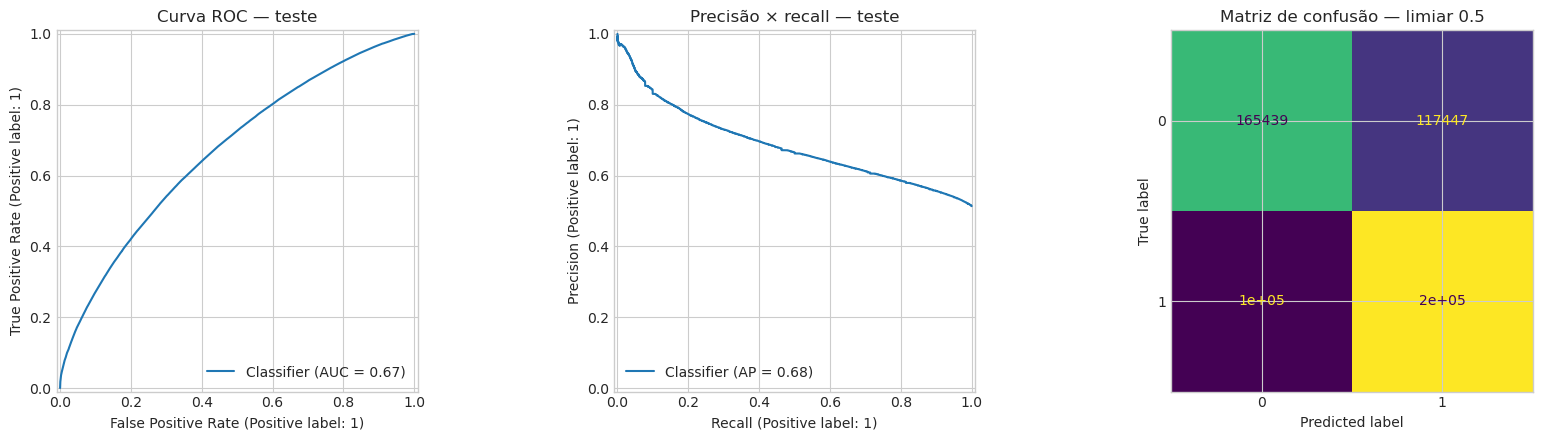

In [238]:
inicio = time.perf_counter()
score_test = modelo.predict_proba(X_test)[:, 1]
pred_test = np.asarray(score_test >= LIMIAR_CLASSIFICACAO, dtype=np.int8)
tempo_inferencia = time.perf_counter() - inicio

metricas_teste = calcular_metricas(y_test, pred_test, score_test)
display(pl.DataFrame([{k: v for k, v in metricas_teste.items() if k != "matriz_confusao"}]))
print("Matriz de confusão:", metricas_teste["matriz_confusao"])
print("Tempo de inferência (s):", tempo_inferencia)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
RocCurveDisplay.from_predictions(y_test, score_test, ax=axes[0])
axes[0].set_title("Curva ROC — teste")
PrecisionRecallDisplay.from_predictions(y_test, score_test, ax=axes[1])
axes[1].set_title("Precisão × recall — teste")
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, ax=axes[2], colorbar=False)
axes[2].set_title(f"Matriz de confusão — limiar {LIMIAR_CLASSIFICACAO}")
plt.tight_layout()
salvar_figura_eda(plt.gcf(), "avaliacao_final_curvas_e_matriz.png"); plt.show()


## 6. Calibração das probabilidades


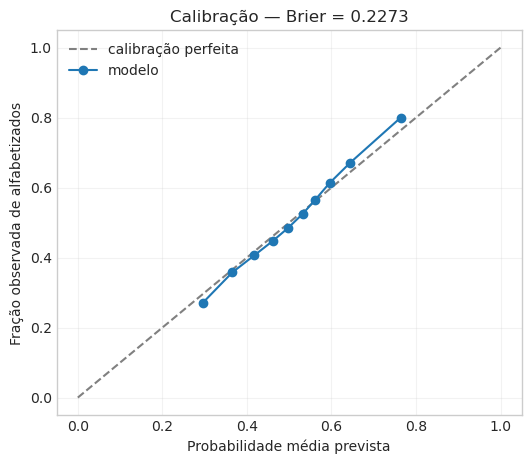

In [239]:
frac_pos, prob_media = calibration_curve(y_test, score_test, n_bins=10, strategy="quantile")
plt.figure(figsize=(6, 5))
plt.plot([0, 1], [0, 1], "--", color="gray", label="calibração perfeita")
plt.plot(prob_media, frac_pos, marker="o", label="modelo")
plt.xlabel("Probabilidade média prevista")
plt.ylabel("Fração observada de alfabetizados")
plt.title(f"Calibração — Brier = {metricas_teste['brier_score']:.4f}")
plt.legend()
plt.grid(alpha=0.25)
salvar_figura_eda(plt.gcf(), "avaliacao_final_calibracao.png"); plt.show()


## 7. Incerteza das métricas


In [240]:
rng = np.random.default_rng(SEED)
n_boot = tamanho_por_fracao(len(y_test), FRACAO_BOOTSTRAP)
base_idx = rng.choice(len(y_test), size=n_boot, replace=False)
y_boot_base = y_test[base_idx]
s_boot_base = score_test[base_idx]
p_boot_base = pred_test[base_idx]

amostras_metricas = []
for _ in range(REPETICOES_BOOTSTRAP):
    idx = rng.integers(0, n_boot, size=n_boot)
    yt, st, pt = y_boot_base[idx], s_boot_base[idx], p_boot_base[idx]
    if np.unique(yt).size < 2:
        continue
    amostras_metricas.append({
        "roc_auc": roc_auc_score(yt, st),
        "average_precision": average_precision_score(yt, st),
        "balanced_accuracy": balanced_accuracy_score(yt, pt),
        "f1": f1_score(yt, pt, zero_division=0),
    })

bootstrap = pl.DataFrame(amostras_metricas)
intervalos_95 = {
    coluna: {
        "inferior": float(bootstrap[coluna].quantile(0.025)),
        "superior": float(bootstrap[coluna].quantile(0.975)),
    }
    for coluna in bootstrap.columns
}
display(pl.DataFrame([{"metrica": k, **v} for k, v in intervalos_95.items()]))


metrica,inferior,superior
str,f64,f64
"""roc_auc""",0.667344,0.673679
"""average_precision""",0.681738,0.690173
"""balanced_accuracy""",0.616726,0.621786
"""f1""",0.636877,0.64306


## 8. Importância das variáveis


[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran

feature,importancia_media,importancia_desvio
str,f64,f64
"""sigla_uf""",0.081454,0.001723
"""valor_bolsa_familia__signed_lo…",0.013114,0.000664
"""media_inse""",0.008716,0.000608
"""rede""",0.007759,0.000488
"""in_laboratorio_informatica""",0.00525,0.000376
"""valor_receitas__signed_log1p""",0.004941,0.000459
"""in_biblioteca_sala_leitura""",0.0047,0.000729
"""in_internet""",0.004555,0.000394
"""in_quadra_esportes""",0.003779,0.00024


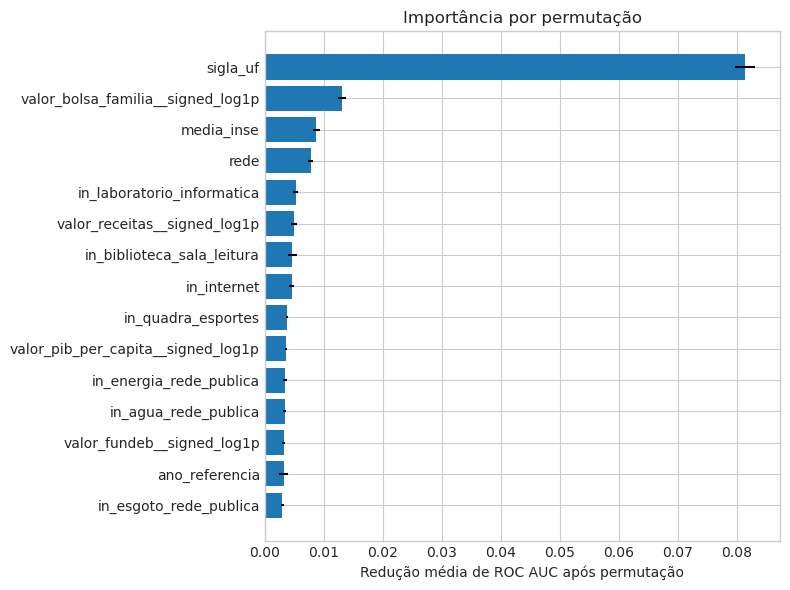

In [241]:
rng = np.random.default_rng(SEED)
n_interpretacao = tamanho_por_fracao(len(y_test), FRACAO_INTERPRETACAO)
idx_interpretacao = rng.choice(len(y_test), size=n_interpretacao, replace=False)
# No Polars, explicitar as duas dimensoes evita que a lista seja interpretada como colunas.
X_interpretacao = X_test[idx_interpretacao.tolist(), :]
y_interpretacao = y_test[idx_interpretacao]

# A rotina nativa do scikit-learn converte o Polars internamente e perde os
# nomes exigidos pelo ColumnTransformer. A implementação abaixo preserva
# o pl.DataFrame e calcula a mesma redução de ROC AUC por permutação.
score_referencia = roc_auc_score(
    y_interpretacao, modelo.predict_proba(X_interpretacao)[:, 1]
)
reducoes_auc = np.empty((len(FEATURES), REPETICOES_PERMUTACAO), dtype=float)

for indice_feature, feature in enumerate(FEATURES):
    valores_originais = X_interpretacao[feature].to_list()
    dtype_feature = X_interpretacao.schema[feature]
    for repeticao in range(REPETICOES_PERMUTACAO):
        ordem = rng.permutation(len(valores_originais))
        valores_permutados = [valores_originais[i] for i in ordem]
        X_permutado = X_interpretacao.with_columns(
            pl.Series(feature, valores_permutados, dtype=dtype_feature)
        )
        score_permutado = roc_auc_score(
            y_interpretacao, modelo.predict_proba(X_permutado)[:, 1]
        )
        reducoes_auc[indice_feature, repeticao] = score_referencia - score_permutado
importancias = (
    pl.DataFrame({
        "feature": FEATURES,
        "importancia_media": reducoes_auc.mean(axis=1),
        "importancia_desvio": reducoes_auc.std(axis=1),
    })
    .sort("importancia_media", descending=True)
)
display(importancias)

top = importancias.head(15).sort("importancia_media")
plt.figure(figsize=(8, 6))
plt.barh(top["feature"], top["importancia_media"], xerr=top["importancia_desvio"])
plt.xlabel("Redução média de ROC AUC após permutação")
plt.title("Importância por permutação")
plt.tight_layout()
salvar_figura_eda(plt.gcf(), "avaliacao_final_importancia_permutacao.png"); plt.show()


### 8.1 Leitura responsável da variável `sigla_uf`

`sigla_uf` resume diferenças territoriais acumuladas — financiamento, oferta educacional, infraestrutura, composição socioeconômica e políticas públicas. Ela é útil como **proxy preditiva**, mas não constitui causa isolada. A importância por permutação abaixo mede quanto o desempenho cai quando a informação de UF é embaralhada; não mede o efeito causal de pertencer a uma UF.


In [242]:
diagnostico_uf = (
    importancias
    .filter(pl.col("feature") == "sigla_uf")
    .with_columns(
        pl.lit("permutação no teste final; interpretação associativa").alias("metodo"),
        pl.lit("proxy territorial; não interpretar como causalidade").alias("advertencia"),
    )
)
display(diagnostico_uf)

if diagnostico_uf.height == 1:
    queda_auc_uf = diagnostico_uf["importancia_media"].item()
    print(f"Ao embaralhar UF, a queda média de ROC AUC foi {queda_auc_uf:.4f}.")
print("sigla_uf agrega diferenças entre políticas estaduais, investimento público, infraestrutura, contexto socioeconômico e desigualdades regionais.")
print("Ela é um proxy territorial: sua importância é preditiva e não identifica efeito causal da localização.")
print("sigla_uf agrega diferenças entre políticas estaduais, investimento público, infraestrutura, contexto socioeconômico e desigualdades regionais.")
print("Ela é um proxy territorial: sua importância é preditiva e não identifica efeito causal da localização.")
print("sigla_uf agrega diferenças entre políticas estaduais, investimento público, infraestrutura, contexto socioeconômico e desigualdades regionais.")
print("Ela é um proxy territorial: sua importância é preditiva e não identifica efeito causal da localização.")
print("A análise por UF deve ser lida em conjunto com cobertura, rede e tamanho amostral.")


feature,importancia_media,importancia_desvio,metodo,advertencia
str,f64,f64,str,str
"""sigla_uf""",0.081454,0.001723,"""permutação no teste final; int…","""proxy territorial; não interpr…"


Ao embaralhar UF, a queda média de ROC AUC foi 0.0815.
sigla_uf agrega diferenças entre políticas estaduais, investimento público, infraestrutura, contexto socioeconômico e desigualdades regionais.
Ela é um proxy territorial: sua importância é preditiva e não identifica efeito causal da localização.
sigla_uf agrega diferenças entre políticas estaduais, investimento público, infraestrutura, contexto socioeconômico e desigualdades regionais.
Ela é um proxy territorial: sua importância é preditiva e não identifica efeito causal da localização.
sigla_uf agrega diferenças entre políticas estaduais, investimento público, infraestrutura, contexto socioeconômico e desigualdades regionais.
Ela é um proxy territorial: sua importância é preditiva e não identifica efeito causal da localização.
A análise por UF deve ser lida em conjunto com cobertura, rede e tamanho amostral.


## 10.1 Análise de sensibilidade — modelo com e sem `sigla_uf`

Esta análise mede quanto o desempenho preditivo depende do proxy territorial. O Random Forest é repetido com os mesmos hiperparâmetros congelados, removendo somente `sigla_uf`. A comparação é pós-seleção e descritiva: não altera o algoritmo, os hiperparâmetros, o limiar ou o modelo oficial após observar o teste. Diferenças não devem ser interpretadas como efeito causal da UF.


In [243]:
FEATURES_SEM_UF = [feature for feature in FEATURES if feature != "sigla_uf"]
CATEGORICAS_SEM_UF = [feature for feature in ["rede"] if feature in FEATURES_SEM_UF]
NUMERICAS_SEM_UF = [feature for feature in FEATURES_SEM_UF if feature not in CATEGORICAS_SEM_UF]
INDICES_CATEGORICAS_SEM_UF = [FEATURES_SEM_UF.index(feature) for feature in CATEGORICAS_SEM_UF]
INDICES_NUMERICAS_SEM_UF = [FEATURES_SEM_UF.index(feature) for feature in NUMERICAS_SEM_UF]

categorico_sem_uf = Pipeline([
    ("imputer", SimpleImputer(strategy=IMPUTACAO_CATEGORICA_GLOBAL)),
    ("encoder", OneHotEncoder(
        handle_unknown=ONE_HOT_DESCONHECIDO_GLOBAL,
        sparse_output=ONE_HOT_SPARSO_GLOBAL,
        dtype=np.float32,
    )),
])
numerico_sem_uf = Pipeline([
    ("imputer", SimpleImputer(strategy=IMPUTACAO_NUMERICA_GLOBAL)),
])
preprocessador_sem_uf = ColumnTransformer(
    [
        ("categoricas", categorico_sem_uf, INDICES_CATEGORICAS_SEM_UF),
        ("numericas", numerico_sem_uf, INDICES_NUMERICAS_SEM_UF),
    ],
    sparse_threshold=SPARSE_THRESHOLD_GLOBAL,
)

estimador_sem_uf = RandomForestClassifier(random_state=SEED, n_jobs=N_JOBS_MODELAGEM_GLOBAL)
estimador_sem_uf.set_params(**parametros)
modelo_sem_uf = Pipeline([
    ("preprocessor", preprocessador_sem_uf),
    ("model", estimador_sem_uf),
])

X_dev_sem_uf = X_dev.select(FEATURES_SEM_UF)
X_test_sem_uf = X_test.select(FEATURES_SEM_UF)
modelo_sem_uf.fit(X_dev_sem_uf, y_dev)
validar_backend_modelo(modelo_sem_uf)
pred_test_sem_uf = np.asarray(modelo_sem_uf.predict(X_test_sem_uf))
score_test_sem_uf = pontuacao(modelo_sem_uf, X_test_sem_uf)
metricas_teste_sem_uf = calcular_metricas(y_test, pred_test_sem_uf, score_test_sem_uf)

metricas_sensibilidade = ["roc_auc", "average_precision", "balanced_accuracy", "f1"]
sensibilidade_uf = pl.DataFrame([
    {
        "metrica": metrica,
        "com_sigla_uf": metricas_teste[metrica],
        "sem_sigla_uf": metricas_teste_sem_uf[metrica],
        "diferenca_com_menos_sem": metricas_teste[metrica] - metricas_teste_sem_uf[metrica],
    }
    for metrica in metricas_sensibilidade
])
RESULTADOS_TABELAS_DIR.mkdir(parents=True, exist_ok=True)
sensibilidade_uf.write_csv(
    RESULTADOS_TABELAS_DIR / "18_sensibilidade_sigla_uf.csv"
)
display(sensibilidade_uf)
print("Análise pós-seleção: estes resultados não serão usados para novo tuning ou troca do modelo oficial.")


[cuml.accel] `RandomForestClassifier.fit` ran on GPU
Backend validado — RandomForestClassifier: GPU
[cuml.accel] `RandomForestClassifier.predict` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU


metrica,com_sigla_uf,sem_sigla_uf,diferenca_com_menos_sem
str,f64,f64,f64
"""roc_auc""",0.670483,0.675669,-0.005187
"""average_precision""",0.684097,0.691022,-0.006925
"""balanced_accuracy""",0.619615,0.623244,-0.003629
"""f1""",0.639195,0.636279,0.002916


Análise pós-seleção: estes resultados não serão usados para novo tuning ou troca do modelo oficial.
[recursos] nível=moderado; threads=2; RAM usada=66.5%; livre=5.2 GB.


## 9. Estabilidade por ano, rede e UF; agregação municipal


In [244]:
avaliacao = teste.select(["id_municipio", "sigla_uf", "rede", "ano_referencia", TARGET]).with_columns(
    pl.Series("probabilidade", score_test), pl.Series("predicao", pred_test)
)

def avaliar_recortes(frame: pl.DataFrame, coluna: str, minimo: int = 500) -> pl.DataFrame:
    linhas = []
    for grupo in frame.partition_by(coluna, as_dict=False, maintain_order=True):
        if grupo.height < minimo or grupo[TARGET].n_unique() < 2:
            continue
        y_grupo = grupo[TARGET].to_numpy()
        pred_grupo = grupo["predicao"].to_numpy()
        score_grupo = grupo["probabilidade"].to_numpy()
        tn, fp, fn, tp = confusion_matrix(y_grupo, pred_grupo, labels=[0, 1]).ravel()
        taxa_observada = float(y_grupo.mean())
        probabilidade_media = float(score_grupo.mean())
        linhas.append({
            coluna: grupo[coluna][0], "registros": grupo.height,
            "taxa_observada": taxa_observada,
            "probabilidade_media": probabilidade_media,
            "erro_calibracao_medio": probabilidade_media - taxa_observada,
            "taxa_predita_positiva": float(pred_grupo.mean()),
            "sensibilidade": tp / (tp + fn) if (tp + fn) else None,
            "especificidade": tn / (tn + fp) if (tn + fp) else None,
            "roc_auc": roc_auc_score(y_grupo, score_grupo),
            "balanced_accuracy": balanced_accuracy_score(y_grupo, pred_grupo),
            "f1": f1_score(y_grupo, pred_grupo, zero_division=0),
            "alerta_limiar": "predição de uma classe" if np.unique(pred_grupo).size < 2 else "",
        })
    return pl.DataFrame(linhas)

recortes = {nome: avaliar_recortes(avaliacao, coluna) for nome, coluna in {
    "ano": "ano_referencia", "rede": "rede", "uf": "sigla_uf"
}.items()}
for nome, tabela in recortes.items():
    print("\nRecorte:", nome); display(tabela)
    if not tabela.is_empty():
        alertas = tabela.filter(pl.col("alerta_limiar") != "")
        if not alertas.is_empty():
            print(f"Atenção: {alertas.height} recorte(s) com predição de uma única classe no limiar global {LIMIAR_CLASSIFICACAO}.")

municipios = avaliacao.group_by(["ano_referencia", "id_municipio", "sigla_uf", "rede"]).agg(
    pl.len().alias("registros"),
    pl.col(TARGET).mean().alias("taxa_alfabetizacao_observada"),
    pl.col("probabilidade").mean().alias("probabilidade_media"),
)
display(municipios.head())


[recursos] nível=normal; threads=4; RAM usada=59.1%; livre=6.3 GB.

Recorte: ano


ano_referencia,registros,taxa_observada,probabilidade_media,erro_calibracao_medio,taxa_predita_positiva,sensibilidade,especificidade,roc_auc,balanced_accuracy,f1,alerta_limiar
i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
2024,318824,0.523552,0.518623,-0.004929,0.560052,0.674672,0.565901,0.670886,0.620287,0.651947,""""""
2023,262767,0.501524,0.506193,0.004669,0.511339,0.628733,0.606773,0.669005,0.617753,0.622641,""""""



Recorte: rede


rede,registros,taxa_observada,probabilidade_media,erro_calibracao_medio,taxa_predita_positiva,sensibilidade,especificidade,roc_auc,balanced_accuracy,f1,alerta_limiar
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""2""",65599,0.529871,0.522121,-0.00775,0.588957,0.683909,0.518061,0.645759,0.600985,0.647791,""""""
"""3""",515992,0.511531,0.511848,0.000317,0.53157,0.650519,0.592995,0.673115,0.621757,0.638022,""""""



Recorte: uf


sigla_uf,registros,taxa_observada,probabilidade_media,erro_calibracao_medio,taxa_predita_positiva,sensibilidade,especificidade,roc_auc,balanced_accuracy,f1,alerta_limiar
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""AC""",1898,0.443625,0.432375,-0.01125,0.050053,0.071259,0.966856,0.589067,0.519057,0.128068,""""""
"""AL""",10554,0.441349,0.439999,-0.00135,0.155107,0.264062,0.93097,0.644353,0.597516,0.390786,""""""
"""AM""",18302,0.404765,0.402807,-0.001957,0.086165,0.132559,0.945383,0.601315,0.538971,0.218587,""""""
"""AP""",3707,0.40491,0.401295,-0.003615,0.058808,0.097935,0.967815,0.604023,0.532875,0.17103,""""""
"""BA""",38444,0.319582,0.321147,0.001565,0.003225,0.00643,0.99828,0.595232,0.502355,0.012732,""""""
"""CE""",28799,0.818327,0.816912,-0.001415,1.0,1.0,0.0,0.711003,0.5,0.900088,"""predição de uma classe"""
"""DF""",4199,0.458919,0.477887,0.018968,0.0,0.0,1.0,0.5,0.5,0.0,"""predição de uma classe"""
"""ES""",14916,0.624162,0.616022,-0.00814,1.0,1.0,0.0,0.614268,0.5,0.768596,"""predição de uma classe"""
"""GO""",24252,0.625763,0.61797,-0.007793,0.919842,0.946363,0.124504,0.626346,0.535433,0.7663,""""""


Atenção: 3 recorte(s) com predição de uma única classe no limiar global 0.5.


ano_referencia,id_municipio,sigla_uf,rede,registros,taxa_alfabetizacao_observada,probabilidade_media
i64,i64,str,str,u32,f64,f32
2023,2104677,"""MA""","""3""",60,0.666667,0.583163
2024,2911600,"""BA""","""3""",19,0.315789,0.310833
2024,5222302,"""GO""","""3""",19,0.578947,0.703679
2024,2927309,"""BA""","""3""",41,0.512195,0.358041
2024,4311429,"""RS""","""3""",3,0.666667,0.554814


## 10. Exportação dos artefatos deste modelo


In [245]:
MODEL_DIR = MODELOS_DIR / "random_forest"
METRICAS_FINAIS_DIR = RESULTADOS_METRICAS_DIR / "fase_7"
ANALITICOS_FINAIS_DIR = DADOS_ANALITICOS_DIR / "avaliacao_independente"
for diretorio in (MODEL_DIR, METRICAS_FINAIS_DIR, ANALITICOS_FINAIS_DIR):
    diretorio.mkdir(parents=True, exist_ok=True)

joblib.dump(modelo, MODEL_DIR / "modelo_pipeline.joblib")
importancias.write_csv(RESULTADOS_TABELAS_DIR / "importancia_permutacao.csv")
municipios.write_parquet(ANALITICOS_FINAIS_DIR / "predicoes_agregadas_municipio.parquet")
for nome, tabela in recortes.items():
    tabela.write_csv(RESULTADOS_TABELAS_DIR / f"metricas_por_{nome}.csv")

resultado = {
    "schema_resultado": 1,
    "modelo": "Random Forest",
    "modo": "avaliacao_final_independente",
    "hipotese": "modelo tratado como único candidato selecionado",
    "manifesto": MANIFEST_PATH.relative_to(PROJECT_ROOT).as_posix(),
    "features": FEATURES,
    "parametros": parametros,
    "limiar_classificacao": LIMIAR_CLASSIFICACAO,
    "registros_desenvolvimento": int(len(y_dev)),
    "registros_teste": int(len(y_test)),
    "metricas_teste": metricas_teste,
    "intervalos_95_bootstrap": intervalos_95,
    "tempo_treino_segundos": float(tempo_treino),
    "tempo_inferencia_segundos": float(tempo_inferencia),
    "avisos_treinamento": [str(a.message) for a in avisos_treino],
    "ambiente": {
        "python": platform.python_version(),
        "scikit_learn": sklearn.__version__,
        "polars": pl.__version__,
    },
    "ressalvas": [
        "id_escola e chave_escola_ano não foram utilizadas como features.",
        "A chave de escola é anônima e anual; não identifica a unidade real.",
        "São Paulo possui registros somente em 2024.",
        "Resultados por município, UF e rede são associações preditivas, não efeitos causais.",
        "O teste não deve ser reutilizado para ajustar features, hiperparâmetros ou limiar.",
        "Recortes com predição de uma única classe no limiar global indicam limitação de transportabilidade, não erro de execução.",
        "A importância de sigla_uf representa sinal territorial e possível uso de proxy geográfica; não implica causalidade.",
    ],
}
(METRICAS_FINAIS_DIR / "resultado_final.json").write_text(
    json.dumps(resultado, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Modelo:", MODEL_DIR)
print("Métricas:", METRICAS_FINAIS_DIR)
print("Dados analíticos:", ANALITICOS_FINAIS_DIR)


Modelo: /workspace/modelos/random_forest
Métricas: /workspace/resultados/metricas/fase_7
Dados analíticos: /workspace/dados/dados_analiticos/avaliacao_independente


<a id="inteligencia-analitica"></a>

# Camada final de inteligência analítica

Esta seção responde às perguntas norteadoras usando exclusivamente o modelo já congelado e as previsões da avaliação independente. Nenhuma análise abaixo retorna ao treinamento, altera features, hiperparâmetros ou limiar. Os resultados são associações descritivas e preditivas, não efeitos causais.


In [246]:
from datetime import datetime, timezone
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from scipy.stats import spearmanr
from IPython.display import Markdown

ANALISE_DIR = RESULTADOS_RELATORIOS_DIR
FIGURAS_DIR = RESULTADOS_FIGURAS_DIR
TABELAS_DIR = RESULTADOS_TABELAS_DIR
for diretorio in (ANALISE_DIR, FIGURAS_DIR, TABELAS_DIR):
    diretorio.mkdir(parents=True, exist_ok=True)

LIMITES_RISCO_META = {"alto": 0.10, "moderado": 0.05, "atencao": 0.00}

def salvar_figura(fig, nome):
    caminho = FIGURAS_DIR / nome
    fig.savefig(caminho, dpi=180, bbox_inches="tight")
    return caminho

def resumo_faixas(frame: pl.DataFrame, feature: str, grupos: int = 5, por_ano: bool = False) -> pl.DataFrame:
    if feature not in frame.columns:
        return pl.DataFrame()
    base = frame.select([feature, TARGET, "probabilidade", "ano_referencia", "rede"]).with_columns(
        pl.col(feature).cast(pl.Float64, strict=False)
    ).drop_nulls([feature])
    if base.is_empty() or base[feature].n_unique() < 2:
        return pl.DataFrame()
    base = base.with_columns(pl.col(feature).bin_quantiles(grupos, labels=False).cast(pl.String).alias("faixa"))
    chaves = (["ano_referencia"] if por_ano else []) + ["faixa"]
    return base.group_by(chaves, maintain_order=True).agg(
        pl.len().alias("registros"), pl.col(feature).mean().alias("feature_media"),
        pl.col(TARGET).mean().alias("taxa_observada"),
        pl.col("probabilidade").mean().alias("probabilidade_media"),
    ).sort(chaves)

colunas_contexto = list(dict.fromkeys(["id_municipio", "sigla_uf", "rede", "ano_referencia", TARGET, *FEATURES]))
avaliacao_contextual = teste.select(colunas_contexto).with_columns(
    pl.Series("probabilidade", score_test), pl.Series("predicao", pred_test)
)
print("Diretório da análise final:", ANALISE_DIR)


Diretório da análise final: /workspace/resultados/relatorios


## 11. Evidências visuais do modelo final

Os gráficos principais são recriados e persistidos para uso no relatório e no vídeo. A exportação não altera as métricas.


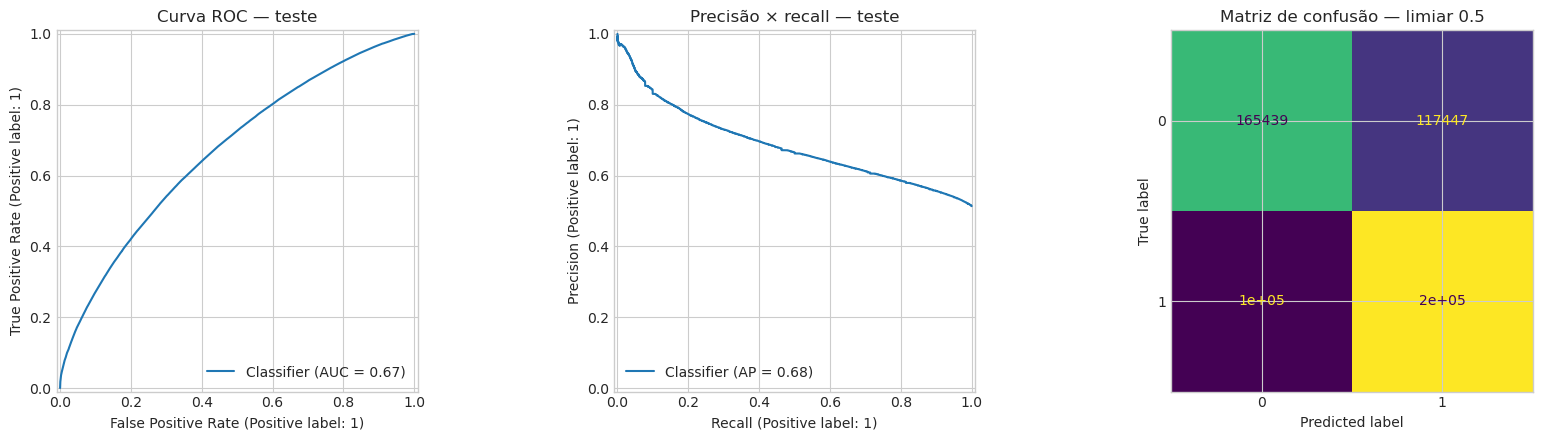

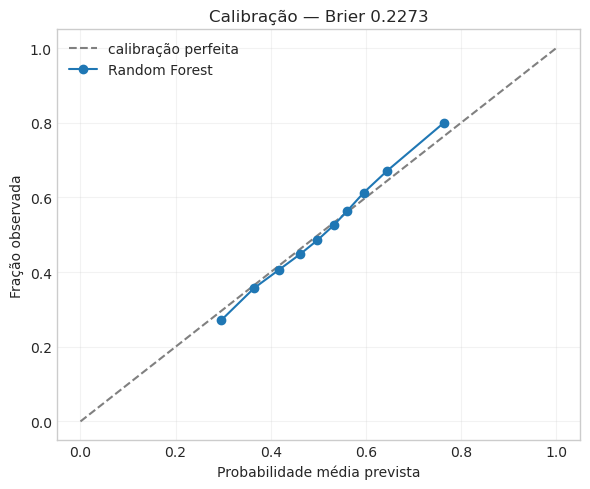

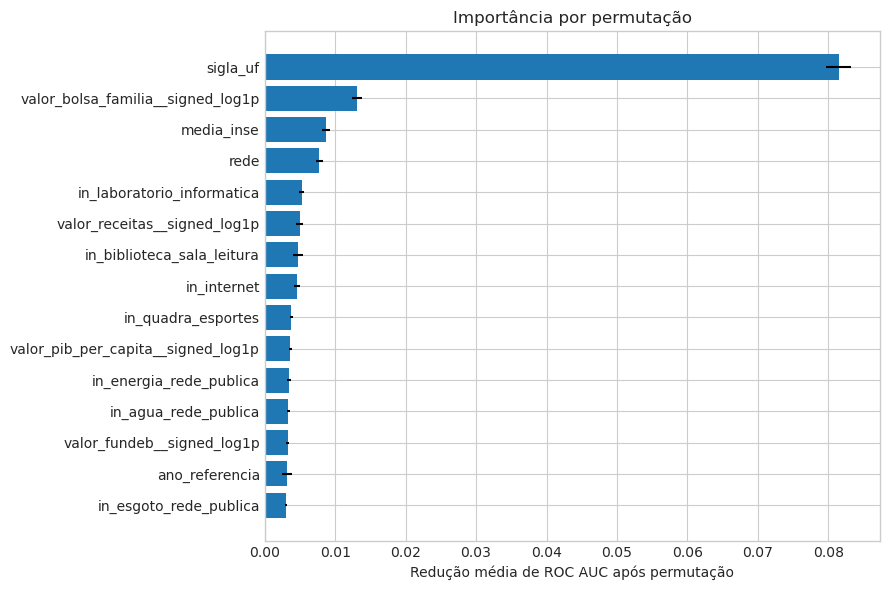

In [247]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
RocCurveDisplay.from_predictions(y_test, score_test, ax=axes[0])
axes[0].set_title("Curva ROC — teste")
PrecisionRecallDisplay.from_predictions(y_test, score_test, ax=axes[1])
axes[1].set_title("Precisão × recall — teste")
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, ax=axes[2], colorbar=False)
axes[2].set_title(f"Matriz de confusão — limiar {LIMIAR_CLASSIFICACAO}")
fig.tight_layout()
salvar_figura(fig, "01_metricas_classificacao.png")
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], "--", color="gray", label="calibração perfeita")
ax.plot(prob_media, frac_pos, marker="o", label="Random Forest")
ax.set(xlabel="Probabilidade média prevista", ylabel="Fração observada", title=f"Calibração — Brier {metricas_teste['brier_score']:.4f}")
ax.legend(); ax.grid(alpha=0.25); fig.tight_layout()
salvar_figura(fig, "02_calibracao.png")
plt.show()

top_plot = importancias.head(15).sort("importancia_media")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_plot["feature"], top_plot["importancia_media"], xerr=top_plot["importancia_desvio"])
ax.set(xlabel="Redução média de ROC AUC após permutação", title="Importância por permutação")
fig.tight_layout()
salvar_figura(fig, "03_importancia_permutacao.png")
plt.show()


## 12. Fatores contextuais associados

A importância por permutação mede perda de desempenho quando uma variável é embaralhada. Ela não informa causalidade e sua direção deve ser complementada pelas análises por faixa abaixo.


In [248]:
fatores_associados = importancias.with_columns(
    pl.lit("importância preditiva por permutação").alias("tipo_evidencia"),
    pl.when(pl.col("importancia_media") > 0)
      .then(pl.lit("contribui para discriminação no conjunto avaliado"))
      .otherwise(pl.lit("sem ganho preditivo estável nesta análise")).alias("interpretacao"),
    pl.lit("associação contextual; não representa efeito causal individual").alias("limitacao"),
)
fatores_associados.write_csv(TABELAS_DIR / "01_fatores_associados.csv")
display(fatores_associados.head(15))


feature,importancia_media,importancia_desvio,tipo_evidencia,interpretacao,limitacao
str,f64,f64,str,str,str
"""sigla_uf""",0.081454,0.001723,"""importância preditiva por perm…","""contribui para discriminação n…","""associação contextual; não rep…"
"""valor_bolsa_familia__signed_lo…",0.013114,0.000664,"""importância preditiva por perm…","""contribui para discriminação n…","""associação contextual; não rep…"
"""media_inse""",0.008716,0.000608,"""importância preditiva por perm…","""contribui para discriminação n…","""associação contextual; não rep…"
"""rede""",0.007759,0.000488,"""importância preditiva por perm…","""contribui para discriminação n…","""associação contextual; não rep…"
"""in_laboratorio_informatica""",0.00525,0.000376,"""importância preditiva por perm…","""contribui para discriminação n…","""associação contextual; não rep…"
"""valor_receitas__signed_log1p""",0.004941,0.000459,"""importância preditiva por perm…","""contribui para discriminação n…","""associação contextual; não rep…"
"""in_biblioteca_sala_leitura""",0.0047,0.000729,"""importância preditiva por perm…","""contribui para discriminação n…","""associação contextual; não rep…"
"""in_internet""",0.004555,0.000394,"""importância preditiva por perm…","""contribui para discriminação n…","""associação contextual; não rep…"
"""in_quadra_esportes""",0.003779,0.00024,"""importância preditiva por perm…","""contribui para discriminação n…","""associação contextual; não rep…"


## 13. Infraestrutura municipal

As variáveis representam proporções municipais de escolas com cada recurso. Elas não identificam a infraestrutura da escola frequentada por um aluno específico.


feature,ano_referencia,faixa,registros,feature_media,taxa_observada,probabilidade_media
str,i64,str,u32,f64,f64,f32
"""in_biblioteca_sala_leitura""",2023,"""0""",53105,0.267534,0.449656,0.455602
"""in_biblioteca_sala_leitura""",2023,"""1""",39800,0.501187,0.494824,0.501307
"""in_biblioteca_sala_leitura""",2023,"""2""",53998,0.625832,0.509408,0.515475
"""in_biblioteca_sala_leitura""",2023,"""3""",51537,0.712559,0.51074,0.511298
"""in_biblioteca_sala_leitura""",2023,"""4""",64327,0.82958,0.534488,0.5391
"""in_biblioteca_sala_leitura""",2024,"""0""",61587,0.281031,0.481904,0.476892
"""in_biblioteca_sala_leitura""",2024,"""1""",77983,0.486255,0.513073,0.51108
"""in_biblioteca_sala_leitura""",2024,"""2""",60817,0.622722,0.533124,0.527522
"""in_biblioteca_sala_leitura""",2024,"""3""",52605,0.710633,0.518753,0.516505


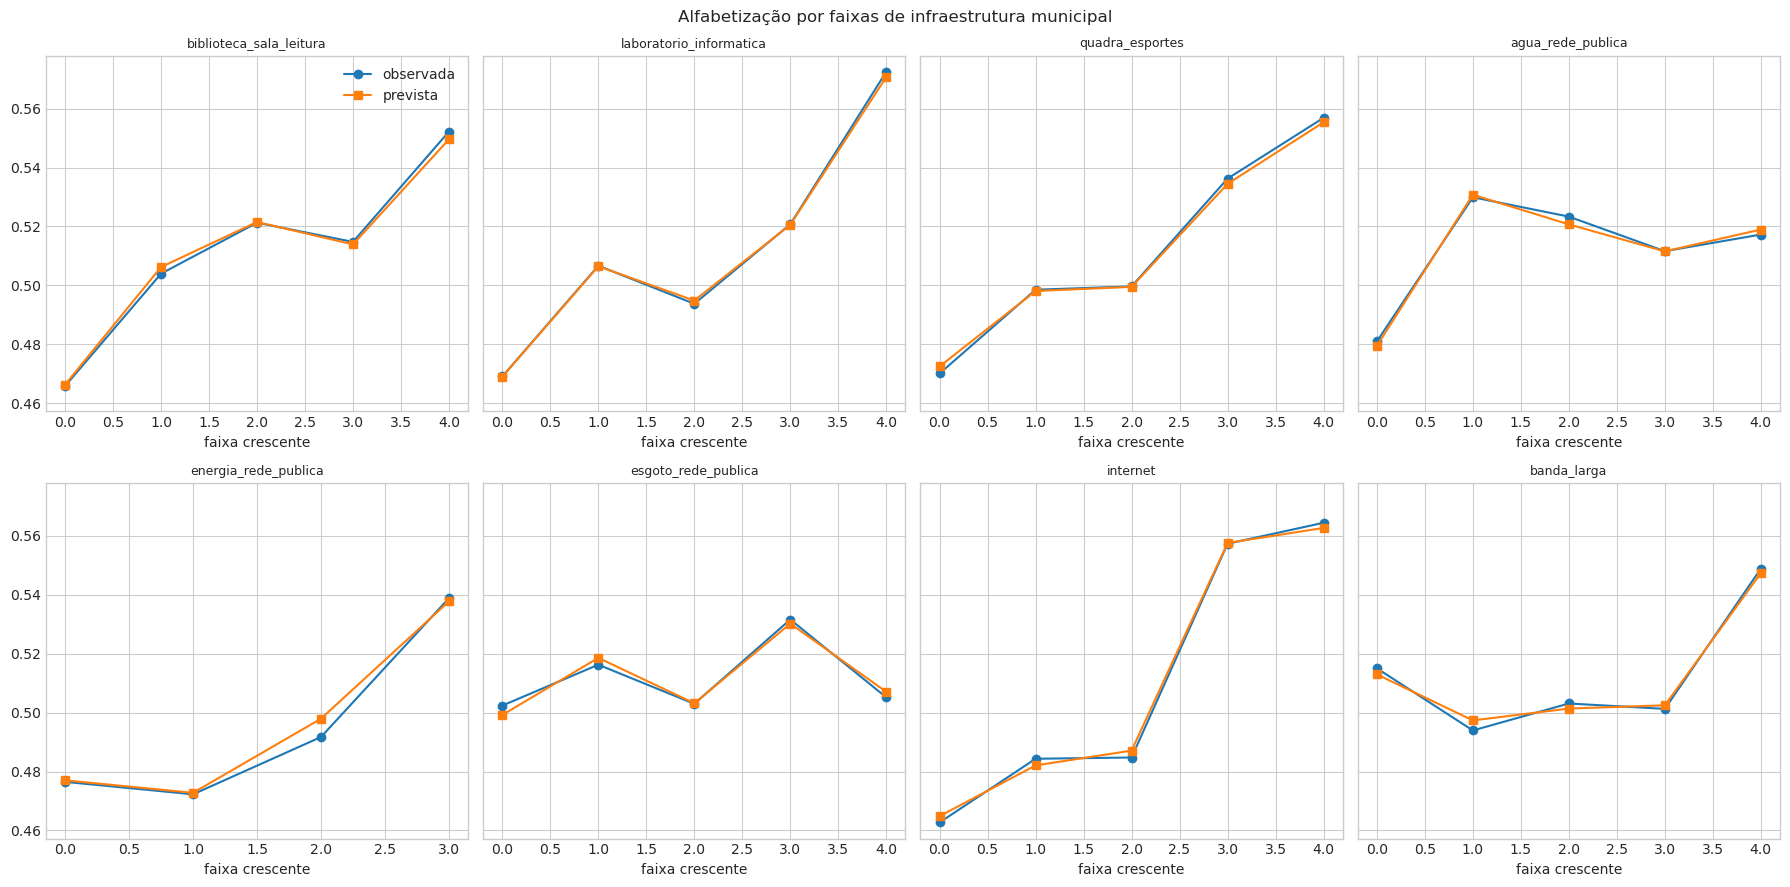

In [249]:
FEATURES_INFRA = [
    "in_biblioteca_sala_leitura", "in_laboratorio_informatica", "in_quadra_esportes",
    "in_agua_rede_publica", "in_energia_rede_publica", "in_esgoto_rede_publica",
    "in_internet", "in_banda_larga",
]
infra_tabelas = []
for feature in FEATURES_INFRA:
    tabela = resumo_faixas(avaliacao_contextual, feature, grupos=5, por_ano=True)
    if not tabela.is_empty():
        infra_tabelas.append(tabela.with_columns(pl.lit(feature).alias("feature")).select(["feature", *tabela.columns]))
infraestrutura = pl.concat(infra_tabelas, how="diagonal_relaxed") if infra_tabelas else pl.DataFrame()
infraestrutura.write_csv(TABELAS_DIR / "02_infraestrutura_por_faixa_ano.csv")
display(infraestrutura.head(20))

if not infraestrutura.is_empty():
    resumo_infra = infraestrutura.group_by(["feature", "faixa"]).agg(
        pl.col("feature_media").mean(), pl.col("taxa_observada").mean(), pl.col("probabilidade_media").mean()
    ).sort(["feature", "faixa"])
    fig, axes = plt.subplots(2, 4, figsize=(18, 9), sharey=True)
    for ax, feature in zip(axes.ravel(), FEATURES_INFRA):
        sub = resumo_infra.filter(pl.col("feature") == feature)
        ax.plot(range(sub.height), sub["taxa_observada"].to_numpy(), marker="o", label="observada")
        ax.plot(range(sub.height), sub["probabilidade_media"].to_numpy(), marker="s", label="prevista")
        ax.set_title(feature.replace("in_", ""), fontsize=9); ax.set_xlabel("faixa crescente")
    axes[0, 0].legend(); fig.suptitle("Alfabetização por faixas de infraestrutura municipal")
    fig.tight_layout(); salvar_figura(fig, "04_infraestrutura_faixas.png"); plt.show()


## 14. INSE municipal

`media_inse` é uma medida contextual municipal de 2023. A análise separa os resultados de 2023 e 2024 e não a interpreta como característica individual do aluno.


ano_referencia,faixa,registros,feature_media,taxa_observada,probabilidade_media
i64,str,u32,f64,f64,f32
2023,"""0""",59972,4.285343,0.486194,0.494968
2023,"""1""",60244,4.636339,0.454004,0.457364
2023,"""2""",54973,4.983847,0.500646,0.508365
2023,"""3""",43307,5.229293,0.528875,0.540434
2023,"""4""",44271,5.477584,0.561293,0.551654
2024,"""0""",55282,4.284824,0.513006,0.508842
2024,"""1""",57136,4.643132,0.482288,0.473709
2024,"""2""",55267,4.987907,0.547813,0.536995
2024,"""3""",79047,5.207266,0.540375,0.535318


ano_referencia,spearman_target,spearman_probabilidade,registros
i64,f64,f64,i64
2024,0.02403,0.173926,318824
2023,0.058576,0.28052,262767


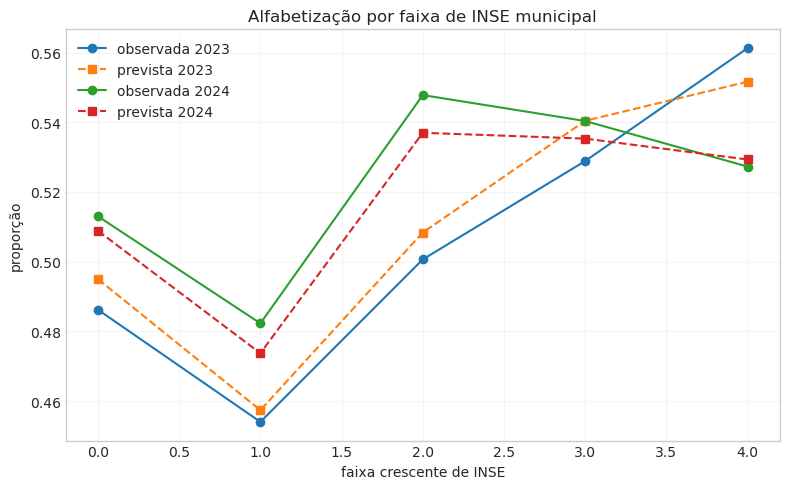

In [250]:
inse_faixas = resumo_faixas(avaliacao_contextual, "media_inse", grupos=5, por_ano=True)
inse_faixas.write_csv(TABELAS_DIR / "03_inse_por_faixa_ano.csv")
linhas_correlacao = []
for grupo in avaliacao_contextual.select(["ano_referencia", "media_inse", TARGET, "probabilidade"]).drop_nulls().partition_by("ano_referencia"):
    linhas_correlacao.append({
        "ano_referencia": grupo["ano_referencia"][0],
        "spearman_target": float(spearmanr(grupo["media_inse"].to_numpy(), grupo[TARGET].to_numpy()).statistic),
        "spearman_probabilidade": float(spearmanr(grupo["media_inse"].to_numpy(), grupo["probabilidade"].to_numpy()).statistic),
        "registros": grupo.height,
    })
correlacao_inse = pl.DataFrame(linhas_correlacao)
correlacao_inse.write_csv(TABELAS_DIR / "04_inse_correlacoes.csv")
display(inse_faixas, correlacao_inse)

fig, ax = plt.subplots(figsize=(8, 5))
for grupo in inse_faixas.partition_by("ano_referencia", maintain_order=True):
    ano = grupo["ano_referencia"][0]
    ax.plot(range(grupo.height), grupo["taxa_observada"].to_numpy(), marker="o", label=f"observada {ano}")
    ax.plot(range(grupo.height), grupo["probabilidade_media"].to_numpy(), marker="s", linestyle="--", label=f"prevista {ano}")
ax.set(xlabel="faixa crescente de INSE", ylabel="proporção", title="Alfabetização por faixa de INSE municipal")
ax.legend(); ax.grid(alpha=0.2); fig.tight_layout(); salvar_figura(fig, "05_inse_faixas.png"); plt.show()


## 15. Persistência municipal entre 2023 e 2024

A comparação utiliza somente municípios e redes presentes nos dois anos. Ela mede persistência de curto prazo; dois anos não constituem tendência histórica longa.


municipios_redes_comparaveis,spearman_observado_2023_2024,spearman_previsto_2023_2024
i64,f64,f64
5653,0.447454,0.893588


faixa_2023,faixa_2024,len,proporcao
str,str,u32,f64
"""medio""","""baixo""",470,0.251876
"""alto""","""baixo""",268,0.142251
"""baixo""","""medio""",540,0.283762
"""alto""","""alto""",1189,0.631104
"""medio""","""alto""",589,0.315648
"""medio""","""medio""",807,0.432476
"""baixo""","""baixo""",1009,0.530215
"""baixo""","""alto""",354,0.186022
"""alto""","""medio""",427,0.226645


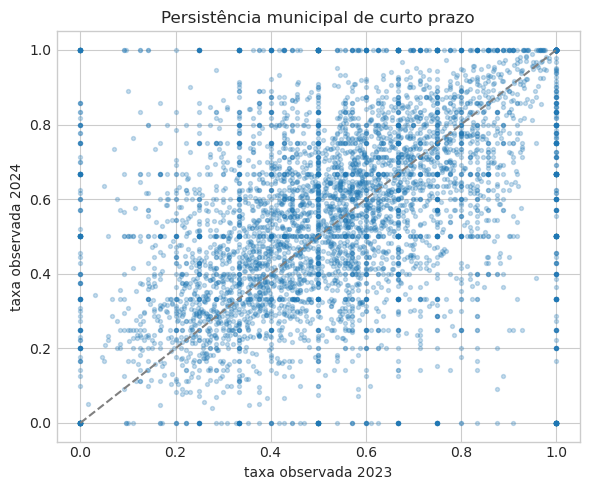

In [251]:
chaves_painel = ["id_municipio", "sigla_uf", "rede"]
metricas_painel = ["registros", "taxa_alfabetizacao_observada", "probabilidade_media"]
painel_2023 = municipios.filter(pl.col("ano_referencia") == 2023).select(chaves_painel + metricas_painel).rename(
    {c: f"{c}_2023" for c in metricas_painel}
)
painel_2024 = municipios.filter(pl.col("ano_referencia") == 2024).select(chaves_painel + metricas_painel).rename(
    {c: f"{c}_2024" for c in metricas_painel}
)
painel_comparavel = painel_2023.join(painel_2024, on=chaves_painel, how="inner").drop_nulls()
painel_comparavel = painel_comparavel.with_columns(
    (100 * (pl.col("taxa_alfabetizacao_observada_2024") - pl.col("taxa_alfabetizacao_observada_2023"))).alias("variacao_observada_pp"),
    (100 * (pl.col("probabilidade_media_2024") - pl.col("probabilidade_media_2023"))).alias("variacao_prevista_pp"),
)
q1, q2 = painel_comparavel["taxa_alfabetizacao_observada_2023"].quantile(1/3), painel_comparavel["taxa_alfabetizacao_observada_2023"].quantile(2/3)
def faixa_expr(coluna):
    return pl.when(pl.col(coluna) <= q1).then(pl.lit("baixo")).when(pl.col(coluna) <= q2).then(pl.lit("medio")).otherwise(pl.lit("alto"))
painel_comparavel = painel_comparavel.with_columns(
    faixa_expr("taxa_alfabetizacao_observada_2023").alias("faixa_2023"),
    faixa_expr("taxa_alfabetizacao_observada_2024").alias("faixa_2024"),
)
transicao = painel_comparavel.group_by(["faixa_2023", "faixa_2024"]).len().with_columns(
    (pl.col("len") / pl.col("len").sum().over("faixa_2023")).alias("proporcao")
)
persistencia = {
    "municipios_redes_comparaveis": painel_comparavel.height,
    "spearman_observado_2023_2024": float(spearmanr(painel_comparavel["taxa_alfabetizacao_observada_2023"].to_numpy(), painel_comparavel["taxa_alfabetizacao_observada_2024"].to_numpy()).statistic),
    "spearman_previsto_2023_2024": float(spearmanr(painel_comparavel["probabilidade_media_2023"].to_numpy(), painel_comparavel["probabilidade_media_2024"].to_numpy()).statistic),
}
painel_comparavel.write_csv(TABELAS_DIR / "05_painel_municipal_2023_2024.csv")
transicao.write_csv(TABELAS_DIR / "06_transicao_faixas_2023_2024.csv")
display(pl.DataFrame([persistencia]), transicao)
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(painel_comparavel["taxa_alfabetizacao_observada_2023"].to_numpy(), painel_comparavel["taxa_alfabetizacao_observada_2024"].to_numpy(), s=8, alpha=0.25)
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set(xlabel="taxa observada 2023", ylabel="taxa observada 2024", title="Persistência municipal de curto prazo")
fig.tight_layout(); salvar_figura(fig, "06_persistencia_2023_2024.png"); plt.show()


## 16. Variáveis financeiras e porte municipal

As variáveis financeiras são analisadas como associações preditivas. Totais municipais podem capturar porte e não equivalem a gasto educacional por aluno.


feature,ano_referencia,faixa,registros,feature_media,taxa_observada,probabilidade_media
str,i64,str,u32,f64,f64,f32
"""valor_bolsa_familia__signed_lo…",2023,"""0""",58498,15.634377,0.568994,0.568827
"""valor_bolsa_familia__signed_lo…",2023,"""1""",57046,17.097563,0.512288,0.52205
"""valor_bolsa_familia__signed_lo…",2023,"""2""",55271,18.034162,0.49431,0.500703
"""valor_bolsa_familia__signed_lo…",2023,"""3""",45106,18.993717,0.467831,0.469238
"""valor_bolsa_familia__signed_lo…",2023,"""4""",46846,20.770401,0.445118,0.450732
"""valor_bolsa_familia__signed_lo…",2024,"""0""",57820,15.684011,0.595763,0.584914
"""valor_bolsa_familia__signed_lo…",2024,"""1""",58785,17.12709,0.546704,0.540901
"""valor_bolsa_familia__signed_lo…",2024,"""2""",61460,18.03802,0.527205,0.520577
"""valor_bolsa_familia__signed_lo…",2024,"""3""",69346,19.029396,0.485998,0.482365


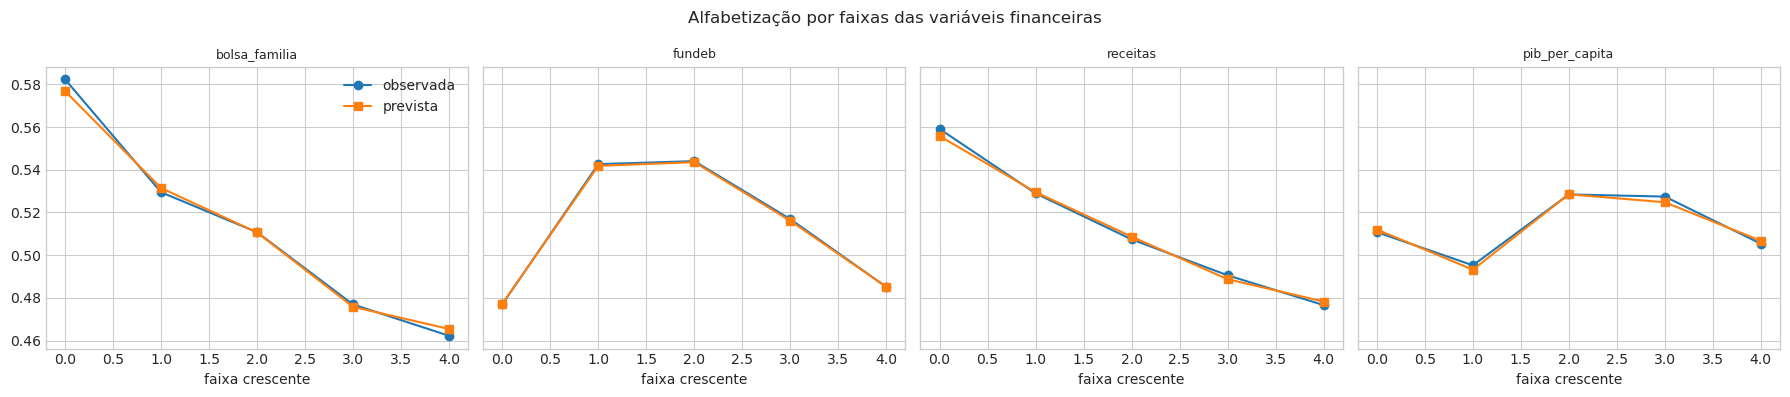

In [252]:
FEATURES_FINANCEIRAS = [
    "valor_bolsa_familia__signed_log1p", "valor_fundeb__signed_log1p",
    "valor_receitas__signed_log1p", "valor_pib_per_capita__signed_log1p",
]
financeiro_tabelas = []
for feature in FEATURES_FINANCEIRAS:
    tabela = resumo_faixas(avaliacao_contextual, feature, grupos=5, por_ano=True)
    if not tabela.is_empty():
        financeiro_tabelas.append(tabela.with_columns(pl.lit(feature).alias("feature")).select(["feature", *tabela.columns]))
financeiro = pl.concat(financeiro_tabelas, how="diagonal_relaxed") if financeiro_tabelas else pl.DataFrame()
financeiro.write_csv(TABELAS_DIR / "07_financas_por_faixa_ano.csv")
display(financeiro.head(20))
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, feature in zip(axes, FEATURES_FINANCEIRAS):
    sub = financeiro.filter(pl.col("feature") == feature).group_by("faixa").agg(
        pl.col("taxa_observada").mean(), pl.col("probabilidade_media").mean()
    ).sort("faixa")
    ax.plot(range(sub.height), sub["taxa_observada"].to_numpy(), marker="o", label="observada")
    ax.plot(range(sub.height), sub["probabilidade_media"].to_numpy(), marker="s", label="prevista")
    ax.set_title(feature.replace("valor_", "").replace("__signed_log1p", ""), fontsize=9); ax.set_xlabel("faixa crescente")
axes[0].legend(); fig.suptitle("Alfabetização por faixas das variáveis financeiras")
fig.tight_layout(); salvar_figura(fig, "07_financas_faixas.png"); plt.show()


## 17. Perfis municipais por cluster

Os clusters são construídos somente com características contextuais. Taxa observada e probabilidade prevista são usadas depois para descrever os grupos, não para formá-los. O número de clusters é escolhido por silhouette entre alternativas previamente limitadas.


[cuml.accel] `KMeans.fit_predict` ran on GPU
[cuml.accel] `KMeans.fit_predict` ran on GPU
[cuml.accel] `KMeans.fit_predict` ran on GPU
[cuml.accel] `KMeans.fit_predict` ran on GPU
[cuml.accel] `KMeans.fit_predict` ran on GPU


k,silhouette,inercia
i64,f64,f64
2,0.236435,145246.867021
3,0.240664,132844.932511
4,0.239402,119158.238569
5,0.200605,106848.653787
6,0.196756,94684.684649


cluster,municipios_ano,taxa_observada,probabilidade_media,media_media_inse,media_valor_bolsa_familia__signed_log1p,media_valor_fundeb__signed_log1p,media_valor_receitas__signed_log1p,media_valor_pib_per_capita__signed_log1p,media_in_biblioteca_sala_leitura,media_in_laboratorio_informatica,media_in_quadra_esportes,media_in_agua_rede_publica,media_in_energia_rede_publica,media_in_esgoto_rede_publica,media_in_internet,media_in_banda_larga,media_cobertura_financeira_ausente,media_cobertura_inse_ausente
i32,u32,f64,f32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0,5058,0.502714,0.501366,4.395372,16.757079,10.623436,20.371199,9.739427,0.376755,0.170189,0.212074,0.598757,0.964814,0.248292,0.84842,0.766286,0.006129,0.0
1,7255,0.597089,0.588593,5.185537,15.634121,14.94687,20.644875,10.657631,0.674692,0.435116,0.496007,0.886803,0.996185,0.580461,0.986261,0.86142,0.002619,0.0
2,25,0.638583,0.648818,4.999194,13.878669,18.096998,19.987373,10.724394,0.727486,0.43499,0.483714,0.933333,0.992,0.622057,1.0,0.647048,0.0,1.0


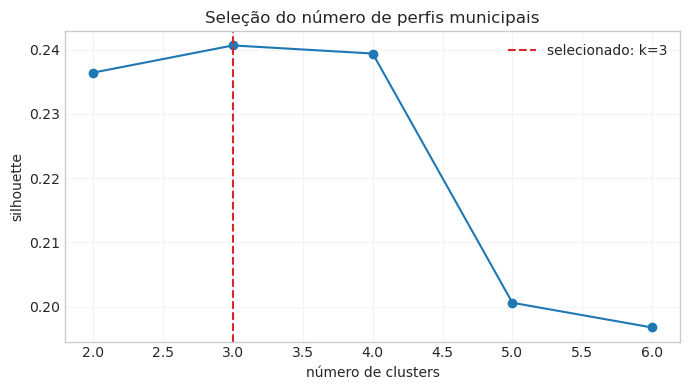

[recursos] nível=moderado; threads=2; RAM usada=60.1%; livre=6.2 GB.


In [253]:
FEATURES_CLUSTER = [
    "media_inse", "valor_bolsa_familia__signed_log1p", "valor_fundeb__signed_log1p",
    "valor_receitas__signed_log1p", "valor_pib_per_capita__signed_log1p",
    *FEATURES_INFRA, "cobertura_financeira_ausente", "cobertura_inse_ausente",
]
municipios_contexto = avaliacao_contextual.group_by(["ano_referencia", "id_municipio", "sigla_uf", "rede"]).agg(
    *[pl.col(feature).mean().alias(feature) for feature in FEATURES_CLUSTER],
    pl.len().alias("registros"), pl.col(TARGET).mean().alias("taxa_observada"),
    pl.col("probabilidade").mean().alias("probabilidade_media"),
)
medianas = municipios_contexto.select([pl.col(c).median().alias(c) for c in FEATURES_CLUSTER]).row(0, named=True)
municipios_contexto = municipios_contexto.with_columns([
    pl.col(c).replace([float("inf"), float("-inf")], None).fill_null(medianas[c]) for c in FEATURES_CLUSTER
])
X_cluster_std = StandardScaler().fit_transform(municipios_contexto.select(FEATURES_CLUSTER).to_numpy())
rng_cluster = np.random.default_rng(SEED)
idx_sil = rng_cluster.choice(len(X_cluster_std), size=min(5000, len(X_cluster_std)), replace=False)
avaliacao_k, modelos_k = [], {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    rotulos = km.fit_predict(X_cluster_std)
    avaliacao_k.append({"k": k, "silhouette": float(silhouette_score(X_cluster_std[idx_sil], rotulos[idx_sil])), "inercia": float(km.inertia_)})
    modelos_k[k] = rotulos
avaliacao_clusters = pl.DataFrame(avaliacao_k).sort("k")
melhor_k = int(avaliacao_clusters.sort("silhouette", descending=True)["k"][0])
municipios_contexto = municipios_contexto.with_columns(pl.Series("cluster", modelos_k[melhor_k]))
perfil_clusters = municipios_contexto.group_by("cluster").agg(
    pl.len().alias("municipios_ano"), pl.col("taxa_observada").mean(), pl.col("probabilidade_media").mean(),
    *[pl.col(feature).mean().alias(f"media_{feature}") for feature in FEATURES_CLUSTER],
).sort("cluster")
avaliacao_clusters.write_csv(TABELAS_DIR / "08_selecao_clusters.csv")
municipios_contexto.write_csv(TABELAS_DIR / "09_municipios_clusters.csv")
perfil_clusters.write_csv(TABELAS_DIR / "10_perfil_clusters.csv")
display(avaliacao_clusters, perfil_clusters)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(avaliacao_clusters["k"].to_numpy(), avaliacao_clusters["silhouette"].to_numpy(), marker="o")
ax.axvline(melhor_k, linestyle="--", color="tab:red", label=f"selecionado: k={melhor_k}")
ax.set(xlabel="número de clusters", ylabel="silhouette", title="Seleção do número de perfis municipais")
ax.legend(); ax.grid(alpha=0.2); fig.tight_layout(); salvar_figura(fig, "08_selecao_clusters.png"); plt.show()


## 18. Risco municipal de não atingir as metas

A comparação usa somente a rede municipal (`rede=3`) e une cada estimativa à publicação da meta do mesmo ano de referência. Metas futuras representam cenário condicional à manutenção do contexto observado, não uma previsão temporal completa até 2030.


ano_referencia,cobertura_meta,municipios
i64,str,u32
2023,"""sem_meta""",145
2023,"""com_meta""",4664
2024,"""sem_meta""",99
2024,"""com_meta""",5327


ano_referencia,ano_meta,categoria_risco,municipios,alunos,deficit_medio_pp
i64,i32,str,u32,u32,f64
2024,2030,"""no_caminho""",179,9467,-8.106456
2024,2026,"""no_caminho""",536,14353,-6.303114
2024,2027,"""no_caminho""",303,11050,-6.351403
2024,2028,"""alto""",4220,240229,21.970791
2024,2024,"""atencao""",806,57740,2.64522
2023,2024,"""alto""",1895,118913,14.745539
2023,2025,"""atencao""",426,7976,2.865291
2023,2028,"""atencao""",32,1687,3.30612
2023,2029,"""moderado""",188,7078,8.341254


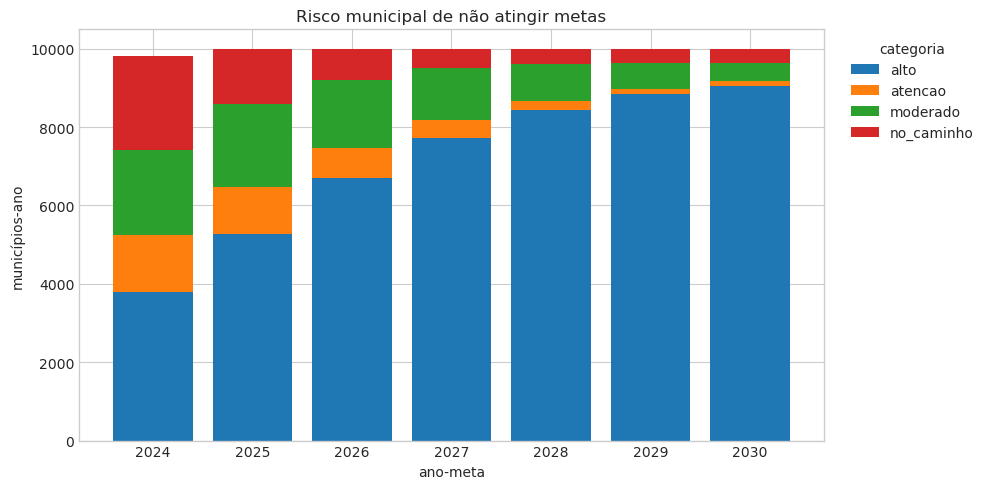

In [254]:
METAS_DIR = DADOS_PROCESSADOS_DIR / "preparado" / "metas_alfabetizacao_validadas"
metas = pl.scan_parquet(str(METAS_DIR / "**" / "*.parquet"), hive_partitioning=True).collect()
metas_municipais = metas.filter(pl.col("escopo_meta") == "municipio").with_columns(
    pl.col("id_municipio").cast(pl.Int64, strict=False),
    pl.col("rede").cast(pl.Int64, strict=False),
    pl.col("meta_alfabetizacao").cast(pl.Float64, strict=False),
)
mediana_meta = metas_municipais["meta_alfabetizacao"].drop_nulls().median()
metas_municipais = metas_municipais.with_columns(
    pl.col("meta_alfabetizacao").alias("meta_alfabetizacao_percentual"),
    (pl.col("meta_alfabetizacao") / 100 if mediana_meta and mediana_meta > 1 else pl.col("meta_alfabetizacao")).alias("meta_alfabetizacao"),
)
fora_intervalo = metas_municipais.filter(pl.col("meta_alfabetizacao").is_not_null() & ~pl.col("meta_alfabetizacao").is_between(0, 1))
if not fora_intervalo.is_empty():
    raise ValueError("Metas fora do intervalo probabilístico 0–1 após normalização.")

estimativas_municipais = municipios.with_columns(
    pl.col("id_municipio").cast(pl.Int64, strict=False), pl.col("rede").cast(pl.Int64, strict=False)
).filter(pl.col("rede") == 3)
risco_metas = estimativas_municipais.join(
    metas_municipais,
    left_on=["id_municipio", "sigla_uf", "rede", "ano_referencia"],
    right_on=["id_municipio", "sigla_uf", "rede", "ano_publicacao"],
    how="left",
)
risco_metas = risco_metas.with_columns(
    (pl.col("probabilidade_media") * (1 - pl.col("probabilidade_media")) / pl.col("registros").clip(lower_bound=1)).sqrt().alias("erro_padrao"),
    pl.when(pl.col("meta_alfabetizacao").is_not_null()).then(pl.lit("com_meta")).otherwise(pl.lit("sem_meta")).alias("cobertura_meta"),
).with_columns(
    (pl.col("probabilidade_media") - 1.96 * pl.col("erro_padrao")).clip(0, 1).alias("probabilidade_ic95_inferior"),
    (pl.col("probabilidade_media") + 1.96 * pl.col("erro_padrao")).clip(0, 1).alias("probabilidade_ic95_superior"),
    (pl.col("meta_alfabetizacao") - pl.col("probabilidade_media")).alias("deficit_meta"),
).with_columns(
    (100 * pl.col("deficit_meta")).alias("deficit_meta_pp"),
    pl.when(pl.col("meta_alfabetizacao").is_null()).then(pl.lit("sem_meta_correspondente"))
      .when(pl.col("deficit_meta") >= LIMITES_RISCO_META["alto"]).then(pl.lit("alto"))
      .when(pl.col("deficit_meta") >= LIMITES_RISCO_META["moderado"]).then(pl.lit("moderado"))
      .when(pl.col("deficit_meta") > LIMITES_RISCO_META["atencao"]).then(pl.lit("atencao"))
      .otherwise(pl.lit("no_caminho")).alias("categoria_risco"),
)
resumo_risco = risco_metas.group_by(["ano_referencia", "ano_meta", "categoria_risco"]).agg(
    pl.col("id_municipio").n_unique().alias("municipios"), pl.col("registros").sum().alias("alunos"),
    pl.col("deficit_meta_pp").mean().alias("deficit_medio_pp"),
)
cobertura_metas = risco_metas.group_by(["ano_referencia", "cobertura_meta"]).agg(
    pl.col("id_municipio").n_unique().alias("municipios")
)
risco_metas.write_csv(TABELAS_DIR / "11_risco_municipal_metas_2024_2030.csv")
resumo_risco.write_csv(TABELAS_DIR / "12_resumo_risco_metas.csv")
cobertura_metas.write_csv(TABELAS_DIR / "13_cobertura_metas.csv")
display(cobertura_metas, resumo_risco.head(30))
plot_risco = resumo_risco.drop_nulls(["ano_meta"])
categorias = plot_risco["categoria_risco"].unique().sort().to_list()
anos = plot_risco["ano_meta"].unique().sort().to_list()
fig, ax = plt.subplots(figsize=(10, 5)); base = np.zeros(len(anos))
for categoria in categorias:
    valores = [plot_risco.filter((pl.col("ano_meta") == ano) & (pl.col("categoria_risco") == categoria))["municipios"].sum() or 0 for ano in anos]
    ax.bar([str(a) for a in anos], valores, bottom=base, label=categoria); base += np.asarray(valores)
ax.set(xlabel="ano-meta", ylabel="municípios-ano", title="Risco municipal de não atingir metas")
ax.legend(title="categoria", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout(); salvar_figura(fig, "09_risco_metas.png"); plt.show()


## 19. Respostas quantitativas e limitações

Esta tabela consolida o que o código efetivamente sustenta para cada pergunta norteadora.


In [255]:
top_features = fatores_associados.head(5)["feature"].to_list()
sem_meta_series = cobertura_metas.filter(pl.col("cobertura_meta") == "sem_meta")["municipios"]
sem_meta = int(sem_meta_series.max()) if len(sem_meta_series) else 0
rho_por_ano = "; ".join(
    f"{int(r['ano_referencia'])}: rho={r['spearman_target']:.3f}" for r in correlacao_inse.iter_rows(named=True)
)
silhouette_melhor = avaliacao_clusters.filter(pl.col("k") == melhor_k)["silhouette"][0]
respostas_norteadoras = pl.DataFrame([
    {"pergunta": "É possível prever alfabetização com os dados disponíveis?", "evidencia": f"ROC AUC={metricas_teste['roc_auc']:.4f}; AP={metricas_teste['average_precision']:.4f}; IC95% AUC={intervalos_95['roc_auc']['inferior']:.4f}–{intervalos_95['roc_auc']['superior']:.4f}", "interpretacao": "Existe sinal preditivo moderado, útil para análise agregada e priorização exploratória.", "limitacao": "Não autoriza decisão individual automatizada."},
    {"pergunta": "Quais fatores estão associados?", "evidencia": ", ".join(top_features), "interpretacao": "São os sinais que mais sustentam a discriminação do modelo.", "limitacao": "Importância preditiva não implica direção nem causalidade."},
    {"pergunta": "Quanto o desempenho depende de sigla_uf?", "evidencia": f"Δ ROC AUC com−sem UF={metricas_teste['roc_auc'] - metricas_teste_sem_uf['roc_auc']:.4f}; Δ AP={metricas_teste['average_precision'] - metricas_teste_sem_uf['average_precision']:.4f}", "interpretacao": "A comparação quantifica a informação territorial adicional sob o mesmo protocolo e hiperparâmetros.", "limitacao": "UF é proxy de políticas, investimento, infraestrutura e contexto regional; a diferença não é causal."},
    {"pergunta": "Infraestrutura está associada?", "evidencia": f"{infraestrutura.height:,} combinações avaliadas.", "interpretacao": "As tabelas por faixa permitem comparar taxas observadas e estimadas.", "limitacao": "Infraestrutura municipal agregada, não da escola frequentada."},
    {"pergunta": "INSE está associado?", "evidencia": rho_por_ano, "interpretacao": "A direção e a magnitude são apresentadas separadamente por ano.", "limitacao": "INSE municipal de 2023, não individual."},
    {"pergunta": "Há persistência entre 2023 e 2024?", "evidencia": f"rho observado={persistencia['spearman_observado_2023_2024']:.3f}; pares={persistencia['municipios_redes_comparaveis']:,}", "interpretacao": "Mede persistência municipal de curto prazo.", "limitacao": "Dois anos não formam tendência histórica longa; SP não possui 2023."},
    {"pergunta": "Finanças estão associadas?", "evidencia": f"{financeiro.height:,} combinações avaliadas.", "interpretacao": "As diferenças são associações preditivas condicionadas ao conjunto disponível.", "limitacao": "Totais podem representar porte; não equivalem a gasto educacional por aluno."},
    {"pergunta": "Existem perfis municipais?", "evidencia": f"k={melhor_k}; silhouette={silhouette_melhor:.3f}", "interpretacao": "Os clusters resumem perfis contextuais semelhantes.", "limitacao": "Clusters são descritivos, dependem das variáveis e não representam causas."},
    {"pergunta": "Quais municípios têm risco de não atingir metas?", "evidencia": f"Tabela de risco produzida; até {sem_meta} municípios por ano sem correspondência.", "interpretacao": "Déficit positivo indica estimativa abaixo da meta no cenário observado.", "limitacao": "Não é projeção temporal completa; incerteza é aproximação binomial agregada."},
])
respostas_norteadoras.write_csv(TABELAS_DIR / "14_respostas_norteadoras.csv")
display(respostas_norteadoras)


pergunta,evidencia,interpretacao,limitacao
str,str,str,str
"""É possível prever alfabetizaçã…","""ROC AUC=0.6705; AP=0.6841; IC9…","""Existe sinal preditivo moderad…","""Não autoriza decisão individua…"
"""Quais fatores estão associados…","""sigla_uf, valor_bolsa_familia_…","""São os sinais que mais sustent…","""Importância preditiva não impl…"
"""Quanto o desempenho depende de…","""Δ ROC AUC com−sem UF=-0.0052; …","""A comparação quantifica a info…","""UF é proxy de políticas, inves…"
"""Infraestrutura está associada?""","""77 combinações avaliadas.""","""As tabelas por faixa permitem …","""Infraestrutura municipal agreg…"
"""INSE está associado?""","""2024: rho=0.024; 2023: rho=0.0…","""A direção e a magnitude são ap…","""INSE municipal de 2023, não in…"
"""Há persistência entre 2023 e 2…","""rho observado=0.447; pares=5,6…","""Mede persistência municipal de…","""Dois anos não formam tendência…"
"""Finanças estão associadas?""","""40 combinações avaliadas.""","""As diferenças são associações …","""Totais podem representar porte…"
"""Existem perfis municipais?""","""k=3; silhouette=0.241""","""Os clusters resumem perfis con…","""Clusters são descritivos, depe…"
"""Quais municípios têm risco de …","""Tabela de risco produzida; até…","""Déficit positivo indica estima…","""Não é projeção temporal comple…"


## 11. SHAP — explicação complementar controlada

O SHAP é usado como complemento global da importância por permutação. Para manter a execução viável em computadores modestos, ele é desativado por padrão e usa uma amostra pequena quando habilitado. Ative com `TC3_EXECUTAR_SHAP=1`; ajuste `TC3_AMOSTRA_SHAP` e `TC3_BACKGROUND_SHAP` se necessário.

As explicações continuam associativas: valores SHAP mostram contribuições à predição do modelo, não efeitos causais.


[recursos] nível=normal; threads=4; RAM usada=59.9%; livre=6.2 GB.


/opt/conda/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran on GPU
[cuml.accel] `RandomForestClassifier.predict_proba` ran

feature,shap_abs_medio
str,f64
"""sigla_uf""",0.105783
"""valor_bolsa_familia__signed_lo…",0.020112
"""media_inse""",0.012066
"""valor_receitas__signed_log1p""",0.009798
"""in_internet""",0.007418
"""in_laboratorio_informatica""",0.007305
"""valor_fundeb__signed_log1p""",0.006009
"""in_biblioteca_sala_leitura""",0.005671
"""rede""",0.004837


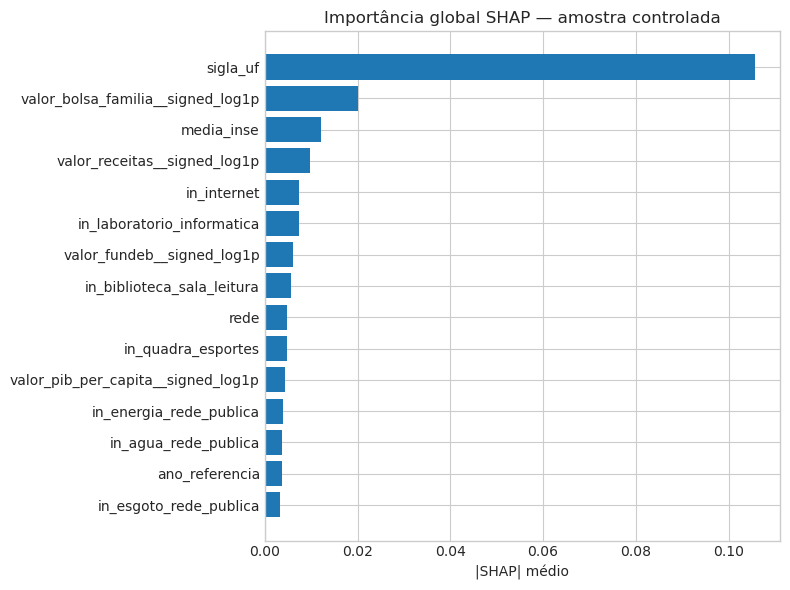

SHAP corrigido e salvo com os nomes originais: 18 features.
[recursos] nível=moderado; threads=2; RAM usada=60.0%; livre=6.2 GB.


In [256]:
import re

shap_resultados = pl.DataFrame({
    "feature": pl.Series([], dtype=pl.String),
    "shap_abs_medio": pl.Series([], dtype=pl.Float64),
})

if not EXECUTAR_SHAP:
    print(
        "SHAP não executado. Defina TC3_EXECUTAR_SHAP=1 "
        "antes de iniciar o kernel para habilitar."
    )
else:
    try:
        import shap
    except ImportError as exc:
        raise ImportError(
            "Instale as dependências do projeto para executar SHAP."
        ) from exc

    # Seleção determinística da amostra.
    rng_shap = np.random.default_rng(SEED)
    n_shap = min(AMOSTRA_SHAP, len(y_test))
    indices_shap = rng_shap.choice(
        len(y_test),
        size=n_shap,
        replace=False,
    )
    X_shap_original = X_test[indices_shap.tolist(), :]

    # Reutiliza o preprocessador e o estimador do modelo oficial já treinado.
    preprocessador_final = modelo.named_steps["preprocessor"]
    estimador_final = modelo.named_steps["model"]

    X_shap_transformado = np.asarray(
        preprocessador_final.transform(X_shap_original)
    )

    nomes_transformados = [
        nome.split("__", 1)[-1]
        for nome in preprocessador_final.get_feature_names_out()
    ]

    n_background = min(
        AMOSTRA_BACKGROUND_SHAP,
        X_shap_transformado.shape[0],
    )
    background = X_shap_transformado[:n_background]

    def prever_classe_positiva(matriz):
        return np.asarray(
            estimador_final.predict_proba(matriz)
        )[:, 1]

    explicador_shap = shap.Explainer(
        prever_classe_positiva,
        background,
        algorithm="permutation",
        seed=SEED,
    )

    explicacao_shap = explicador_shap(
        X_shap_transformado,
        max_evals=2 * X_shap_transformado.shape[1] + 1,
    )

    valores_abs = np.abs(
        np.asarray(explicacao_shap.values)
    ).mean(axis=0)

    def feature_original(nome_transformado):
        """
        Reconstrói a feature original a partir dos nomes x0, x1, x2...
        produzidos pelo ColumnTransformer com seletores posicionais.

        Exemplos:
        x0_CE -> sigla_uf
        x0_SP -> sigla_uf
        x1_2  -> rede
        x2    -> ano_referencia
        """
        nome_limpo = nome_transformado.split("__", 1)[-1]

        correspondencia = re.match(
            r"^x(\d+)(?:_.*)?$",
            nome_limpo,
        )

        if correspondencia:
            indice = int(correspondencia.group(1))

            if 0 <= indice < len(FEATURES):
                return FEATURES[indice]

        # Fallback para versões que preservem os nomes originais.
        for feature in sorted(FEATURES, key=len, reverse=True):
            if (
                nome_limpo == feature
                or nome_limpo.startswith(feature + "_")
            ):
                return feature

        return nome_limpo

    # Soma as importâncias das categorias provenientes da mesma feature.
    agregados_shap = {}

    for nome, valor in zip(nomes_transformados, valores_abs):
        original = feature_original(nome)

        agregados_shap[original] = (
            agregados_shap.get(original, 0.0)
            + float(valor)
        )

    shap_resultados = (
        pl.DataFrame({
            "feature": list(agregados_shap),
            "shap_abs_medio": list(agregados_shap.values()),
        })
        .sort("shap_abs_medio", descending=True)
    )

    display(shap_resultados)

    # Gráfico com as 15 features mais importantes.
    top_shap = (
        shap_resultados
        .head(15)
        .sort("shap_abs_medio")
    )

    plt.figure(figsize=(8, 6))
    plt.barh(
        top_shap["feature"],
        top_shap["shap_abs_medio"],
    )
    plt.xlabel("|SHAP| médio")
    plt.title("Importância global SHAP — amostra controlada")
    plt.tight_layout()

    salvar_figura_eda(
        plt.gcf(),
        "avaliacao_final_shap_global.png",
    )
    plt.show()

    # Salva imediatamente o resultado corrigido, sem depender das
    # células posteriores do notebook.
    RESULTADOS_TABELAS_DIR.mkdir(
        parents=True,
        exist_ok=True,
    )

    shap_resultados.write_csv(
        RESULTADOS_TABELAS_DIR
        / "19_importancia_shap.csv"
    )

    print(
        "SHAP corrigido e salvo com os nomes originais:",
        shap_resultados.height,
        "features."
    )

## 21. Auditoria, reprodutibilidade e status da execução

O encerramento valida os artefatos obrigatórios, registra versões e atualiza o status do fluxo oficial. O arquivo de ambiente não substitui um teste posterior em máquina limpa, mas torna a execução auditável.


In [257]:
politica_temporal_fontes.write_csv(TABELAS_DIR / "15_politica_temporal_fontes.csv")
auditoria_cobertura_fontes.write_csv(TABELAS_DIR / "16_auditoria_cobertura_fontes.csv")
diagnostico_uf.write_csv(TABELAS_DIR / "17_diagnostico_proxy_uf.csv")
sensibilidade_uf.write_csv(TABELAS_DIR / "18_sensibilidade_sigla_uf.csv")
if not shap_resultados.is_empty():
    shap_resultados.write_csv(TABELAS_DIR / "19_importancia_shap.csv")

artefatos_obrigatorios = [
    METRICAS_FINAIS_DIR / "resultado_final.json",
    MODEL_DIR / "modelo_pipeline.joblib",
    ANALITICOS_FINAIS_DIR / "predicoes_agregadas_municipio.parquet",
    TABELAS_DIR / "01_fatores_associados.csv",
    TABELAS_DIR / "11_risco_municipal_metas_2024_2030.csv",
    TABELAS_DIR / "14_respostas_norteadoras.csv",
    TABELAS_DIR / "15_politica_temporal_fontes.csv",
    TABELAS_DIR / "16_auditoria_cobertura_fontes.csv",
    TABELAS_DIR / "17_diagnostico_proxy_uf.csv",
    TABELAS_DIR / "18_sensibilidade_sigla_uf.csv",
    FIGURAS_DIR / "01_metricas_classificacao.png",
    FIGURAS_DIR / "09_risco_metas.png",
]
faltantes = [str(p.relative_to(PROJECT_ROOT)) for p in artefatos_obrigatorios if not p.exists()]
if faltantes:
    raise FileNotFoundError(f"Artefatos obrigatórios ausentes: {faltantes}")

ambiente_final = {
    "gerado_em_utc": datetime.now(timezone.utc).isoformat(),
    "python": platform.python_version(),
    "scikit_learn": sklearn.__version__,
    "polars": pl.__version__,
    "backend_ml": BACKEND_ML,
    "seed": SEED,
    "modelo": "Random Forest",
    "parametros": parametros,
    "features": FEATURES,
    "teste_reutilizado_para_tuning": False,
    "politica_temporal_fontes": politica_temporal_fontes.to_dicts(),
    "sensibilidade_sigla_uf": sensibilidade_uf.to_dicts(),
    "shap_executado": bool(EXECUTAR_SHAP),
    "amostra_shap": int(AMOSTRA_SHAP) if EXECUTAR_SHAP else 0,
}
(ANALISE_DIR / "ambiente_execucao.json").write_text(json.dumps(ambiente_final, ensure_ascii=False, indent=2), encoding="utf-8")

status = {
    "estado": "concluido",
    "finalizado_em_utc": datetime.now(timezone.utc).isoformat(),
    "fluxo": "TC3_Pipeline_Completo_Alfabetizacao.ipynb",
    "backend_ml": BACKEND_ML,
    "modelo_oficial": "Random Forest",
    "roc_auc_teste": metricas_teste["roc_auc"],
    "artefatos_validados": len(artefatos_obrigatorios),
    "erro": None,
}
STATUS_PATH = RESULTADOS_RELATORIOS_DIR / "status_execucao.json"
STATUS_PATH.parent.mkdir(parents=True, exist_ok=True)
STATUS_PATH.write_text(json.dumps(status, ensure_ascii=False, indent=2), encoding="utf-8")
print("Auditoria concluída:", len(artefatos_obrigatorios), "artefatos obrigatórios validados.")


Auditoria concluída: 12 artefatos obrigatórios validados.


<a id="conclusao"></a>

## 22. Conclusão dinâmica

A célula abaixo monta a conclusão diretamente a partir dos resultados desta execução. Isso evita manter números antigos em texto estático.


In [258]:
auc_ic = intervalos_95["roc_auc"]
melhor_silhouette = avaliacao_clusters.filter(pl.col("k") == melhor_k)["silhouette"][0]
conclusao = (
    "## Conclusão da entrega analítica\n\n"
    f"O Random Forest, selecionado antes do acesso ao teste, foi avaliado em **{len(y_test):,} registros** e obteve "
    f"**ROC AUC {metricas_teste['roc_auc']:.4f}** (IC95% **{auc_ic['inferior']:.4f}–{auc_ic['superior']:.4f}**), "
    f"**Average Precision {metricas_teste['average_precision']:.4f}**, **Balanced Accuracy {metricas_teste['balanced_accuracy']:.4f}** "
    f"e **F1 {metricas_teste['f1']:.4f}**. O desempenho é superior ao acaso, porém moderado, e sustenta análises agregadas — "
    "não decisões individuais automatizadas.\n\n"
    f"As variáveis com maior importância preditiva foram **{', '.join(top_features)}**. Elas representam sinais predominantemente "
    "territoriais e contextuais; nenhuma delas deve ser interpretada como causa da alfabetização. "
    f"Na análise de sensibilidade, retirar `sigla_uf` alterou o ROC AUC em **{metricas_teste['roc_auc'] - metricas_teste_sem_uf['roc_auc']:.4f}** "
    f"e a Average Precision em **{metricas_teste['average_precision'] - metricas_teste_sem_uf['average_precision']:.4f}**. "
    "Isso quantifica dependência preditiva do contexto territorial, não efeito causal da UF.\n\n"
    f"A persistência municipal entre 2023 e 2024 foi calculada em **{persistencia['municipios_redes_comparaveis']:,} pares município-rede "
    f"comparáveis**, com correlação de Spearman observada de **{persistencia['spearman_observado_2023_2024']:.3f}**. Essa evidência descreve "
    "persistência de curto prazo, não tendência histórica longa.\n\n"
    f"A análise territorial identificou **{melhor_k} perfis contextuais municipais** (silhouette **{melhor_silhouette:.3f}**). "
    "Os grupos são descritivos e não representam mecanismos causais.\n\n"
    "As estimativas municipais foram comparadas às metas oficiais no mesmo município, rede e publicação. O déficit é definido como meta "
    "menos probabilidade média. Categorias de risco e cobertura foram exportadas, incluindo territórios sem correspondência de meta. "
    "As metas futuras são cenários condicionais ao contexto observado, não projeções completas até 2030.\n\n"
    f"O treinamento final levou **{tempo_treino / 60:.1f} minutos** e a inferência **{tempo_inferencia:.2f} segundos**, usando "
    f"**{BACKEND_ML}**. O conjunto de teste não foi utilizado para alterar features, algoritmo, hiperparâmetros ou limiar."
)
display(Markdown(conclusao))
(ANALISE_DIR / "conclusao_dinamica.md").write_text(conclusao, encoding="utf-8")


## Conclusão da entrega analítica

O Random Forest, selecionado antes do acesso ao teste, foi avaliado em **581,591 registros** e obteve **ROC AUC 0.6705** (IC95% **0.6673–0.6737**), **Average Precision 0.6841**, **Balanced Accuracy 0.6196** e **F1 0.6392**. O desempenho é superior ao acaso, porém moderado, e sustenta análises agregadas — não decisões individuais automatizadas.

As variáveis com maior importância preditiva foram **sigla_uf, valor_bolsa_familia__signed_log1p, media_inse, rede, in_laboratorio_informatica**. Elas representam sinais predominantemente territoriais e contextuais; nenhuma delas deve ser interpretada como causa da alfabetização. Na análise de sensibilidade, retirar `sigla_uf` alterou o ROC AUC em **-0.0052** e a Average Precision em **-0.0069**. Isso quantifica dependência preditiva do contexto territorial, não efeito causal da UF.

A persistência municipal entre 2023 e 2024 foi calculada em **5,653 pares município-rede comparáveis**, com correlação de Spearman observada de **0.447**. Essa evidência descreve persistência de curto prazo, não tendência histórica longa.

A análise territorial identificou **3 perfis contextuais municipais** (silhouette **0.241**). Os grupos são descritivos e não representam mecanismos causais.

As estimativas municipais foram comparadas às metas oficiais no mesmo município, rede e publicação. O déficit é definido como meta menos probabilidade média. Categorias de risco e cobertura foram exportadas, incluindo territórios sem correspondência de meta. As metas futuras são cenários condicionais ao contexto observado, não projeções completas até 2030.

O treinamento final levou **1.3 minutos** e a inferência **0.61 segundos**, usando **RAPIDS cuML — NVIDIA GeForce RTX 3050 6GB Laptop GPU (6.0 GB de VRAM)**. O conjunto de teste não foi utilizado para alterar features, algoritmo, hiperparâmetros ou limiar.

1886

<a id="encerramento"></a>

# Encerramento

Ao fim da execução, o pipeline oficial fica em `modelos/random_forest/`; métricas, figuras, tabelas e relatórios ficam em `resultados/`; e previsões agregadas ficam em `dados/dados_analiticos/`. As fontes originais não são modificadas.

A interpretação oficial não compara modelos no teste: a escolha do Random Forest ocorre na Fase 6, usando validação; a Fase 7 estima o desempenho final do candidato previamente selecionado.
